# 06 · Frozen evaluation, calibrated intervals and statistical results

One primary point model is reported: the causal pattern residual reconstruction (revision 3). An attempted matched-sensor update did not meet its prespecified replacement criterion. All revised comparisons on Plegma, REFIT and UK-DALE are retrospective.

Separate source residual-quantile intervals assess coverage, width and interval score; they change neither point predictions nor the predictive law used for CRPS. Metric- and domain-specific advantages do not establish overall superiority.

The independent ECO evaluation is complete: seven frozen pipelines, three seeds and six previously unevaluated households, with 24,576 fixed queries and no fitting or calibration on ECO. The proposed model has the lowest observed CRPS, but ranks third in MAE and fifth in RMSE. The prespecified global superiority criterion failed (p = 0.984375), and none of the 18 Holm-adjusted contrasts is significant. This supports a bounded probabilistic-performance result, not overall superiority or guaranteed calibration. The acquisition section describes a metadata-only archive-layout rule for House 4; selection and evaluation rules remained fixed.

**Earlier model.** The original frozen joint-state model did not beat the strongest classical controls on overall MAE/RMSE. Its acquisition findings and its UK-DALE evaluation, which was independent at that time, do not carry over to the later scalar revisions.

In [1]:
# Independent extension setup: immutable historical inputs, separate output namespace.
from pathlib import Path
import hashlib, json, os, gc
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.text import Text
from IPython.display import display, Image, Markdown, clear_output
from PIL import Image as PILImage
ROOT=Path.cwd()
if ROOT.name=="Notebooks":ROOT=ROOT.parent
assert ROOT.is_dir()
V2_RUN="guldana_n3_20261009_v02"
V2_RECORD=ROOT/"Manifests/Runs"/V2_RUN
V2_TABLES=ROOT/"Tables"/V2_RUN/"06_strengthened_evaluation"
V2_DATA=ROOT/"Data/Processed"/V2_RUN/"evaluation_auxiliary"
for folder in [V2_TABLES,V2_DATA,ROOT/"Figures/PNG"/V2_RUN,ROOT/"Figures/PDF"/V2_RUN]:folder.mkdir(parents=True,exist_ok=True)
def v2_sha(path):
    digest=hashlib.sha256()
    with open(path,"rb") as stream:
        for chunk in iter(lambda:stream.read(8*1024*1024),b""):digest.update(chunk)
    return digest.hexdigest()
V2_PROTOCOL=json.loads((ROOT/"Configs/strengthening_v2.json").read_text())
V2_OLD_LOCK=json.loads((V2_RECORD/"historical_artifact_lock.json").read_text())
V2_SPLIT=json.loads((ROOT/"Manifests/split_freeze.json").read_text())
for relative,digest in V2_SPLIT["files"].items():assert v2_sha(ROOT/relative)==digest,relative
assert len(list((ROOT/"Notebooks").glob("*.ipynb")))==6
font=font_manager.findfont("Times New Roman",fallback_to_default=False)
assert Path(font).is_file()
mpl.rcParams.update({"font.family":"Times New Roman","font.size":18,"axes.titlesize":20,
    "axes.labelsize":18,"xtick.labelsize":18,"ytick.labelsize":18,"legend.fontsize":18,
    "figure.dpi":350,"savefig.dpi":350,"axes.unicode_minus":True,"pdf.fonttype":42})
def v2_table(frame,name,caption,precision=4):
    frame.to_csv(V2_TABLES/f"{name}.csv",index=False)
    frame.to_latex(V2_TABLES/f"{name}.tex",index=False,caption=caption,float_format=lambda x:f"{x:.{precision}f}")
    display(frame.style.format(precision=precision,na_rep="Not identifiable").hide(axis="index").set_caption(caption))
def v2_figure(fig,name):
    fig.canvas.draw()
    for text in fig.findobj(Text):
        if text.get_visible() and text.get_text().strip():
            assert 18<=text.get_fontsize()<=20
            assert font_manager.FontProperties(fname=font_manager.findfont(text.get_fontproperties(),fallback_to_default=False)).get_name()=="Times New Roman"
    png=ROOT/"Figures/PNG"/V2_RUN/f"{name}.png";pdf=ROOT/"Figures/PDF"/V2_RUN/f"{name}.pdf"
    fig.savefig(png,dpi=350,bbox_inches="tight",pad_inches=.06)
    fig.savefig(pdf,dpi=350,bbox_inches="tight",pad_inches=.06)
    with PILImage.open(png) as im:assert all(abs(d-350)<.02 for d in im.info["dpi"])
    plt.close(fig);display(Image(filename=str(png)))

import time,math,copy,random,threading,psutil,torch,yaml,ast
import torch.nn as nn
import torch.nn.functional as F
from types import SimpleNamespace
from scipy.special import ndtr
torch.set_num_threads(4)
OLD_RUN="guldana_n3_20261007_v01";RUN=V2_RUN
DEVICE=torch.device("mps" if torch.backends.mps.is_available() else "cpu")
schema=json.loads((ROOT/"Configs/sensor_schema.json").read_text());N_TYPES=len(schema["power_types"])
PREP=ROOT/"Models/preprocessing"/OLD_RUN
CACHE=ROOT/"Data/Processed"/OLD_RUN/"modeling_inputs"
NEURAL_CACHE=ROOT/"Data/Processed"/OLD_RUN/"neural_inputs_v1"
REFINED=ROOT/"Data/Interim/development_minutes_refined"
PROPOSED_DIR=ROOT/"Models/proposed"/RUN
PROPOSED_PRED_DIR=ROOT/"Predictions/development_proposed"/RUN
for d in [PROPOSED_DIR,PROPOSED_PRED_DIR]:d.mkdir(parents=True,exist_ok=True)
INPUT_CONTRACT="masked_sensor_v1_exact_fixtures"
compute_protocol=yaml.safe_load((ROOT/"Configs/compute_protocol.yaml").read_text())
NB02_GATE=json.loads((ROOT/"Manifests/nb02_gate.json").read_text())
preprocessors={};duplicate_maps={}
for fold in [1,2,3]:
    state=json.loads((PREP/f"fold_{fold}_preprocessing.json").read_text())
    assert v2_sha(PREP/f"fold_{fold}_preprocessing.json")==V2_OLD_LOCK["files"][str((PREP/f"fold_{fold}_preprocessing.json").relative_to(ROOT))]
    preprocessors[fold]=SimpleNamespace(state=state)
    duplicate_maps[fold]={int(h):m for h,m in state["duplicate_maps"].items()}
PROPOSED_PROTOCOL_HASH=v2_sha(ROOT/"Configs/component_strengthening_v2.json")
COMPONENT_RETENTION_HASH=v2_sha(ROOT/"Configs/proposed_component_retention.json")
TABLES=V2_TABLES;table=v2_table
COMPONENT_PROTOCOL=json.loads((ROOT/"Configs/component_strengthening_v2.json").read_text())
def file_sha256(path):
    digest=hashlib.sha256()
    with open(path,"rb") as stream:
        for chunk in iter(lambda:stream.read(8*1024*1024),b""):digest.update(chunk)
    return digest.hexdigest()


def seed_everything(seed):
    random.seed(seed);np.random.seed(seed);torch.manual_seed(seed)
    if torch.backends.mps.is_available():torch.mps.manual_seed(seed)


def synchronize(device=DEVICE):
    if str(device)=="mps":torch.mps.synchronize()


def masked_mean(values,mask):
    mask=mask.to(values.dtype)
    return (values*mask).sum()/mask.sum().clamp_min(1)


def regression_summary(metadata,prediction):
    error=prediction-metadata.y_kW.to_numpy(dtype=np.float64)
    per_house=pd.DataFrame({"house":metadata.house,"absolute":np.abs(error),"squared":error**2,
                           "bias":error,"negative":prediction<0}).groupby("house").mean()
    return {"House-macro MAE (kW)":float(per_house.absolute.mean()),
        "House-macro RMSE (kW)":float(np.sqrt(per_house.squared).mean()),
        "Bias (kW)":float(per_house.bias.mean()),"Negative prediction (%)":float(per_house.negative.mean()*100)}


import zipfile,subprocess,shutil
from datetime import datetime,timezone
EVAL_V2=json.loads((ROOT/"Configs/evaluation_strengthening_v2.json").read_text())
UK_CONTRACT=json.loads((ROOT/"Configs/ukdale_measurement_contract_v2.json").read_text())
UK_ARCHIVE=ROOT/"Data/Raw/UKDALE_2017/ukdale.zip"
UK_METADATA=ROOT/UK_CONTRACT["metadata_root"]
UK_MINUTES=ROOT/"Data/Processed"/V2_RUN/"ukdale_minutes"
UK_MINUTES.mkdir(parents=True,exist_ok=True)

_VERIFIED_NEW_FREEZE=set()

def require_new_measurement_freeze(force=False):
    path=V2_RECORD/"frozen_evaluation_manifest.json"
    assert path.is_file(),"New model/protocol freeze is required before any UK-DALE measurement access."
    record=json.loads(path.read_text())
    assert record["run_id"]==V2_RUN and record["status"]=="frozen_before_UKDALE_measurement_access"
    assert record["independent_measurements_accessed_before_freeze"] is False
    assert record["archive_sha256"]==UK_CONTRACT["archive_sha256"]
    freeze_digest=file_sha256(path)
    if force or freeze_digest not in _VERIFIED_NEW_FREEZE:
        for relative,digest in record["files"].items():assert file_sha256(ROOT/relative)==digest,relative
        _VERIFIED_NEW_FREEZE.add(freeze_digest)
    assert record["ukdale_reader_implementation_sha256"]==UK_READER_IMPLEMENTATION_HASH
    assert record["evaluation_implementation_sha256"]==EVALUATION_IMPLEMENTATION_HASH
    return record


In [2]:
# Complete scientific tables: semantic groups, unchanged values, mathematical minus.
# This display-only setup does not fit models or modify numerical exports.
import copy as _table_copy
import re as _table_re
import pandas as _table_pd
from bs4 import BeautifulSoup as _TableSoup, NavigableString as _TableText
from pandas.io.formats.style import Styler as _TableStyler
from IPython.display import HTML as _TableHTML
import hashlib as _table_hashlib, json as _table_json
_table_layout_bytes = (ROOT / "Configs/article_table_layout.json").read_bytes()
assert _table_hashlib.sha256(_table_layout_bytes).hexdigest() == "fbbb6522e8c59dbde1eea0021da0a6f72e3257d1c6d0c8d49e74c5bd3a6a9d8c"
_ARTICLE_TABLE_GROUPS = _table_json.loads(_table_layout_bytes)
_ARTICLE_NUMBER = _table_re.compile(r"^\s*[+−-]?(?:\d+(?:\.\d*)?|\.\d+)(?:[eE][+−-]?\d+)?%?\s*$")
def _article_table_layout(tag, additions):
    declarations = dict(part.strip().split(":", 1) for part in tag.get("style", "").split(";") if ":" in part)
    declarations.update(additions)
    tag["style"] = ";".join(key + ":" + value for key, value in declarations.items()) + ";"
def _article_table_html(html):
    soup = _TableSoup(html, "html.parser")
    for table in list(soup.find_all("table")):
        head = table.find("thead")
        body = table.find("tbody")
        if head is None or body is None:
            continue
        heads = [tag.get_text(strip=True) for tag in head.find_all("th")]
        rule = _ARTICLE_TABLE_GROUPS.get("|".join(heads))
        if rule is not None and len(head.find_all("tr")) == 1:
            rows = body.find_all("tr", recursive=False)
            if all(len(row.find_all(["th", "td"], recursive=False)) == len(heads) for row in rows):
                assert set(sum(rule["columns"], [])) == set(heads)
                original_styles = [style.get_text() for style in soup.find_all("style")]
                for number, (columns, label) in enumerate(zip(rule["columns"], rule["labels"]), 1):
                    part = _table_copy.deepcopy(table)
                    keep = [heads.index(name) for name in columns]
                    for row in part.find_all("tr"):
                        for index, tag in enumerate(row.find_all(["th", "td"], recursive=False)):
                            if index not in keep:
                                tag.decompose()
                    caption = part.find("caption")
                    if caption is None:
                        caption = soup.new_tag("caption")
                        part.insert(0, caption)
                    caption.append(" " + label)
                    suffix = "_article_part_" + str(number)
                    original_id = table.get("id")
                    for tag in [part] + part.find_all(True):
                        if tag.has_attr("id"):
                            tag["id"] = (tag["id"].replace(original_id, original_id + suffix, 1)
                                         if original_id and tag["id"].startswith(original_id) else tag["id"] + suffix)
                    if original_id:
                        for style_text in original_styles:
                            if "#" + original_id in style_text:
                                copied_style = soup.new_tag("style")
                                copied_style.string = style_text.replace("#" + original_id, "#" + original_id + suffix)
                                table.insert_before(copied_style)
                    table.insert_before(part)
                table.decompose()
    for table in soup.find_all("table"):
        _article_table_layout(table, {"max-width":"100%", "table-layout":"auto", "margin-bottom":"1.4em"})
        for tag in table.find_all(["th", "td", "caption"]):
            _article_table_layout(tag, {"white-space":"normal", "vertical-align":"top"})
            if tag.name == "caption":
                _article_table_layout(tag, {"text-align":"left", "caption-side":"top"})
            for old_break in list(tag.find_all("wbr")):
                old_break.decompose()
            for node in list(tag.descendants):
                if not isinstance(node, _TableText) or node.parent.name in {"code", "pre", "script", "style"}:
                    continue
                text = str(node)
                if tag.name == "td" and _ARTICLE_NUMBER.fullmatch(text):
                    text = text.replace("-", "−")
                chunks = _table_re.split("(?<=_)", text)
                for index, chunk in enumerate(chunks):
                    node.insert_before(_TableText(chunk))
                    if index + 1 < len(chunks):
                        node.insert_before(soup.new_tag("wbr"))
                node.extract()
    return str(_TableSoup(str(soup), "html.parser"))
def _article_styler_html(value):
    with _table_pd.option_context("styler.render.max_elements", max(1, value.data.size + len(value.data)),
                                  "styler.render.max_rows", None, "styler.render.max_columns", None):
        html = value.to_html(max_rows=len(value.data), max_columns=len(value.data.columns))
    assert not _TableSoup(html, "html.parser").select(".row_trim, .col_trim"), "Scientific table was truncated"
    return _article_table_html(html)
def _article_frame_html(value):
    return _article_table_html(value.to_html(max_rows=None, max_cols=None))
def _article_HTML_html(value):
    result = value._repr_html_()
    if isinstance(result, tuple):
        return _article_table_html(result[0]), result[1]
    return _article_table_html(result)
_table_format = get_ipython().display_formatter.formatters["text/html"]
_table_format.for_type(_TableStyler, _article_styler_html)
_table_format.for_type(_table_pd.DataFrame, _article_frame_html)
_table_format.for_type(_TableHTML, _article_HTML_html);


In [2]:
# Channel selection reads metadata only; it cannot inspect power or tune on target correlations.
def ukdale_metadata_inventory():
    for relative,digest in UK_CONTRACT["metadata_sha256"].items():assert file_sha256(ROOT/relative)==digest
    devices=yaml.safe_load((UK_METADATA/"meter_devices.yaml").read_text())
    for key,contract in [("SoundCardPowerMeter",UK_CONTRACT["mains"]),("EcoManagerTxPlug",UK_CONTRACT["auxiliary"])]:
        active=[m for m in devices[key]["measurements"] if m.get("physical_quantity")=="power" and m.get("type")=="active"]
        assert len(active)==1
        assert [active[0]["lower_limit"],active[0]["upper_limit"]]==contract["bounds_W"]
    inventory=json.loads((V2_RECORD/"ukdale_archive_inventory.json").read_text())
    assert inventory["zip_sha256"]==UK_CONTRACT["archive_sha256"]
    archive_names={m["name"] for m in inventory["members"]}
    semantic={label:kind for kind,labels in UK_CONTRACT["semantic_map"].items() for label in labels}
    rows=[]
    for house in UK_CONTRACT["houses"]:
        building=yaml.safe_load((UK_METADATA/f"building{house}.yaml").read_text())
        meters={int(k):v for k,v in building["elec_meters"].items()}
        mains=[(meter,data) for meter,data in meters.items() if data.get("device_model")=="SoundCardPowerMeter" and not data.get("disabled",False)]
        assert len(mains)==1 and mains[0][1]["data_location"]==f"house_{house}/mains.dat"
        assert mains[0][1]["data_location"] in archive_names
        rows.append({"House":house,"Meter":mains[0][0],"Sensor":"P_agg","Type":"aggregate","Role":"aggregate",
            "Archive member":mains[0][1]["data_location"],"Device":"SoundCardPowerMeter","Selected":True,
            "Ambiguous":False,"Reason":"measured active-power field, never apparent mains"})
        parents={int(m.get("submeter_of",0)) for m in meters.values() if isinstance(m.get("submeter_of",0),(int,str))}
        candidates=[]
        for meter,data in sorted(meters.items()):
            if data.get("device_model")!="EcoManagerTxPlug" or data.get("disabled",False) or meter in parents:continue
            appliances=[a for a in building.get("appliances",[]) if meter in a.get("meters",[])]
            names={a.get("original_name","") for a in appliances}
            warning=house==1 and bool(names.intersection({"kettle","toaster","hoover"}))
            ambiguous=len(appliances)!=1 or warning
            kind="unknown" if ambiguous else semantic.get(appliances[0].get("type",""),"unknown")
            assert kind in schema["power_types"] and kind!="aggregate"
            member=data["data_location"];assert member in archive_names
            candidates.append({"House":house,"Meter":meter,"Sensor":f"UKDALE_channel_{meter}","Type":kind,"Role":"auxiliary_power",
                "Archive member":member,"Device":"EcoManagerTxPlug","Selected":False,"Ambiguous":ambiguous,
                "Reason":"multi-use/swapping metadata or multiple appliances" if ambiguous else "active leaf meter; metadata semantic mapping"})
        selected=[]
        for kind in schema["power_types"]:
            group=sorted([row for row in candidates if row["Type"]==kind],key=lambda r:(r["Ambiguous"],r["Meter"]))
            if group and len(selected)<15:selected.append(group[0]["Meter"])
        for row in sorted(candidates,key=lambda r:r["Meter"]):
            if row["Meter"] not in selected and len(selected)<15:selected.append(row["Meter"])
        assert len(selected)==len(set(selected))<=15
        for row in candidates:row["Selected"]=row["Meter"] in selected
        rows.extend(candidates)
    frame=pd.DataFrame(rows)
    frame.to_csv(V2_TABLES/"UKDALE_metadata_all_channels.csv",index=False)
    selected=frame.loc[frame.Selected].copy()
    assert selected.groupby("House").size().le(16).all()
    v2_table(selected.drop(columns=["Archive member","Reason"]),"UKDALE_selected_measured_active_channels",
        "Prospective metadata-only inventory. One common sensor subset for every model; unknown tokens preserve ambiguous identities. Physical balance is disabled for this incomplete and potentially overlapping inventory.")
    return selected,frame


In [3]:
# Stream measured values with exact duplicate handling and complete minute boundaries.
class UKChronologyError(ValueError):
    pass

def ukdale_reduce_complete_minutes(times,powers,bounds):
    assert times.ndim==powers.ndim==1 and len(times)==len(powers)
    if not len(times):return pd.DataFrame(),{"duplicate_rows":0,"conflicting_timestamps":0,"valid_unique_measurements":0}
    assert np.isfinite(times).all() and np.isfinite(powers).all() and np.all(np.diff(times)>=0)
    starts=np.r_[0,np.flatnonzero(np.diff(times)>0)+1]
    unique_times=times[starts];minimum=np.minimum.reduceat(powers,starts);maximum=np.maximum.reduceat(powers,starts)
    conflict=minimum!=maximum
    valid=~conflict&(minimum>=bounds[0])&(minimum<=bounds[1])
    audit={"duplicate_rows":int(len(times)-len(starts)),"conflicting_timestamps":int(conflict.sum()),"valid_unique_measurements":int(valid.sum())}
    t=unique_times[valid];power=minimum[valid]/1000.
    if not len(t):return pd.DataFrame(),audit
    minute=np.floor(t/60).astype(np.int64);starts=np.r_[0,np.flatnonzero(np.diff(minute)>0)+1]
    ends=np.r_[starts[1:],len(t)];count=ends-starts
    min_id=minute[starts];offset=t-minute*60
    bins=np.floor(offset/10).astype(np.int64);assert ((bins>=0)&(bins<6)).all()
    bin_ids=minute*6+bins
    first_bin=np.r_[True,np.diff(bin_ids)!=0]
    bin_count=np.add.reduceat(first_bin.astype(np.int64),starts)
    gaps=np.r_[0.,np.diff(t)];gaps[starts]=0.
    maximum_gap=np.maximum.reduceat(gaps,starts)
    maximum_gap=np.maximum(maximum_gap,np.maximum(offset[starts],60-offset[ends-1]))
    mean=np.add.reduceat(power,starts)/count
    frame=pd.DataFrame({"timestamp":pd.to_datetime(min_id*60,unit="s",utc=True),"mean_kW":mean,"unique_count":count,
        "ten_second_bins":bin_count,"maximum_gap_seconds":maximum_gap,"coverage_fraction":bin_count/6,
        "available":(bin_count>=4)&(maximum_gap<=30)})
    assert frame.timestamp.is_unique and frame.timestamp.is_monotonic_increasing
    return frame,audit

def ukdale_stream_reduce(stream,bounds,progress=None,chunk_rows=250000):
    chunks=[];carry_t=np.empty(0);carry_p=np.empty(0);last_timestamp=None
    audit={"raw_rows":0,"nonfinite_timestamps":0,"nonfinite_powers":0,"negative_power_rows":0,
        "out_of_instrument_range_rows":0,"duplicate_rows":0,"conflicting_timestamps":0,"valid_unique_measurements":0}
    first_time=np.inf;last_time=-np.inf;started=time.perf_counter()
    def consume(t,p):
        reduced,counts=ukdale_reduce_complete_minutes(t,p,bounds)
        for key,value in counts.items():audit[key]+=value
        if len(reduced):chunks.append(reduced)
    for block in pd.read_csv(stream,sep=r"\s+",header=None,usecols=[0,1],dtype=str,chunksize=chunk_rows,keep_default_na=False):
        t=pd.to_numeric(block.iloc[:,0],errors="coerce").to_numpy(dtype=float)
        power=pd.to_numeric(block.iloc[:,1],errors="coerce").to_numpy(dtype=float)
        ft=np.isfinite(t);fp=np.isfinite(power);audit["raw_rows"]+=len(block)
        audit["nonfinite_timestamps"]+=int((~ft).sum());audit["nonfinite_powers"]+=int((~fp).sum())
        audit["negative_power_rows"]+=int((fp&(power<0)).sum())
        audit["out_of_instrument_range_rows"]+=int((fp&((power<bounds[0])|(power>bounds[1]))).sum())
        finite_times=t[ft]
        if len(finite_times):
            if np.any(np.diff(finite_times)<0) or (last_timestamp is not None and finite_times[0]<last_timestamp):
                raise UKChronologyError("Source timestamp order requires an exact external sort before reduction.")
            last_timestamp=float(finite_times[-1]);first_time=min(first_time,float(finite_times[0]));last_time=max(last_time,last_timestamp)
        valid=ft&fp;t=np.r_[carry_t,t[valid]];power=np.r_[carry_p,power[valid]]
        if len(t):
            final_minute=np.floor(t[-1]/60);split=np.searchsorted(t,final_minute*60,side="left")
            consume(t[:split],power[:split]);carry_t=t[split:].copy();carry_p=power[split:].copy()
        if progress is not None:
            progress.update(pd.DataFrame([{"Raw rows parsed":audit["raw_rows"],"Complete minute chunks":len(chunks),
                "Elapsed seconds":time.perf_counter()-started}]).style.hide(axis="index").format({"Elapsed seconds":"{:.1f}"}))
    consume(carry_t,carry_p)
    if chunks:
        frame=pd.concat(chunks,ignore_index=True)
        assert frame.timestamp.is_unique and frame.timestamp.is_monotonic_increasing
        assert np.isfinite(frame.mean_kW).all()
    else:frame=pd.DataFrame(columns=["timestamp","mean_kW","unique_count","ten_second_bins","maximum_gap_seconds","coverage_fraction","available"])
    audit.update(first_finite_timestamp_seconds=None if not np.isfinite(first_time) else first_time,
        last_finite_timestamp_seconds=None if not np.isfinite(last_time) else last_time,
        minutes_with_valid_measurements=len(frame),eligible_minutes=int(frame.available.sum()),elapsed_seconds=time.perf_counter()-started)
    return frame,audit


In [37]:
# Opening measurement streams is impossible through this entry point before the new freeze.
def reduce_ukdale_channel(channel):
    freeze=require_new_measurement_freeze()
    freeze_digest=file_sha256(V2_RECORD/"frozen_evaluation_manifest.json")
    member=channel["Archive member"];house=int(channel["House"]);sensor=channel["Sensor"]
    assert member.startswith(f"house_{house}/") and ".." not in Path(member).parts
    folder=UK_MINUTES/f"house_{house}";folder.mkdir(exist_ok=True)
    destination=folder/f"{sensor}.parquet";proof_path=destination.with_suffix(".json")
    if proof_path.exists():
        proof=json.loads(proof_path.read_text())
        assert proof["freeze_sha256"]==freeze_digest and proof["reader_sha256"]==UK_READER_IMPLEMENTATION_HASH
        assert proof["minute_sha256"]==file_sha256(destination)
        return proof
    assert not destination.exists(),"An uncommitted reduction must be investigated before reuse."
    bounds=UK_CONTRACT["mains" if sensor=="P_agg" else "auxiliary"]["bounds_W"]
    progress=display(pd.DataFrame(columns=["Raw rows parsed","Complete minute chunks","Elapsed seconds"]),display_id=True)
    started=time.perf_counter();sorted_source=False;sort_seconds=0.
    access_started=datetime.now(timezone.utc).isoformat()
    assert datetime.fromisoformat(access_started)>=datetime.fromisoformat(freeze["frozen_utc"])
    access_path=V2_RECORD/"UKDALE_measurement_access.json"
    if access_path.exists():assert json.loads(access_path.read_text())["freeze_sha256"]==freeze_digest
    else:access_path.write_text(json.dumps({"run_id":V2_RUN,"first_measurement_stream_access_started_utc":access_started,
        "freeze_sha256":freeze_digest,"first_archive_member":member,"model_changes_after_access_permitted":False},indent=2)+"\n")
    with zipfile.ZipFile(UK_ARCHIVE) as archive:
        info=archive.getinfo(member)
        try:
            with archive.open(member) as stream:frame,audit=ukdale_stream_reduce(stream,bounds,progress)
        except UKChronologyError:
            # This fallback preserves every source record; it does not choose a favorable subset.
            import tempfile
            with tempfile.TemporaryDirectory(prefix="ukdale_exact_sort_",dir=V2_DATA) as work:
                work=Path(work);unsorted=work/"source.txt";ordered=work/"timestamp_sorted.txt"
                with archive.open(member) as original,open(unsorted,"wb") as output:shutil.copyfileobj(original,output,16*1024*1024)
                sort_started=time.perf_counter();environment=os.environ.copy();environment["LC_ALL"]="C"
                with open(ordered,"wb") as output:
                    subprocess.run(["/usr/bin/sort","-n","-k1,1","-T",str(work),str(unsorted)],stdout=output,stderr=subprocess.PIPE,check=True,env=environment)
                sort_seconds=time.perf_counter()-sort_started
                with open(ordered,"rb") as stream:frame,audit=ukdale_stream_reduce(stream,bounds,progress)
                sorted_source=True
    assert not len(frame) or ((frame.mean_kW>=bounds[0]/1000)&(frame.mean_kW<=bounds[1]/1000)).all()
    frame["sensor"]=sensor;frame["house"]=house;frame["semantic_type"]=channel["Type"]
    frame.to_parquet(destination,index=False)
    proof={"run_id":V2_RUN,"dataset":"UK-DALE 2017","house":house,"sensor":sensor,"archive_member":member,
        "archive_sha256":UK_CONTRACT["archive_sha256"],"member_crc":info.CRC,"member_uncompressed_bytes":info.file_size,
        "measurement":"measured active power","unit":"kW","instrument_bounds_W":bounds,"balance_eligible":False,
        "freeze_sha256":freeze_digest,"reader_sha256":UK_READER_IMPLEMENTATION_HASH,"contract_sha256":file_sha256(ROOT/"Configs/ukdale_measurement_contract_v2.json"),
        "exact_external_sort_required":sorted_source,"sort_seconds":sort_seconds,"reduction_audit":audit,
        "minute_path":str(destination.relative_to(ROOT)),"minute_sha256":file_sha256(destination),
        "measurement_access_started_utc":access_started,"total_seconds":time.perf_counter()-started,"completed_utc":datetime.now(timezone.utc).isoformat()}
    proof_path.write_text(json.dumps(proof,indent=2)+"\n")
    return proof

def ukdale_house_minutes(house,selected_inventory):
    assert house in [1,2,5]
    selected=selected_inventory.loc[selected_inventory.House.eq(house)]
    proofs=[reduce_ukdale_channel(row) for _,row in selected.iterrows()]
    target=next(proof for proof in proofs if proof["sensor"]=="P_agg")
    audit=target["reduction_audit"]
    assert audit["first_finite_timestamp_seconds"] is not None and audit["last_finite_timestamp_seconds"] is not None
    begin=pd.to_datetime(audit["first_finite_timestamp_seconds"],unit="s",utc=True).floor("min")
    end=pd.to_datetime(audit["last_finite_timestamp_seconds"],unit="s",utc=True).floor("min")
    index=pd.date_range(begin,end,freq="1min")
    assert len(index)>360*5 and index.is_unique and index.is_monotonic_increasing
    values={};availability={};coverage={};mapping={};quality=[]
    for proof in proofs:
        path=ROOT/proof["minute_path"];assert file_sha256(path)==proof["minute_sha256"]
        frame=pd.read_parquet(path).set_index("timestamp").reindex(index)
        sensor=proof["sensor"];available=frame.available.eq(True)
        values[sensor]=frame.mean_kW.where(available);availability[sensor]=available
        coverage[sensor]=frame.coverage_fraction.fillna(0.)
        if sensor!="P_agg":mapping[sensor]={"members":[sensor],"type":selected.set_index("Sensor").loc[sensor,"Type"]}
        quality.append({"House":house,"Sensor":sensor,"Grid minutes":len(index),"Eligible minutes":int(available.sum()),
            "Available percent":100*available.mean(),"Conflicting timestamps":proof["reduction_audit"]["conflicting_timestamps"],
            "Out-of-range source rows":proof["reduction_audit"]["out_of_instrument_range_rows"],
            "External timestamp sort":proof["exact_external_sort_required"]})
    values=pd.DataFrame(values,index=index);availability=pd.DataFrame(availability,index=index);coverage=pd.DataFrame(coverage,index=index)
    assert values.notna().equals(availability) and np.isfinite(values.stack()).all()
    # Timestamp-only boundary; eligible target values never move it.
    boundary=int(np.floor(len(index)*.2));partition=np.full(len(index),"evaluation",object)
    partition[:boundary-360]="prefix_calibration";partition[boundary-360:boundary]="purge"
    partition=pd.Series(partition,index=index)
    ids=pd.DataFrame({"timestamp":index,"row_position":np.arange(len(index)),"partition":partition.to_numpy(),
        "observation_id":[hashlib.sha256(f"UKDALE2017|{house}|{ts.isoformat()}".encode()).hexdigest() for ts in index]})
    assert ids.observation_id.is_unique
    quality=pd.DataFrame(quality);quality.to_csv(V2_TABLES/f"UKDALE_house_{house}_minute_quality.csv",index=False)
    return {"values":values,"available":availability,"coverage":coverage,"mapping":mapping,"ids":ids,
        "partition":partition,"balance_eligible":False,"calendar_timezone":"Europe/London","proofs":proofs,"quality":quality}


In [5]:
# Bind reader and metadata logic before any measurement value is opened.
nb=json.loads((ROOT/"Notebooks/06_frozen_evaluation_statistics_and_publication_results.ipynb").read_text())
reader_ids=[f"article-original-{i}" for i in [114,115,116,117]]
reader_source={c["id"]:"".join(c["source"]) for c in nb["cells"] if c.get("id") in reader_ids}
assert set(reader_source)==set(reader_ids)
UK_READER_IMPLEMENTATION_HASH=hashlib.sha256(json.dumps(reader_source,sort_keys=True).encode()).hexdigest()
reader_record={"run_id":V2_RUN,"implementation_sha256":UK_READER_IMPLEMENTATION_HASH,
    "contract_sha256":file_sha256(ROOT/"Configs/ukdale_measurement_contract_v2.json"),"source":reader_source,
    "measurement_values_opened_by_this_cell":False}
reader_path=V2_RECORD/"UKDALE_reader_source.json"
if reader_path.exists():assert json.loads(reader_path.read_text())==reader_record
else:reader_path.write_text(json.dumps(reader_record,indent=2)+"\n")
UK_SELECTED,UK_ALL_ELIGIBLE=ukdale_metadata_inventory()
(V2_RECORD/"UKDALE_selected_inventory.json").write_text(UK_SELECTED.to_json(orient="records",indent=2)+"\n");


House,Meter,Sensor,Type,Role,Device
1,54,P_agg,aggregate,aggregate,SoundCardPowerMeter
1,4,UKDALE_channel_4,unknown,auxiliary_power,EcoManagerTxPlug
1,5,UKDALE_channel_5,unknown,auxiliary_power,EcoManagerTxPlug
1,6,UKDALE_channel_6,dishwasher,auxiliary_power,EcoManagerTxPlug
1,7,UKDALE_channel_7,television/entertainment,auxiliary_power,EcoManagerTxPlug
1,9,UKDALE_channel_9,unknown,auxiliary_power,EcoManagerTxPlug
1,10,UKDALE_channel_10,unknown,auxiliary_power,EcoManagerTxPlug
1,11,UKDALE_channel_11,unknown,auxiliary_power,EcoManagerTxPlug
1,12,UKDALE_channel_12,refrigerator/freezer,auxiliary_power,EcoManagerTxPlug
1,13,UKDALE_channel_13,microwave,auxiliary_power,EcoManagerTxPlug


### Source-only setup and retained checkpoints


In [4]:
FINAL_V2_PROTOCOL=json.loads((ROOT/"Configs/article_final_models_20261011.json").read_text())
FINAL_V2_PROTOCOL_HASH=file_sha256(ROOT/"Configs/article_final_models_20261011.json")
OLD_FINAL_INPUTS=ROOT/"Data/Processed"/OLD_RUN/"final_modeling_inputs"
OLD_FINAL_PREP=ROOT/"Models/final_preprocessing"/OLD_RUN/"final_preprocessing.json"
NEW_FINAL_PREP=ROOT/"Models/final_preprocessing"/V2_RUN
NEW_FINAL_MODELS=ROOT/"Models/final_models"/V2_RUN
NEW_FINAL_PRED=ROOT/"Predictions/final_source"/V2_RUN
for folder in [NEW_FINAL_PREP,NEW_FINAL_MODELS,NEW_FINAL_PRED]:folder.mkdir(parents=True,exist_ok=True)
SOURCE_FINAL_COHORT=ROOT/"Manifests/final_development_cohort.parquet"
SOURCE_FINAL_COHORT_HASH=file_sha256(SOURCE_FINAL_COHORT)
for path in [OLD_FINAL_PREP,SOURCE_FINAL_COHORT]:
    assert file_sha256(path)==V2_OLD_LOCK["files"][str(path.relative_to(ROOT))]
copy_path=NEW_FINAL_PREP/"fold_0_preprocessing.json"
if copy_path.exists():assert file_sha256(copy_path)==file_sha256(OLD_FINAL_PREP)
else:copy_path.write_bytes(OLD_FINAL_PREP.read_bytes())
preprocessors[0]=SimpleNamespace(state=json.loads(copy_path.read_text()))
duplicate_maps[0]={int(h):mapping for h,mapping in preprocessors[0].state["duplicate_maps"].items()}
PREP=NEW_FINAL_PREP


In [5]:
VERIFIED_NEURAL_CACHES=set()
class NeuralInputCache:
    def __init__(self,fold,seed):
        assert fold==0 and seed in [17,43,101]
        preprocessors[0]=SimpleNamespace(state=json.loads(OLD_FINAL_PREP.read_text()))
        duplicate_maps[0]={int(h):m for h,m in preprocessors[0].state["duplicate_maps"].items()}
        self.fold=0;self.seed=seed;self.folder=OLD_FINAL_INPUTS/f"seed_{seed}"
        self.record=json.loads((self.folder/"manifest.json").read_text())
        self.measurement_contract=self.record["measurement_contract"]
        assert self.measurement_contract=="Plegma_measured_active_power"
        assert self.record["input_contract"]==INPUT_CONTRACT and self.record["cohort_sha256"]==SOURCE_FINAL_COHORT_HASH
        assert self.record["preprocessing_sha256"]==file_sha256(PREP/"fold_0_preprocessing.json")
        manifest_sha=file_sha256(self.folder/"manifest.json")
        assert manifest_sha==V2_OLD_LOCK["files"][str((self.folder/"manifest.json").relative_to(ROOT))]
        key=(str(self.folder),manifest_sha)
        if key not in VERIFIED_NEURAL_CACHES:
            for item in self.record["files"]:
                path=self.folder/item["name"]
                assert path.stat().st_size==item["bytes"] and file_sha256(path)==item["sha256"]
            VERIFIED_NEURAL_CACHES.add(key)
        self.metadata=pd.read_parquet(self.folder/"metadata.parquet")
        assert len(self.metadata)==75770 and self.metadata.role.value_counts().to_dict()=={"train":65530,"inner_validation":10240}
        self.arrays={item["name"][:-4]:np.load(self.folder/item["name"],mmap_mode="r",allow_pickle=False)
            for item in self.record["files"] if item["name"].endswith(".npy")}
    def batch(self,rows,history,device,supervision=False):
        inputs={}
        for key,array in self.arrays.items():
            if key.startswith("label_"):continue
            values=array[rows]
            if key=="history":values=values[:,:,-history:,:]
            inputs[key]=torch.as_tensor(np.array(values,copy=True),device=device)
        labels=None
        if supervision:
            labels={"values":torch.as_tensor(np.array(self.arrays["label_values"][rows],dtype=np.float32),device=device),
                "observed":torch.as_tensor(np.array(self.arrays["label_observed"][rows],copy=True),device=device)}
        return inputs,labels

class KernelMemorySampler:
    def __init__(self,device):
        self.device=device;self.stop_event=threading.Event();self.rows=[]
        self.process=psutil.Process();self.thread=threading.Thread(target=self._sample,daemon=True)
    def _sample(self):
        while not self.stop_event.is_set():
            row={"seconds":time.perf_counter()-self.started,"RSS_bytes":self.process.memory_info().rss}
            if str(self.device)=="mps":
                row.update(MPS_allocated_bytes=torch.mps.current_allocated_memory(),
                           MPS_driver_bytes=torch.mps.driver_allocated_memory())
            self.rows.append(row);self.stop_event.wait(.02)
    def start(self):
        self.started=time.perf_counter();self.baseline=self.process.memory_info().rss;self.thread.start()
    def stop(self):
        self.stop_event.set();self.thread.join()
        return pd.DataFrame(self.rows)


def update_training_phase(handle,phase,step,seen,started):
    handle.update(pd.DataFrame([{"Phase":phase,"Optimizer step":step,"Seen training queries":seen,
        "Elapsed seconds":time.perf_counter()-started}])
        .style.hide(axis="index").format({"Elapsed seconds":"{:.1f}"}))


# Physical sensor order used by the completed acquisition experiments.
def ordered_physical_sensor_names(fold,house):
    mapping=duplicate_maps[int(fold)][int(house)]
    return ["P_agg",*sorted(mapping,key=lambda name:(schema["power_types"].index(mapping[name]["type"]),name))]

def build_neural_cache(fold,seed):
    cache=NeuralInputCache(fold,seed);record=cache.record;del cache;gc.collect();return record


In [6]:
def gaussian_balance_update(mean,covariance,balance_vector,tau,eligible,hard=False):
    output_device,output_dtype=mean.device,mean.dtype
    mu=mean.to(device="cpu").to(dtype=torch.float64)
    sigma=covariance.to(device="cpu").to(dtype=torch.float64)
    a=balance_vector.to(device="cpu").to(dtype=torch.float64)
    permitted=eligible.to(device="cpu",dtype=torch.bool)
    a=a*permitted[:,None]
    ca=(sigma@a.unsqueeze(-1)).squeeze(-1)
    variance=(a*ca).sum(-1)
    noise=torch.zeros_like(variance) if hard else tau.to(device="cpu").to(dtype=torch.float64).square()
    denominator=torch.where(permitted,variance+noise,torch.ones_like(variance))
    assert torch.all(denominator>0)
    correction=(a*mu).sum(-1)/denominator
    posterior_mean=mu-ca*correction[:,None]
    posterior_covariance=sigma-ca[:,:,None]*ca[:,None,:]/denominator[:,None,None]
    posterior_covariance=(posterior_covariance+posterior_covariance.transpose(-2,-1))*.5
    return posterior_mean.to(dtype=output_dtype).to(device=output_device),posterior_covariance.to(dtype=output_dtype).to(device=output_device)


def gaussian_condition_exact(mean,covariance,observed_values,observed_mask):
    assert mean.ndim==2 and covariance.shape==(*mean.shape,mean.shape[1])
    assert observed_values.shape==observed_mask.shape==mean.shape and observed_mask.dtype==torch.bool
    destination,dtype=mean.device,mean.dtype
    mu=mean.to("cpu").to(torch.float64); sigma=covariance.to("cpu").to(torch.float64)
    value=observed_values.to("cpu").to(torch.float64); mask=observed_mask.to("cpu")
    assert torch.isfinite(mu).all() and torch.isfinite(sigma).all() and torch.isfinite(value[mask]).all()
    d=mask.to(torch.float64); free=1-d
    cross=sigma*d[:,None,:]
    system=cross*d[:,:,None]+torch.diag_embed(free)
    factor=torch.linalg.cholesky(system)
    error=torch.where(mask,value-mu,torch.zeros_like(mu))
    posterior_mean=mu+(cross@torch.cholesky_solve(error[:,:,None],factor)).squeeze(-1)
    posterior_covariance=sigma-cross@torch.cholesky_solve(cross.transpose(-2,-1),factor)
    posterior_covariance=.5*(posterior_covariance+posterior_covariance.transpose(-2,-1))
    posterior_mean=torch.where(mask,value,posterior_mean)
    posterior_covariance=posterior_covariance*free[:,:,None]*free[:,None,:]
    return posterior_mean.to(dtype).to(destination),posterior_covariance.to(dtype).to(destination)


def measured_gaussian_nll(mean,covariance,target,supervised):
    mu=mean.to("cpu").to(torch.float64);sigma=covariance.to("cpu").to(torch.float64)
    y=target.to("cpu").to(torch.float64);mask=supervised.to("cpu",torch.bool)
    assert mask.any(dim=1).all() and torch.isfinite(y[mask]).all()
    d=mask.to(torch.float64)
    system=sigma*d[:,:,None]*d[:,None,:]+torch.diag_embed(1-d)
    factor=torch.linalg.cholesky(system)
    error=torch.where(mask,y-mu,torch.zeros_like(mu))[:,:,None]
    quadratic=(error*torch.cholesky_solve(error,factor)).sum((-2,-1))
    logdet=2*factor.diagonal(dim1=-2,dim2=-1).log().sum(-1)
    count=d.sum(-1)
    return (.5*(quadratic+logdet+count*np.log(2*np.pi))/count).mean().to(mean.dtype).to(mean.device)


In [7]:
class GatedDepthwiseStage(nn.Module):
    def __init__(self,width,dilation,dropout):
        super().__init__()
        self.left_padding=2*dilation
        self.depthwise=nn.Conv1d(width,width,3,dilation=dilation,groups=width)
        self.pointwise=nn.Conv1d(width,2*width,1)
        self.norm=nn.LayerNorm(width)
        self.dropout=nn.Dropout(dropout)
    def forward(self,x):
        a,b=self.pointwise(self.depthwise(F.pad(x,(self.left_padding,0)))).chunk(2,dim=1)
        update=torch.tanh(a)*torch.sigmoid(b)
        return x+self.dropout(self.norm(update.transpose(1,2))).transpose(1,2)


class SharedMultiscaleHistory(nn.Module):
    def __init__(self,width=64,dropout=.1,branch="fusion",frequency_bins=16):
        super().__init__()
        assert branch in {"fusion","temporal","spectral"}
        self.branch=branch;self.frequency_bins=frequency_bins;self.width=width
        if branch!="spectral":
            self.input=nn.Conv1d(4,width,1)
            self.stages=nn.ModuleList([GatedDepthwiseStage(width,d,dropout)
                for d in [1,2,4,8,16,32] for _ in range(2)])
        if branch!="temporal":
            # Each channel has a past-only spectrum; the power channel is linearly detrended using valid history.
            self.frequency=nn.Sequential(nn.Linear(4*frequency_bins,width),nn.GELU(),
                                         nn.Dropout(dropout),nn.Linear(width,width))
        if branch=="fusion":
            self.gate=nn.Linear(2*width+24,width)
    def past_spectrum(self,history):
        b,n,l,c=history.shape
        value=history[...,0];mask=history[...,1]
        t=torch.linspace(-1.,1.,l,device=history.device,dtype=history.dtype)[None,None]
        count=mask.sum(-1,keepdim=True).clamp_min(1.)
        t_mean=(t*mask).sum(-1,keepdim=True)/count
        p_mean=(value*mask).sum(-1,keepdim=True)/count
        centered_time=t-t_mean
        denominator=(centered_time.square()*mask).sum(-1,keepdim=True).clamp_min(1e-6)
        slope=((value-p_mean)*centered_time*mask).sum(-1,keepdim=True)/denominator
        residual=(value-p_mean-slope*centered_time)*mask
        signal=torch.stack([residual,history[...,1],history[...,2],history[...,3]],-1)
        # MPS has no native complex FFT in this environment; preserve gradients through CPU transfers.
        transform=torch.fft.rfft(signal.to("cpu"),dim=2,norm="forward").abs()
        feature=torch.log1p(transform[:,:,:self.frequency_bins,:])
        if feature.shape[2]<self.frequency_bins:
            feature=F.pad(feature,(0,0,0,self.frequency_bins-feature.shape[2]))
        return feature.flatten(2).to(history.device)
    def forward(self,history,semantics):
        b,n,l,c=history.shape
        assert c==4 and semantics.shape==(b,n,24)
        if self.branch!="spectral":
            h=self.input(history.reshape(b*n,l,c).transpose(1,2))
            for stage in self.stages:h=stage(h)
            temporal=h[:,:,-1].reshape(b,n,self.width)
        if self.branch!="temporal":
            spectral=self.frequency(self.past_spectrum(history))
        if self.branch=="temporal":return temporal
        if self.branch=="spectral":return spectral
        weight=torch.sigmoid(self.gate(torch.cat([temporal,spectral,semantics],-1)))
        return weight*temporal+(1-weight)*spectral


class FixedVectorStateEncoder(nn.Module):
    def __init__(self,d_model,set_layers,dropout,residual,maximum_sensors=16):
        super().__init__()
        self.maximum_sensors=maximum_sensors
        self.special=1+int(residual)
        self.width=d_model
        flattened=(maximum_sensors+self.special)*d_model
        reference=set_layers*(8*d_model*d_model+11*d_model)
        bottleneck=max(1,round((reference-flattened)/(2*flattened+1)))
        self.norm=nn.LayerNorm(d_model)
        self.mlp=nn.Sequential(nn.Linear(flattened,bottleneck),nn.GELU(),nn.Dropout(dropout),
                               nn.Linear(bottleneck,flattened))
    def forward(self,hidden,installed):
        b,n=installed.shape
        assert n<=self.maximum_sensors
        physical=hidden[:,:n]*installed[:,:,None]
        physical=F.pad(physical,(0,0,0,self.maximum_sensors-n))
        fixed=torch.cat([physical,hidden[:,n:]],1)
        mixed=fixed+self.mlp(self.norm(fixed).flatten(1)).reshape_as(fixed)
        return torch.cat([mixed[:,:n],mixed[:,self.maximum_sensors:]],1)


class SensorSetGaussianCandidate(nn.Module):
    def __init__(self,history=240,width=64,d_model=96,set_layers=2,heads=4,covariance_rank=8,
                 dropout=.1,branch="fusion",balance="soft",condition=True,domain=True,
                 diagonal=False,residual=True,set_attention=True,fixed_vector=False,point_only=False,**kwargs):
        super().__init__()
        if point_only:
            assert not condition and balance=="none", "Point-only removes analytic Gaussian updates and retains observed values through the neural path."
        assert not (fixed_vector and not set_attention), "Choose one set-encoder control."
        self.point_only=point_only;self.fixed_vector=fixed_vector
        assert balance in {"soft","hard","none"}
        assert not (balance=="hard" and not residual), "Singular no-residual hard-balance control is not defined."
        self.history=history;self.rank=covariance_rank
        self.use_condition=condition;self.use_domain=domain
        self.balance=balance;self.use_residual=residual;self.diagonal=diagonal
        self.use_set_attention=set_attention
        self.type_embedding=nn.Embedding(N_TYPES,16)
        self.role_embedding=nn.Embedding(2,4)
        self.unit_embedding=nn.Embedding(1,4)
        self.temporal=SharedMultiscaleHistory(width,dropout,branch)
        self.to_set=nn.Sequential(nn.Linear(width+24+4,d_model),nn.LayerNorm(d_model))
        self.global_token=nn.Parameter(torch.zeros(1,1,d_model))
        if residual:self.residual_token=nn.Parameter(torch.zeros(1,1,d_model))
        if fixed_vector:
            self.fixed_encoder=FixedVectorStateEncoder(d_model,set_layers,dropout,residual)
        elif set_attention:
            self.blocks=nn.ModuleList([nn.TransformerEncoderLayer(d_model,heads,2*d_model,dropout,
                activation="gelu",batch_first=True,norm_first=True) for _ in range(set_layers)])
        else:
            # A permutation-equivariant DeepSets control retains a pooled view of all sensors.
            self.blocks=nn.ModuleList([nn.Sequential(nn.LayerNorm(d_model),nn.Linear(d_model,2*d_model),
                nn.GELU(),nn.Dropout(dropout),nn.Linear(2*d_model,d_model)) for _ in range(set_layers)])
            self.pool_mix=nn.Linear(2*d_model,d_model)
        if domain:
            self.domain_encoder=nn.Sequential(nn.Linear(14+5+N_TYPES+2,64),nn.GELU(),nn.Linear(64,2*d_model))
        else:
            # Preserve the same observable context through a global token without feature-wise modulation.
            self.context_token_encoder=nn.Sequential(nn.Linear(14+5+N_TYPES+2,64),nn.GELU(),nn.Linear(64,d_model))
        if not condition:
            # Preserve current observed values in the no-analytic-conditioning control.
            self.observation_encoder=nn.Sequential(nn.Linear(2,d_model),nn.GELU(),nn.Linear(d_model,d_model))
        self.mean_head=nn.Linear(d_model,1)
        if not point_only:
            self.diagonal_head=nn.Linear(d_model,1)
            if not diagonal:self.factor_head=nn.Linear(d_model,covariance_rank)
        if balance=="soft":self.raw_tau=nn.Parameter(torch.tensor(math.log(math.expm1(.1))))
        nn.init.normal_(self.global_token,std=.02)
        if residual:nn.init.normal_(self.residual_token,std=.02)
    def observable_domain(self,inputs):
        history=inputs["history"]
        aggregate=(inputs["role_ids"].eq(0)&inputs["installed"]).to(history.dtype)
        p=(history[...,0]*aggregate[:,:,None]).sum(1)
        m=(history[...,1]*aggregate[:,:,None]).sum(1)
        count=m.sum(1).clamp_min(1.)
        mean=(p*m).sum(1)/count
        deviation=(((p-mean[:,None]).square()*m).sum(1)/count).sqrt()
        index=torch.where(m.bool(),torch.arange(p.shape[1],device=p.device)[None],-1).max(1).values
        last=p.gather(1,index.clamp_min(0)[:,None]).squeeze(1)
        last=torch.where(index>=0,last,torch.zeros_like(last))
        age=(p.shape[1]-index).to(p.dtype)/(p.shape[1]+1)
        summaries=torch.stack([mean,deviation,last,m.mean(1),age],1)
        installed=inputs["installed"].to(p.dtype)
        size=installed.sum(1).clamp_min(1.)
        composition=(F.one_hot(inputs["type_ids"],N_TYPES).to(p.dtype)*installed[:,:,None]).sum(1)/size[:,None]
        availability=inputs["current_mask"].sum(1)/size
        return torch.cat([inputs["context"],summaries,composition,(size/16)[:,None],availability[:,None]],1)
    def forward(self,inputs,balance_eligible):
        history=inputs["history"]
        installed=inputs["installed"]
        assert history.shape[2]==self.history
        assert not inputs["current_mask"][inputs["role_ids"].eq(0)&installed].any()
        b,n,_,_=history.shape
        semantics=torch.cat([self.type_embedding(inputs["type_ids"]),
            self.role_embedding(inputs["role_ids"]),self.unit_embedding(inputs["unit_ids"])],-1)
        h=self.temporal(history,semantics)
        available=inputs["current_mask"].to(h.dtype)
        age=torch.where(available.bool(),0.,(history[:,:,-1,3]+1/361).clamp(max=1))
        # Last historical coverage is allowed; current coverage is absent from the common input contract.
        observable=torch.stack([available,age,history[:,:,-1,2],history[...,1].mean(-1)],-1)
        sensor=self.to_set(torch.cat([h,semantics,observable],-1))*installed[:,:,None]
        if not self.use_condition:
            observed=torch.stack([inputs["current_values"]*available,available],-1)
            sensor=sensor+self.observation_encoder(observed)*installed[:,:,None]
        global_token=self.global_token.expand(b,-1,-1)
        if not self.use_domain:
            global_token=global_token+self.context_token_encoder(self.observable_domain(inputs))[:,None,:]
        tokens=[sensor,global_token]
        if self.use_residual:tokens.append(self.residual_token.expand(b,-1,-1))
        hidden=torch.cat(tokens,1)
        token_mask=torch.cat([installed,torch.ones(b,len(tokens)-1,device=installed.device,dtype=torch.bool)],1)
        if self.fixed_vector:
            hidden=self.fixed_encoder(hidden,installed)
        elif self.use_set_attention:
            for block in self.blocks:hidden=block(hidden,src_key_padding_mask=~token_mask)
        else:
            for block in self.blocks:
                transformed=block(hidden)
                pooled=(transformed*token_mask[:,:,None]).sum(1,keepdim=True)/token_mask.sum(1)[:,None,None]
                hidden=hidden+self.pool_mix(torch.cat([transformed,pooled.expand_as(transformed)],-1))
        if self.use_domain:
            gamma,beta=self.domain_encoder(self.observable_domain(inputs)).chunk(2,1)
            hidden=hidden*(1+gamma[:,None,:])+beta[:,None,:]
        states=torch.cat([hidden[:,:n],hidden[:,-1:]],1) if self.use_residual else hidden[:,:n]
        state_mask=torch.cat([installed,torch.ones(b,1,dtype=torch.bool,device=installed.device)],1) if self.use_residual else installed
        prior_mean=self.mean_head(states).squeeze(-1)*state_mask
        aggregate_mask=(inputs["role_ids"].eq(0)&installed)
        assert aggregate_mask.sum(1).eq(1).all()
        aggregate_index=aggregate_mask.to(torch.int64).argmax(1)
        if self.point_only:
            return {"prediction":prior_mean.gather(1,aggregate_index[:,None]).squeeze(1),
                    "mean":prior_mean,"aggregate_index":aggregate_index,"state_mask":state_mask}
        variance=F.softplus(self.diagonal_head(states).squeeze(-1))+1e-4
        variance=torch.where(state_mask,variance,torch.ones_like(variance))
        prior_covariance=torch.diag_embed(variance)
        if not self.diagonal:
            factor=self.factor_head(states)*state_mask[:,:,None]/math.sqrt(self.rank)
            prior_covariance=prior_covariance+factor@factor.transpose(-2,-1)
        observed_values=F.pad(inputs["current_values"],(0,1)) if self.use_residual else inputs["current_values"]
        observed_mask=F.pad(inputs["current_mask"],(0,1)) if self.use_residual else inputs["current_mask"]
        mean,covariance=prior_mean,prior_covariance
        if self.use_condition:
            mean,covariance=gaussian_condition_exact(mean,covariance,observed_values,observed_mask)
        prebalance_mean=mean
        a=torch.where(inputs["role_ids"].eq(0),1.,-1.)*installed
        if self.use_residual:a=F.pad(a,(0,1),value=-1.)
        tau=F.softplus(self.raw_tau)+1e-4 if self.balance=="soft" else prior_mean.new_tensor(0.)
        if self.balance!="none":
            mean,covariance=gaussian_balance_update(mean,covariance,a,tau,balance_eligible,hard=self.balance=="hard")
        aggregate_mask=(inputs["role_ids"].eq(0)&installed)
        assert aggregate_mask.sum(1).eq(1).all()
        aggregate_index=aggregate_mask.to(torch.int64).argmax(1)
        prediction=mean.gather(1,aggregate_index[:,None]).squeeze(1)
        target_variance=covariance.diagonal(dim1=-2,dim2=-1).gather(1,aggregate_index[:,None]).squeeze(1)
        return {"prediction":prediction,"target_variance":target_variance,"mean":mean,"covariance":covariance,
            "prior_mean":prior_mean,"prior_covariance":prior_covariance,"prebalance_mean":prebalance_mean,
            "balance_vector":a,"tau":tau,"aggregate_index":aggregate_index,"state_mask":state_mask}


In [8]:
def proposed_training_loss(model,result,inputs,labels,balance_eligible,lambda_target=1.,
                           lambda_consistency=.1,lambda_reconstruction=.25):
    values=labels["values"].to(result["mean"].dtype)
    measured=labels["observed"]&inputs["installed"]
    hidden=measured&~inputs["current_mask"]
    aggregate=inputs["role_ids"].eq(0)&inputs["installed"]
    assert measured[aggregate].all()
    power_count=values.shape[1]
    # Derived residual is excluded from the likelihood because it is a linear combination of measured powers.
    supervised=F.pad(hidden,(0,1)) if model.use_residual else hidden
    reference=F.pad(values,(0,1)) if model.use_residual else values
    nll=result["mean"].sum()*0 if model.point_only else measured_gaussian_nll(result["mean"],result["covariance"],reference,supervised)
    target=(values*aggregate).sum(1)
    target_term=F.smooth_l1_loss(result["prediction"],target)
    auxiliary=hidden&~aggregate
    reconstruction=masked_mean(F.smooth_l1_loss(result["mean"][:,:power_count],values,reduction="none"),auxiliary)
    all_power_measured=(measured|~inputs["installed"]).all(1)
    residual_eligible=all_power_measured&balance_eligible
    if model.use_residual:
        signed=torch.where(aggregate,1.,-1.)*inputs["installed"]
        residual_reference=(values*signed).sum(1)
        residual_error=F.smooth_l1_loss(result["mean"][:,-1],residual_reference,reduction="none")
        reconstruction=reconstruction+masked_mean(residual_error,residual_eligible)
    if model.point_only:
        consistency=result["mean"].sum()*0
    else:
        balance_error=(result["prebalance_mean"]*result["balance_vector"]).sum(1)
        consistency=masked_mean(balance_error.square(),balance_eligible)
    total=nll+lambda_target*target_term+lambda_consistency*consistency+lambda_reconstruction*reconstruction
    return total,{"joint_NLL":nll,"target_SmoothL1":target_term,
                  "prebalance_consistency":consistency,"auxiliary_residual_reconstruction":reconstruction}


def proposed_balance_flags(metadata,fold,device,measurement_contract):
    if measurement_contract in {"REFIT_current_voltage_proxy","UKDALE_measured_active_power"}:
        return torch.zeros(len(metadata),dtype=torch.bool,device=device)
    assert measurement_contract=="Plegma_measured_active_power", "An explicit audited measurement contract is required."
    flags=[]
    for house in metadata.house.astype(int):
        mapping=duplicate_maps[fold][house]
        flags.append(all(len(item["members"])==1 and item["type"]!="unknown" for item in mapping.values()))
    return torch.tensor(flags,dtype=torch.bool,device=device)


In [9]:
from scipy.special import ndtr,log_ndtr
from scipy.integrate import quad
import mpmath as mp

def censored_moments(mu,variance):
    """Moments of max(0,Z); physical aggregate only, not a Gaussian coordinate."""
    mu,variance=np.broadcast_arrays(np.asarray(mu,dtype=np.float64),np.asarray(variance,dtype=np.float64))
    assert np.isfinite(mu).all() and np.isfinite(variance).all() and (variance>=0).all()
    sd=np.sqrt(variance);a=np.divide(mu,sd,out=np.zeros_like(mu),where=sd>0)
    cdf=ndtr(a);pdf=np.exp(-.5*a*a)/np.sqrt(2*np.pi)
    mean=np.array(mu*cdf+sd*pdf,copy=True);survival=ndtr(-a)
    # Algebraic variance avoids subtracting two squared large positive means.
    var=np.array(variance*(cdf+a*a*cdf*survival+a*pdf*(2*survival-1)-pdf*pdf),copy=True)
    # High precision is used only where negative-tail cancellation remains material.
    special=(sd>0)&(a < -8)
    for index in zip(*np.nonzero(np.atleast_1d(special))):
        flat=np.ravel_multi_index(index,np.atleast_1d(special).shape)
        aa=float(a.flat[flat]);ss=float(sd.flat[flat])
        with mp.workdps(70):
            z=mp.mpf(aa);s=mp.mpf(ss);c=mp.erfc(-z/mp.sqrt(2))/2;d=mp.exp(-z*z/2)/mp.sqrt(2*mp.pi)
            m=s*(z*c+d);v=s*s*((z*z+1)*c+z*d)-m*m
            mean.flat[flat]=float(m);var.flat[flat]=float(v)
    fixed=sd==0;mean=np.where(fixed,np.maximum(mu,0),mean);var=np.where(fixed,0,var)
    tolerance=128*np.finfo(float).eps*np.maximum(variance,1e-300)
    assert (var>=-tolerance).all(),"Materially negative censored variance"
    return mean,np.maximum(var,0),np.where(fixed,mu<=0,ndtr(-a))

def censored_crps(mu,variance,y):
    mu,variance,y=np.broadcast_arrays(np.asarray(mu,dtype=float),np.asarray(variance,dtype=float),np.asarray(y,dtype=float))
    assert (y>=0).all() and (variance>0).all()
    sd=np.sqrt(variance);z=(y-mu)/sd;a=-mu/sd
    phi=lambda x:np.exp(-.5*x*x)/np.sqrt(2*np.pi)
    gaussian=sd*(z*(2*ndtr(z)-1)+2*phi(z)-1/np.sqrt(np.pi))
    removed=sd*(a*ndtr(a)**2+2*ndtr(a)*phi(a)-ndtr(np.sqrt(2)*a)/np.sqrt(np.pi))
    score=gaussian-removed
    tolerance=128*np.finfo(float).eps*np.maximum(abs(y)+abs(mu)+sd,1.)
    assert (score>=-tolerance).all()
    return np.maximum(score,0)

def positive_risk_series_bounds(mu,variance,rho,order=32):
    """Exact-arithmetic tail theorem with explicitly reported floating-point padding."""
    assert isinstance(order,int) and order>=1
    mu,variance,rho=np.broadcast_arrays(np.asarray(mu,dtype=float),np.asarray(variance,dtype=float),np.asarray(rho,dtype=float))
    assert (variance>0).all() and (rho>=0).all() and (rho<=1).all()
    _,V,_=censored_moments(mu,variance);sd=np.sqrt(variance);a=mu/sd
    energy=variance*ndtr(a)**2
    lower=energy*rho
    total=energy.copy();comp_total=np.zeros_like(total);comp_lower=np.zeros_like(lower)
    q_prev=np.exp(-.5*a*a)/np.sqrt(2*np.pi);q_current=-a*q_prev
    power=rho.copy()
    for number in range(2,order+1):
        if number==2:q=q_prev
        elif number==3:q=q_current
        else:
            k=number-2
            q_next=(-a*q_current-np.sqrt(k-1)*q_prev)/np.sqrt(k)
            q_prev,q_current=q_current,q_next;q=q_current
        coefficient=variance*q*q/(number*(number-1));power=power*rho
        increment=coefficient-comp_total;updated=total+increment;comp_total=(updated-total)-increment;total=updated
        increment=coefficient*power-comp_lower;updated=lower+increment;comp_lower=(updated-lower)-increment;lower=updated
    padding=128*np.finfo(float).eps*(variance+V+total)
    remainder=V-total
    assert (remainder>=-padding).all(),"Hermite energy exceeds the target variance beyond arithmetic tolerance"
    upper=lower+rho**(order+1)*np.maximum(remainder,0)
    upper=np.minimum(upper,np.minimum(V,variance*rho))
    low=np.maximum(0,lower-padding);high=np.minimum(V,upper+padding)
    low=np.where(rho==1,V,np.where(rho==0,0,low));high=np.where(rho==1,V,np.where(rho==0,0,high))
    assert (high+padding>=low).all()
    return low,high,{"order":order,"padding":padding,"variance":V,"remainder":remainder}

def bounded_one_step_acquisition(mu,variance,rho,success,cost,penalty,tolerance=1e-8,maximum_order=512):
    """One posterior, candidate vectors; -1 denotes stop. No target outcome is an input."""
    assert maximum_order in [1,2,4,8,16,32,64,128,256,512]
    rho=np.asarray(rho,dtype=float);success=np.asarray(success,dtype=float);cost=np.asarray(cost,dtype=float)
    assert rho.shape==success.shape==cost.shape and rho.ndim==1
    assert ((success>=0)&(success<=1)).all() and (cost>0).all() and penalty>=0
    if len(rho)==0 or variance<=0:return {"choice":-1,"order":0,"regret_bound":0.,"status":"stop"}
    for order in [v for v in [1,2,4,8,16,32,64,128,256,512] if v<=maximum_order]:
        lo,hi,record=positive_risk_series_bounds(mu,variance,rho,order)
        lo=np.r_[0.,success*lo-penalty*cost];hi=np.r_[0.,success*hi-penalty*cost]
        selected=int(np.argmax(lo));others=np.delete(hi,selected)
        regret=max(0.,float(hi.max()-lo[selected]))
        if lo[selected]>=others.max(initial=-np.inf):status="one_step_bounds_separate";break
        if regret<=tolerance:status="one_step_tolerance";break
    else:status="maximum_order_unresolved"
    return {"choice":selected-1,"order":order,"regret_bound":regret,"status":status,"lower":lo,"upper":hi,
        "floating_point_scope":"analytical bounds with roundoff allowance; numerical verification is not formal interval arithmetic"}

# Known bivariate truncated-Gaussian moments provide a strong direct numerical comparator.
from scipy.special import owens_t
def direct_censored_risk_gain(mu,variance,rho):
    mu,variance,rho=np.broadcast_arrays(np.asarray(mu,float),np.asarray(variance,float),np.asarray(rho,float))
    assert (variance>0).all() and ((rho>=0)&(rho<=1)).all()
    a=mu/np.sqrt(variance);phi=np.exp(-.5*a*a)/np.sqrt(2*np.pi);cdf=ndtr(a)
    b=np.sqrt((1-rho)/(1+rho));joint=cdf-2*owens_t(a,b)
    boundary=np.sqrt(1-rho*rho)*np.exp(-a*a/(1+rho))/(2*np.pi)
    moment=(a*a+rho)*joint+2*a*phi*ndtr(a*b)+boundary
    value=variance*(moment-(a*cdf+phi)**2)
    _,physical_variance,_=censored_moments(mu,variance)
    value=np.where(rho==0,0.,np.where(rho==1,physical_variance,value))
    allowance=128*np.finfo(float).eps*variance*(1+a*a)
    return value,allowance


In [10]:
DENSE_CAPACITY=16

def seed_everything(seed):
    random.seed(seed);np.random.seed(seed);torch.manual_seed(seed)
    if torch.backends.mps.is_available():torch.mps.manual_seed(seed)

def synchronize(device=DEVICE):
    if str(device)=="mps":torch.mps.synchronize()

def padded_inputs(inputs,capacity=DENSE_CAPACITY):
    b,n,l,c=inputs["history"].shape
    assert n<=capacity,"Sensor capacity exceeded; never silently discard a sensor."
    result={}
    for key,value in inputs.items():
        if key=="context":result[key]=value
        elif key=="history":result[key]=F.pad(value,(0,0,0,0,0,capacity-n))
        else:result[key]=F.pad(value,(0,capacity-n))
    return result

def sequence_observations(inputs):
    history=inputs["history"]
    current_mask=inputs["current_mask"].to(history.dtype)
    current_age=torch.where(current_mask.bool(),0.,(history[:,:,-1,3]+1/361).clamp(max=1))
    # Current coverage is not supplied by the input contract: its channel is zero, not an invented reading count.
    current=torch.stack([inputs["current_values"],current_mask,torch.zeros_like(current_mask),current_age],-1)
    seq=torch.cat([history,current[:,:,None,:]],2).transpose(1,2)
    seq=seq*inputs["installed"][:,None,:,None]
    return seq

def masked_mean(values,mask):
    mask=mask.to(values.dtype)
    return (values*mask).sum()/mask.sum().clamp_min(1)

def position_encoding(length,width,device):
    position=torch.arange(length,device=device,dtype=torch.float32)[:,None]
    frequencies=torch.exp(torch.arange(0,width,2,device=device,dtype=torch.float32)*(-math.log(10000.)/width))
    encoding=torch.zeros(length,width,device=device)
    encoding[:,0::2]=torch.sin(position*frequencies)
    encoding[:,1::2]=torch.cos(position*frequencies[:encoding[:,1::2].shape[1]])
    return encoding

class DenseObservationAdapter(nn.Module):
    def __init__(self,embedding=4):
        super().__init__()
        self.type_embedding=nn.Embedding(N_TYPES,embedding)
        self.output_size=DENSE_CAPACITY*(5+embedding)+14
        self.side_size=DENSE_CAPACITY*(3+embedding)+14
    def forward(self,inputs):
        inputs=padded_inputs(inputs);seq=sequence_observations(inputs)
        b,t,n,_=seq.shape
        installed=inputs["installed"].to(seq.dtype)
        semantics=self.type_embedding(inputs["type_ids"])*installed[:,:,None]
        static=torch.cat([installed[:,:,None],semantics],-1)[:,None].expand(-1,t,-1,-1)
        context=inputs["context"][:,None].expand(-1,t,-1)
        flat=torch.cat([torch.cat([seq,static],-1).flatten(2),context],-1)
        side=torch.cat([torch.cat([seq[:,:,:,2:],static],-1).flatten(2),context],-1)
        return seq[:,:,:,0],seq[:,:,:,1],flat,side,inputs["installed"]

class CausalTransformer(nn.Module):
    def __init__(self,history=120,width=64,layers=2,heads=4,dropout=.1,**kwargs):
        super().__init__();self.adapter=DenseObservationAdapter()
        self.input=nn.Linear(self.adapter.output_size,width)
        self.layers=nn.ModuleList([nn.TransformerEncoderLayer(width,heads,2*width,dropout,
            activation="gelu",batch_first=True,norm_first=True) for _ in range(layers)])
        self.output=nn.Linear(width,DENSE_CAPACITY)
    def forward(self,inputs):
        x,m,flat,side,installed=self.adapter(inputs);t=flat.shape[1]
        hidden=self.input(flat)+position_encoding(t,self.input.out_features,flat.device)[None]
        causal=torch.ones(t,t,dtype=torch.bool,device=flat.device).triu(1)
        for layer in self.layers:hidden=layer(hidden,src_mask=causal)
        pred=self.output(hidden)
        return {"sequence":pred,"prediction":pred[:,-1,0],"observed_loss":pred.sum()*0}

MODEL_CLASSES={"Causal-Transformer":CausalTransformer}
MODERN_DEVICES=json.loads((ROOT/"Configs/modern_point_search.json").read_text())["devices"]


In [11]:
@torch.no_grad()
def predict_proposed(model,cache,rows,configuration,device,purpose,show_progress=True):
    model.eval();means=[];covariances=[];predictions=[];variances=[];state_masks=[];aggregate_indices=[]
    progress=display(pd.DataFrame(columns=["Phase","Completed queries","Total queries","Elapsed seconds"]),display_id=True) if show_progress else None
    started=time.perf_counter()
    for offset in range(0,len(rows),32):
        selected=rows[offset:offset+32]
        inputs,_=cache.batch(selected,configuration["history"],device)
        eligible=proposed_balance_flags(cache.metadata.iloc[selected],cache.fold,device,cache.measurement_contract)
        result=model(inputs,eligible)
        assert torch.isfinite(result["mean"]).all()
        predictions.append(result["prediction"].detach().cpu().numpy())
        means.append(result["mean"].detach().cpu().numpy())
        state_masks.append(result["state_mask"].detach().cpu().numpy())
        aggregate_indices.append(result["aggregate_index"].detach().cpu().numpy())
        if not model.point_only:
            assert torch.isfinite(result["covariance"]).all() and result["target_variance"].gt(0).all()
            covariances.append(result["covariance"].detach().cpu().numpy())
            variances.append(result["target_variance"].detach().cpu().numpy())
        if show_progress and (offset==0 or (offset+32)%4096==0 or offset+32>=len(rows)):
            progress.update(pd.DataFrame([{"Phase":purpose,"Completed queries":min(offset+32,len(rows)),
                "Total queries":len(rows),"Elapsed seconds":time.perf_counter()-started}])
                .style.hide(axis="index").format({"Elapsed seconds":"{:.2f}"}))
    scale=preprocessors[cache.fold].state["target_scale"]
    state={"mean_normalized":np.concatenate(means),"state_mask":np.concatenate(state_masks),
        "aggregate_index":np.concatenate(aggregate_indices)}
    prediction=np.concatenate(predictions).astype(np.float64)*scale
    if not model.point_only:
        state["covariance_normalized"]=np.concatenate(covariances)
        variance=np.concatenate(variances).astype(np.float64)*scale**2
    else:variance=np.full(len(rows),np.nan)
    return prediction,variance,state

@torch.no_grad()
def predict_point_model(model,cache,rows,config,device,purpose="Prediction"):
    model.eval();predictions=[]
    show_progress=len(rows)>10240
    started=time.perf_counter()
    progress=display(pd.DataFrame(columns=["Phase","Completed queries","Total queries","Elapsed seconds"]),display_id=True) if show_progress else None
    for offset in range(0,len(rows),32):
        inputs,_=cache.batch(rows[offset:offset+32],config["history"],device)
        prediction=model(inputs)["prediction"]
        assert torch.isfinite(prediction).all()
        predictions.append(prediction.detach().cpu().numpy().astype(np.float64))
        if show_progress and (offset==0 or (offset+32)%4096==0 or offset+32>=len(rows)):
            progress.update(pd.DataFrame([{"Phase":purpose,"Completed queries":min(offset+32,len(rows)),
                "Total queries":len(rows),"Elapsed seconds":time.perf_counter()-started}])
                .style.hide(axis="index").format({"Elapsed seconds":"{:.2f}"}))
    return np.concatenate(predictions)*preprocessors[cache.fold].state["target_scale"]


In [14]:
# Final hyperparameters are chosen by complete inner evidence only; no new HPO.
def select_final_strengthened_models():
    gate=json.loads((V2_RECORD/"nb04_article_coverage_gate.json").read_text())
    assert gate["status"]=="compact_completed_family_coverage_verified"
    independent_gate=json.loads((V2_RECORD/"nb04_article_replay_gate.json").read_text())
    assert independent_gate["status"]=="compact_completed_families_independently_verified"
    component_gate=json.loads((V2_RECORD/"nb05_article_development_gate.json").read_text())
    assert component_gate["status"]=="compact_development_numeric_and_render_checks_complete"
    decision={"accepted":False,"status":"withdrawn_before_execution"}
    complete=pd.read_csv(ROOT/"Tables"/V2_RUN/"04_complete_comparisons/article_modern_comparison.csv")
    modern=complete.loc[complete.Model.isin(["Causal-TCN","Causal-Transformer","BRITS-prefix","SAITS-prefix","ImputeFormer-semantic"])]
    assert modern.loc[modern.MAE_kW.idxmin(),"Model"]=="Causal-Transformer"
    selections={};search_rows=[]
    families=["Causal-Transformer"]
    for family in families:
        candidates=[]
        for trial in [1,2,3,4]:
            scores=[];parameters=None;sources={}
            for fold in [1,2,3]:
                historical=family in ["Causal-TCN","Causal-Transformer","BRITS-prefix"] or (family=="SAITS-prefix" and fold<3)
                directory=ROOT/"Models/modern"/(OLD_RUN if historical else V2_RUN)
                path=directory/f"trial_{family}_fold_{fold}_{trial}_trial.json";record=json.loads(path.read_text())
                current=record["parameters"]
                if parameters is None:parameters=current
                else:assert current==parameters
                scores.append(record["inner_MAE_kW"] if family=="CSDI-endpoint" else record["inner_house_macro_MAE_kW"])
                sources[str(path.relative_to(ROOT))]=file_sha256(path)
            candidates.append({"trial":trial,"parameters":parameters,"mean_inner_MAE_kW":float(np.mean(scores)),"sources":sources})
            search_rows.append({"Model":family,"Trial":trial,"Mean development inner MAE (kW)":float(np.mean(scores))})
        selections[family]=min(candidates,key=lambda r:(r["mean_inner_MAE_kW"],r["trial"]))
    historical_prop=ROOT/"Models/final_proposed"/OLD_RUN/"selection.json"
    prop=json.loads(historical_prop.read_text())
    assert file_sha256(historical_prop)==V2_OLD_LOCK["files"][str(historical_prop.relative_to(ROOT))]
    selections["Proposed selected"]={"parameters":{**prop["parameters"],"censored_aggregate":bool(decision["accepted"])},
        "accepted_revision":2 if decision["accepted"] else None,"sources":{str(historical_prop.relative_to(ROOT)):file_sha256(historical_prop),
        "Configs/article_scope_20261011.json":file_sha256(ROOT/"Configs/article_scope_20261011.json")}}
    tree_path=ROOT/"Models/final_baselines"/OLD_RUN/"selection_ExtraTrees.json"
    assert file_sha256(tree_path)==V2_OLD_LOCK["files"][str(tree_path.relative_to(ROOT))]
    selections["ExtraTrees"]={"parameters":json.loads(tree_path.read_text())["parameters"],"sources":{str(tree_path.relative_to(ROOT)):file_sha256(tree_path)}}
    selector_protocol=json.loads((ROOT/"Configs/learned_selectors_v2.json").read_text())
    all_search=pd.concat([pd.read_csv(ROOT/"Tables"/V2_RUN/"03_learned_selectors"/f"all_search_fold_{fold}.csv") for fold in [1,2,3]],ignore_index=True)
    for family in selector_protocol["families"]:
        search=all_search.loc[all_search.Family.eq(family)]
        assert len(search)==12 and search.groupby("Trial").Fold.nunique().eq(3).all()
        means=search.groupby("Trial")["Inner MAE (kW)"].mean().sort_index()
        trial=int(means.idxmin())
        selections[family]={"trial":trial,"parameters":selector_protocol["search"][trial-1],"mean_inner_MAE_kW":float(means.loc[trial]),
            "sources":{str((ROOT/"Tables"/V2_RUN/"03_learned_selectors"/f"all_search_fold_{fold}.csv").relative_to(ROOT)):
                file_sha256(ROOT/"Tables"/V2_RUN/"03_learned_selectors"/f"all_search_fold_{fold}.csv") for fold in [1,2,3]}}
    record={"run_id":V2_RUN,"protocol_sha256":FINAL_V2_PROTOCOL_HASH,"source_cohort_sha256":SOURCE_FINAL_COHORT_HASH,
        "preprocessing_sha256":file_sha256(OLD_FINAL_PREP),"models":selections,"UKDALE_values_accessed":False,
        "selection_criterion":"complete three-fold mean inner error only; no outer or inspected locked-test selection"}
    path=NEW_FINAL_MODELS/"selection.json"
    if path.exists():assert json.loads(path.read_text())==record
    else:path.write_text(json.dumps(record,indent=2)+"\n")
    pd.DataFrame(search_rows).to_csv(V2_TABLES/"final_modern_all_configuration_scores.csv",index=False)
    v2_table(pd.DataFrame([{"Model":name,"Trial":item.get("trial"),"History minutes":item["parameters"].get("history"),
        "Selected by": "unchanged historical temporal model" if name=="Proposed selected" else "complete source inner evidence"} for name,item in selections.items()]),
        "final_v2_configuration_selection","Configurations fixed from complete development evidence. Missing history/trial fields are not applicable, not unperformed fits.",precision=0)
    return record

final_v2_selection=select_final_strengthened_models()


Model,Trial,History minutes,Selected by
Causal-Transformer,1,60,complete source inner evidence
Proposed selected,Not identifiable,60,unchanged historical temporal model
ExtraTrees,Not identifiable,Not identifiable,complete source inner evidence
CostSensitiveClassifier,4,Not identifiable,complete source inner evidence
ExpectedErrorDifference,4,Not identifiable,complete source inner evidence


In [12]:
import joblib
from sklearn.ensemble import ExtraTreesRegressor,HistGradientBoostingClassifier,HistGradientBoostingRegressor
from threadpoolctl import threadpool_limits
def fit_prefix_transform(raw,training,state):
    cols=state["value_columns"];a=raw.loc[training,cols].to_numpy(dtype=float)
    valid=np.isfinite(a).any(axis=0);median=np.zeros(a.shape[1]);scale=np.ones(a.shape[1])
    median[valid]=np.nanmedian(a[:,valid],axis=0)
    q=np.nanquantile(a[:,valid],[.25,.75],axis=0);iqr=q[1]-q[0]
    scale[valid]=np.where(iqr>1e-8,iqr,1.)
    numeric=raw[cols].to_numpy(dtype=float)
    numeric=(np.where(np.isfinite(numeric),numeric,median)-median)/scale
    missing=raw[state["missing_columns"]].isna().to_numpy(dtype=float)
    return np.column_stack([numeric,missing]).astype(np.float32),{"value_columns":cols,"missing_columns":state["missing_columns"],"median":median.tolist(),"scale":scale.tolist()}

def fallback_prediction(raw,meta,train):
    medians=meta.loc[train].groupby("house").y_kW.median();global_median=float(meta.loc[train,"y_kW"].median())
    fallback=meta.house.map(medians).fillna(global_median).to_numpy()
    last=raw.aggregate_last.to_numpy(dtype=float)
    return np.where(np.isfinite(last),last,fallback)

def gate_features(raw,expert):
    cols=["hour_sin","hour_cos","weekday_sin","weekday_cos","year_sin","year_cos",
        "aggregate_age","aggregate_last","aggregate_mean_15","aggregate_mean_60","aggregate_mean_240",
        "aggregate_std_60","aggregate_std_240","aggregate_coverage_15","aggregate_coverage_60","aggregate_coverage_240",
        "aggregate_lag_1440","aggregate_lag_10080","current_aux_count","installed_aux_count","current_aux_sum"]
    features=raw[cols].copy().reset_index(drop=True)
    features["last_expert"]=expert[:,0];features["tree_expert"]=expert[:,1]
    features["expert_disagreement"]=np.abs(expert[:,0]-expert[:,1])
    assert not np.isinf(features.to_numpy()).any()
    return features

def fit_gate(family,params,features,pseudo,seed):
    last_error=np.abs(pseudo.last_prediction_kW.to_numpy()-pseudo.y_kW.to_numpy())
    tree_error=np.abs(pseudo.tree_prediction_kW.to_numpy()-pseudo.y_kW.to_numpy())
    counts=pseudo.house.map(pseudo.groupby("house").size()).to_numpy(dtype=float)
    house_weight=len(pseudo)/counts/len(np.unique(pseudo.house))
    if family=="CostSensitiveClassifier":
        regret=np.abs(tree_error-last_error);weight=house_weight*regret
        assert weight.sum()>0 and np.unique(tree_error<last_error).size==2
        model=HistGradientBoostingClassifier(**params,early_stopping=False,random_state=seed)
        model.fit(features,(tree_error<last_error).astype(int),sample_weight=weight)
    else:
        model=HistGradientBoostingRegressor(**params,early_stopping=False,loss="squared_error",random_state=seed)
        model.fit(features,tree_error-last_error,sample_weight=house_weight)
    return model

def selected_prediction(model,family,features,expert):
    use_tree=model.predict_proba(features)[:,1]>.5 if family=="CostSensitiveClassifier" else model.predict(features)<0
    return np.where(use_tree,expert[:,1],expert[:,0]),use_tree


def selector_inputs(fold,seed):
    assert fold==0
    cache=NeuralInputCache(0,seed)
    with np.load(cache.folder/"tabular.npz",allow_pickle=False) as arrays:
        x=arrays["x"].copy();raw=pd.DataFrame(arrays["raw"],columns=arrays["input_columns"])
    metadata=cache.metadata.copy();del cache;gc.collect()
    return x,raw,metadata

def final_source_experts(seed,x,raw,metadata):
    folder=ROOT/"Models/final_baselines"/OLD_RUN;stem=f"ExtraTrees_final_seed_{seed}"
    checkpoint=folder/f"{stem}.joblib";record=json.loads((folder/f"{stem}_complete.json").read_text())
    assert file_sha256(checkpoint)==record["checkpoint_sha256"]==V2_OLD_LOCK["files"][str(checkpoint.relative_to(ROOT))]
    bundle=joblib.load(checkpoint);model=bundle["model"];model.set_params(n_jobs=1)
    with np.load(OLD_FINAL_INPUTS/f"seed_{seed}"/"tabular.npz",allow_pickle=False) as arrays:columns=arrays["transformed_columns"].tolist()
    indices=[columns.index(c) for c in bundle["feature_columns"]]
    with threadpool_limits(limits=4):tree=model.predict(x[:,indices])
    naive_path=folder/f"Naive_and_age_final_seed_{seed}.json"
    assert file_sha256(naive_path)==V2_OLD_LOCK["files"][str(naive_path.relative_to(ROOT))]
    naive=json.loads(naive_path.read_text())["state"]
    fallback=np.array([naive["house_medians"].get(f"Plegma|{house}",naive["global_median"]) for house in metadata.house])
    last=np.where(np.isfinite(raw.aggregate_last),raw.aggregate_last.to_numpy(),fallback)
    age=np.where(raw.aggregate_last.notna()&raw.aggregate_age.le(1),last,tree)
    inner=metadata.role.eq("inner_validation").to_numpy();assert inner.sum()==10240
    saved_tree=pd.read_parquet(folder/f"{stem}_inner.parquet")
    np.testing.assert_array_equal(saved_tree.observation_id,metadata.loc[inner,"observation_id"])
    np.testing.assert_array_equal(saved_tree.prediction_kW,tree[inner])
    saved_naive=pd.read_parquet(folder/f"Naive_and_age_final_seed_{seed}_inner.parquet")
    np.testing.assert_array_equal(saved_naive.observation_id,metadata.loc[inner,"observation_id"])
    np.testing.assert_array_equal(saved_naive["Last valid aggregate"],last[inner]);np.testing.assert_array_equal(saved_naive["Observable age selector"],age[inner])
    del model,bundle;gc.collect()
    return np.column_stack([last,tree]),age,{"tree_checkpoint":str(checkpoint.relative_to(ROOT)),"tree_sha256":file_sha256(checkpoint),
        "naive_state":str(naive_path.relative_to(ROOT)),"naive_sha256":file_sha256(naive_path),"old_fit_kernel_pid":record["original_kernel_pid"],
        "replay_kernel_pid":os.getpid(),"inner_replay_maximum_difference":0.}

def prepare_final_honest_selector_training(seed):
    fold=0
    started=time.perf_counter();x,raw,meta=selector_inputs(fold,seed)
    train=meta.role.eq("train").to_numpy();state=json.loads((PREP/f"fold_{fold}_preprocessing.json").read_text())
    parameters=json.loads((NEW_FINAL_MODELS/"selection.json").read_text())["models"]["ExtraTrees"]["parameters"]
    rank=np.full(len(meta),-1,dtype=int);size=np.zeros(len(meta),dtype=int)
    for house,part in meta.loc[train].groupby("house"):
        indices=part.sort_values("timestamp").index.to_numpy();rank[indices]=np.arange(len(indices));size[indices]=len(indices)
    pseudo=[];resources=[]
    for stage in [1,2]:
        prefix=train&(rank<size*stage//3)
        held=train&(rank>=size*stage//3)&(rank<size*(stage+1)//3)
        assert not (prefix&held).any()
        for house in range(1,11):
            assert meta.loc[prefix&meta.house.eq(house),"timestamp"].max()<meta.loc[held&meta.house.eq(house),"timestamp"].min()
        transformed,prefix_state=fit_prefix_transform(raw,prefix,state)
        model=ExtraTreesRegressor(**parameters,random_state=seed,n_jobs=4)
        t=time.perf_counter()
        with threadpool_limits(limits=4):model.fit(transformed[prefix],meta.loc[prefix,"y_kW"])
        fit_seconds=time.perf_counter()-t;model.set_params(n_jobs=1)
        t=time.perf_counter();tree=model.predict(transformed[held]);predict_seconds=time.perf_counter()-t
        last=fallback_prediction(raw,meta,prefix)[held]
        output=meta.loc[held].copy();output["last_prediction_kW"]=last;output["tree_prediction_kW"]=tree;output["prefix_stage"]=stage
        pseudo.append(output)
        dest=NEW_FINAL_MODELS/f"crossfit_fold_{fold}_seed_{seed}_stage_{stage}.joblib"
        joblib.dump({"model":model,"preprocessing":prefix_state,"training_ids":meta.loc[prefix,"observation_id"].tolist(),
            "held_ids":meta.loc[held,"observation_id"].tolist(),"parameters":parameters},dest,compress=3)
        np.testing.assert_array_equal(tree,joblib.load(dest)["model"].predict(transformed[held]))
        resources.append({"Stage":stage,"Train rows":int(prefix.sum()),"Held rows":int(held.sum()),"Fit seconds":fit_seconds,
            "Prediction seconds":predict_seconds,"Checkpoint":str(dest.relative_to(ROOT)),"SHA256":v2_sha(dest)})
        del model,transformed;gc.collect()
    pseudo=pd.concat(pseudo).sort_index();assert pseudo.observation_id.is_unique and pseudo.role.eq("train").all()
    pseudo.to_parquet(V2_DATA/f"pseudo_OOF_fold_{fold}_seed_{seed}.parquet",index=False)
    pd.DataFrame(resources).to_csv(V2_TABLES/f"crossfit_resources_fold_{fold}_seed_{seed}.csv",index=False)
    record={"fold":fold,"seed":seed,"elapsed_seconds":time.perf_counter()-started,"stage_resources":resources,
        "pseudo_OOF_rows":len(pseudo),"input_protocol_sha256":FINAL_V2_PROTOCOL_HASH,"source_cohort_sha256":SOURCE_FINAL_COHORT_HASH,"source_cache_sha256":file_sha256(OLD_FINAL_INPUTS/f"seed_{seed}"/"manifest.json")}
    (NEW_FINAL_MODELS/f"crossfit_fold_{fold}_seed_{seed}.json").write_text(json.dumps(record,indent=2)+"\n")
    return record


def fit_final_learned_selectors(seed):
    proof_path=NEW_FINAL_MODELS/f"learned_selectors_final_seed_{seed}_complete.json"
    destination=NEW_FINAL_PRED/f"learned_selectors_final_seed_{seed}_inner.parquet"
    selection=json.loads((NEW_FINAL_MODELS/"selection.json").read_text())
    if proof_path.exists():
        proof=json.loads(proof_path.read_text());assert proof["selection_sha256"]==file_sha256(NEW_FINAL_MODELS/"selection.json")
        assert proof["prediction_sha256"]==file_sha256(destination)
        for item in proof["gate_fits"]:assert file_sha256(ROOT/item["checkpoint"])==item["checkpoint_sha256"]
        return proof
    crossfit=prepare_final_honest_selector_training(seed)
    x,raw,metadata=selector_inputs(0,seed);inner=metadata.role.eq("inner_validation").to_numpy()
    pseudo_path=V2_DATA/f"pseudo_OOF_fold_0_seed_{seed}.parquet";pseudo=pd.read_parquet(pseudo_path)
    indices=pd.Index(metadata.observation_id).get_indexer(pseudo.observation_id);assert (indices>=0).all()
    train_features=gate_features(raw.iloc[indices],pseudo[["last_prediction_kW","tree_prediction_kW"]].to_numpy())
    expert,age,expert_proof=final_source_experts(seed,x,raw,metadata)
    assert expert_proof["old_fit_kernel_pid"]!=os.getpid()
    features=gate_features(raw,expert);output=metadata.loc[inner].reset_index(drop=True).copy()
    output["Last valid aggregate"]=expert[inner,0];output["ExtraTrees"]=expert[inner,1];output["Observable age selector"]=age[inner]
    records=[]
    for family in ["CostSensitiveClassifier","ExpectedErrorDifference"]:
        parameters=selection["models"][family]["parameters"];started=time.perf_counter()
        with threadpool_limits(limits=4):model=fit_gate(family,parameters,train_features,pseudo,seed)
        fit_seconds=time.perf_counter()-started;started=time.perf_counter()
        prediction,used=selected_prediction(model,family,features.loc[inner],expert[inner]);predict_seconds=time.perf_counter()-started
        checkpoint=NEW_FINAL_MODELS/f"{family}_final_seed_{seed}.joblib"
        joblib.dump({"model":model,"parameters":parameters,"family":family,"feature_columns":list(features.columns),
            "source_cohort_sha256":SOURCE_FINAL_COHORT_HASH,"source_cache_sha256":file_sha256(OLD_FINAL_INPUTS/f"seed_{seed}"/"manifest.json"),
            "selection_sha256":file_sha256(NEW_FINAL_MODELS/"selection.json"),"implementation_sha256":FINAL_MODEL_IMPLEMENTATION_HASH,
            "pseudo_OOF_sha256":file_sha256(pseudo_path),"expert_checkpoint_sha256":expert_proof["tree_sha256"]},checkpoint,compress=3)
        repeated=selected_prediction(joblib.load(checkpoint)["model"],family,features.loc[inner],expert[inner])[0]
        np.testing.assert_array_equal(prediction,repeated);output[family]=prediction;output[f"{family}_used_tree"]=used
        records.append({"family":family,"seed":seed,"fit_seconds":fit_seconds,"inner_prediction_seconds":predict_seconds,
            "checkpoint":str(checkpoint.relative_to(ROOT)),"checkpoint_sha256":file_sha256(checkpoint),"checkpoint_bytes":checkpoint.stat().st_size,
            "training_pseudo_OOF_queries":len(pseudo),"original_kernel_pid":os.getpid(),"same_process_replay_maximum_difference":0.})
    output.to_parquet(destination,index=False)
    proof={"run_id":V2_RUN,"seed":seed,"selection_sha256":file_sha256(NEW_FINAL_MODELS/"selection.json"),
        "implementation_sha256":FINAL_MODEL_IMPLEMENTATION_HASH,"crossfit":crossfit,"expert_proof":expert_proof,
        "gate_fits":records,"prediction_sha256":file_sha256(destination),"inner_queries":10240,"fresh_gate_kernel_replay":"pending"}
    proof_path.write_text(json.dumps(proof,indent=2)+"\n")
    v2_table(pd.DataFrame([{"Model":model,"Seed":seed,**regression_summary(output,output[model].to_numpy())} for model in
        ["Last valid aggregate","ExtraTrees","Observable age selector","CostSensitiveClassifier","ExpectedErrorDifference"]]),
        f"final_source_selectors_seed_{seed}","Source-inner diagnostics after fixed-configuration fitting and exact saved-state replay. These are not test results.")
    return proof


In [16]:
# Final point-family fits or exact independent replay of an unchanged historical state.
def complete_final_point_v2(family,seed):
    selection=json.loads((NEW_FINAL_MODELS/"selection.json").read_text());config=selection["models"][family]["parameters"]
    cache=NeuralInputCache(0,seed);inner=np.flatnonzero(cache.metadata.role.eq("inner_validation").to_numpy())
    stem=f"{family}_final_seed_{seed}";proof_path=NEW_FINAL_MODELS/f"{stem}_complete.json"
    destination=NEW_FINAL_PRED/f"{stem}_inner.parquet"
    if proof_path.exists():
        proof=json.loads(proof_path.read_text())
        assert proof["selection_sha256"]==file_sha256(NEW_FINAL_MODELS/"selection.json")
        assert file_sha256(ROOT/proof["checkpoint"] )==proof["checkpoint_sha256"] and file_sha256(destination)==proof["prediction_sha256"]
        return proof
    historical=False
    if family=="Causal-Transformer":
        old_directory=ROOT/"Models/final_modern"/OLD_RUN
        old_checkpoint=old_directory/f"{stem}.pt"
        old_record=json.loads((old_directory/f"{stem}_complete.json").read_text())
        assert file_sha256(old_checkpoint)==old_record["checkpoint_sha256"]==V2_OLD_LOCK["files"][str(old_checkpoint.relative_to(ROOT))]
        old_bundle=torch.load(old_checkpoint,map_location="cpu",weights_only=True)
        historical=old_bundle["parameters"]==config
        del old_bundle
    directory=ROOT/"Models/final_modern"/OLD_RUN if historical else NEW_FINAL_MODELS
    checkpoint=directory/f"{stem}.pt";resource_path=directory/f"{stem}_resources.json"
    if historical:
        original=json.loads((directory/f"{stem}_complete.json").read_text())
        assert file_sha256(checkpoint)==original["checkpoint_sha256"]==V2_OLD_LOCK["files"][str(checkpoint.relative_to(ROOT))]
        bundle=torch.load(checkpoint,map_location="cpu",weights_only=True);assert bundle["parameters"]==config
        model=MODEL_CLASSES[family](**config).to(MODERN_DEVICES[family]);model.load_state_dict(bundle["state_dict"]);model.eval()
        resource=original;assert resource["original_kernel_pid"]!=os.getpid()
    else:raise AssertionError("Compact scope requires the unchanged historical Transformer; no new fit is permitted.")
    started=time.perf_counter();prediction=predict_point_model(model,cache,inner,config,torch.device(MODERN_DEVICES[family]),"Final source inner predictions")
    inference_seconds=time.perf_counter()-started;started=time.perf_counter()
    if historical:
        saved_path=directory/f"{stem}_inner.parquet"
        assert file_sha256(saved_path)==original["prediction_sha256"]
        saved=pd.read_parquet(saved_path);np.testing.assert_array_equal(saved.observation_id,cache.metadata.iloc[inner].observation_id)
        np.testing.assert_array_equal(prediction,saved.prediction_kW.to_numpy())
    else:
        bundle=torch.load(checkpoint,map_location="cpu",weights_only=True)
        restored=MODEL_CLASSES[family](**config).to(MODERN_DEVICES[family]);restored.load_state_dict(bundle["state_dict"]);restored.eval()
        repeated=predict_point_model(restored,cache,inner,config,torch.device(MODERN_DEVICES[family]),"Final source saved-state replay")
        np.testing.assert_array_equal(prediction,repeated);del restored
    replay_seconds=time.perf_counter()-started
    frame=cache.metadata.iloc[inner].reset_index(drop=True).copy();frame["prediction_kW"]=prediction
    frame.to_parquet(destination,index=False)
    proof={"run_id":V2_RUN,"family":family,"seed":seed,"parameters":config,"historical_fit_reused":historical,
        "checkpoint":str(checkpoint.relative_to(ROOT)),"checkpoint_sha256":file_sha256(checkpoint),"prediction_sha256":file_sha256(destination),
        "selection_sha256":file_sha256(NEW_FINAL_MODELS/"selection.json"),"implementation_sha256":FINAL_MODEL_IMPLEMENTATION_HASH,
        "source_cohort_sha256":SOURCE_FINAL_COHORT_HASH,"preprocessing_sha256":file_sha256(OLD_FINAL_PREP),
        "inner_prediction_seconds":inference_seconds,"checkpoint_replay_seconds":replay_seconds,
        "source_fit_kernel_pid":resource["original_kernel_pid"],"prediction_kernel_pid":os.getpid(),"inner_queries":10240,
        "maximum_replay_difference":0.,"independent_process_verified":historical,"resource":resource}
    proof_path.write_text(json.dumps(proof,indent=2)+"\n")
    v2_table(pd.DataFrame([{"Model":family,"Seed":seed,"Historical fit reused":historical,**regression_summary(frame,prediction),
        "Fit seconds":resource["fit_seconds"],"Unique train queries":resource["unique_training_queries_seen"]}]),
        f"final_v2_source_{family}_seed_{seed}","Source-inner checkpoint diagnostics on the common final cohort. Independent target evaluation has not occurred.")
    del model,cache;gc.collect()
    if torch.backends.mps.is_available():torch.mps.empty_cache()
    return proof


In [17]:
def complete_final_proposed_v2(seed):
    selection = json.loads((NEW_FINAL_MODELS / 'selection.json').read_text())
    entry = selection['models']['Proposed selected']
    config = entry['parameters']
    accepted = bool(config['censored_aggregate'])
    assert not accepted, 'No architecture revision is permitted in the compact scope.'
    cache = NeuralInputCache(0, seed)
    inner = np.flatnonzero(cache.metadata.role.eq('inner_validation').to_numpy())
    stem = f'Proposed_selected_final_seed_{seed}'
    proof_path = NEW_FINAL_MODELS / f'{stem}_complete.json'
    destination = NEW_FINAL_PRED / f'{stem}_inner.parquet'
    state_path = NEW_FINAL_PRED / f'{stem}_inner_state.npz'
    if proof_path.exists():
        proof = json.loads(proof_path.read_text())
        assert proof['selection_sha256'] == file_sha256(NEW_FINAL_MODELS / 'selection.json')
        assert file_sha256(ROOT / proof['checkpoint']) == proof['checkpoint_sha256']
        assert file_sha256(destination) == proof['prediction_sha256'] and file_sha256(state_path) == proof['state_sha256']
        return proof
    directory = ROOT / 'Models/final_proposed' / OLD_RUN
    old_stem = f'Proposed_temporal_only_final_seed_{seed}'
    checkpoint = directory / f'{old_stem}.pt'
    original = json.loads((directory / f'{old_stem}_complete.json').read_text())
    assert file_sha256(checkpoint) == original['checkpoint_sha256'] == V2_OLD_LOCK['files'][str(checkpoint.relative_to(ROOT))]
    bundle = torch.load(checkpoint, map_location='cpu', weights_only=True)
    assert bundle['parameters'] == {k: v for k, v in config.items() if k != 'censored_aggregate'}
    model = SensorSetGaussianCandidate(**bundle['parameters']).to(DEVICE)
    model.load_state_dict(bundle['state_dict'])
    model.eval()
    resource = original
    assert resource['original_kernel_pid'] != os.getpid()
    started = time.perf_counter()
    prediction, latent_variance, state = predict_proposed(model, cache, inner, config, DEVICE, 'Final source proposed posterior')
    inference_seconds = time.perf_counter() - started
    started = time.perf_counter()
    original_path = directory / f'{old_stem}_inner.parquet'
    original_state = directory / f'{old_stem}_inner_state.npz'
    assert file_sha256(original_path) == original['prediction_sha256'] and file_sha256(original_state) == original['state_sha256']
    saved = pd.read_parquet(original_path)
    np.testing.assert_array_equal(saved.observation_id, cache.metadata.iloc[inner].observation_id)
    np.testing.assert_array_equal(prediction, saved.prediction_kW)
    np.testing.assert_array_equal(latent_variance, saved.variance_kW2)
    with np.load(original_state, allow_pickle=False) as stored:
        for key in state:
            np.testing.assert_array_equal(state[key], stored[key])
    replay_seconds = time.perf_counter() - started
    frame = cache.metadata.iloc[inner].reset_index(drop=True).copy()
    scale = preprocessors[0].state['target_scale']
    latent_mean = state['mean_normalized'][np.arange(len(frame)), state['aggregate_index']].astype(float) * scale
    physical_mean, physical_variance, zero_mass = censored_moments(latent_mean, latent_variance)
    frame['prediction_kW'] = prediction
    frame['latent_mean_kW'] = latent_mean
    frame['latent_variance_kW2'] = latent_variance
    frame['censored_mean_kW'] = physical_mean
    frame['censored_variance_kW2'] = physical_variance
    frame['zero_mass'] = zero_mass
    np.testing.assert_array_equal(prediction, latent_mean)
    frame.to_parquet(destination, index=False)
    np.savez_compressed(state_path, observation_id=frame.observation_id.to_numpy(dtype=str), **state)
    proof = {'run_id': V2_RUN, 'family': 'Proposed selected', 'seed': seed, 'parameters': config, 'historical_fit_reused': not accepted, 'checkpoint': str(checkpoint.relative_to(ROOT)), 'checkpoint_sha256': file_sha256(checkpoint), 'prediction_sha256': file_sha256(destination), 'state_sha256': file_sha256(state_path), 'selection_sha256': file_sha256(NEW_FINAL_MODELS / 'selection.json'), 'implementation_sha256': FINAL_MODEL_IMPLEMENTATION_HASH, 'source_cohort_sha256': SOURCE_FINAL_COHORT_HASH, 'preprocessing_sha256': file_sha256(OLD_FINAL_PREP), 'inner_prediction_seconds': inference_seconds, 'checkpoint_replay_seconds': replay_seconds, 'source_fit_kernel_pid': resource['original_kernel_pid'], 'prediction_kernel_pid': os.getpid(), 'inner_queries': 10240, 'maximum_replay_difference': 0.0, 'independent_process_verified': not accepted, 'resource': resource, 'joint_state_semantics': 'latent Gaussian state; censored physical moments are explicitly separate columns'}
    proof_path.write_text(json.dumps(proof, indent=2) + '\n')
    v2_table(pd.DataFrame([{'Model': 'Proposed selected', 'Seed': seed, 'Revision 2 accepted': accepted, **regression_summary(frame, prediction), 'Fit seconds': resource['fit_seconds']}]), f'final_v2_proposed_seed_{seed}', 'Final source-inner diagnostics; joint states and point predictions are exactly replayed. Independent target evaluation has not occurred.')
    del cache, model, state
    gc.collect()
    if str(DEVICE) == 'mps':
        torch.mps.empty_cache()
    return proof


In [18]:
# Structural checks on actual source inputs; no additional neural fit.
cache=NeuralInputCache(0,17)
rows=cache.metadata.loc[cache.metadata.role.eq("train")].groupby("house",sort=True).head(2).index.to_numpy()
assert len(rows)==20 and cache.metadata.iloc[rows].house.nunique()==10
inputs,labels=cache.batch(rows,60,torch.device("cpu"),True)
assert not inputs["current_mask"][:,0].any() and not inputs["current_values"][:,0].any()
assert labels["observed"][:,0].all()
assert not inputs["current_values"][~inputs["current_mask"]].any()
assert not inputs["history"][...,0][~inputs["history"][...,1].bool()].any()
final_v2_arithmetic=pd.DataFrame([{"Real source queries":len(rows),"Households":10,"Aggregate excluded":True,"Missing history values masked":True,"Additional neural fitting":False}])
v2_table(final_v2_arithmetic,"final_v2_prefit_real_data_gates","Permitted-input checks on measured source-training rows before new selector fitting. These checks are not accuracy results.")
del cache,inputs,labels;gc.collect()


In [19]:
# Bind visible source operators before new gate fitting; no code is imported or executed from another file.
nb=json.loads((ROOT/"Notebooks/06_frozen_evaluation_statistics_and_publication_results.ipynb").read_text())
source_ids=[f"article-original-{i}" for i in [114,120,121,122,123,124,126,128,130,135,136,137]]+["article-final-selection","article-final-preflight"]
final_source={c["id"]:"".join(c["source"]) for c in nb["cells"] if c.get("id") in source_ids}
assert set(final_source)==set(source_ids)
FINAL_MODEL_IMPLEMENTATION_HASH=hashlib.sha256(json.dumps(final_source,sort_keys=True).encode()).hexdigest()
record={"run_id":V2_RUN,"implementation_sha256":FINAL_MODEL_IMPLEMENTATION_HASH,"protocol_sha256":FINAL_V2_PROTOCOL_HASH,
    "selection_sha256":file_sha256(NEW_FINAL_MODELS/"selection.json"),"source":final_source,
    "prefit_gates_sha256":file_sha256(V2_TABLES/"final_v2_prefit_real_data_gates.csv")}
path=V2_RECORD/"final_v2_model_source.json"
if path.exists():assert json.loads(path.read_text())==record
else:path.write_text(json.dumps(record,indent=2)+"\n")


In [20]:
final_v2_selectors=[fit_final_learned_selectors(seed) for seed in [17,43,101]]


In [21]:
final_v2_transformer=[complete_final_point_v2("Causal-Transformer",seed) for seed in [17,43,101]]


In [22]:
final_v2_proposed=[complete_final_proposed_v2(seed) for seed in [17,43,101]]


### Source-only availability model and checkpoint verification

In [23]:
def verify_final_v2_independent_states():
    gate_path = V2_RECORD / 'final_v2_replay_gate.json'
    if gate_path.exists():
        gate = json.loads(gate_path.read_text())
        assert gate['status'] == 'source_final_states_independently_verified'
        for relative, digest in gate['verification_files'].items():
            assert file_sha256(ROOT / relative) == digest
        return [json.loads((ROOT / relative).read_text()) for relative in gate['state_replay_proofs']]
    records = []
    protocol_sha = file_sha256(ROOT / 'Configs/sampler_replay_v2.json')
    for seed in [17, 43, 101]:
        cache = NeuralInputCache(0, seed)
        inner = np.flatnonzero(cache.metadata.role.eq('inner_validation').to_numpy())
        for family in [*MODEL_CLASSES, 'Proposed selected']:
            stem = f'{family}_final_seed_{seed}' if family != 'Proposed selected' else f'Proposed_selected_final_seed_{seed}'
            original = json.loads((NEW_FINAL_MODELS / f'{stem}_complete.json').read_text())
            checkpoint = ROOT / original['checkpoint']
            saved_path = NEW_FINAL_PRED / f'{stem}_inner.parquet'
            assert file_sha256(checkpoint) == original['checkpoint_sha256'] and file_sha256(saved_path) == original['prediction_sha256']
            assert original['source_fit_kernel_pid'] != os.getpid() and checkpoint.stat().st_mtime < psutil.Process().create_time()
            proof_path = V2_RECORD / f'fresh_final_{stem}.json'
            if proof_path.exists():
                proof = json.loads(proof_path.read_text())
                assert proof['checkpoint_sha256'] == file_sha256(checkpoint)
                assert proof['prediction_sha256'] == file_sha256(saved_path) and proof['maximum_difference'] == 0
                records.append(proof)
                continue
            frame = pd.read_parquet(saved_path)
            np.testing.assert_array_equal(frame.observation_id, cache.metadata.iloc[inner].observation_id)
            bundle = torch.load(checkpoint, map_location='cpu', weights_only=True)
            config = original['parameters']
            started = time.perf_counter()
            if family == 'Proposed selected':
                model = SensorSetGaussianCandidate(**bundle['parameters']).to(DEVICE)
                model.load_state_dict(bundle['state_dict'])
                model.eval()
                prediction, variance, state = predict_proposed(model, cache, inner, config, DEVICE, 'Independent final proposed replay')
                np.testing.assert_array_equal(prediction, frame.prediction_kW)
                np.testing.assert_array_equal(variance, frame.latent_variance_kW2)
                state_path = NEW_FINAL_PRED / f'{stem}_inner_state.npz'
                assert file_sha256(state_path) == original['state_sha256']
                with np.load(state_path, allow_pickle=False) as saved:
                    for key, value in state.items():
                        np.testing.assert_array_equal(saved[key], value)
                del state
                count = 10240
                scope = 'complete deterministic predictions and joint state'
            else:
                device = torch.device(MODERN_DEVICES[family])
                model = MODEL_CLASSES[family](**config).to(device)
                model.load_state_dict(bundle['state_dict'])
                model.eval()
                prediction = predict_point_model(model, cache, inner, config, device, 'Independent final point replay')
                np.testing.assert_array_equal(prediction, frame.prediction_kW)
                count = 10240
                scope = 'complete deterministic predictions'
            proof = {'family': family, 'seed': seed, 'queries': count, 'scope': scope, 'checkpoint_sha256': file_sha256(checkpoint), 'prediction_sha256': file_sha256(saved_path), 'protocol_sha256': protocol_sha, 'fit_kernel_pid': original['source_fit_kernel_pid'], 'replay_kernel_pid': os.getpid(), 'seconds': time.perf_counter() - started, 'maximum_difference': 0.0}
            proof_path.write_text(json.dumps(proof, indent=2) + '\n')
            records.append(proof)
            del model, bundle, frame
            gc.collect()
            if torch.backends.mps.is_available():
                torch.mps.empty_cache()
        del cache
        gc.collect()
        x, raw, metadata = selector_inputs(0, seed)
        inner = metadata.role.eq('inner_validation').to_numpy()
        expert, age, expert_proof = final_source_experts(seed, x, raw, metadata)
        features = gate_features(raw, expert)
        source = json.loads((NEW_FINAL_MODELS / f'learned_selectors_final_seed_{seed}_complete.json').read_text())
        saved_path = NEW_FINAL_PRED / f'learned_selectors_final_seed_{seed}_inner.parquet'
        assert file_sha256(saved_path) == source['prediction_sha256']
        saved = pd.read_parquet(saved_path)
        np.testing.assert_array_equal(saved.observation_id, metadata.loc[inner, 'observation_id'])
        for item in source['gate_fits']:
            assert item['original_kernel_pid'] != os.getpid()
            checkpoint = ROOT / item['checkpoint']
            assert checkpoint.stat().st_mtime < psutil.Process().create_time() and file_sha256(checkpoint) == item['checkpoint_sha256']
            bundle = joblib.load(checkpoint)
            family = item['family']
            started = time.perf_counter()
            prediction = selected_prediction(bundle['model'], family, features.loc[inner], expert[inner])[0]
            np.testing.assert_array_equal(prediction, saved[family])
            proof = {'family': family, 'seed': seed, 'queries': 10240, 'scope': 'complete deterministic gate with verified source experts', 'checkpoint_sha256': file_sha256(checkpoint), 'prediction_sha256': file_sha256(saved_path), 'protocol_sha256': protocol_sha, 'fit_kernel_pid': item['original_kernel_pid'], 'replay_kernel_pid': os.getpid(), 'seconds': time.perf_counter() - started, 'maximum_difference': 0.0}
            proof_path = V2_RECORD / f'fresh_final_{family}_final_seed_{seed}.json'
            if proof_path.exists():
                previous = json.loads(proof_path.read_text())
                for key in ['family', 'seed', 'queries', 'checkpoint_sha256', 'prediction_sha256', 'protocol_sha256', 'fit_kernel_pid', 'maximum_difference']:
                    assert previous[key] == proof[key]
                assert previous['replay_kernel_pid'] != previous['fit_kernel_pid']
                proof = previous
            else:
                proof_path.write_text(json.dumps(proof, indent=2) + '\n')
            records.append(proof)
        del x, raw, metadata, expert, features
        gc.collect()
    assert len(records) == 12
    v2_table(pd.DataFrame(records).groupby(['family', 'scope'], as_index=False).agg(Fits=('seed', 'size'), Queries=('queries', 'sum'), Maximum_difference=('maximum_difference', 'max'), Seconds=('seconds', 'sum')), 'final_v2_independent_replay', 'Independent-kernel checkpoint verification. All compact-study source-inner predictions and joint states match their saved outputs.', precision=6)
    return records


In [24]:
import joblib
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import log_loss
ACQUISITION_V2=json.loads((ROOT/"Configs/article_acquisition_20261011.json").read_text())
ACQUISITION_V2_PROTOCOL_HASH=file_sha256(ROOT/"Configs/article_acquisition_20261011.json")
ACQUISITION_V2_POLICIES=list(ACQUISITION_V2["policies"])

# These features use only permitted history; current response validity is supervision, not a feature.
def success_feature_arrays(cache,rows):
    history=np.asarray(cache.arrays["history"][rows,:,-60:,1],dtype=bool)
    ages=np.where(history,np.arange(60,0,-1)[None,None,:],61).min(axis=2).astype(float)
    fractions=history.mean(axis=2)
    types=np.asarray(cache.arrays["type_ids"][rows],dtype=int)
    assert ((types>=0)&(types<N_TYPES)).all()
    features=np.concatenate([np.eye(N_TYPES)[types],ages[:,:,None]/61.,fractions[:,:,None]],axis=2)
    pool=np.asarray(cache.arrays["installed"][rows],dtype=bool)&(np.asarray(cache.arrays["role_ids"][rows])==1)&~np.asarray(cache.arrays["current_mask"][rows],dtype=bool)
    return features,pool

def success_probability(model,features):
    shape=features.shape[:-1];flat=features.reshape(-1,features.shape[-1]);probability=model.predict_proba(flat)
    selected=np.flatnonzero(np.asarray(model.classes_)==1)
    result=probability[:,selected[0]] if len(selected) else np.zeros(len(flat))
    assert np.isfinite(result).all() and ((result>=0)&(result<=1)).all()
    return result.reshape(shape)

def fit_success_propensity(fold):
    assert fold==0
    path=NEW_FINAL_MODELS/f"acquisition_success_fold_{fold}.joblib";record_path=NEW_FINAL_MODELS/f"acquisition_success_fold_{fold}.json"
    cache=NeuralInputCache(fold,17)
    if record_path.exists():
        record=json.loads(record_path.read_text());assert record["protocol_sha256"]==ACQUISITION_V2_PROTOCOL_HASH
        assert record["implementation_sha256"]==ACQUISITION_V2_IMPLEMENTATION_HASH
        assert record["checkpoint_sha256"]==file_sha256(path)
        assert record["cache_manifest_sha256"]==file_sha256(cache.folder/"manifest.json")
        return joblib.load(path),record
    rows=np.flatnonzero(cache.metadata.role.eq("train").to_numpy());assert len(rows)==65530
    feature_parts=[];response_parts=[]
    for begin in range(0,len(rows),1024):
        selected=rows[begin:begin+1024];features,pool=success_feature_arrays(cache,selected)
        feature_parts.append(features[pool]);response_parts.append(np.asarray(cache.arrays["label_observed"][selected],dtype=bool)[pool])
    X=np.concatenate(feature_parts);y=np.concatenate(response_parts).astype(int);assert len(y)>0
    cfg=ACQUISITION_V2["training_success_model"]
    model=HistGradientBoostingClassifier(**{k:cfg[k] for k in ["max_iter","max_leaf_nodes","learning_rate","l2_regularization","early_stopping","random_state"]}) if len(np.unique(y))==2 else DummyClassifier(strategy="prior")
    start=time.perf_counter();model.fit(X,y);fit_seconds=time.perf_counter()-start
    joblib.dump(model,path)
    record={"fold":fold,"seed":17,"protocol_sha256":ACQUISITION_V2_PROTOCOL_HASH,"implementation_sha256":ACQUISITION_V2_IMPLEMENTATION_HASH,
        "cache_manifest_sha256":file_sha256(cache.folder/"manifest.json"),"training_id_sha256":hashlib.sha256("\n".join(cache.metadata.iloc[rows].observation_id).encode()).hexdigest(),
        "training_query_count":len(rows),"training_sensor_responses":len(y),"training_success_fraction":float(y.mean()),
        "features":X.shape[1],"fit_seconds":fit_seconds,"checkpoint_sha256":file_sha256(path),"checkpoint_bytes":path.stat().st_size,
        "estimator":type(model).__name__,"original_kernel_pid":os.getpid(),"validation_used_for_fitting":False}
    record_path.write_text(json.dumps(record,indent=2)+"\n")
    return model,record

def audit_success_on_inner(fold,model,record):
    cache=NeuralInputCache(fold,17);rows=np.flatnonzero(cache.metadata.role.eq("inner_validation").to_numpy());parts=[]
    for begin in range(0,len(rows),1024):
        selected=rows[begin:begin+1024];features,pool=success_feature_arrays(cache,selected);probability=success_probability(model,features)
        observed=np.asarray(cache.arrays["label_observed"][selected],dtype=bool)
        house=np.broadcast_to(cache.metadata.iloc[selected].house.to_numpy()[:,None],pool.shape)
        parts.append(pd.DataFrame({"house":house[pool],"p":probability[pool],"success":observed[pool].astype(int)}))
    frame=pd.concat(parts,ignore_index=True);frame["bin"]=np.minimum(9,(frame.p*10).astype(int))
    frame.to_parquet(NEW_FINAL_PRED/f"acquisition_success_inner_fold_{fold}.parquet",index=False)
    reliability=frame.groupby("bin",as_index=False).agg(Count=("p","size"),Predicted=("p","mean"),Observed=("success","mean"));reliability.insert(0,"Fold",fold)
    reliability.to_csv(V2_TABLES/f"acquisition_success_reliability_fold_{fold}.csv",index=False)
    rows=[]
    for name,prediction in [("Fitted success",frame.p.to_numpy()),("Training constant",np.full(len(frame),record["training_success_fraction"]))]:
        scored=frame.assign(brier=(prediction-frame.success.to_numpy())**2,
            logloss=-(frame.success.to_numpy()*np.log(np.clip(prediction,np.finfo(float).eps,1-np.finfo(float).eps))+(1-frame.success.to_numpy())*np.log(np.clip(1-prediction,np.finfo(float).eps,1-np.finfo(float).eps))))
        rows.append({"Fold":fold,"Estimator":name,"Responses":len(frame),"Brier":float(scored.groupby("house").brier.mean().mean()),"Log loss":float(scored.groupby("house").logloss.mean().mean()),"Observed success":float(frame.success.mean())})
    return rows


def acquisition_identity_order(observation_ids,sensor_names,seed):
    names=np.asarray(sensor_names,dtype=str);ids=np.asarray(observation_ids,dtype=str)
    assert names.ndim==2 and len(names)==len(ids)
    tie_rank=np.empty(names.shape,dtype=np.int64);random_rank=np.empty_like(tie_rank)
    for row,(identity,row_names) in enumerate(zip(ids,names)):
        assert len(set(row_names))==len(row_names)
        alphabetical=np.argsort(row_names,kind="stable")
        tie_rank[row,alphabetical]=np.arange(len(row_names))
        hashes=np.array([int.from_bytes(hashlib.blake2b(
            f"acquisition_random_v1|{seed}|{identity}|{name}".encode(),digest_size=8).digest(),"little")
            for name in row_names],dtype=np.uint64)
        randomized=np.lexsort((tie_rank[row],hashes))
        random_rank[row,randomized]=np.arange(len(row_names))
    return tie_rank,random_rank

def conditional_measurement_update(mean,covariance,channel,value):
    mean=np.asarray(mean,dtype=np.float64).copy()
    covariance=np.asarray(covariance,dtype=np.float64).copy()
    channel=np.asarray(channel,dtype=np.int64);value=np.asarray(value,dtype=np.float64)
    row=np.arange(len(mean))
    assert mean.ndim==2 and covariance.shape==(len(mean),mean.shape[1],mean.shape[1])
    assert channel.shape==value.shape==(len(mean),)
    diagonal=covariance[row,channel,channel]
    assert np.isfinite(mean).all() and np.isfinite(covariance).all() and np.isfinite(value).all()
    assert (diagonal>0).all(), "Exact conditioning requires positive variance in the new measurement."
    cross=covariance[row,:,channel].copy()
    gain=cross/diagonal[:,None]
    mean+=gain*(value-mean[row,channel])[:,None]
    covariance-=gain[:,:,None]*cross[:,None,:]
    covariance=(covariance+covariance.transpose(0,2,1))/2
    mean[row,channel]=value
    covariance[row,channel,:]=0.;covariance[row,:,channel]=0.
    return mean,covariance

def auxiliary_measurement_service(original_values,original_validity,permitted_auxiliaries):
    values=np.asarray(original_values);validity=np.asarray(original_validity,dtype=bool)
    permitted=np.asarray(permitted_auxiliaries,dtype=bool)
    assert values.shape==validity.shape==permitted.shape
    attempted=np.zeros_like(permitted)
    def query(rows,channels):
        assert permitted[rows,channels].all(), "Aggregate, residual and padding are never requestable."
        assert not attempted[rows,channels].any(), "An unsuccessful request still consumes this channel."
        attempted[rows,channels]=True
        success=validity[rows,channels].copy()
        response=np.full(len(rows),np.nan,dtype=np.float64)
        response[success]=values[rows[success],channels[success]]
        return response,success
    return query

def acquisition_arrays(cache,rows,state_dimension,rankings):
    part=cache.metadata.iloc[rows].reset_index(drop=True)
    width=cache.arrays["installed"].shape[1];assert state_dimension in {width,width+1}
    names=np.empty((len(part),state_dimension),dtype=object)
    fixed=np.zeros((len(part),state_dimension),dtype=float);mi=np.zeros_like(fixed)
    ranking=rankings.set_index("Sensor type")
    for house,local in part.groupby("house",sort=True).groups.items():
        local=np.asarray(local,dtype=int);physical=ordered_physical_sensor_names(cache.fold,int(house))
        padded=physical+[f"padding_{j}" for j in range(len(physical),width)]
        if state_dimension>width:padded+=["latent_residual"]
        names[local]=padded
        for channel,name in enumerate(physical):
            if channel==0:continue
            sensor_type=duplicate_maps[cache.fold][int(house)][name]["type"]
            if sensor_type in ranking.index:
                fixed[local,channel]=ranking.loc[sensor_type,"fixed_variance"]
                mi[local,channel]=ranking.loc[sensor_type,"mutual_information"]
    pool=np.zeros((len(part),state_dimension),dtype=bool)
    pool[:,:width]=np.asarray(cache.arrays["installed"][rows],dtype=bool)&(
        np.asarray(cache.arrays["role_ids"][rows])==1)&~np.asarray(cache.arrays["current_mask"][rows],dtype=bool)
    # Reference values/validity stay inside the simulated service and never enter a policy.
    original_values=np.zeros((len(part),state_dimension),dtype=float)
    original_validity=np.zeros((len(part),state_dimension),dtype=bool)
    original_values[:,:width]=np.asarray(cache.arrays["label_values"][rows])
    original_validity[:,:width]=np.asarray(cache.arrays["label_observed"][rows],dtype=bool)
    return names.astype(str),pool,fixed,mi,original_values,original_validity

def stable_candidate_argmax(scores,permitted,tie_rank):
    masked=np.where(permitted,scores,-np.inf)
    maximum=masked.max(1)
    tied=permitted&(masked==maximum[:,None])
    choice=np.argmin(np.where(tied,tie_rank,np.iinfo(np.int64).max),axis=1)
    return np.where(permitted.any(1),choice,-1)

def bounded_batch_choice(mu,variance,rho,success,permitted,tie_rank,penalty,allow_stop=True):
    mu=np.asarray(mu,float);variance=np.asarray(variance,float);rho=np.asarray(rho,float)
    success=np.asarray(success,float);permitted=np.asarray(permitted,bool)
    count,width=rho.shape;assert mu.shape==variance.shape==(count,)
    assert success.shape==permitted.shape==tie_rank.shape==rho.shape
    choices=np.full(count,-1,dtype=int);orders=np.zeros(count,dtype=np.int16);regrets=np.zeros(count)
    status=np.full(count,"exhausted",dtype='<U30')
    unresolved=np.flatnonzero(permitted.any(1)&(variance>0))
    for order in [1,2,4,8,16,32,64,128,256,512]:
        if len(unresolved)==0:break
        active=unresolved
        lo,hi,_=positive_risk_series_bounds(mu[active,None],variance[active,None],rho[active],order)
        lower=success[active]*lo-penalty;upper=success[active]*hi-penalty
        chosen=stable_candidate_argmax(lower,permitted[active],tie_rank[active]);r=np.arange(len(active))
        best=lower[r,chosen]
        if allow_stop:
            stop=best<=0;chosen=np.where(stop,-1,chosen);best=np.where(stop,0.,best)
        candidate_upper=np.where(permitted[active],upper,-np.inf)
        upper_max=candidate_upper.max(1)
        if allow_stop:upper_max=np.maximum(0,upper_max)
        regret=np.maximum(0,upper_max-best)
        others=candidate_upper.copy();request=chosen>=0;others[r[request],chosen[request]]=-np.inf
        other_max=others.max(1)
        if allow_stop:other_max=np.where(request,np.maximum(0,other_max),other_max)
        separates=best>=other_max;tolerated=regret<=ACQUISITION_V2["bound_tolerance_kW2"]
        done=separates|tolerated|(order==ACQUISITION_V2["maximum_Hermite_order"])
        choices[active]=chosen;orders[active]=order;regrets[active]=regret
        status[active]=np.where(separates,"bounds_separate",np.where(tolerated,"within_tolerance","maximum_order_unresolved"))
        unresolved=active[~done]
    deterministic=permitted.any(1)&(variance<=0)
    status[deterministic]="deterministic_stop"
    if not allow_stop:
        choices[deterministic]=stable_candidate_argmax(np.zeros_like(rho[deterministic]),permitted[deterministic],tie_rank[deterministic])
        status[deterministic]="forced_zero_gain_request"
    return choices,orders,regrets,status

def cost_aware_policy_trace(mean,covariance,aggregate,pool,query_service,policy,tie_rank,success,penalty,fixed,mi,random_rank,max_budget):
    mu=np.asarray(mean,float).copy();cov=np.asarray(covariance,float).copy();remaining=np.asarray(pool,bool).copy()
    row=np.arange(len(mu));aggregate=np.asarray(aggregate,int);n=len(mu);width=mu.shape[1]
    assert policy in ACQUISITION_V2_POLICIES and not remaining[row,aggregate].any()
    assert np.isfinite(mu).all() and np.isfinite(cov).all() and ((success>=0)&(success<=1)).all()
    requests=np.zeros(n,dtype=np.int16);successes=requests.copy();stopped=np.zeros(n,bool);traces=[]
    chosen=np.full(n,-1,int);succeeded=np.zeros(n,bool);order=np.zeros(n,np.int16);regret=np.zeros(n);status=np.full(n,"initial",dtype='<U30')
    policy_seconds=0.;update_seconds=0.
    def record(budget):
        diagonal=cov[row,aggregate,aggregate]
        tolerance=256*np.finfo(float).eps*np.maximum(1.,abs(diagonal))
        assert (diagonal>=-tolerance).all()
        physical_mean,physical_var,zero_mass=censored_moments(mu[row,aggregate],np.maximum(diagonal,0))
        traces.append({"budget":budget,"prediction_kW":physical_mean,"variance_kW2":physical_var,"requests":requests.copy(),"successes":successes.copy(),
            "requested_channel":chosen.copy(),"measurement_succeeded":succeeded.copy(),"stopped":stopped.copy(),"bound_order":order.copy(),"regret_bound_kW2":regret.copy(),"decision_status":status.copy()})
    record(0)
    for budget in range(1,max_budget+1):
        started=time.perf_counter();chosen.fill(-1);succeeded.fill(False);order.fill(0);regret.fill(0);status[:]='inactive'
        active=remaining.any(1)&~stopped;selected_rows=np.flatnonzero(active)
        if len(selected_rows):
            diagonal=np.diagonal(cov,axis1=1,axis2=2);target_variance=cov[row,aggregate,aggregate]
            cross=cov[row,aggregate,:]
            denominator=target_variance[:,None]*diagonal
            rho=np.divide(cross*cross,denominator,out=np.zeros_like(cross),where=denominator>0)
            assert (rho[remaining]>=-1e-12).all() and (rho[remaining]<=1+1e-5).all(),"Materially invalid posterior correlation"
            rho=np.clip(rho,0,1) # Roundoff correction of a correlation, not a forecast adjustment.
            p=success.copy() if policy!="success_one" else np.ones_like(success)
            eligible=remaining.copy();stop_allowed=policy!="no_cost_stopping"
            if policy in ["fixed_variance","mutual_information","random"]:
                ranking=fixed if policy=="fixed_variance" else (mi if policy=="mutual_information" else -random_rank)
                first=stable_candidate_argmax(ranking,eligible,tie_rank);eligible[:]=False
                eligible[selected_rows,first[selected_rows]]=True
            if policy=="gaussian_risk":
                scores=p*target_variance[:,None]*rho-penalty
                local=stable_candidate_argmax(scores[selected_rows],eligible[selected_rows],tie_rank[selected_rows])
                best=scores[selected_rows,local];chosen[selected_rows]=np.where(best>0,local,-1)
                status[selected_rows]="Gaussian_risk_rule"
            else:
                local,o,r,s=bounded_batch_choice(mu[selected_rows,aggregate[selected_rows]],np.maximum(target_variance[selected_rows],0),rho[selected_rows],p[selected_rows],eligible[selected_rows],tie_rank[selected_rows],penalty if stop_allowed else 0.,stop_allowed)
                chosen[selected_rows]=local;order[selected_rows]=o;regret[selected_rows]=r;status[selected_rows]=s
            stopped[selected_rows[chosen[selected_rows]<0]]=True
        policy_seconds+=time.perf_counter()-started
        acquisition_rows=np.flatnonzero(chosen>=0)
        if len(acquisition_rows):
            channels=chosen[acquisition_rows]
            assert remaining[acquisition_rows,channels].all()
            remaining[acquisition_rows,channels]=False;requests[acquisition_rows]+=1
            started=time.perf_counter();response,valid=query_service(acquisition_rows,channels)
            valid=np.asarray(valid,bool);succeeded[acquisition_rows]=valid
            successful_rows=acquisition_rows[valid]
            if len(successful_rows):
                old_variance=cov[successful_rows,aggregate[successful_rows],aggregate[successful_rows]].copy()
                updated_mean,updated_cov=conditional_measurement_update(mu[successful_rows],cov[successful_rows],channels[valid],np.asarray(response)[valid])
                new_variance=updated_cov[np.arange(len(successful_rows)),aggregate[successful_rows],aggregate[successful_rows]]
                tolerance=256*np.finfo(float).eps*np.maximum(1.,abs(old_variance))
                assert (new_variance<=old_variance+tolerance).all() and (new_variance>=-tolerance).all()
                mu[successful_rows]=updated_mean;cov[successful_rows]=updated_cov;successes[successful_rows]+=1
            update_seconds+=time.perf_counter()-started
        record(budget)
    return traces,{"policy_seconds":policy_seconds,"measurement_update_seconds":update_seconds}


In [25]:
# Bind source-only acquisition and conditional-decision code before fitting the final propensity.
nb=json.loads((ROOT/"Notebooks/06_frozen_evaluation_statistics_and_publication_results.ipynb").read_text())
source_ids=[f"article-original-{i}" for i in [121,126,152]]
source={c["id"]:"".join(c["source"]) for c in nb["cells"] if c.get("id") in source_ids}
assert set(source)==set(source_ids)
ACQUISITION_V2_IMPLEMENTATION_HASH=hashlib.sha256(json.dumps(source,sort_keys=True).encode()).hexdigest()
record={"run_id":V2_RUN,"implementation_sha256":ACQUISITION_V2_IMPLEMENTATION_HASH,"protocol_sha256":ACQUISITION_V2_PROTOCOL_HASH,"source":source}
path=V2_RECORD/"final_acquisition_source.json"
if path.exists():assert json.loads(path.read_text())==record
else:path.write_text(json.dumps(record,indent=2)+"\n")

def verified_final_acquisition_rankings():
    record_path=ROOT/"Models/final_proposed"/OLD_RUN/"acquisition_rankings_fold_0.json"
    record=json.loads(record_path.read_text())
    path=ROOT/"Tables"/OLD_RUN/"06_frozen_evaluation"/"acquisition_training_rankings_fold_0.csv"
    # Resolve the historical registered file, without rebuilding or changing it.
    matches=[ROOT/p for p,h in V2_OLD_LOCK["files"].items() if p.endswith("/acquisition_training_rankings_fold_0.csv") and h==record["rankings_sha256"]]
    assert len(matches)==1;path=matches[0]
    assert file_sha256(record_path)==V2_OLD_LOCK["files"][str(record_path.relative_to(ROOT))]
    assert file_sha256(path)==record["rankings_sha256"] and record["queries"]==65530
    return pd.read_csv(path,float_precision="round_trip"),record,path


In [26]:
final_success_model,final_success_record=fit_success_propensity(0)
final_success_diagnostics=audit_success_on_inner(0,final_success_model,final_success_record)
v2_table(pd.DataFrame(final_success_diagnostics),"final_success_inner_diagnostics",
    "Source-inner reliability diagnostics for the fixed training-only availability model. These do not verify independence of missing responses from unobserved power.")
final_acquisition_ranking,final_ranking_record,final_ranking_path=verified_final_acquisition_rankings()
del final_success_model;gc.collect()


Fold,Estimator,Responses,Brier,Log loss,Observed success
0,Fitted success,27251,0.1409,0.4217,0.7006
0,Training constant,27251,0.2044,0.5999,0.7006


In [27]:
final_v2_replays=verify_final_v2_independent_states()
if not (V2_RECORD/"final_v2_replay_gate.json").exists():
    model,record=fit_success_propensity(0)
    assert record["original_kernel_pid"]!=os.getpid()
    cache=NeuralInputCache(0,17);rows=np.flatnonzero(cache.metadata.role.eq("inner_validation").to_numpy());parts=[]
    for begin in range(0,len(rows),1024):
        selected=rows[begin:begin+1024];features,pool=success_feature_arrays(cache,selected)
        parts.append(success_probability(model,features)[pool])
    saved=pd.read_parquet(NEW_FINAL_PRED/"acquisition_success_inner_fold_0.parquet")
    np.testing.assert_array_equal(np.concatenate(parts),saved.p.to_numpy())
    verification_paths=list(V2_RECORD.glob("fresh_final_*.json"))+[NEW_FINAL_MODELS/"acquisition_success_fold_0.joblib",NEW_FINAL_MODELS/"acquisition_success_fold_0.json",NEW_FINAL_PRED/"acquisition_success_inner_fold_0.parquet",NEW_FINAL_MODELS/"selection.json"]
    assert len(list(V2_RECORD.glob("fresh_final_*.json")))==12
    proof={"verification_files":{str(path.relative_to(ROOT)):file_sha256(path) for path in verification_paths},
        "state_replay_proofs":[str(path.relative_to(ROOT)) for path in sorted(V2_RECORD.glob("fresh_final_*.json"))],"status":"source_final_states_independently_verified","run_id":V2_RUN,"verified_neural_and_gate_states":len(final_v2_replays),
        "propensity_checkpoint_sha256":record["checkpoint_sha256"],"propensity_replay_difference":0.,"replay_kernel_pid":os.getpid(),
        "selection_sha256":file_sha256(NEW_FINAL_MODELS/"selection.json"),"independent_measurements_accessed":False}
    (V2_RECORD/"final_v2_replay_gate.json").write_text(json.dumps(proof,indent=2)+"\n")
    del model,cache,saved,parts;gc.collect()
else:
    proof=json.loads((V2_RECORD/"final_v2_replay_gate.json").read_text())
    assert proof["status"]=="source_final_states_independently_verified"
    for relative,digest in proof["verification_files"].items():assert file_sha256(ROOT/relative)==digest


### Identical observation operators and probability rules


In [13]:
FINAL_POWER_TYPES=[t for t in schema["power_types"] if t!="aggregate"]
FINAL_CONTEXT={"temperature (C)":"indoor_temperature","humidity (%)":"indoor_humidity"}
FINAL_MAX_HISTORY=360
FINAL_MODES=["point","block","sensor_dropout","mixed"]
FINAL_RETENTION=[1.,.75,.5,.25,0.]
def final_age_since_observed(valid, limit=FINAL_MAX_HISTORY):
    positions = np.arange(len(valid),dtype=np.int64)
    last = np.maximum.accumulate(np.where(np.asarray(valid),positions,-limit-1))
    return np.minimum(positions-last,limit+1).astype(np.float32)

def final_causal_features(values, available, coverage, mapping, aggregate_hidden=None, auxiliary_keep=None, partitions=None):
    v = values.copy()
    a = available.copy()
    if aggregate_hidden is not None:
        a.loc[aggregate_hidden,"P_agg"] = False
    if auxiliary_keep is not None:
        for s in mapping:
            if s in auxiliary_keep: a[s] &= np.asarray(auxiliary_keep[s],dtype=bool)
    v = v.where(a)
    x = {}
    hour = v.index.hour + v.index.minute/60
    for name,phase in [("hour",hour/24),("weekday",v.index.dayofweek/7),("year",(v.index.dayofyear-1)/365.2425)]:
        x[f"{name}_sin"] = np.sin(2*np.pi*phase)
        x[f"{name}_cos"] = np.cos(2*np.pi*phase)
    past = v.P_agg.shift(1)
    for lag in [1,2,5,15,30,60,120,240,360]:
        x[f"aggregate_lag_{lag}"] = v.P_agg.shift(lag)
    # Separate day/week retrievals are available to every model, only within the same partition.
    for lag in [1440,10080]:
        same_partition = partitions.eq(partitions.shift(lag)) if partitions is not None else pd.Series(False,index=v.index)
        x[f"aggregate_lag_{lag}"] = v.P_agg.shift(lag).where(same_partition)
    for width in [15,60,240,360]:
        roll = past.rolling(width,min_periods=1)
        for stat in ["mean","std","min","max"]: x[f"aggregate_{stat}_{width}"] = getattr(roll,stat)()
        x[f"aggregate_coverage_{width}"] = past.notna().rolling(width,min_periods=1).mean()
    x["aggregate_age"] = np.minimum(final_age_since_observed(past.notna())+1,FINAL_MAX_HISTORY+1)
    x["aggregate_last"] = past.ffill(limit=FINAL_MAX_HISTORY-1)
    representatives = list(mapping)
    x["current_aux_count"] = a[representatives].sum(axis=1) if representatives else 0
    x["installed_aux_count"] = len(representatives)
    for canonical in FINAL_POWER_TYPES:
        sensors = [s for s in representatives if mapping[s]["type"]==canonical]
        tag = canonical.replace("/","_")
        if sensors:
            x[f"current_{tag}_sum"] = v[sensors].sum(axis=1,min_count=1)
            x[f"current_{tag}_count"] = a[sensors].sum(axis=1)
            x[f"installed_{tag}_count"] = len(sensors)
        else:
            x[f"current_{tag}_sum"] = np.nan
            x[f"current_{tag}_count"] = 0
            x[f"installed_{tag}_count"] = 0
        past_type = v[sensors].sum(axis=1,min_count=1).shift(1) if sensors else pd.Series(np.nan,index=v.index)
        for width in [15,60,240]:
            x[f"past_{tag}_mean_{width}"] = past_type.rolling(width,min_periods=1).mean()
        x[f"past_{tag}_std_240"] = past_type.rolling(240,min_periods=2).std()
        x[f"past_{tag}_last"] = past_type.ffill(limit=FINAL_MAX_HISTORY-1)
        x[f"past_{tag}_coverage_240"] = (a[sensors].mean(axis=1).shift(1).rolling(240,min_periods=1).mean()
                                                       if sensors else 0)
    x["current_aux_sum"] = v[representatives].sum(axis=1,min_count=1) if representatives else np.nan
    for sensor,canonical in FINAL_CONTEXT.items():
        x[f"current_{canonical}"] = v[sensor] if sensor in v else np.nan
        x[f"{canonical}_age"] = final_age_since_observed(a[sensor]) if sensor in a else FINAL_MAX_HISTORY+1
    return pd.DataFrame(x,index=v.index).astype(np.float32)

class FinalFoldSafePreprocessor:
    def __init__(self,state=None): self.state = state
    def fit(self,x,y):
        median = x.median().fillna(0)
        spread = x.quantile(.75)-x.quantile(.25)
        filled = x.fillna(median)
        std = filled.std(ddof=0)
        variable = std.gt(1e-8)
        missing = x.isna().any() & x.notna().any()
        scale = spread.where(spread.gt(1e-8),std).where(variable,1).fillna(1)
        self.state = {"input_columns":list(x.columns),"value_columns":list(x.columns[variable]),
            "missing_columns":list(x.columns[missing]),"median":median.to_dict(),"scale":scale.to_dict(),
            "target_mean":float(y.mean()),"target_scale":float(y.std(ddof=0)),"fit_rows":len(x)}
        assert self.state["target_scale"]>0
        return self
    def transform(self,x):
        assert list(x.columns)==self.state["input_columns"]
        values = self.state["value_columns"];missing=self.state["missing_columns"]
        median=pd.Series(self.state["median"]);scale=pd.Series(self.state["scale"])
        z=((x[values].fillna(median)-median[values])/scale[values]).astype(np.float32)
        z=pd.concat([z,x[missing].isna().astype(np.float32).add_prefix("missing__")],axis=1)
        assert np.isfinite(z.to_numpy()).all()
        return z
    def save(self,path): path.write_text(json.dumps(self.state,indent=2,allow_nan=False)+"\n")
    @classmethod
    def load(cls,path): return cls(json.loads(path.read_text()))

def final_keyed_uniform(*parts):
    key="|".join(map(str,parts)).encode()
    return int.from_bytes(hashlib.sha256(key).digest()[:8],"little")/2**64

def final_scenario_for(observation_id,seed):
    mode=FINAL_MODES[min(3,int(final_keyed_uniform(observation_id,seed,"mode")*4))]
    retention=FINAL_RETENTION[min(4,int(final_keyed_uniform(observation_id,seed,"retention")*5))]
    gap=[5,30,120][min(2,int(final_keyed_uniform(observation_id,seed,"gap")*3))] if mode in {"block","mixed"} else 1
    return mode,gap,retention

def prepare_final_sensor_store(info,mapping,target_scale,fold):
    sensors=["P_agg",*sorted(mapping)]
    environment={}
    for sensor in ["temperature (C)","humidity (%)"]:
        environment[sensor]=(info["values"][sensor].to_numpy(dtype=np.float64,copy=True),
            info["available"][sensor].to_numpy(dtype=bool,copy=True)) if sensor in info["available"] else (
            np.zeros(len(info["values"])),np.zeros(len(info["values"]),dtype=bool))
    store={"raw":info["values"][sensors].to_numpy(dtype=np.float64,copy=True),
        "available":info["available"][sensors].to_numpy(dtype=bool,copy=True),
        "coverage":info["coverage"][sensors].to_numpy(dtype=np.float64,copy=True),
        "observation_ids":info["ids"].observation_id.to_numpy(copy=True),
        "roles":info["ids"][f"fold_{fold}"].to_numpy(copy=True),"timestamps":info["values"].index,
        "environment":environment,"sensors":sensors,"mapping":mapping,"target_scale":float(target_scale),"fold":fold}
    for key in ["raw","available","coverage","observation_ids","roles"]:store[key].flags.writeable=False
    for arrays in environment.values():
        for array in arrays:array.flags.writeable=False
    return store

def final_vector_sensor_batch(store,queries,aggregate_gaps,auxiliary_retentions,modes,seed=17):
    mapping=store["mapping"];target_scale=store["target_scale"];fold=store["fold"]
    history_minutes=360; sensor_order=None
    aggregate_gaps=np.asarray(aggregate_gaps,dtype=int)
    auxiliary_retentions=np.asarray(auxiliary_retentions,dtype=float)
    modes=np.asarray(modes,dtype=str)
    assert len(queries)==len(aggregate_gaps)==len(auxiliary_retentions)==len(modes)
    assert set(modes)<= {"point","block","sensor_dropout","mixed"}
    assert ((aggregate_gaps>=1)&(aggregate_gaps<=360)).all()
    assert ((auxiliary_retentions>=0)&(auxiliary_retentions<=1)).all()
    queries=np.asarray(queries,dtype=int)
    assert (queries>=history_minutes).all() and (queries<len(store["raw"])).all()
    sensors=["P_agg",*sorted(mapping)] if sensor_order is None else list(sensor_order)
    assert set(sensors)=={"P_agg",*mapping} and len(sensors)==len(mapping)+1
    aggregate_index=sensors.index("P_agg")
    history_indices=queries[:,None]-np.arange(history_minutes,0,-1)[None,:]
    order=[store["sensors"].index(s) for s in sensors]
    raw=store["raw"] if sensor_order is None else store["raw"][:,order]
    available=store["available"] if sensor_order is None else store["available"][:,order]
    coverage=store["coverage"] if sensor_order is None else store["coverage"][:,order]
    hvalues=raw[history_indices].transpose(0,2,1)
    hmask=available[history_indices].transpose(0,2,1).copy()
    hcoverage=coverage[history_indices].transpose(0,2,1)
    current_mask=available[queries].copy()
    current_mask[:,aggregate_index]=False
    current_values=raw[queries].copy()
    for b,q in enumerate(queries):
        gap=int(aggregate_gaps[b]);mode=str(modes[b]);auxiliary_retention=float(auxiliary_retentions[b])
        if gap>1:hmask[b,aggregate_index,-(gap-1):]=False
        identity=store["observation_ids"][q]
        drop_history=(mode=="sensor_dropout") or (mode=="mixed" and final_keyed_uniform(identity,seed,"history")<.5)
        for j,sensor in enumerate(sensors):
            if sensor=="P_agg":continue
            keep=final_keyed_uniform(identity,seed,sensor)<auxiliary_retention
            current_mask[b,j] &= keep
            if drop_history and not keep:hmask[b,j,:]=False
    positions=np.arange(history_minutes)[None,None,:]
    last=np.maximum.accumulate(np.where(hmask,positions,-history_minutes-1),axis=-1)
    age=np.minimum(positions-last,history_minutes+1)/(history_minutes+1)
    history=np.stack([np.where(hmask,hvalues/target_scale,0),hmask.astype(float),
                      np.where(hmask,np.nan_to_num(hcoverage),0),age],axis=-1).astype(np.float32)
    current_values=np.where(current_mask,current_values/target_scale,0).astype(np.float32)
    types=["aggregate" if s=="P_agg" else mapping[s]["type"] for s in sensors]
    type_ids=np.array([schema["power_types"].index(t) for t in types],dtype=np.int64)
    role_ids=np.array([0 if s=="P_agg" else 1 for s in sensors],dtype=np.int64)
    ts=store["timestamps"][queries]
    hour=ts.hour.to_numpy()+ts.minute.to_numpy()/60
    context=np.empty((len(queries),14),dtype=np.float64)
    context[:,:6]=np.column_stack([np.sin(2*np.pi*hour/24),np.cos(2*np.pi*hour/24),
        np.sin(2*np.pi*ts.dayofweek.to_numpy()/7),np.cos(2*np.pi*ts.dayofweek.to_numpy()/7),
        np.sin(2*np.pi*(ts.dayofyear.to_numpy()-1)/365.2425),np.cos(2*np.pi*(ts.dayofyear.to_numpy()-1)/365.2425)])
    for j,lag in [(6,1440),(8,10080)]:
        previous=queries-lag; safe=np.maximum(previous,0)
        ok=(previous>=0)&(store["roles"][safe]==store["roles"][queries])&available[safe,aggregate_index]
        context[:,j]=np.where(ok,raw[safe,aggregate_index]/target_scale,0.)
        context[:,j+1]=ok
    for j,sensor,unit_scale in [(10,"temperature (C)",50),(12,"humidity (%)",100)]:
        ev,em=store["environment"][sensor]
        context[:,j]=np.where(em[queries],ev[queries]/unit_scale,0.)
        context[:,j+1]=em[queries]
    batch={"history":history,"current_values":current_values,"current_mask":current_mask,
           "type_ids":type_ids,"role_ids":role_ids,"unit_ids":np.zeros(len(sensors),dtype=np.int64),
           "context":np.asarray(context,dtype=np.float32),"sensor_names":sensors,"target_scale":float(target_scale)}
    assert np.isfinite(history).all() and np.isfinite(batch["context"]).all()
    assert not current_mask[:,aggregate_index].any() and not current_values[:,aggregate_index].any()
    return batch

def final_masked_tabular_rows(base_rows,batch,mapping):
    x=base_rows.copy()
    history=batch["history"]
    assert history.shape[2]==360
    mask=history[:,:,:,1].astype(bool)
    values=np.where(mask,history[:,:,:,0].astype(np.float64)*batch["target_scale"],np.nan)
    current=np.where(batch["current_mask"],batch["current_values"].astype(np.float64)*batch["target_scale"],np.nan)
    sensors=batch["sensor_names"];agg=sensors.index("P_agg")
    def summarize(a,width,stat):
        a=a[:,-width:];valid=np.isfinite(a);count=valid.sum(axis=1);filled=np.where(valid,a,0)
        if stat=="mean":return np.divide(filled.sum(axis=1),count,out=np.full(len(a),np.nan),where=count>0)
        if stat=="std":
            mean=np.divide(filled.sum(axis=1),count,out=np.zeros(len(a)),where=count>0)
            squares=np.where(valid,(a-mean[:,None])**2,0).sum(axis=1)
            return np.sqrt(np.divide(squares,count-1,out=np.full(len(a),np.nan),where=count>1))
        if stat=="min":return np.where(count>0,np.where(valid,a,np.inf).min(axis=1),np.nan)
        if stat=="max":return np.where(count>0,np.where(valid,a,-np.inf).max(axis=1),np.nan)
    def last_value(a):
        valid=np.isfinite(a);last=np.where(valid,np.arange(a.shape[1]),-1).max(axis=1)
        return np.where(last>=0,a[np.arange(len(a)),np.maximum(0,last)],np.nan),np.where(last>=0,a.shape[1]-last,a.shape[1]+1)
    for lag in [1,2,5,15,30,60,120,240,360]:x[f"aggregate_lag_{lag}"]=values[:,agg,-lag]
    for width in [15,60,240,360]:
        for stat in ["mean","std","min","max"]:x[f"aggregate_{stat}_{width}"]=summarize(values[:,agg,:],width,stat)
        x[f"aggregate_coverage_{width}"]=mask[:,agg,-width:].mean(axis=1)
    x["aggregate_last"],x["aggregate_age"]=last_value(values[:,agg,:])
    # Day/week retrieval is supplied by the same label-free context, with explicit presence bits.
    for j,lag in [(6,1440),(8,10080)]:
        x[f"aggregate_lag_{lag}"]=np.where(batch["context"][:,j+1]>0,batch["context"][:,j]*batch["target_scale"],np.nan)
    aux=[j for j,s in enumerate(sensors) if s!="P_agg"]
    x["current_aux_count"]=np.isfinite(current[:,aux]).sum(axis=1)
    x["current_aux_sum"]=np.where(x.current_aux_count>0,np.nansum(current[:,aux],axis=1),np.nan)
    for canonical in FINAL_POWER_TYPES:
        idx=[sensors.index(s) for s in mapping if mapping[s]["type"]==canonical]
        tag=canonical.replace("/","_")
        if not idx:continue
        c=current[:,idx];cnt=np.isfinite(c).sum(axis=1)
        x[f"current_{tag}_sum"]=np.where(cnt>0,np.nansum(c,axis=1),np.nan)
        x[f"current_{tag}_count"]=cnt
        hv=values[:,idx,:]
        summed=np.where(np.isfinite(hv).any(axis=1),np.nansum(hv,axis=1),np.nan)
        for width in [15,60,240]:x[f"past_{tag}_mean_{width}"]=summarize(summed,width,"mean")
        x[f"past_{tag}_std_240"]=summarize(summed,240,"std")
        x[f"past_{tag}_last"]=last_value(summed)[0]
        x[f"past_{tag}_coverage_240"]=mask[:,idx,-240:].mean(axis=(1,2))
    return x.astype(np.float32)

class OnDemandObservedHistory:
    def __init__(self,metadata,maximum_sensors,seed,store_provider):
        required={"house","row_position","observation_id","mode","gap","retention"}
        assert required.issubset(metadata.columns)
        self.metadata=metadata.reset_index(drop=True).copy()
        self.shape=(len(metadata),int(maximum_sensors),360,4)
        self.dtype=np.dtype(np.float32)
        self.seed=int(seed);self.store_provider=store_provider
        assert self.seed in {17,43,101} and self.shape[1]>0
    def __getitem__(self,selection):
        # Match NumPy row-first indexing for batches and acquisition history slices.
        if isinstance(selection,tuple):
            assert 1<=len(selection)<=len(self.shape)
            row_selection,*axes=selection
            assert all(isinstance(axis,(slice,int,np.integer)) for axis in axes)
            values=self[row_selection]
            return values[tuple(axes) if np.isscalar(row_selection) else (slice(None),*axes)]
        scalar=np.isscalar(selection)
        if isinstance(selection,slice):rows=np.arange(self.shape[0],dtype=np.int64)[selection]
        else:
            rows=np.asarray(selection)
            if rows.dtype==bool:
                assert rows.shape==(self.shape[0],)
                rows=np.flatnonzero(rows)
            else:
                assert np.issubdtype(rows.dtype,np.integer)
                rows=np.atleast_1d(rows).astype(np.int64,copy=False)
        assert rows.ndim==1 and ((rows>=0)&(rows<self.shape[0])).all()
        selected=self.metadata.iloc[rows].reset_index(drop=True)
        result=np.zeros((len(rows),*self.shape[1:]),dtype=np.float32)
        result[:,:,:,3]=1.
        for house,positions in selected.groupby("house",sort=False).indices.items():
            positions=np.asarray(positions,dtype=int);part=selected.iloc[positions]
            store=self.store_provider(int(house))
            query=part.row_position.to_numpy(dtype=np.int64)
            np.testing.assert_array_equal(store["observation_ids"][query],part.observation_id.to_numpy())
            batch=final_vector_sensor_batch(store,query,part.gap.to_numpy(dtype=int),
                part.retention.to_numpy(dtype=float),part["mode"].to_numpy(),seed=self.seed)
            count=len(batch["sensor_names"]);assert count<=self.shape[1]
            order=sorted(range(count),key=lambda j:(int(batch["role_ids"][j]),int(batch["type_ids"][j]),batch["sensor_names"][j]))
            assert batch["sensor_names"][order[0]]=="P_agg"
            result[positions,:count]=batch["history"][:,order]
        assert np.isfinite(result).all()
        return result[0] if scalar else result

class VerifiedMinuteStoreProvider:
    def __init__(self,house_directories,expected_manifest_hashes):
        self.directories={int(h):Path(p) for h,p in house_directories.items()}
        self.hashes={int(h):digest for h,digest in expected_manifest_hashes.items()}
        assert set(self.directories)==set(self.hashes)
        self.verified=set();self.house=None;self.store=None
    def __call__(self,house):
        house=int(house);assert house in self.directories
        if self.house==house:return self.store
        self.store=None;self.house=None;gc.collect()
        directory=self.directories[house];path=directory/"manifest.json"
        assert file_sha256(path)==self.hashes[house]
        record=json.loads(path.read_text());assert record["house"]==house
        if house not in self.verified:
            for item in record["arrays"]:
                candidate=directory/item["name"]
                assert candidate.stat().st_size==item["bytes"] and file_sha256(candidate)==item["sha256"]
            for relative,digest in record["source_files"].items():assert file_sha256(ROOT/relative)==digest
            self.verified.add(house)
        arrays={item["name"][:-4]:np.load(directory/item["name"],mmap_mode="r",allow_pickle=False)
            for item in record["arrays"]}
        timestamps=pd.DatetimeIndex(pd.to_datetime(arrays["timestamp_ns"],utc=True))
        timestamps=timestamps.tz_localize(None) if record["timezone"] is None else timestamps.tz_convert(record["timezone"])
        store={key:arrays[key] for key in ["raw","available","coverage","observation_ids","roles"]}
        store.update(timestamps=timestamps,sensors=record["sensors"],mapping=record["mapping"],
            target_scale=record["target_scale"],fold=record["fold"],measurement_contract=record["measurement_contract"])
        store["environment"]={name:(arrays[f"environment_{i}_value"],arrays[f"environment_{i}_available"])
            for i,name in enumerate(["temperature (C)","humidity (%)"])}
        assert all(not value.flags.writeable for value in arrays.values())
        self.house=house;self.store=store
        return store
    def close(self):
        self.store=None;self.house=None;gc.collect()

def external_observable_neural_inputs(observed,preprocessing):
    count=len(observed["sensor_names"]);size=len(observed["current_values"])
    ordering=sorted(range(count),key=lambda j:(int(observed["role_ids"][j]),int(observed["type_ids"][j]),observed["sensor_names"][j]))
    seen=set(preprocessing.state["seen_power_types"])
    types=np.array([int(observed["type_ids"][j]) if schema["power_types"][int(observed["type_ids"][j])] in seen
        else schema["power_types"].index("unknown") for j in ordering],dtype=np.int64)
    inputs={"history":observed["history"][:,ordering],"current_values":observed["current_values"][:,ordering],
        "current_mask":observed["current_mask"][:,ordering],"installed":np.ones((size,count),dtype=bool),
        "type_ids":np.broadcast_to(types,(size,count)).copy(),
        "role_ids":np.broadcast_to(observed["role_ids"][ordering],(size,count)).copy(),
        "unit_ids":np.broadcast_to(observed["unit_ids"][ordering],(size,count)).copy(),"context":observed["context"]}
    names=[observed["sensor_names"][j] for j in ordering]
    assert names[0]=="P_agg" and not inputs["current_mask"][:,0].any() and not inputs["current_values"][:,0].any()
    return inputs,names


In [14]:
class RetrospectiveInputCache(NeuralInputCache):
    def __init__(self,stage,seed):
        assert stage in {"calibration","temporal_locked","group_locked","refit_zero_shot"} and seed in [17,43,101]
        assert json.loads((V2_RECORD/"final_v2_replay_gate.json").read_text())["status"]=="source_final_states_independently_verified"
        self.fold=0;self.seed=seed;self.stage=stage
        if stage=="refit_zero_shot":
            root=ROOT/"Data/Processed"/OLD_RUN/"frozen_refit_inputs"
            self.folder=root/f"future_days_0_seed_{seed}"
        else:
            root=ROOT/"Data/Processed"/OLD_RUN/"reserved_plegma_inputs"/stage
            self.folder=root/f"seed_{seed}"
        path=self.folder/"manifest.json";self.record=json.loads(path.read_text())
        relative=str(path.relative_to(ROOT))
        if relative in V2_OLD_LOCK["files"]:
            assert file_sha256(path)==V2_OLD_LOCK["files"][relative]
        else:
            historical_proof=ROOT/"Predictions/frozen_source"/OLD_RUN/stage/f"ExtraTrees_seed_{seed}_complete.json"
            assert file_sha256(historical_proof)==V2_OLD_LOCK["files"][str(historical_proof.relative_to(ROOT))]
            parent=json.loads(historical_proof.read_text())
            assert parent["input_manifest_file"]==relative
            assert file_sha256(path)==parent["input_manifest_sha256"]
        assert self.record["input_contract"]==INPUT_CONTRACT and self.record["preprocessing_sha256"]==file_sha256(OLD_FINAL_PREP)
        stage_path=root/"stage_manifest.json";assert file_sha256(stage_path)==self.record["stage_manifest_sha256"]
        stage_record=json.loads(stage_path.read_text());key=(str(self.folder),file_sha256(path))
        if key not in VERIFIED_NEURAL_CACHES:
            for item in self.record["files"]:
                candidate=self.folder/item["name"];assert candidate.stat().st_size==item["bytes"] and file_sha256(candidate)==item["sha256"]
            VERIFIED_NEURAL_CACHES.add(key)
        self.metadata=pd.read_parquet(self.folder/"metadata.parquet");assert self.metadata.observation_id.is_unique
        self.measurement_contract=self.record["measurement_contract"]
        self.arrays={item["name"][:-4]:np.load(self.folder/item["name"],mmap_mode="r",allow_pickle=False)
            for item in self.record["files"] if item["name"].endswith(".npy")}
        self.store_provider=VerifiedMinuteStoreProvider({h:ROOT/item["directory"] for h,item in stage_record["stores"].items()},
            {h:item["manifest_sha256"] for h,item in stage_record["stores"].items()})
        self.arrays["history"]=OnDemandObservedHistory(self.metadata,self.record["maximum_sensors"],seed,self.store_provider)
        mapping_path=ROOT/"Configs"/("refit_sensor_semantics.json" if stage=="refit_zero_shot" else "final_plegma_sensor_maps.json")
        assert file_sha256(mapping_path)==V2_OLD_LOCK["files"][str(mapping_path.relative_to(ROOT))]
        mappings=json.loads(mapping_path.read_text());key="duplicate_maps" if stage=="refit_zero_shot" else "maps"
        self.sensor_maps={int(h):m for h,m in mappings[key].items()};duplicate_maps[0]=self.sensor_maps
        preprocessors[0]=FinalFoldSafePreprocessor.load(OLD_FINAL_PREP)
        assert not self.arrays["current_mask"][:,0].any() and not self.arrays["current_values"][:,0].any()
    def close(self):self.store_provider.close()


def evaluation_tabular_arrays(cache):
    with np.load(cache.folder/"tabular.npz",allow_pickle=False) as arrays:
        x=arrays["x"].copy();raw=pd.DataFrame(arrays["raw"],columns=arrays["input_columns"])
        columns=arrays["transformed_columns"].tolist()
    assert len(x)==len(raw)==len(cache.metadata) and np.isfinite(x).all()
    return x,raw,columns



In [15]:
ACTIVE_INPUT_ARM = 'native'

def probability_calibration_directory():
    folder = ROOT / 'Models/probability_calibration' / V2_RUN
    folder.mkdir(parents=True, exist_ok=True)
    return folder

def final_v2_checkpoint_record(family, seed):
    if family in MODEL_CLASSES or family in {'CSDI-endpoint', 'Proposed selected'}:
        stem = f'{family}_final_seed_{seed}' if family != 'Proposed selected' else f'Proposed_selected_final_seed_{seed}'
        path = NEW_FINAL_MODELS / f'{stem}_complete.json'
        record = json.loads(path.read_text())
        checkpoint = ROOT / record['checkpoint']
    elif family in {'CostSensitiveClassifier', 'ExpectedErrorDifference'}:
        path = NEW_FINAL_MODELS / f'learned_selectors_final_seed_{seed}_complete.json'
        parent = json.loads(path.read_text())
        record = next((item for item in parent['gate_fits'] if item['family'] == family))
        checkpoint = ROOT / record['checkpoint']
        record = {**record, 'source_fit_kernel_pid': record['original_kernel_pid']}
    else:
        assert family in {'ExtraTrees', 'Last valid aggregate', 'Observable age selector'}
        directory = ROOT / 'Models/final_baselines' / OLD_RUN
        stem = f'ExtraTrees_final_seed_{seed}' if family == 'ExtraTrees' else f'Naive_and_age_final_seed_{seed}'
        path = directory / f'{stem}_complete.json'
        record = json.loads(path.read_text())
        checkpoint = directory / f"{stem}{('.joblib' if family == 'ExtraTrees' else '.json')}"
        record = {**record, 'source_fit_kernel_pid': record['original_kernel_pid']}
    assert file_sha256(checkpoint) == record['checkpoint_sha256'] and record['source_fit_kernel_pid'] != os.getpid()
    return (checkpoint, path, record)

def predict_final_v2_tabular(cache, seed):
    x, raw, columns = evaluation_tabular_arrays(cache)
    metadata = cache.metadata
    checkpoint, proof, record = final_v2_checkpoint_record('ExtraTrees', seed)
    bundle = joblib.load(checkpoint)
    selected = [columns.index(c) for c in bundle['feature_columns']]
    model = bundle['model']
    model.set_params(n_jobs=1)
    started = time.perf_counter()
    with threadpool_limits(limits=4):
        tree = model.predict(x[:, selected])
    tree_seconds = time.perf_counter() - started
    started = time.perf_counter()
    spread = stable_tree_population_variance(model, x[:, selected])
    spread_seconds = time.perf_counter() - started
    naive_path, _, _ = final_v2_checkpoint_record('Last valid aggregate', seed)
    naive = json.loads(naive_path.read_text())['state']
    assert metadata.dataset.nunique() == 1
    dataset = str(metadata.dataset.iloc[0])
    fallback = np.array([naive['house_medians'].get(f'{dataset}|{h}', naive['global_median']) for h in metadata.house])
    if dataset != 'Plegma':
        assert np.all(fallback == naive['global_median'])
    last = np.where(np.isfinite(raw.aggregate_last), raw.aggregate_last.to_numpy(), fallback)
    age = np.where(raw.aggregate_last.notna() & raw.aggregate_age.le(1), last, tree)
    expert = np.column_stack([last, tree])
    features = gate_features(raw, expert)
    predictions = {'Last valid aggregate': last, 'ExtraTrees': tree, 'Observable age selector': age}
    costs = {'ExtraTrees': tree_seconds, 'tree_dispersion': spread_seconds}
    sources = {str(checkpoint.relative_to(ROOT)): file_sha256(checkpoint), str(naive_path.relative_to(ROOT)): file_sha256(naive_path)}
    for family in ['CostSensitiveClassifier', 'ExpectedErrorDifference']:
        path, _, _ = final_v2_checkpoint_record(family, seed)
        gate = joblib.load(path)
        assert gate['feature_columns'] == list(features.columns)
        started = time.perf_counter()
        prediction, _ = selected_prediction(gate['model'], family, features, expert)
        costs[family] = time.perf_counter() - started
        predictions[family] = prediction
        sources[str(path.relative_to(ROOT))] = file_sha256(path)
    del x, raw, model, bundle, features
    gc.collect()
    return (predictions, spread, costs, sources)

def predict_final_v2_neural(family, cache, seed):
    checkpoint, proof_path, record = final_v2_checkpoint_record(family, seed)
    config = record['parameters']
    bundle = torch.load(checkpoint, map_location='cpu', weights_only=True)
    rows = np.arange(len(cache.metadata))
    state = None
    samples_path = None
    started = time.perf_counter()
    if family == 'Proposed selected':
        model = SensorSetGaussianCandidate(**bundle['parameters']).to(DEVICE)
        model.load_state_dict(bundle['state_dict'])
        model.eval()
        prediction, variance, state = predict_proposed(model, cache, rows, config, DEVICE, f'{cache.stage}: proposed posterior')
        latent_mean = state['mean_normalized'][np.arange(len(rows)), state['aggregate_index']].astype(float) * preprocessors[0].state['target_scale']
        output = {'prediction_kW': prediction, 'latent_mean_kW': latent_mean, 'raw_variance_kW2': variance}
    else:
        assert family in MODEL_CLASSES
        device = torch.device(MODERN_DEVICES[family])
        model = MODEL_CLASSES[family](**config).to(device)
        model.load_state_dict(bundle['state_dict'])
        model.eval()
        output = {'prediction_kW': predict_point_model(model, cache, rows, config, device, f'{cache.stage}: {family}')}
    seconds = time.perf_counter() - started
    for value in output.values():
        assert len(value) == len(rows) and np.isfinite(value).all()
    del model, bundle
    gc.collect()
    if str(DEVICE) == 'mps':
        torch.mps.empty_cache()
    return (output, state, samples_path, seconds, {str(checkpoint.relative_to(ROOT)): file_sha256(checkpoint), str(proof_path.relative_to(ROOT)): file_sha256(proof_path)})


In [16]:
from scipy.optimize import minimize_scalar
from scipy.special import ndtri
EVAL_PROBABILITY=json.loads((ROOT/"Configs/article_evaluation_probability_20261011.json").read_text())
EVAL_PROBABILITY_HASH=file_sha256(ROOT/"Configs/article_evaluation_probability_20261011.json")
VARIANCE_FLOOR_KW2=EVAL_PROBABILITY["variance_floor_kW2"]
def stable_tree_population_variance(model,x):
    mean=np.zeros(len(x),dtype=np.float64);m2=np.zeros(len(x),dtype=np.float64)
    assert len(model.estimators_)>1
    with threadpool_limits(limits=4):
        for count,tree in enumerate(model.estimators_,1):
            value=tree.predict(x).astype(np.float64)
            difference=value-mean;mean+=difference/count;m2+=difference*(value-mean)
    variance=m2/len(model.estimators_)
    assert np.isfinite(variance).all() and (variance>=0).all()
    return variance

def equal_house_second_moment(metadata,residual,denominator=None):
    values=np.asarray(residual,dtype=np.float64)**2
    if denominator is not None:values=values/np.maximum(np.asarray(denominator,dtype=np.float64),VARIANCE_FLOOR_KW2)
    value=float(pd.DataFrame({"house":metadata.house.to_numpy(),"squared":values}).groupby("house").squared.mean().mean())
    assert np.isfinite(value) and value>0
    return value

def predictive_crps(mean,variance,y,censored):
    variance=np.maximum(np.asarray(variance,float),VARIANCE_FLOOR_KW2);mean=np.asarray(mean,float);y=np.asarray(y,float)
    if censored:return censored_crps(mean,variance,y)
    sd=np.sqrt(variance);z=(y-mean)/sd
    return sd*(z*(2*ndtr(z)-1)+2*np.exp(-z*z/2)/np.sqrt(2*np.pi)-1/np.sqrt(np.pi))

def ensemble_scores(draws,y):
    draws=np.asarray(draws,float);y=np.asarray(y,float);assert draws.ndim==2 and draws.shape[0]==len(y) and draws.shape[1]==100
    first=np.abs(draws-y[:,None]).mean(1)
    m=draws.shape[1];ordered=np.sort(draws,axis=1);weights=2*np.arange(1,m+1)-m-1
    half_pair_sum=ordered@weights
    return first-half_pair_sum/(m*m),first-half_pair_sum/(m*(m-1))

def scaled_ensemble(draws,alpha,censored):
    draws=np.asarray(draws,float);center=np.median(draws,axis=1,keepdims=True)
    scaled=center+np.sqrt(alpha)*(draws-center)
    return np.maximum(scaled,0) if censored else scaled

def equal_house_weights(metadata):
    count=metadata.house.value_counts();return metadata.house.map(lambda h:1/(len(count)*count[h])).to_numpy(float)

def fit_probability_scale(metadata,mean=None,variance=None,draws=None,censored=False):
    y=metadata.y_kW.to_numpy();weights=equal_house_weights(metadata)
    assert np.isfinite(y).all() and (y>=0).all() and ((draws is None)!=(mean is None))
    if draws is None:variance=np.maximum(np.asarray(variance,float),VARIANCE_FLOOR_KW2)
    def objective(logalpha):
        alpha=np.exp(logalpha)
        scores=predictive_crps(mean,variance*alpha,y,censored) if draws is None else ensemble_scores(scaled_ensemble(draws,alpha,censored),y)[0]
        return float(weights@scores)
    bound=np.log(100);result=minimize_scalar(objective,bounds=(-bound,bound),method="bounded",options={"xatol":1e-5})
    assert result.success and np.isfinite(result.fun)
    return {"variance_multiplier":float(np.exp(result.x)),"calibration_CRPS_kW":float(result.fun),"objective_calls":int(result.nfev),
        "near_bound":bool(bound-abs(result.x)<.01),"calibration_queries":len(y),"calibration_houses":int(metadata.house.nunique()),
        "calibration_id_sha256":hashlib.sha256("\n".join(metadata.observation_id).encode()).hexdigest()}

def score_probability_law(metadata,mean=None,variance=None,draws=None,censored=False,alpha=1.):
    y=metadata.y_kW.to_numpy(float)
    uniform=np.array([int.from_bytes(hashlib.blake2b(f"pit_v2|{seed}|{identity}".encode(),digest_size=8).digest(),"little")/2**64
        for seed,identity in zip(metadata.seed,metadata.observation_id)])
    if draws is None:
        base_guarded=np.asarray(variance)<VARIANCE_FLOOR_KW2
        variance=np.maximum(np.maximum(variance,VARIANCE_FLOOR_KW2)*alpha,VARIANCE_FLOOR_KW2)
        mean=np.asarray(mean,float);sd=np.sqrt(variance)
        expected,pvar,atom=censored_moments(mean,variance) if censored else (mean,variance,np.zeros(len(y)))
        median=np.maximum(mean,0) if censored else mean
        scores={"CRPS_kW":predictive_crps(mean,variance,y,censored),"mean_kW":expected,"variance_kW2":pvar,
            "median_kW":median,"zero_mass":atom,"base_variance_guarded":base_guarded}
        pit=ndtr((y-mean)/sd)
        scores["PIT"]=np.where(y==0,uniform*atom,pit) if censored else pit
        for level in EVAL_PROBABILITY["intervals"]:
            low=mean+sd*ndtri((1-level)/2);high=mean+sd*ndtri((1+level)/2)
            if censored:low=np.maximum(low,0);high=np.maximum(high,0)
            tag=str(int(round(level*100)));scores[f"coverage_{tag}"]=(y>=low)&(y<=high);scores[f"width_{tag}_kW"]=high-low
    else:
        values=scaled_ensemble(draws,alpha,censored);crps,fair=ensemble_scores(values,y)
        scores={"CRPS_kW":crps,"fair_CRPS_kW":fair,"mean_kW":values.mean(1),"median_kW":np.median(values,axis=1),
            "variance_kW2":values.var(1),"zero_mass":(values==0).mean(1),"base_variance_guarded":np.zeros(len(y),bool),
            "PIT":(values<y[:,None]).mean(1)+uniform*(values==y[:,None]).mean(1)}
        for level in EVAL_PROBABILITY["intervals"]:
            low,high=np.quantile(values,[(1-level)/2,(1+level)/2],axis=1,method="linear")
            tag=str(int(round(level*100)));scores[f"coverage_{tag}"]=(y>=low)&(y<=high);scores[f"width_{tag}_kW"]=high-low
    scores["median_absolute_error_kW"]=np.abs(y-scores["median_kW"])
    scores["mean_squared_error_kW2"]=(y-scores["mean_kW"])**2
    assert all(np.isfinite(value).all() for value in scores.values()) and (scores["CRPS_kW"]>=-1e-10).all()
    return scores


In [38]:
def source_inner_variance_constants(seed):
    record_path = NEW_FINAL_MODELS / f'source_inner_variance_constants_seed_{seed}.json'
    sources = {}
    values = {}

    def read(path):
        sources[str(path.relative_to(ROOT))] = file_sha256(path)
        return pd.read_parquet(path)
    selectors = read(NEW_FINAL_PRED / f'learned_selectors_final_seed_{seed}_inner.parquet')
    for family in ['Last valid aggregate', 'ExtraTrees', 'Observable age selector', 'CostSensitiveClassifier', 'ExpectedErrorDifference']:
        values[family] = equal_house_second_moment(selectors, selectors.y_kW.to_numpy() - selectors[family].to_numpy())
    for family in MODEL_CLASSES:
        frame = read(NEW_FINAL_PRED / f'{family}_final_seed_{seed}_inner.parquet')
        values[family] = equal_house_second_moment(frame, frame.y_kW.to_numpy() - frame.prediction_kW.to_numpy())
    record = {'run_id': V2_RUN, 'seed': seed, 'sources': sources, 'constant_variances_kW2': values, 'scope': 'source-inner residual second moment; not intrinsic posterior variance and not target-domain fitting'}
    if record_path.exists():
        assert json.loads(record_path.read_text()) == record
    else:
        record_path.write_text(json.dumps(record, indent=2) + '\n')
    return record

def stage_prediction_directory(stage):
    folder = ROOT / 'Predictions/evaluation' / V2_RUN
    folder = folder / stage
    folder.mkdir(parents=True, exist_ok=True)
    return folder

def run_v2_stage_predictions(cache, seed):
    stage = cache.stage
    folder = stage_prediction_directory(stage)
    input_sha = file_sha256(cache.folder / 'manifest.json')
    proof_path = folder / f'tabular_seed_{seed}_complete.json'
    path = folder / f'tabular_seed_{seed}.parquet'
    if proof_path.exists():
        proof = json.loads(proof_path.read_text())
        assert proof['input_manifest_sha256'] == input_sha
        assert proof['implementation_sha256'] == EVALUATION_IMPLEMENTATION_HASH and file_sha256(path) == proof['prediction_sha256']
        for relative, digest in proof['sources'].items():
            assert file_sha256(ROOT / relative) == digest
    else:
        started = time.perf_counter()
        predictions, spread, costs, sources = predict_final_v2_tabular(cache, seed)
        frame = cache.metadata.copy()
        for name, value in predictions.items():
            frame[name] = value
        frame['ExtraTrees_raw_variance_kW2'] = spread
        frame.to_parquet(path, index=False)
        proof = {'stage': stage, 'run_id': V2_RUN, 'seed': seed, 'sources': sources, 'input_manifest_sha256': input_sha, 'implementation_sha256': EVALUATION_IMPLEMENTATION_HASH, 'prediction_sha256': file_sha256(path), 'queries': len(frame), 'total_seconds': time.perf_counter() - started, 'prediction_seconds': costs, 'inference_kernel_pid': os.getpid()}
        proof_path.write_text(json.dumps(proof, indent=2) + '\n')
    proofs = [proof]
    for family in [*MODEL_CLASSES, 'Proposed selected']:
        stem = family.replace(' ', '_') + f'_seed_{seed}'
        path = folder / f'{stem}.parquet'
        proof_path = folder / f'{stem}_complete.json'
        state_path = folder / f'{stem}_state.npz'
        if proof_path.exists():
            proof = json.loads(proof_path.read_text())
            assert proof['input_manifest_sha256'] == input_sha
            assert proof['implementation_sha256'] == EVALUATION_IMPLEMENTATION_HASH and file_sha256(path) == proof['prediction_sha256']
            for relative, digest in proof['sources'].items():
                assert file_sha256(ROOT / relative) == digest
            if proof.get('state_sha256'):
                assert file_sha256(state_path) == proof['state_sha256']
            if proof.get('samples_sha256'):
                assert file_sha256(ROOT / proof['samples_path']) == proof['samples_sha256']
        else:
            device = torch.device(MODERN_DEVICES[family]) if family in MODEL_CLASSES else DEVICE
            memory = KernelMemorySampler(device)
            memory.start()
            started = time.perf_counter()
            try:
                prediction, state, samples_path, seconds, sources = predict_final_v2_neural(family, cache, seed)
            finally:
                memory_rows = memory.stop()
            frame = cache.metadata.copy()
            for name, value in prediction.items():
                frame[name] = value
            frame.to_parquet(path, index=False)
            state_hash = None
            if state is not None:
                np.savez_compressed(state_path, observation_id=frame.observation_id.to_numpy(dtype=str), **state)
                state_hash = file_sha256(state_path)
            proof = {'stage': stage, 'family': family, 'seed': seed, 'run_id': V2_RUN, 'queries': len(frame), 'sources': sources, 'input_manifest_sha256': input_sha, 'implementation_sha256': EVALUATION_IMPLEMENTATION_HASH, 'prediction_sha256': file_sha256(path), 'state_sha256': state_hash, 'samples_path': str(samples_path.relative_to(ROOT)) if samples_path else None, 'samples_sha256': file_sha256(samples_path) if samples_path else None, 'prediction_seconds': seconds, 'total_seconds': time.perf_counter() - started, 'kernel_RSS_baseline_bytes': memory.baseline, 'peak_kernel_RSS_bytes': int(memory_rows.RSS_bytes.max()), 'inference_kernel_pid': os.getpid(), 'models_refitted': False}
            proof_path.write_text(json.dumps(proof, indent=2) + '\n')
            del state, frame
            gc.collect()
        proofs.append(proof)
    assert len(proofs) == 3
    return proofs


In [39]:
def read_stage_probability_inputs(stage, seed):
    folder = stage_prediction_directory(stage)
    constants = source_inner_variance_constants(seed)
    sources = {}
    families = {}
    path = folder / f'tabular_seed_{seed}.parquet'
    proof_path = folder / f'tabular_seed_{seed}_complete.json'
    proof = json.loads(proof_path.read_text())
    assert file_sha256(path) == proof['prediction_sha256']
    frame = pd.read_parquet(path)
    metadata = frame[[c for c in frame if c not in [*FINAL_V2_PROTOCOL['methods'], 'ExtraTrees_raw_variance_kW2']]].copy()
    sources[str(path.relative_to(ROOT))] = file_sha256(path)
    sources[str(proof_path.relative_to(ROOT))] = file_sha256(proof_path)
    for family in ['Last valid aggregate', 'ExtraTrees', 'Observable age selector', 'CostSensitiveClassifier', 'ExpectedErrorDifference']:
        point = frame[family].to_numpy()
        families[family] = {'method': family, 'mean': point, 'variance': np.full(len(frame), constants['constant_variances_kW2'][family]), 'draws': None, 'primary_point': point, 'uncertainty': 'constant residual Gaussian proxy'}
    families['ExtraTrees spread'] = {'method': 'ExtraTrees', 'mean': frame.ExtraTrees.to_numpy(), 'variance': frame.ExtraTrees_raw_variance_kW2.to_numpy(), 'draws': None, 'primary_point': frame.ExtraTrees.to_numpy(), 'uncertainty': 'tree dispersion Gaussian proxy'}
    for family in [*MODEL_CLASSES, 'Proposed selected']:
        stem = family.replace(' ', '_') + f'_seed_{seed}'
        path = folder / f'{stem}.parquet'
        proof_path = folder / f'{stem}_complete.json'
        proof = json.loads(proof_path.read_text())
        assert file_sha256(path) == proof['prediction_sha256']
        values = pd.read_parquet(path)
        np.testing.assert_array_equal(values.observation_id, metadata.observation_id)
        np.testing.assert_array_equal(values.y_kW, metadata.y_kW)
        sources[str(path.relative_to(ROOT))] = file_sha256(path)
        sources[str(proof_path.relative_to(ROOT))] = file_sha256(proof_path)
        point = values.prediction_kW.to_numpy()
        if family == 'Proposed selected':
            item = {'method': family, 'mean': values.latent_mean_kW.to_numpy(), 'variance': values.raw_variance_kW2.to_numpy(), 'draws': None, 'primary_point': point, 'uncertainty': 'latent joint Gaussian'}
        else:
            item = {'method': family, 'mean': point, 'variance': np.full(len(point), constants['constant_variances_kW2'][family]), 'draws': None, 'primary_point': point, 'uncertainty': 'constant residual Gaussian proxy'}
        families[family] = item
    assert len(families) == 8 and len(metadata) == len(frame)
    return (metadata, families, sources)


In [34]:
def calibrate_stage_probability(stage,seed):
    assert stage in {"calibration","ukdale_prefix"}
    if stage=="ukdale_prefix":require_new_measurement_freeze()
    metadata,families,sources=read_stage_probability_inputs(stage,seed)
    assert metadata.role.eq("calibration" if stage=="calibration" else "prefix_calibration").all()
    folder=probability_calibration_directory()
    path=folder/f"{stage}_seed_{seed}.json"
    if path.exists():
        record=json.loads(path.read_text());assert record["sources"]==sources and record["protocol_sha256"]==EVAL_PROBABILITY_HASH
        assert record["implementation_sha256"]==EVALUATION_IMPLEMENTATION_HASH;return record
    entries=[];started=time.perf_counter()
    for name,item in families.items():
        for law in EVAL_PROBABILITY["laws"]:
            fit=fit_probability_scale(metadata,mean=item["mean"],variance=item["variance"],draws=item["draws"],censored=law=="censor")
            entries.append({"family":name,"method":item["method"],"law":law,"uncertainty":item["uncertainty"],**fit})
    assert len(entries)==16
    record={"run_id":V2_RUN,"stage":stage,"seed":seed,"sources":sources,"protocol_sha256":EVAL_PROBABILITY_HASH,
        "implementation_sha256":EVALUATION_IMPLEMENTATION_HASH,"calibrators":entries,"seconds":time.perf_counter()-started,
        "point_model_parameters_changed":False,"evaluation_labels_used":False,"near_bounds":sum(x["near_bound"] for x in entries)}
    path.write_text(json.dumps(record,indent=2)+"\n");return record

def score_v2_stage(stage,seed):
    assert stage in {"temporal_locked","group_locked","refit_zero_shot","ukdale_future"}
    metadata,families,sources=read_stage_probability_inputs(stage,seed)
    folder=stage_prediction_directory(stage)/"probability";folder.mkdir(exist_ok=True)
    calibrations={}
    for calibration_stage,mode in [("calibration","source_CRPS"),*([("ukdale_prefix","UK_prefix_CRPS_secondary")] if stage=="ukdale_future" else [])]:
        path=probability_calibration_directory()/f"{calibration_stage}_seed_{seed}.json";record=json.loads(path.read_text())
        assert record["protocol_sha256"]==EVAL_PROBABILITY_HASH and record["implementation_sha256"]==EVALUATION_IMPLEMENTATION_HASH
        calibrations[mode]={(entry["family"],entry["law"]):entry["variance_multiplier"] for entry in record["calibrators"]}
        sources[str(path.relative_to(ROOT))]=file_sha256(path)
    summaries=[];proofs=[]
    for name,item in families.items():
        slug=name.replace(" ","_")
        for law in EVAL_PROBABILITY["laws"]:
            for mode in ["unscaled",*calibrations]:
                stem=f"{slug}_{law}_{mode}_seed_{seed}";path=folder/f"{stem}.parquet";proof_path=folder/f"{stem}.json"
                alpha=1. if mode=="unscaled" else calibrations[mode][name,law]
                if proof_path.exists():
                    proof=json.loads(proof_path.read_text());assert proof["sources"]==sources and proof["protocol_sha256"]==EVAL_PROBABILITY_HASH
                    assert proof["implementation_sha256"]==EVALUATION_IMPLEMENTATION_HASH and proof["prediction_sha256"]==file_sha256(path)
                    frame=pd.read_parquet(path)
                else:
                    scored=score_probability_law(metadata,mean=item["mean"],variance=item["variance"],draws=item["draws"],censored=law=="censor",alpha=alpha)
                    frame=metadata.copy()
                    for key,value in scored.items():frame[key]=value
                    frame["family"]=name;frame["method"]=item["method"];frame["law"]=law;frame["calibration"]=mode;frame["variance_multiplier"]=alpha
                    frame["checkpoint_prediction_kW"]=item["primary_point"];frame["nonnegative_checkpoint_prediction_kW"]=np.maximum(item["primary_point"],0)
                    frame["tie_hash"]=[hashlib.sha256(x.encode()).hexdigest() for x in frame.observation_id]
                    frame.to_parquet(path,index=False)
                    proof={"stage":stage,"seed":seed,"family":name,"method":item["method"],"law":law,"calibration":mode,
                        "variance_multiplier":alpha,"sources":sources,"protocol_sha256":EVAL_PROBABILITY_HASH,
                        "implementation_sha256":EVALUATION_IMPLEMENTATION_HASH,"prediction_sha256":file_sha256(path),"queries":len(frame)}
                    proof_path.write_text(json.dumps(proof,indent=2)+"\n")
                columns=["CRPS_kW","median_absolute_error_kW","mean_squared_error_kW2","zero_mass",*(["fair_CRPS_kW"] if "fair_CRPS_kW" in frame else [])]
                macro=frame.groupby("house")[columns].mean().mean().to_dict()
                summaries.append({"Stage":stage,"Seed":seed,"Family":name,"Law":law,"Calibration":mode,"Variance multiplier":alpha,"Queries":len(frame),**macro})
                proofs.append(proof);del frame;gc.collect()
    summary=pd.DataFrame(summaries);summary.to_csv(V2_TABLES/f"{stage}_probability_seed_{seed}_summary.csv",index=False)
    return proofs


In [35]:
from statsmodels.stats.multitest import multipletests
EVALUATION_STATS=json.loads((ROOT/"Configs/article_evaluation_statistics_20261011.json").read_text())

def exact_house_sign_flip(values):
    values=np.asarray(values,float);count=len(values);assert 1<=count<=20 and np.isfinite(values).all()
    observed=abs(values.mean());extreme=0;total=1<<count;bits=np.arange(count,dtype=np.uint64)
    for start in range(0,total,65536):
        states=np.arange(start,min(total,start+65536),dtype=np.uint64)
        signs=2*((states[:,None]>>bits[None,:])&1).astype(float)-1
        extreme+=int((np.abs(signs@values/count)>=observed-1e-15).sum())
    return extreme/total

def paired_evaluation_statistics(frame,difference,contrast,family,stage):
    keys=["observation_id","house","timestamp"]
    assert not frame.duplicated(["observation_id","seed"]).any()
    counts=frame.groupby("observation_id").seed.nunique();assert counts.eq(3).all()
    paired=frame[keys].copy();paired["difference"]=np.asarray(difference,float)
    paired=paired.groupby(keys,as_index=False).difference.mean()
    household=paired.groupby("house").difference.mean();effect=float(household.mean())
    result={"Stage":stage,"Family":family,"Contrast":contrast,"Difference":effect,"Households":len(household),
        "Houses improved":int(household.lt(0).sum()),"Exact p":exact_house_sign_flip(household.to_numpy()),
        "Minimum nonzero p":2/(2**len(household)),"Independent dataset":stage=="ukdale_future"}
    intervals=[]
    for minutes in [240]:
        times=pd.to_datetime(paired.timestamp,utc=True)
        blocks=paired.assign(block=times.dt.floor(f"{minutes}min")).groupby(["house","block"]).difference.agg(["sum","count"]).reset_index()
        arrays=[g[["sum","count"]].to_numpy() for _,g in blocks.groupby("house")];rng=np.random.default_rng(20261009+minutes)
        reps=10000;by_house=np.empty((reps,len(arrays)))
        for j,array in enumerate(arrays):
            for start in range(0,reps,250):
                indices=rng.integers(0,len(array),size=(min(250,reps-start),len(array)));selected=array[indices]
                by_house[start:start+len(indices),j]=selected[:,:,0].sum(1)/selected[:,:,1].sum(1)
        sampled_houses=rng.integers(0,len(arrays),size=(reps,len(arrays)))
        for scope,distribution in [("conditional on observed households",by_house.mean(1)),
            ("hierarchical household sensitivity",by_house[np.arange(reps)[:,None],sampled_houses].mean(1))]:
            lo,hi=np.quantile(distribution,[.025,.975]);intervals.append({"Stage":stage,"Family":family,"Contrast":contrast,
                "Block minutes":minutes,"Scope":scope,"95% lower":float(lo),"95% upper":float(hi),"Replicates":reps})
    houses=household.rename("Difference").reset_index();houses["Stage"]=stage;houses["Family"]=family;houses["Contrast"]=contrast
    return result,intervals,houses


In [17]:
def external_label_free_base(batch,mapping,preprocessing):
    size=len(batch["current_values"]);columns=preprocessing.state["input_columns"]
    base=pd.DataFrame(np.nan,index=np.arange(size),columns=columns,dtype=np.float32)
    for j,name in enumerate(["hour_sin","hour_cos","weekday_sin","weekday_cos","year_sin","year_cos"]):base[name]=batch["context"][:,j]
    base["installed_aux_count"]=len(mapping)
    for canonical in FINAL_POWER_TYPES:
        count=sum(item["type"]==canonical for item in mapping.values());tag=canonical.replace("/","_")
        base[f"installed_{tag}_count"]=count;base[f"current_{tag}_count"]=0
        base[f"past_{tag}_coverage_240"]=0.
    for canonical in FINAL_CONTEXT.values():base[f"{canonical}_age"]=FINAL_MAX_HISTORY+1
    return base.loc[:,columns].astype(np.float32)

def verify_external_feature_adapter_on_source():
    cache=NeuralInputCache(0,17);preprocessing=FinalFoldSafePreprocessor.load(OLD_FINAL_PREP)
    with np.load(cache.folder/"tabular.npz",allow_pickle=False) as data:
        original=pd.DataFrame(data["raw"],columns=data["input_columns"])
    rows=[]
    for house,part in cache.metadata.loc[cache.metadata.role.eq("train")].groupby("house"):
        chosen=part.observation_id.map(lambda s:hashlib.sha256(s.encode()).hexdigest()).sort_values().index[:4].to_numpy()
        names=ordered_physical_sensor_names(0,int(house));width=len(names);mapping=duplicate_maps[0][int(house)]
        batch={"history":np.asarray(cache.arrays["history"][chosen])[:,:width],"current_values":np.asarray(cache.arrays["current_values"][chosen])[:,:width],
            "current_mask":np.asarray(cache.arrays["current_mask"][chosen])[:,:width],"context":np.asarray(cache.arrays["context"][chosen]),
            "sensor_names":names,"target_scale":preprocessing.state["target_scale"]}
        base=external_label_free_base(batch,mapping,preprocessing)
        candidate=final_masked_tabular_rows(base,batch,mapping)
        expected=original.iloc[chosen].reset_index(drop=True).copy()
        for canonical in FINAL_CONTEXT.values():expected[f"current_{canonical}"]=np.nan;expected[f"{canonical}_age"]=FINAL_MAX_HISTORY+1
        expected=expected.astype(np.float32)
        pd.testing.assert_frame_equal(candidate,expected,check_exact=True)
        assert np.isfinite(preprocessing.transform(candidate).to_numpy()).all()
        # No-label construction: the adapter receives only the already masked observable batch.
        rows.append({"House":house,"Real training queries":len(chosen),"Columns":len(candidate.columns),"Maximum observable-feature difference":0.,
            "Environmental channels":"absent by UK metadata contract","Current target exposed":False})
    # Engineering parity check on existing source-calibration history, before UK access.
    index_cache=RetrospectiveInputCache("calibration",17)
    try:
        history=index_cache.arrays["history"];selected_rows=np.array([0,1023,4095])
        dense=np.asarray(history[selected_rows])
        np.testing.assert_array_equal(history[selected_rows,:,-60:,1],dense[:,:,-60:,1])
        np.testing.assert_array_equal(history[0,:,-60:,1],dense[0,:,-60:,1])
        mask=np.zeros(len(index_cache.metadata),dtype=bool);mask[selected_rows]=True
        np.testing.assert_array_equal(history[mask,:,-60:,1],dense[:,:,-60:,1])
        np.testing.assert_array_equal(history[:2,:,-60:,1],np.asarray(history[:2])[:,:,-60:,1])
        index_proof={"status":"numpy_indexing_parity_passed","measured_source_queries":4,
            "indexing_cases":4,"maximum_difference":0.,"UKDALE_values_accessed":False,
            "implementation_sha256":EVALUATION_IMPLEMENTATION_HASH,
            "source_manifest_sha256":file_sha256(index_cache.folder/"manifest.json")}
        index_path=V2_RECORD/"history_indexing_gate.json"
        if index_path.exists():assert json.loads(index_path.read_text())==index_proof
        else:index_path.write_text(json.dumps(index_proof,indent=2)+"\n")
    finally:index_cache.close()
    result=pd.DataFrame(rows);v2_table(result,"external_adapter_source_parity",
        "Exact source-fixture parity for the independent label-free tabular adapter with absent environmental channels. No UK-DALE measurement values are used.",precision=0)
    del cache,original;gc.collect();return result

def save_ukdale_store(house,info):
    require_new_measurement_freeze();folder=V2_DATA/"ukdale_stores"/f"house_{house:02d}";folder.mkdir(parents=True,exist_ok=True)
    path=folder/"manifest.json";sources={proof["minute_path"]:proof["minute_sha256"] for proof in info["proofs"]}
    if path.exists():
        record=json.loads(path.read_text());assert record["source_files"]==sources and record["implementation_sha256"]==EVALUATION_INPUT_IMPLEMENTATION_HASH
        return folder,record
    info={**info,"values":info["values"].copy(),"available":info["available"].copy(),"coverage":info["coverage"].copy(),"ids":info["ids"].copy()}
    for key in ["values","available","coverage"]:info[key].index=info[key].index.tz_convert("Europe/London")
    info["ids"]["fold_0"]=info["partition"].to_numpy()
    store=prepare_final_sensor_store(info,info["mapping"],preprocessors[0].state["target_scale"],0)
    store["measurement_contract"]="UKDALE_measured_active_power"
    arrays={key:store[key] for key in ["raw","available","coverage"]}
    arrays["timestamp_ns"]=store["timestamps"].asi8
    arrays["observation_ids"]=np.asarray(store["observation_ids"],dtype=str);arrays["roles"]=np.asarray(store["roles"],dtype=str)
    for i,name in enumerate(["temperature (C)","humidity (%)"]):
        arrays[f"environment_{i}_value"],arrays[f"environment_{i}_available"]=store["environment"][name]
    files=[]
    for key,value in arrays.items():
        file=folder/f"{key}.npy";np.save(file,value,allow_pickle=False)
        files.append({"name":file.name,"bytes":file.stat().st_size,"sha256":file_sha256(file)})
    record={"house":int(house),"fold":0,"timezone":"Europe/London","measurement_contract":"UKDALE_measured_active_power",
        "target_scale":store["target_scale"],"sensors":store["sensors"],"mapping":store["mapping"],"arrays":files,"source_files":sources,
        "implementation_sha256":EVALUATION_INPUT_IMPLEMENTATION_HASH,"balance_eligible":False,"run_id":V2_RUN}
    path.write_text(json.dumps(record,indent=2)+"\n");return folder,record

def prepare_ukdale_evaluation_cohorts():
    freeze=require_new_measurement_freeze();path=V2_DATA/"ukdale_stage_manifest.json"
    if path.exists():
        record=json.loads(path.read_text());assert record["freeze_sha256"]==file_sha256(V2_RECORD/"frozen_evaluation_manifest.json")
        assert record["implementation_sha256"]==EVALUATION_INPUT_IMPLEMENTATION_HASH
        for relative,digest in record["files"].items():assert file_sha256(ROOT/relative)==digest
        return record
    inventory_path=V2_RECORD/"UKDALE_selected_inventory.json";inventory=json.loads(inventory_path.read_text())
    selected=pd.DataFrame(inventory);cohorts=[];stores={};quality=[];support=[];started=time.perf_counter()
    for house in UK_CONTRACT["houses"]:
        info=ukdale_house_minutes(house,selected);directory,record=save_ukdale_store(house,info)
        stores[str(house)]={"directory":str(directory.relative_to(ROOT)),"manifest_sha256":file_sha256(directory/"manifest.json")}
        ids=info["ids"].copy();ids["house"]=house;ids["dataset"]="UKDALE";ids["y_kW"]=info["values"].P_agg.to_numpy()
        eligible=info["available"].P_agg.to_numpy()&(ids.row_position.to_numpy()>=360)
        boundary=np.flatnonzero(info["partition"].eq("evaluation").to_numpy())[0]
        for role,cap in [("prefix_calibration",FINAL_V2_PROTOCOL["UK_prefix_calibration_query_cap_per_house"]),("evaluation",4096)]:
            # A complete history lies after the prefix/calibration purge for future evaluation.
            permitted=eligible&ids.partition.eq(role).to_numpy()
            if role=="evaluation":permitted&=ids.row_position.to_numpy()>=boundary
            candidates=ids.loc[permitted].copy();candidates["selection_hash"]=candidates.observation_id.map(lambda s:hashlib.sha256(s.encode()).hexdigest())
            chosen=candidates.sort_values(["selection_hash","observation_id"]).head(cap).sort_values("timestamp").drop(columns="selection_hash")
            chosen["role"]="prefix_calibration" if role=="prefix_calibration" else "external_future";chosen["fold"]=0
            support.append({"House":house,"Stage":role,"Eligible queries":len(candidates),"Selected queries":len(chosen),"Registered cap":cap,
                "Complete cap available":len(chosen)==cap,"Selection uses target magnitude":False})
            cohorts.append(chosen)
        quality.append(info["quality"]);del info,ids;gc.collect()
    cohort=pd.concat(cohorts,ignore_index=True);assert cohort.observation_id.is_unique and np.isfinite(cohort.y_kW).all() and cohort.y_kW.ge(0).all()
    cohort_path=V2_DATA/"UKDALE_cohort.parquet";cohort.to_parquet(cohort_path,index=False)
    support=pd.DataFrame(support);support_path=V2_TABLES/"UKDALE_cohort_support.csv";support.to_csv(support_path,index=False)
    quality=pd.concat(quality,ignore_index=True);quality_path=V2_TABLES/"UKDALE_all_channel_quality.csv";quality.to_csv(quality_path,index=False)
    files={str(x.relative_to(ROOT)):file_sha256(x) for x in [cohort_path,support_path,quality_path,inventory_path]}
    record={"run_id":V2_RUN,"status":"measured_active_power_cohort_fixed","freeze_sha256":file_sha256(V2_RECORD/"frozen_evaluation_manifest.json"),
        "implementation_sha256":EVALUATION_INPUT_IMPLEMENTATION_HASH,"stores":stores,"files":files,"construction_seconds":time.perf_counter()-started,
        "measurement_contract":"UKDALE_measured_active_power","selection":"fixed quality eligibility then target-blind identity hashes",
        "query_counts":cohort.groupby("role").size().to_dict(),"houses":sorted(cohort.house.unique().tolist()),"balance_eligible":False}
    path.write_text(json.dumps(record,indent=2)+"\n");return record


In [18]:
def build_ukdale_observation_cache(stage,seed):
    assert stage in {"ukdale_prefix","ukdale_future"} and seed in [17,43,101]
    freeze=require_new_measurement_freeze();stage_record=prepare_ukdale_evaluation_cohorts()
    role="prefix_calibration" if stage=="ukdale_prefix" else "external_future"
    all_cohort=pd.read_parquet(V2_DATA/"UKDALE_cohort.parquet")
    cohort=all_cohort.loc[all_cohort.role.eq(role)].sort_values(["house","timestamp"]).reset_index(drop=True)
    assert len(cohort)>0,"The fixed real-measurement eligibility rule yields no cohort; do not fabricate observations."
    folder=V2_DATA/"ukdale_inputs"/stage/f"seed_{seed}";folder.mkdir(parents=True,exist_ok=True)
    path=folder/"manifest.json";source_hash=file_sha256(V2_DATA/"ukdale_stage_manifest.json")
    if path.exists():
        record=json.loads(path.read_text());assert record["stage_manifest_sha256"]==source_hash
        assert record["implementation_sha256"]==EVALUATION_INPUT_IMPLEMENTATION_HASH and record["seed"]==seed
        for item in record["files"]:
            file=folder/item["name"];assert file.stat().st_size==item["bytes"] and file_sha256(file)==item["sha256"]
        return record
    size=len(cohort);maximum=16;started=time.perf_counter()
    shapes={"current_values":((size,maximum),np.float32),"current_mask":((size,maximum),bool),"installed":((size,maximum),bool),
        "type_ids":((size,maximum),np.int64),"role_ids":((size,maximum),np.int64),"unit_ids":((size,maximum),np.int64),
        "context":((size,14),np.float32),"label_values":((size,maximum),np.float64),"label_observed":((size,maximum),bool)}
    arrays={key:np.lib.format.open_memmap(folder/f"{key}.npy",mode="w+",dtype=dtype,shape=shape) for key,(shape,dtype) in shapes.items()}
    for key,array in arrays.items():array[:]=0
    provider=VerifiedMinuteStoreProvider({h:ROOT/item["directory"] for h,item in stage_record["stores"].items()},
        {h:item["manifest_sha256"] for h,item in stage_record["stores"].items()})
    preprocessing=FinalFoldSafePreprocessor.load(OLD_FINAL_PREP)
    raw=np.empty((size,len(preprocessing.state["input_columns"])),np.float32)
    cohort[["mode","gap","retention"]]=pd.DataFrame([final_scenario_for(identity,seed) for identity in cohort.observation_id]);cohort["seed"]=seed
    cohort["observed_auxiliary_count"]=0;cohort["installed_auxiliary_count"]=0
    try:
        for house,positions in cohort.groupby("house",sort=True).indices.items():
            positions=np.asarray(positions,int);store=provider(house);mapping=store["mapping"]
            for begin in range(0,len(positions),128):
                destination=positions[begin:begin+128];part=cohort.iloc[destination];queries=part.row_position.to_numpy(int)
                np.testing.assert_array_equal(store["observation_ids"][queries],part.observation_id)
                batch=final_vector_sensor_batch(store,queries,part.gap.to_numpy(int),part.retention.to_numpy(float),part["mode"].to_numpy(),seed)
                inputs,names=external_observable_neural_inputs(batch,preprocessing);width=len(names);assert width<=maximum and names[0]=="P_agg"
                for key,value in inputs.items():
                    if key=="history":continue
                    if key=="context":arrays[key][destination]=value
                    else:arrays[key][destination,:width]=value
                order=[store["sensors"].index(name) for name in names];valid=store["available"][queries][:,order]
                arrays["label_observed"][destination,:width]=valid
                arrays["label_values"][destination,:width]=np.where(valid,store["raw"][queries][:,order]/store["target_scale"],0.)
                assert valid[:,0].all()
                np.testing.assert_array_equal(store["raw"][queries,0],part.y_kW)
                base=external_label_free_base(batch,mapping,preprocessing)
                features=final_masked_tabular_rows(base,batch,mapping);raw[destination]=features.to_numpy()
                cohort.loc[destination,"observed_auxiliary_count"]=batch["current_mask"].sum(1)
                cohort.loc[destination,"installed_auxiliary_count"]=len(mapping)
        for array in arrays.values():array.flush()
    finally:provider.close()
    assert not arrays["current_mask"][:,0].any() and not arrays["current_values"][:,0].any()
    raw_frame=pd.DataFrame(raw,columns=preprocessing.state["input_columns"]);transformed=preprocessing.transform(raw_frame)
    np.savez_compressed(folder/"tabular.npz",raw=raw,x=transformed.to_numpy(),input_columns=np.asarray(raw_frame.columns,dtype=str),
        transformed_columns=np.asarray(transformed.columns,dtype=str))
    cohort.to_parquet(folder/"metadata.parquet",index=False)
    files=[folder/f"{key}.npy" for key in shapes]+[folder/"tabular.npz",folder/"metadata.parquet"]
    record={"run_id":V2_RUN,"stage":stage,"fold":0,"seed":seed,"queries":size,"maximum_sensors":maximum,
        "measurement_contract":"UKDALE_measured_active_power","input_contract":INPUT_CONTRACT,"balance_eligible":False,
        "stage_manifest_sha256":source_hash,"implementation_sha256":EVALUATION_INPUT_IMPLEMENTATION_HASH,"preprocessing_sha256":file_sha256(OLD_FINAL_PREP),
        "history_storage":"on demand from verified measured minute grids","construction_seconds":time.perf_counter()-started,
        "files":[{"name":file.name,"bytes":file.stat().st_size,"sha256":file_sha256(file)} for file in files],"preprocessing_refitted":False}
    path.write_text(json.dumps(record,indent=2)+"\n");return record

class UKDALEInputCache(NeuralInputCache):
    def __init__(self,stage,seed):
        require_new_measurement_freeze();self.fold=0;self.seed=seed;self.stage=stage
        self.record=build_ukdale_observation_cache(stage,seed);self.folder=V2_DATA/"ukdale_inputs"/stage/f"seed_{seed}"
        self.metadata=pd.read_parquet(self.folder/"metadata.parquet");self.measurement_contract="UKDALE_measured_active_power"
        self.arrays={item["name"][:-4]:np.load(self.folder/item["name"],mmap_mode="r",allow_pickle=False)
            for item in self.record["files"] if item["name"].endswith(".npy")}
        stage_record=json.loads((V2_DATA/"ukdale_stage_manifest.json").read_text())
        self.store_provider=VerifiedMinuteStoreProvider({h:ROOT/item["directory"] for h,item in stage_record["stores"].items()},
            {h:item["manifest_sha256"] for h,item in stage_record["stores"].items()})
        self.arrays["history"]=OnDemandObservedHistory(self.metadata,self.record["maximum_sensors"],seed,self.store_provider)
        self.sensor_maps={int(h):json.loads((ROOT/item["directory"]/"manifest.json").read_text())["mapping"] for h,item in stage_record["stores"].items()}
        duplicate_maps[0]=self.sensor_maps;preprocessors[0]=FinalFoldSafePreprocessor.load(OLD_FINAL_PREP)
    def close(self):self.store_provider.close()

def open_evaluation_cache(stage,seed):
    return UKDALEInputCache(stage,seed) if stage.startswith("ukdale_") else RetrospectiveInputCache(stage,seed)


In [38]:
def audit_evaluation_observation_contract(cache):
    # The two numerical tests use actual recorded observations, never fabricated energy traces.
    records=[]
    for house,part in cache.metadata.groupby("house",sort=True):
        rows=part.observation_id.map(lambda s:hashlib.sha256(s.encode()).hexdigest()).sort_values().index[:2].to_numpy()
        inputs,labels=cache.batch(rows,360,torch.device("cpu"),supervision=True)
        assert not inputs["current_mask"][:,0].any() and not inputs["current_values"][:,0].any()
        hidden=~inputs["history"][...,1].bool();assert not inputs["history"][...,0][hidden].any() and not inputs["history"][...,2][hidden].any()
        assert torch.isfinite(inputs["history"]).all() and torch.isfinite(inputs["context"]).all()
        store=cache.store_provider(int(house));queries=cache.metadata.iloc[rows].row_position.to_numpy(int)
        assert (queries>=360).all()
        np.testing.assert_array_equal(store["observation_ids"][queries],cache.metadata.iloc[rows].observation_id)
        # Real target values are present only in supervision and evaluation metadata.
        assert labels["observed"][:,0].all()
        scale=preprocessors[0].state["target_scale"]
        np.testing.assert_allclose(labels["values"][:,0].numpy()*scale,cache.metadata.iloc[rows].y_kW,rtol=2e-7,atol=1e-7)
        records.append({"Stage":cache.stage,"Seed":cache.seed,"House":house,"Queries audited":len(rows),
            "Masked targets hidden":True,"Missing history values hidden":True,"History strictly past":True})
    frame=pd.DataFrame(records);frame.to_csv(V2_TABLES/f"{cache.stage}_seed_{cache.seed}_observation_gate.csv",index=False)
    return frame


In [39]:
def evaluation_acquisition_inputs(cache,seed):
    stage=cache.stage;folder=stage_prediction_directory(stage);stem=f"Proposed_selected_seed_{seed}"
    prediction_path=folder/f"{stem}.parquet";state_path=folder/f"{stem}_state.npz";proof_path=folder/f"{stem}_complete.json"
    proof=json.loads(proof_path.read_text());assert file_sha256(prediction_path)==proof["prediction_sha256"] and file_sha256(state_path)==proof["state_sha256"]
    frame=pd.read_parquet(prediction_path);np.testing.assert_array_equal(frame.observation_id,cache.metadata.observation_id)
    scale=preprocessors[0].state["target_scale"]
    with np.load(state_path,allow_pickle=False) as state:
        np.testing.assert_array_equal(state["observation_id"],frame.observation_id)
        mean=state["mean_normalized"].astype(float)*scale;covariance=state["covariance_normalized"].astype(float)*scale**2;aggregate=state["aggregate_index"].astype(int)
    rankings,ranking_record,ranking_path=verified_final_acquisition_rankings();rows=np.arange(len(frame))
    names,pool,fixed,mi,values,validity=acquisition_arrays(cache,rows,mean.shape[1],rankings);values*=scale
    checkpoint=NEW_FINAL_MODELS/"acquisition_success_fold_0.joblib";propensity_path=NEW_FINAL_MODELS/"acquisition_success_fold_0.json"
    propensity=json.loads(propensity_path.read_text());assert file_sha256(checkpoint)==propensity["checkpoint_sha256"] and propensity["original_kernel_pid"]!=os.getpid()
    model=joblib.load(checkpoint);success=np.zeros_like(mean)
    for begin in range(0,len(rows),1024):
        selected=rows[begin:begin+1024];features,_=success_feature_arrays(cache,selected);p=success_probability(model,features)
        success[begin:begin+len(selected),:p.shape[1]]=p
    tie,random=acquisition_identity_order(frame.observation_id,names,seed)
    maps=cache.sensor_maps;maximum=min(ACQUISITION_V2["maximum_paid_requests"],max(len(maps[int(h)]) for h in frame.house.unique()))
    hashes={str(path.relative_to(ROOT)):file_sha256(path) for path in [prediction_path,state_path,proof_path,checkpoint,propensity_path,ranking_path,cache.folder/"manifest.json"]}
    assert not pool[np.arange(len(frame)),aggregate].any()
    return {"stage":stage,"seed":seed,"frame":frame,"mean":mean,"covariance":covariance,"aggregate":aggregate,"names":names,"pool":pool,
        "fixed":fixed,"mi":mi,"values":values,"validity":validity,"success":success,"tie":tie,"random":random,"maximum_budget":maximum,"hashes":hashes}

def evaluate_frozen_acquisition_v2(cache,seed):
    data=evaluation_acquisition_inputs(cache,seed);frame=data["frame"];maximum=data["maximum_budget"];stage=cache.stage
    folder=stage_prediction_directory(stage)/"acquisition";folder.mkdir(exist_ok=True);records=[]
    for penalty in ACQUISITION_V2["penalties"]:
        cost_key=f"{penalty:.4f}".replace(".","p")
        for policy in ACQUISITION_V2_POLICIES:
            stem=f"{policy}_cost_{cost_key}_seed_{seed}";path=folder/f"{stem}.parquet";record_path=folder/f"{stem}.json"
            if record_path.exists():
                record=json.loads(record_path.read_text());assert record["sources"]==data["hashes"]
                assert record["implementation_sha256"]==EVALUATION_IMPLEMENTATION_HASH and file_sha256(path)==record["prediction_sha256"]
                records.append(record);continue
            service=auxiliary_measurement_service(data["values"],data["validity"],data["pool"]);started=time.perf_counter()
            traces,timing=cost_aware_policy_trace(data["mean"],data["covariance"],data["aggregate"],data["pool"],service,policy,data["tie"],
                data["success"],penalty,data["fixed"],data["mi"],data["random"],maximum)
            parts=[];curves=[]
            for trace in traces:
                part=frame[["observation_id","house","seed","timestamp","y_kW","mode","gap","retention"]].copy()
                part["stage"]=stage;part["policy"]=policy;part["penalty"]=penalty;part["maximum_budget"]=trace["budget"]
                for key in ["prediction_kW","variance_kW2","requests","successes","requested_channel","measurement_succeeded","stopped","bound_order","regret_bound_kW2","decision_status"]:part[key]=trace[key]
                part["initial_requestable"]=data["pool"].sum(1)
                part["requested_sensor"]=[data["names"][i,j] if j>=0 else "" for i,j in enumerate(trace["requested_channel"])]
                assert (part.requests<=trace["budget"]).all() and (part.successes<=part.requests).all() and (part.requests<=part.initial_requestable).all()
                if trace["budget"]==0:
                    row=np.arange(len(frame));expected,_,_=censored_moments(data["mean"][row,data["aggregate"]],data["covariance"][row,data["aggregate"],data["aggregate"]])
                    np.testing.assert_array_equal(part.prediction_kW,expected)
                scored=part.assign(absolute=(part.prediction_kW-part.y_kW).abs(),squared=(part.prediction_kW-part.y_kW)**2,
                    utility=(part.prediction_kW-part.y_kW)**2+penalty*part.requests)
                summary=scored.groupby("house")[["absolute","squared","utility","requests","successes"]].mean().mean()
                curves.append({"Stage":stage,"Seed":seed,"Policy":policy,"Penalty":penalty,"Budget":trace["budget"],"Queries":len(part),
                    "MAE (kW)":float(summary.absolute),"MSE (kW2)":float(summary.squared),"MSE plus cost":float(summary.utility),
                    "Requests":float(summary.requests),"Successes":float(summary.successes),"Unresolved decisions":int(part.decision_status.eq("maximum_order_unresolved").sum()),
                    "Maximum bound order":int(part.bound_order.max()),"Maximum regret bound":float(part.regret_bound_kW2.max())})
                parts.append(part)
            result=pd.concat(parts,ignore_index=True);assert len(result)==len(frame)*(maximum+1)
            result.to_parquet(path,index=False,compression="zstd");curve_path=V2_TABLES/f"{stage}_acquisition_{stem}_curve.csv";pd.DataFrame(curves).to_csv(curve_path,index=False)
            record={"run_id":V2_RUN,"stage":stage,"seed":seed,"policy":policy,"penalty":penalty,"maximum_budget":maximum,"queries":len(frame),
                "sources":data["hashes"],"implementation_sha256":EVALUATION_IMPLEMENTATION_HASH,"protocol_sha256":ACQUISITION_V2_PROTOCOL_HASH,
                "prediction_path":str(path.relative_to(ROOT)),"prediction_sha256":file_sha256(path),"curve_path":str(curve_path.relative_to(ROOT)),
                "curve_sha256":file_sha256(curve_path),"total_seconds":time.perf_counter()-started,**timing,
                "unresolved_decisions":int(result.decision_status.eq("maximum_order_unresolved").sum()),
                "maximum_regret_bound_kW2":float(result.regret_bound_kW2.max()),"scope":"recorded measurements with simulated requests; no target fit"}
            record_path.write_text(json.dumps(record,indent=2)+"\n");records.append(record);del parts,result,traces;gc.collect()
            clear_output(wait=True);display(Markdown(f"**{stage}**, seed {seed}: {policy}, {penalty:g} kW²/request — complete."))
    del data;gc.collect();assert len(records)==28;return records


In [40]:
def build_evaluation_point_evidence(stage):
    frames=[];source_files={}
    for seed in [17,43,101]:
        metadata,families,sources=read_stage_probability_inputs(stage,seed);part=metadata.copy()
        for family in FINAL_V2_PROTOCOL["methods"]:
            assert family in families;part[family]=families[family]["primary_point"]
        frames.append(part);source_files.update(sources)
    frame=pd.concat(frames,ignore_index=True);assert frame.groupby("observation_id").seed.nunique().eq(3).all()
    point_path=stage_prediction_directory(stage)/"all_method_points.parquet";frame.to_parquet(point_path,index=False)
    rows=[];strata=[];tests=[];intervals=[];houses=[]
    target=frame.y_kW.to_numpy();candidate=frame["Proposed selected"].to_numpy()
    for method in FINAL_V2_PROTOCOL["methods"]:
        original=frame[method].to_numpy()
        for law,prediction in [("checkpoint",original),("nonnegative support control",np.maximum(original,0))]:
            for seed,g in frame.groupby("seed",sort=True):
                selected=g.index.to_numpy();rows.append({"Stage":stage,"Method":method,"Point law":law,"Seed":seed,
                    **regression_summary(g,prediction[selected]),"Queries":len(g),"Houses":int(g.house.nunique())})
            scored=frame[["house","seed","gap","retention","mode"]].copy();scored["absolute"]=abs(prediction-target);scored["squared"]=(prediction-target)**2
            for dimension in ["gap","retention","mode"]:
                grouped=scored.groupby(["house","seed",dimension])[["absolute","squared"]].mean().reset_index()
                grouped=grouped.groupby(["seed",dimension])[["absolute","squared"]].mean().reset_index()
                grouped.insert(0,"Stage",stage);grouped.insert(1,"Method",method);grouped.insert(2,"Point law",law)
                grouped["Stratum"]=dimension;grouped["Value"]=grouped[dimension].astype(str);strata.append(grouped.drop(columns=dimension))
        if method!="Proposed selected":
            for endpoint,a,b in [("MAE",abs(candidate-target),abs(original-target)),("MSE",(candidate-target)**2,(original-target)**2)]:
                result,ci,house=paired_evaluation_statistics(frame,a-b,f"Proposed selected - {method}: {endpoint}","point",stage)
                result["Control"]=method;result["Endpoint"]=endpoint;tests.append(result);intervals.extend(ci);houses.append(house)
    metrics=pd.DataFrame(rows);metrics.to_csv(V2_TABLES/f"{stage}_point_all_seeds_and_support.csv",index=False)
    pd.concat(strata,ignore_index=True).to_csv(V2_TABLES/f"{stage}_point_strata_all.csv",index=False)
    test=pd.DataFrame(tests);assert len(test)==12;test["Holm p"]=multipletests(np.r_[test["Exact p"].to_numpy(),np.ones(10)],method="holm")[1][:len(test)]
    ci=pd.DataFrame(intervals);ci.to_csv(V2_TABLES/f"{stage}_point_all_intervals.csv",index=False)
    pd.concat(houses,ignore_index=True).to_csv(V2_TABLES/f"{stage}_point_house_effects.csv",index=False)
    primary=ci.loc[ci["Block minutes"].eq(240)&ci.Scope.eq("conditional on observed households")]
    test=test.merge(primary[["Contrast","95% lower","95% upper"]],on="Contrast",validate="one_to_one")
    test["House-level supported benefit"]=test.Difference.lt(0)&test["95% upper"].lt(0)&test["Holm p"].lt(.05)
    test.to_csv(V2_TABLES/f"{stage}_point_primary_statistics.csv",index=False)
    shown=metrics.loc[metrics["Point law"].eq("checkpoint")].groupby("Method",sort=False).agg(
        MAE_kW=("House-macro MAE (kW)","mean"),MAE_seed_min=("House-macro MAE (kW)","min"),MAE_seed_max=("House-macro MAE (kW)","max"),
        RMSE_kW=("House-macro RMSE (kW)","mean"),Bias_kW=("Bias (kW)","mean"),Negative_percent=("Negative prediction (%)","mean")).reset_index()
    v2_table(shown,f"{stage}_point_compact",f"{stage}: all seven completed methods on identical queries, house-macro losses then equal seed averages. {'Independent measured active power; at most three households.' if stage=='ukdale_future' else 'Retrospective evaluation on previously inspected data.'}")
    v2_table(test[["Control","Endpoint","Difference","95% lower","95% upper","Exact p","Holm p","Houses improved"]],f"{stage}_point_tests_compact",
        "Twelve available point contrasts with conservative original 22-test-family Holm. Negative differences favor the proposal. Time-block intervals condition on observed houses; exact household tests have limited resolution.",precision=6)
    return frame,metrics,test

def probability_primary_family(method):return "ExtraTrees spread" if method=="ExtraTrees" else method

def summarize_evaluation_probability(stage):
    summaries=[];coverage=[];selective=[];pit=[];primary_parts=[]
    laws=EVAL_PROBABILITY["laws"];modes=["unscaled","source_CRPS"]+(["UK_prefix_CRPS_secondary"] if stage=="ukdale_future" else [])
    family_names=[*FINAL_V2_PROTOCOL["methods"],"ExtraTrees spread"]
    for seed in [17,43,101]:
        primary=None
        for family in family_names:
            for law in laws:
                for mode in modes:
                    stem=f"{family.replace(' ','_')}_{law}_{mode}_seed_{seed}";path=stage_prediction_directory(stage)/"probability"/f"{stem}.parquet"
                    proof=json.loads(path.with_suffix(".json").read_text());assert file_sha256(path)==proof["prediction_sha256"]
                    frame=pd.read_parquet(path);keys={"Stage":stage,"Family":family,"Law":law,"Calibration":mode,"Seed":seed}
                    columns=["CRPS_kW","median_absolute_error_kW","mean_squared_error_kW2",*(["fair_CRPS_kW"] if "fair_CRPS_kW" in frame else [])]
                    summary=frame.groupby("house")[columns].mean().mean().to_dict();summaries.append({**keys,**summary})
                    for level in EVAL_PROBABILITY["intervals"]:
                        tag=str(int(round(100*level)));values=frame.groupby("house")[[f"coverage_{tag}",f"width_{tag}_kW"]].mean().mean()
                        coverage.append({**keys,"Nominal":level,"Coverage":float(values[f"coverage_{tag}"]),"Width_kW":float(values[f"width_{tag}_kW"])})
                    for house,g in frame.groupby("house",sort=True):
                        ordered=g.sort_values(["variance_kW2","tie_hash"]);bins=np.minimum(9,(g.PIT.to_numpy()*10).astype(int))
                        for bin_id in range(10):pit.append({**keys,"House":house,"Bin":bin_id,"Fraction":float(np.mean(bins==bin_id)),"Queries":len(g)})
                        for fraction in EVAL_PROBABILITY["selective_retention"]:
                            count=max(1,int(np.ceil(len(g)*fraction)));selected=ordered.iloc[:count]
                            selective.append({**keys,"House":house,"Requested retention":fraction,"Actual retention":count/len(g),
                                "MAE_kW":float(selected.median_absolute_error_kW.mean()),"MSE_kW2":float(selected.mean_squared_error_kW2.mean())})
                    method=proof["method"]
                    if family==probability_primary_family(method) and law=="censor" and mode=="source_CRPS":
                        keys_columns=["observation_id","house","seed","timestamp","y_kW"]
                        if primary is None:primary=frame[keys_columns].copy()
                        else:
                            for key in keys_columns:np.testing.assert_array_equal(primary[key],frame[key])
                        primary[method]=frame.CRPS_kW.to_numpy()
                    del frame;gc.collect()
        assert all(m in primary for m in FINAL_V2_PROTOCOL["methods"]);primary_parts.append(primary)
    summary=pd.DataFrame(summaries);cov=pd.DataFrame(coverage);risk=pd.DataFrame(selective);pit=pd.DataFrame(pit)
    for name,frame in [("probability_summary",summary),("interval_calibration",cov),("selective_curves",risk),("PIT_bins",pit)]:frame.to_csv(V2_TABLES/f"{stage}_{name}_all.csv",index=False)
    primary=pd.concat(primary_parts,ignore_index=True);primary.to_parquet(stage_prediction_directory(stage)/"primary_CRPS_losses.parquet",index=False)
    tests=[];intervals=[];houses=[]
    for method in [m for m in FINAL_V2_PROTOCOL["methods"] if m!="Proposed selected"]:
        result,ci,house=paired_evaluation_statistics(primary,primary["Proposed selected"]-primary[method],f"Proposed selected - {method}: CRPS","probability",stage)
        result["Control"]=method;tests.append(result);intervals.extend(ci);houses.append(house)
    tests=pd.DataFrame(tests);assert len(tests)==6;tests["Holm p"]=multipletests(np.r_[tests["Exact p"].to_numpy(),np.ones(5)],method="holm")[1][:len(tests)]
    ci=pd.DataFrame(intervals);ci.to_csv(V2_TABLES/f"{stage}_CRPS_all_intervals.csv",index=False)
    tests=tests.merge(ci.loc[ci["Block minutes"].eq(240)&ci.Scope.eq("conditional on observed households"),["Contrast","95% lower","95% upper"]],on="Contrast",validate="one_to_one")
    tests.to_csv(V2_TABLES/f"{stage}_CRPS_primary_statistics.csv",index=False)
    pd.concat(houses,ignore_index=True).to_csv(V2_TABLES/f"{stage}_CRPS_house_effects.csv",index=False)
    shown=summary.loc[summary.Law.eq("censor")&summary.Calibration.eq("source_CRPS")].groupby("Family",sort=False)[["CRPS_kW","median_absolute_error_kW","mean_squared_error_kW2"]].mean().reset_index()
    v2_table(shown,f"{stage}_probability_compact",f"{stage}: common source-calibrated nonnegative distribution controls. Constant-residual/tree-dispersion laws are labelled proxies.")
    v2_table(tests[["Control","Difference","95% lower","95% upper","Exact p","Holm p","Houses improved"]],f"{stage}_CRPS_tests_compact",
        "Six primary paired CRPS contrasts with conservative original 11-test-family Holm; proxy distributions remain explicit.",precision=6)
    return summary,cov,risk,pit,tests


In [41]:
def summarize_evaluation_acquisition(stage):
    folder=stage_prediction_directory(stage)/"acquisition";records=[];curves=[];primary_parts=[]
    primary_penalty=ACQUISITION_V2["primary_penalty"]
    for seed in [17,43,101]:
        paired=None
        for policy in ACQUISITION_V2_POLICIES:
            for penalty in ACQUISITION_V2["penalties"]:
                cost=f"{penalty:.4f}".replace(".","p");record_path=folder/f"{policy}_cost_{cost}_seed_{seed}.json"
                record=json.loads(record_path.read_text());path=ROOT/record["prediction_path"]
                assert file_sha256(path)==record["prediction_sha256"] and file_sha256(ROOT/record["curve_path"])==record["curve_sha256"]
                records.append(record);curves.append(pd.read_csv(ROOT/record["curve_path"]))
                if penalty!=primary_penalty:continue
                frame=pd.read_parquet(path,columns=["observation_id","house","seed","timestamp","y_kW","maximum_budget","prediction_kW","requests"])
                maximum=record["maximum_budget"];final=frame.loc[frame.maximum_budget.eq(maximum)].reset_index(drop=True)
                keys=["observation_id","house","seed","timestamp","y_kW"]
                if paired is None:paired=final[keys].copy()
                else:
                    for key in keys:np.testing.assert_array_equal(paired[key],final[key])
                paired[policy+"__utility"]=(final.prediction_kW-final.y_kW)**2+primary_penalty*final.requests
                paired[policy+"__absolute"]=(final.prediction_kW-final.y_kW).abs();paired[policy+"__requests"]=final.requests
                frame["absolute"]=(frame.prediction_kW-frame.y_kW).abs()
                wide=frame.pivot(index="observation_id",columns="maximum_budget",values="absolute").loc[paired.observation_id]
                assert list(wide.columns)==list(range(maximum+1))
                paired[policy+"__MAE_area"]=np.trapezoid(wide.to_numpy(),dx=1,axis=1)/maximum if maximum else wide[0].to_numpy()
                del frame,wide;gc.collect()
        primary_parts.append(paired)
    assert len(records)==84;curves=pd.concat(curves,ignore_index=True);curves.to_csv(V2_TABLES/f"{stage}_acquisition_complete_frontier.csv",index=False)
    paired=pd.concat(primary_parts,ignore_index=True);paired.to_parquet(stage_prediction_directory(stage)/"primary_acquisition_losses.parquet",index=False)
    tests=[];intervals=[];house_effects=[]
    for control in [p for p in ACQUISITION_V2_POLICIES if p!="bounded_censored"]:
        result,ci,house=paired_evaluation_statistics(paired,paired["bounded_censored__utility"]-paired[control+"__utility"],
            f"bounded_censored - {control}: cost-aware risk","acquisition",stage)
        result["Control"]=control;tests.append(result);intervals.extend(ci);house_effects.append(house)
    tests=pd.DataFrame(tests);assert len(tests)==6;tests["Holm p"]=multipletests(tests["Exact p"],method="holm")[1]
    ci=pd.DataFrame(intervals);ci.to_csv(V2_TABLES/f"{stage}_acquisition_all_intervals.csv",index=False)
    tests=tests.merge(ci.loc[ci["Block minutes"].eq(240)&ci.Scope.eq("conditional on observed households"),["Contrast","95% lower","95% upper"]],on="Contrast",validate="one_to_one")
    tests.to_csv(V2_TABLES/f"{stage}_acquisition_primary_statistics.csv",index=False)
    pd.concat(house_effects,ignore_index=True).to_csv(V2_TABLES/f"{stage}_acquisition_house_effects.csv",index=False)
    resource=pd.DataFrame([{key:r[key] for key in ["stage","seed","policy","penalty","queries","maximum_budget","total_seconds","policy_seconds",
        "measurement_update_seconds","unresolved_decisions","maximum_regret_bound_kW2"]} for r in records])
    resource.to_csv(V2_TABLES/f"{stage}_acquisition_resources.csv",index=False)
    last=curves.loc[curves.Budget.eq(curves.Budget.max())&curves.Penalty.eq(primary_penalty)]
    shown=last.groupby("Policy",sort=False)[["MAE (kW)","MSE (kW2)","MSE plus cost","Requests","Successes"]].mean().reset_index()
    v2_table(shown,f"{stage}_acquisition_compact",f"{stage}: same saved posterior, primary cost {primary_penalty:g} kW² per paid request, including failures. Entire cost/budget frontier is retained.")
    v2_table(tests[["Control","Difference","95% lower","95% upper","Exact p","Holm p","Houses improved"]],f"{stage}_acquisition_tests_compact",
        "Complete six-contrast acquisition family at the registered primary cost. Model-based one-step bounds do not establish multi-step optimality.",precision=8)
    return curves,tests,resource

def evaluate_failure_assumptions(stage):
    moments=[];reliability=[];excluded=0
    for seed in [17,43,101]:
        cache=open_evaluation_cache(stage,seed)
        try:data=evaluation_acquisition_inputs(cache,seed)
        finally:cache.close()
        frame=data["frame"];pool=data["pool"];count=pool.sum(1);supported=count>0;excluded+=int((~supported).sum())
        residual=np.divide(np.where(pool,data["validity"].astype(float)-data["success"],0).sum(1),count,out=np.zeros(len(count)),where=supported)
        row=np.arange(len(frame));mean,var,_=censored_moments(data["mean"][row,data["aggregate"]],data["covariance"][row,data["aggregate"],data["aggregate"]])
        y=frame.y_kW.to_numpy();part=frame.loc[supported,["observation_id","house","seed","timestamp"]].copy()
        part["availability_x_error"]=residual[supported]*(y-mean)[supported]
        part["availability_x_variance_error"]=residual[supported]*((y-mean)**2-var)[supported];moments.append(part)
        house=np.broadcast_to(frame.house.to_numpy()[:,None],pool.shape)
        success=pd.DataFrame({"house":house[pool],"p":data["success"][pool],"success":data["validity"][pool].astype(int)})
        success["bin"]=np.minimum(9,(success.p*10).astype(int));success["brier"]=(success.p-success.success)**2
        grouped=success.groupby(["house","bin"],as_index=False).agg(Count=("p","size"),Predicted=("p","mean"),Observed=("success","mean"),Brier=("brier","mean"))
        grouped["Seed"]=seed;grouped["Stage"]=stage;reliability.append(grouped);del data,cache;gc.collect()
    moments=pd.concat(moments,ignore_index=True);moments.to_parquet(stage_prediction_directory(stage)/"failure_assumption_moments.parquet",index=False)
    rows=[]
    for name in ["availability_x_error","availability_x_variance_error"]:
        paired=moments.groupby(["observation_id","house","timestamp"],as_index=False)[name].mean()
        household=paired.groupby("house")[name].mean().to_numpy();rows.append({"Stage":stage,"Moment":name,"Value":float(household.mean()),
            "Exact p":exact_house_sign_flip(household),"Households":len(household),"Unsupported seed-queries":excluded})
    result=pd.DataFrame(rows);result["Holm p"]=multipletests(result["Exact p"],method="holm")[1]
    pd.concat(reliability,ignore_index=True).to_csv(V2_TABLES/f"{stage}_availability_reliability.csv",index=False)
    v2_table(result,f"{stage}_failure_assumption_diagnostics",
        "Exploratory moment diagnostics for initial hidden-channel availability. A nonzero moment can reflect propensity/posterior misspecification or informative failure; zero does not prove conditional independence. Queries without requestable sensors are excluded only from this diagnostic.",precision=8)
    return result


In [42]:
def plot_evaluation_stage(stage,figure_number):
    point=pd.read_csv(V2_TABLES/f"{stage}_point_all_seeds_and_support.csv")
    point=point.loc[point["Point law"].eq("checkpoint")].groupby("Method",sort=False)["House-macro MAE (kW)"].agg(["mean","min","max"])
    order=FINAL_V2_PROTOCOL["methods"];point=point.loc[order]
    coverage=pd.read_csv(V2_TABLES/f"{stage}_interval_calibration_all.csv")
    selective=pd.read_csv(V2_TABLES/f"{stage}_selective_curves_all.csv")
    chosen=["Proposed selected","ExtraTrees spread","CostSensitiveClassifier","Causal-Transformer"]
    short={"Proposed selected":"Proposed","ExtraTrees spread":"ExtraTrees spread","CostSensitiveClassifier":"Learned selector","SAITS-prefix":"SAITS-prefix",
        "Causal-Transformer":"Transformer"}
    fig,axes=plt.subplots(1,3,figsize=(24,8));y=np.arange(len(point));means=point["mean"].to_numpy()
    axes[0].barh(y,means,color="0.65");axes[0].errorbar(means,y,xerr=np.vstack([means-point["min"],point["max"]-means]),fmt="none",ecolor="black",capsize=3)
    axes[0].set_yticks(y,order);axes[0].invert_yaxis();axes[0].set_xlabel("House-macro MAE (kW)");axes[0].set_title("Matched 60-minute inputs" if ACTIVE_INPUT_ARM=="common60" else "Native observation representations")
    colors=plt.get_cmap("tab10")(np.arange(len(chosen)))
    for name,color in zip(chosen,colors):
        mask=coverage.Family.eq(name)&coverage.Law.eq("censor")&coverage.Calibration.eq("source_CRPS")
        c=coverage.loc[mask].groupby("Nominal")["Coverage"].mean()
        axes[1].plot(c.index,c.to_numpy(),marker="o",color=color,label=short[name])
        mask=selective.Family.eq(name)&selective.Law.eq("censor")&selective.Calibration.eq("source_CRPS")
        risk=selective.loc[mask].groupby("Requested retention").MAE_kW.mean()
        axes[2].plot(risk.index,risk.to_numpy(),marker="o",color=color,label=short[name])
    axes[1].plot([.5,.95],[.5,.95],color="black",linestyle="--",linewidth=1)
    axes[1].set(xlabel="Nominal interval coverage",ylabel="Observed coverage",title="Source-calibrated uncertainty")
    axes[2].set(xlabel="Retained query fraction",ylabel="Selective median MAE (kW)",title="Variance-ranked reconstruction")
    for ax in axes:ax.grid(alpha=.2,axis="x" if ax is axes[0] else "both");ax.set_axisbelow(True)
    handles,labels=axes[1].get_legend_handles_labels();fig.legend(handles,labels,loc="lower center",ncol=3,frameon=False)
    fig.subplots_adjust(left=.16,right=.99,top=.9,bottom=.25,wspace=.45)
    v2_figure(fig,f"Figure_{figure_number}_{stage}_point_probability_selective")
    display(Markdown("All seven point methods appear in the left panel. Probability panels show four prespecified families for readability; complete distributions, intervals and risk curves are saved in the corresponding tables. Error bars are seed ranges, not confidence intervals. Gaussian constant-scale controls tie in variance. Censoring can induce mean-dependent physical-variance rankings; this is not evidence of learned heteroscedastic uncertainty. Identity hashes break remaining ties. "))

def plot_evaluation_acquisition(stage,figure_number):
    curves=pd.read_csv(V2_TABLES/f"{stage}_acquisition_complete_frontier.csv");primary=ACQUISITION_V2["primary_penalty"]
    fig,axes=plt.subplots(1,3,figsize=(22,7.5));colors=plt.get_cmap("tab10")(np.arange(len(ACQUISITION_V2_POLICIES)))
    labels={"bounded_censored":"Bounded censored risk","gaussian_risk":"Gaussian risk","success_one":"Success assumed one",
        "no_cost_stopping":"No cost stopping","fixed_variance":"Fixed variance","mutual_information":"Mutual information","random":"Identity random"}
    for policy,color in zip(ACQUISITION_V2_POLICIES,colors):
        part=curves.loc[curves.Policy.eq(policy)&curves.Penalty.eq(primary)].groupby("Budget")[["MAE (kW)","Requests"]].mean()
        axes[0].plot(part.index,part["MAE (kW)"],marker="o",label=labels[policy],color=color)
        axes[1].plot(part.index,part.Requests,marker="o",color=color)
        end=curves.loc[curves.Policy.eq(policy)&curves.Budget.eq(curves.Budget.max())].groupby("Penalty")[["MSE plus cost","Requests"]].mean()
        axes[2].plot(np.arange(len(end)),end["MSE plus cost"],marker="o",color=color)
    axes[0].set(xlabel="Maximum paid requests",ylabel="House-macro MAE (kW)",title="Reconstruction at primary cost")
    axes[1].set(xlabel="Maximum paid requests",ylabel="Actual paid requests",title="Stopping and failed requests")
    axes[2].set_xticks(np.arange(len(ACQUISITION_V2["penalties"])),[f"{x:g}" for x in ACQUISITION_V2["penalties"]])
    axes[2].set(xlabel="Penalty (kW²/request)",ylabel="MSE + paid-request penalty",title="Complete registered cost grid")
    for ax in axes:ax.grid(alpha=.2)
    handles,legend=axes[0].get_legend_handles_labels();fig.legend(handles,legend,loc="lower center",ncol=4,frameon=False)
    fig.subplots_adjust(left=.07,right=.99,top=.9,bottom=.28,wspace=.35)
    v2_figure(fig,f"Figure_{figure_number}_{stage}_acquisition_frontier")

def interpret_evaluation_stage(stage):
    point=pd.read_csv(V2_TABLES/f"{stage}_point_primary_statistics.csv");prob=pd.read_csv(V2_TABLES/f"{stage}_CRPS_primary_statistics.csv")
    acquisition=pd.read_csv(V2_TABLES/f"{stage}_acquisition_primary_statistics.csv")
    mae=point.loc[point.Endpoint.eq("MAE")];mse=point.loc[point.Endpoint.eq("MSE")]
    supported=lambda frame:frame.loc[frame.Difference.lt(0)&frame["95% upper"].lt(0)&frame["Holm p"].lt(.05),"Control"].tolist()
    counts={"MAE controls improved":int(mae.Difference.lt(0).sum()),"MSE controls improved":int(mse.Difference.lt(0).sum()),
        "CRPS controls improved":int(prob.Difference.lt(0).sum()),"Acquisition controls improved":int(acquisition.Difference.lt(0).sum())}
    record={"run_id":V2_RUN,"stage":stage,"point_contrasts":12,"probability_contrasts":6,"acquisition_contrasts":6,
        "input_arm":ACTIVE_INPUT_ARM,"descriptive_counts":counts,"house_level_supported_MAE_controls":supported(mae),"house_level_supported_MSE_controls":supported(mse),
        "house_level_supported_CRPS_controls":supported(prob),"house_level_supported_acquisition_controls":supported(acquisition),
        "independent_measurements":stage=="ukdale_future","retrospective":stage!="ukdale_future",
        "households":int(point.Households.iloc[0]),"population_superiority_established":False}
    (V2_RECORD/f"{'common60_' if ACTIVE_INPUT_ARM=='common60' else ''}{stage}_conclusions.json").write_text(json.dumps(record,indent=2)+"\n")
    scope="Independent measured active-power evaluation" if stage=="ukdale_future" else "Retrospective evaluation on already inspected measurements"
    display(Markdown(f"**{scope}.** The proposal has lower descriptive MAE than {counts['MAE controls improved']}/6 controls, lower MSE than {counts['MSE controls improved']}/6, and lower primary CRPS than {counts['CRPS controls improved']}/6. The full acquisition policy has lower primary cost-aware risk than {counts['Acquisition controls improved']}/6 controls. These counts are not significance claims. Complete signed effects, intervals and multiplicity-adjusted tests above determine which narrower benefits are supported. " +
        ("With at most three homes, exact two-sided household testing cannot reach 0.05; time-block intervals describe these homes and cannot establish population-level superiority." if stage=="ukdale_future" else "These data cannot confirm an architecture redesigned after their earlier results were inspected.")))
    return record


In [43]:
def create_new_measurement_freeze():
    freeze_path=V2_RECORD/"frozen_evaluation_manifest.json"
    if freeze_path.exists():return require_new_measurement_freeze()
    gates={"nb04_article_replay_gate.json":"compact_completed_families_independently_verified",
        "nb05_article_development_gate.json":"compact_development_numeric_and_render_checks_complete",
        "final_v2_replay_gate.json":"source_final_states_independently_verified"}
    for name,status in gates.items():assert json.loads((V2_RECORD/name).read_text())["status"]==status
    assert len(list(V2_RECORD.glob("fresh_final_*.json")))==12
    assert not (V2_DATA/"ukdale_stage_manifest.json").exists() and not (V2_RECORD/"UKDALE_measurement_access.json").exists()
    assert not list(UK_MINUTES.rglob("*.parquet")),"Independent measurements were opened before freeze."
    for seed in [17,43,101]:
        record=json.loads((ROOT/"Models/probability_calibration"/V2_RUN/f"calibration_seed_{seed}.json").read_text())
        assert len(record["calibrators"])==16 and record["evaluation_labels_used"] is False
        assert record["protocol_sha256"]==EVAL_PROBABILITY_HASH and record["implementation_sha256"]==EVALUATION_IMPLEMENTATION_HASH
        source_inner_variance_constants(seed)
        for family in FINAL_V2_PROTOCOL["methods"]:final_v2_checkpoint_record(family,seed)
    paths=[]
    for directory in [NEW_FINAL_MODELS,NEW_FINAL_PREP,NEW_FINAL_PRED,ROOT/"Models/probability_calibration"/V2_RUN,stage_prediction_directory("calibration")]:
        paths.extend(p for p in directory.rglob("*") if p.is_file())
    for seed in [17,43,101]:
        for family in FINAL_V2_PROTOCOL["methods"]:
            checkpoint,proof,_=final_v2_checkpoint_record(family,seed);paths.extend([checkpoint,proof])
    config_names=["article_scope_20261011.json","article_final_models_20261011.json","article_evaluation_probability_20261011.json",
        "article_evaluation_statistics_20261011.json","article_acquisition_20261011.json","evaluation_strengthening_v2.json",
        "ukdale_measurement_contract_v2.json","sampler_replay_v2.json","sensor_schema.json","final_plegma_sensor_maps.json","refit_sensor_semantics.json"]
    paths.extend(ROOT/"Configs"/name for name in config_names)
    record_names=[*gates,"final_v2_model_source.json","final_acquisition_source.json","evaluation_v2_source.json","UKDALE_reader_source.json",
        "UKDALE_selected_inventory.json","ukdale_archive_inventory.json","external_adapter_source_gate.json","history_indexing_gate.json","historical_artifact_lock.json"]
    paths.extend(V2_RECORD/name for name in record_names);paths.extend(V2_RECORD.glob("fresh_final_*.json"))
    paths.extend(ROOT/relative for relative in UK_CONTRACT["metadata_sha256"])
    old_freeze=json.loads((ROOT/"Manifests/frozen_manifest.json").read_text())
    for relative,digest in old_freeze["files"].items():assert file_sha256(ROOT/relative)==digest
    for path in [ROOT/"Manifests/frozen_manifest.json",ROOT/"Manifests/split_freeze.json",OLD_FINAL_PREP,SOURCE_FINAL_COHORT]:
        assert file_sha256(path)==V2_OLD_LOCK["files"][str(path.relative_to(ROOT))];paths.append(path)
    files={str(path.relative_to(ROOT)):file_sha256(path) for path in sorted(set(paths))}
    assert file_sha256(UK_ARCHIVE)==UK_CONTRACT["archive_sha256"]
    record={"run_id":V2_RUN,"frozen_utc":datetime.now(timezone.utc).isoformat(),"status":"frozen_before_UKDALE_measurement_access",
        "independent_measurements_accessed_before_freeze":False,"archive_sha256":UK_CONTRACT["archive_sha256"],"files":files,
        "ukdale_reader_implementation_sha256":UK_READER_IMPLEMENTATION_HASH,"evaluation_implementation_sha256":EVALUATION_IMPLEMENTATION_HASH,
        "historical_frozen_files_verified":len(old_freeze["files"]),"retrospective_stages":["temporal_locked","group_locked","refit_zero_shot"],
        "independent_stage":"UKDALE measured active power, houses 1/2/5 only","new_v2_evaluation_results_available_before_freeze":True,
        "pre_freeze_retrospective_outputs":"First-seed temporal predictions existed under the prior freeze; preserved and recomputed after input-indexing repair. No model, calibration-choice or analysis-plan change.",
        "historical_locked_test_results_previously_inspected":True,"compact_methods":FINAL_V2_PROTOCOL["methods"],
        "calibration":"source reserved interval complete; unopened UK prefix is secondary","common60_neural_arm":"withdrawn before execution"}
    assert freeze_path == V2_RECORD/"frozen_evaluation_manifest.json"
    assert str(freeze_path.relative_to(ROOT)) not in V2_OLD_LOCK["files"]
    with freeze_path.open("x", encoding="utf-8") as stream:
        json.dump(record, stream, indent=2)
        stream.write("\n")
    return require_new_measurement_freeze()



In [44]:
def summarize_final_computational_resources():
    fits=[];inference=[]
    for seed in [17,43,101]:
        for family in [*MODEL_CLASSES,"Proposed selected"]:
            checkpoint,path,record=final_v2_checkpoint_record(family,seed);resource=record["resource"]
            count=resource.get("trainable_parameters",resource.get("parameters"))
            if not isinstance(count,(int,float)):
                bundle=torch.load(checkpoint,map_location="cpu",weights_only=True)
                count=sum(value.numel() for key,value in bundle["state_dict"].items() if value.is_floating_point())
                # State tensor counts include floating buffers; report this distinct fallback explicitly.
                parameter_scope="floating checkpoint elements (includes buffers)"
            else:parameter_scope="reported model parameters"
            history_path=checkpoint.with_name(checkpoint.stem+"_history.csv");history=pd.read_csv(history_path,float_precision="round_trip")
            score_column="inner_denoising_score" if family=="CSDI-endpoint" else "inner_house_macro_MAE_kW"
            score_key="best_inner_denoising_score" if family=="CSDI-endpoint" else "best_inner_house_macro_MAE_kW"
            best_row=history.loc[np.isclose(history[score_column],resource[score_key],rtol=0,atol=1e-12)].iloc[0]
            fits.append({"Selected checkpoint step":int(best_row.step),"Selected checkpoint seen queries":int(best_row.seen_queries),
                "Selected checkpoint examples":int(best_row.get("examples_processed",best_row.get("examples"))),"Model":family,"Seed":seed,"Fit seconds":resource["fit_seconds"],"Budget seconds":resource["budget_seconds"],
                "Stop reason":resource["stop_reason"],"Parameters":int(count),"Parameter scope":parameter_scope,
                "Optimizer steps":resource["optimizer_steps"],"Unique training queries":resource["unique_training_queries_seen"],
                "Training queries available":resource["training_queries_available"],"Examples processed":resource["examples_processed"],
                "Checkpoint bytes":checkpoint.stat().st_size,"Historical fit reused":record["historical_fit_reused"],
                "Device":resource["device"],"Peak kernel RSS bytes":resource.get("peak_kernel_RSS_bytes")})
        gates=json.loads((NEW_FINAL_MODELS/f"learned_selectors_final_seed_{seed}_complete.json").read_text())
        for item in gates["gate_fits"]:
            fits.append({"Model":item["family"],"Seed":seed,"Fit seconds":item["fit_seconds"],"Budget seconds":None,"Stop reason":"fixed iterations",
                "Parameters":None,"Parameter scope":"tree structures; checkpoint bytes reported","Optimizer steps":None,
                "Unique training queries":item["training_pseudo_OOF_queries"],"Training queries available":item["training_pseudo_OOF_queries"],
                "Examples processed":None,"Checkpoint bytes":item["checkpoint_bytes"],"Historical fit reused":False,"Device":"CPU","Peak kernel RSS bytes":None})
        checkpoint,_,tree_record=final_v2_checkpoint_record("ExtraTrees",seed)
        fits.append({"Model":"ExtraTrees","Seed":seed,"Fit seconds":tree_record.get("fit_seconds"),"Budget seconds":None,"Stop reason":"fixed tree count",
            "Parameters":None,"Parameter scope":"tree structures; checkpoint bytes reported","Optimizer steps":None,"Unique training queries":65530,
            "Training queries available":65530,"Examples processed":None,"Checkpoint bytes":checkpoint.stat().st_size,"Historical fit reused":True,"Device":"CPU","Peak kernel RSS bytes":None})
        for stage in EVALUATION_STATS["domains"]:
            folder=stage_prediction_directory(stage)
            for proof_path in folder.glob(f"*_seed_{seed}_complete.json"):
                proof=json.loads(proof_path.read_text());cost=proof["prediction_seconds"]
                if isinstance(cost,dict):
                    for name,seconds in cost.items():inference.append({"Stage":stage,"Model":name,"Seed":seed,"Queries":proof["queries"],"Prediction seconds":seconds,
                        "Milliseconds/query":1000*seconds/proof["queries"],"Scope":"shared tabular experts; gate time excludes expert time"})
                else:inference.append({"Stage":stage,"Model":proof["family"],"Seed":seed,"Queries":proof["queries"],"Prediction seconds":cost,
                    "Milliseconds/query":1000*cost/proof["queries"],"Scope":"checkpoint load plus prediction; complete compact-study deterministic inference"})
    fits=pd.DataFrame(fits);inference=pd.DataFrame(inference)
    fits.to_csv(V2_TABLES/"final_model_resources_all.csv",index=False);inference.to_csv(V2_TABLES/"evaluation_prediction_resources_all.csv",index=False)
    shown=fits.groupby("Model",sort=False).agg(Fits=("Seed","size"),Mean_fit_seconds=("Fit seconds","mean"),
        Minimum_seen_queries=("Unique training queries","min"),Maximum_checkpoint_MiB=("Checkpoint bytes",lambda x:x.max()/1024**2)).reset_index()
    v2_table(shown,"final_model_resources_compact","Actual final-state fit costs and exposure. Shared-workstation elapsed times are descriptive, not isolated hardware benchmarks. Parameter counts and stopping reasons remain in the full resource table.",precision=3)
    shared=[]
    for seed in [17,43,101]:
        record=json.loads((NEW_FINAL_MODELS/f"learned_selectors_final_seed_{seed}_complete.json").read_text())
        shared.append({"Seed":seed,"Crossfit resource record":json.dumps(record["crossfit"],sort_keys=True)})
    pd.DataFrame(shared).to_csv(V2_TABLES/"learned_selector_shared_crossfit_resources.csv",index=False)
    failed_effort=[]
    for repair_path in sorted((V2_RECORD/"implementation_repairs").glob("*/repair.json")):
        repair=json.loads(repair_path.read_text())
        for memory_path in sorted(repair_path.parent.glob("*_memory.csv")):
            memory=pd.read_csv(memory_path)
            failed_effort.append({"Repair":repair_path.parent.name,"Failure":repair["error"],
                "Observed elapsed lower bound s":float(memory.seconds.max()),"Memory samples":len(memory),
                "Successful checkpoint":False,"Source":str(memory_path.relative_to(ROOT)),"SHA256":file_sha256(memory_path)})
    if failed_effort:
        v2_table(pd.DataFrame(failed_effort).drop(columns=["Source","SHA256"]),"implementation_failure_compute",
            "Actual unsuccessful implementation effort, kept separately from successful registered fits. The last memory-sampler timestamp is a lower bound on elapsed time, not a complete runtime measurement.",precision=3)
        pd.DataFrame(failed_effort).to_csv(V2_TABLES/"implementation_failure_compute_lineage.csv",index=False)
    return fits,inference


In [45]:
# Bind all active evaluation definitions before any calibration or new target inference.
nb=json.loads((ROOT/"Notebooks/06_frozen_evaluation_statistics_and_publication_results.ipynb").read_text())
source_ids=[f"article-original-{i}" for i in [114,115,116,117,120,121,122,123,124,126,128,130,135,136,137,151,152,153,158,159,160,162,163,164,165,166,168,169,170,172,173,174,175,203]]+["article-final-selection","article-final-preflight","article-external-freeze"]
source={c["id"]:"".join(c["source"]) for c in nb["cells"] if c.get("id") in source_ids}
assert set(source)==set(source_ids)
EVALUATION_IMPLEMENTATION_HASH=hashlib.sha256(json.dumps(source,sort_keys=True).encode()).hexdigest()
EVALUATION_INPUT_IMPLEMENTATION_HASH=EVALUATION_IMPLEMENTATION_HASH
record={"run_id":V2_RUN,"implementation_sha256":EVALUATION_IMPLEMENTATION_HASH,"source":source,
    "protocol_hashes":{name:file_sha256(ROOT/"Configs"/name) for name in ["article_scope_20261011.json","article_final_models_20261011.json",
        "article_evaluation_probability_20261011.json","article_evaluation_statistics_20261011.json","article_acquisition_20261011.json",
        "evaluation_strengthening_v2.json","ukdale_measurement_contract_v2.json"]}}
path=V2_RECORD/"evaluation_v2_source.json"
if path.exists():assert json.loads(path.read_text())==record
else:path.write_text(json.dumps(record,indent=2)+"\n")
external_source_parity=verify_external_feature_adapter_on_source()
record={"run_id":V2_RUN,"status":"source_fixture_parity_passed","queries":int(external_source_parity["Real training queries"].sum()),
    "implementation_sha256":EVALUATION_IMPLEMENTATION_HASH,"maximum_difference":0.,"UKDALE_values_accessed":False}
path=V2_RECORD/"external_adapter_source_gate.json"
if path.exists():assert json.loads(path.read_text())==record
else:path.write_text(json.dumps(record,indent=2)+"\n")


House,Real training queries,Columns,Maximum observable-feature difference,Environmental channels,Current target exposed
1,4,172,0,absent by UK metadata contract,False
2,4,172,0,absent by UK metadata contract,False
3,4,172,0,absent by UK metadata contract,False
4,4,172,0,absent by UK metadata contract,False
5,4,172,0,absent by UK metadata contract,False
6,4,172,0,absent by UK metadata contract,False
7,4,172,0,absent by UK metadata contract,False
8,4,172,0,absent by UK metadata contract,False
9,4,172,0,absent by UK metadata contract,False
10,4,172,0,absent by UK metadata contract,False


### Source-only calibration and prospective external freeze


In [46]:
source_calibration_proofs=[]
for seed in [17,43,101]:
    source_inner_variance_constants(seed)
    cache=RetrospectiveInputCache("calibration",seed)
    try:
        audit_evaluation_observation_contract(cache)
        source_calibration_proofs.extend(run_v2_stage_predictions(cache,seed))
        calibrate_stage_probability("calibration",seed)
    finally:cache.close();del cache;gc.collect()


In [47]:
source_calibration_rows=[]
for seed in [17,43,101]:
    record=json.loads((ROOT/"Models/probability_calibration"/V2_RUN/f"calibration_seed_{seed}.json").read_text())
    source_calibration_rows.extend({"Seed":seed,**item} for item in record["calibrators"])
source_calibration_rows=pd.DataFrame(source_calibration_rows)
source_calibration_rows.to_csv(V2_TABLES/"source_calibration_all_laws_and_seeds.csv",index=False)
v2_table(source_calibration_rows.groupby(["family","law"],sort=False).agg(Scale_min=("variance_multiplier","min"),Scale_max=("variance_multiplier","max"),
    Boundary_fits=("near_bound","sum"),Calibration_CRPS_kW=("calibration_CRPS_kW","mean")).reset_index(),"source_calibration_compact",
    "Complete source-only scale fits. These in-calibration scores are not external performance; boundary solutions and model-specific proxy assumptions remain explicit.")
new_measurement_freeze=create_new_measurement_freeze()
display(Markdown(f"**New measurement freeze complete:** {len(new_measurement_freeze['files'])} artifact hashes bind the final states, calibration, algorithms and protocols before UK-DALE numeric measurement access."))


family,law,Scale_min,Scale_max,Boundary_fits,Calibration_CRPS_kW
Last valid aggregate,raw,0.0100,0.0100,3,0.1393
Last valid aggregate,censor,0.0100,0.0100,3,0.1389
ExtraTrees,raw,0.0307,0.0344,0,0.0944
ExtraTrees,censor,0.0369,0.0412,0,0.0942
Observable age selector,raw,0.0197,0.0220,0,0.0920
Observable age selector,censor,0.0234,0.0260,0,0.0918
CostSensitiveClassifier,raw,0.0100,0.0100,3,0.0862
CostSensitiveClassifier,censor,0.0100,0.0100,3,0.0861
ExpectedErrorDifference,raw,0.0100,0.0100,3,0.0868
ExpectedErrorDifference,censor,0.0100,0.0100,3,0.0867


### Retrospective evaluation: temporal_locked
These measurements were previously inspected. All new results here are retrospective and cannot independently confirm a redesigned architecture.


In [48]:
temporal_locked_prediction_proofs=[]
temporal_locked_acquisition_records=[]
for seed in [17,43,101]:
    cache=RetrospectiveInputCache("temporal_locked",seed)
    try:
        audit_evaluation_observation_contract(cache)
        temporal_locked_prediction_proofs.extend(run_v2_stage_predictions(cache,seed))
        score_v2_stage("temporal_locked",seed)
        temporal_locked_acquisition_records.extend(evaluate_frozen_acquisition_v2(cache,seed))
    finally:cache.close();del cache;gc.collect()


In [49]:
temporal_locked_point=build_evaluation_point_evidence("temporal_locked")
temporal_locked_probability=summarize_evaluation_probability("temporal_locked")
temporal_locked_acquisition=summarize_evaluation_acquisition("temporal_locked")
temporal_locked_failure_diagnostics=evaluate_failure_assumptions("temporal_locked")
plot_evaluation_stage("temporal_locked",49)
plot_evaluation_acquisition("temporal_locked",50)
temporal_locked_conclusions=interpret_evaluation_stage("temporal_locked")


Method,MAE_kW,MAE_seed_min,MAE_seed_max,RMSE_kW,Bias_kW,Negative_percent
Last valid aggregate,0.1204,0.1184,0.1215,0.4305,−0.0020,0.0000
ExtraTrees,0.0889,0.0881,0.0895,0.2460,0.0093,0.0000
Observable age selector,0.0846,0.0839,0.0850,0.2526,0.0075,0.0000
CostSensitiveClassifier,0.0776,0.0771,0.0784,0.2584,−0.0060,0.0000
ExpectedErrorDifference,0.0778,0.0776,0.0784,0.2583,−0.0075,0.0000
Causal-Transformer,0.0934,0.0919,0.0963,0.2681,−0.0411,0.7227
Proposed selected,0.0954,0.0942,0.0965,0.2773,−0.0165,0.1131


Control,Endpoint,Difference,95% lower,95% upper
Last valid aggregate,MAE,−0.024947,−0.028153,−0.021832
Last valid aggregate,MSE,−0.124906,−0.137869,−0.112786
ExtraTrees,MAE,0.006456,0.005118,0.007812
ExtraTrees,MSE,0.018907,0.015831,0.022041
Observable age selector,MAE,0.010853,0.009411,0.012339
Observable age selector,MSE,0.014638,0.011652,0.017772
CostSensitiveClassifier,MAE,0.017839,0.016388,0.019325
CostSensitiveClassifier,MSE,0.010580,0.007568,0.013639
ExpectedErrorDifference,MAE,0.017560,0.016138,0.019028
ExpectedErrorDifference,MSE,0.010676,0.007790,0.013721


Family,CRPS_kW,median_absolute_error_kW,mean_squared_error_kW2
Last valid aggregate,0.1183,0.1204,0.2172
ExtraTrees,0.0803,0.0889,0.0736
Observable age selector,0.0793,0.0846,0.0779
CostSensitiveClassifier,0.0751,0.0776,0.0819
ExpectedErrorDifference,0.0752,0.0778,0.0818
Causal-Transformer,0.0834,0.0933,0.0873
Proposed selected,0.0764,0.0954,0.0919
ExtraTrees spread,0.0700,0.0889,0.0737


Control,Difference,95% lower,95% upper,Exact p,Holm p,Houses improved
Last valid aggregate,−0.041873,−0.045345,−0.038542,0.001953,0.021484,10
ExtraTrees,0.006428,0.005380,0.007496,0.019531,0.175781,2
Observable age selector,−0.002905,−0.004104,−0.001723,0.435547,1.000000,5
CostSensitiveClassifier,0.001267,0.000023,0.002506,0.699219,1.000000,4
ExpectedErrorDifference,0.001149,−0.000079,0.002384,0.738281,1.000000,4
Causal-Transformer,−0.007032,−0.008141,−0.005957,0.001953,0.021484,10


Policy,MAE (kW),MSE (kW2),MSE plus cost,Requests,Successes
bounded_censored,0.0926,0.0736,0.0743,0.6467,0.3600
gaussian_risk,0.0923,0.0733,0.0740,0.7221,0.3983
success_one,0.0925,0.0730,0.0738,0.8041,0.3830
no_cost_stopping,0.0904,0.0702,0.0724,2.2261,1.2900
fixed_variance,0.0946,0.0752,0.0756,0.4761,0.2427
mutual_information,0.0944,0.0762,0.0767,0.5572,0.3141
random,0.0955,0.0790,0.0796,0.5288,0.2928


Control,Difference,95% lower,95% upper,Exact p,Holm p,Houses improved
gaussian_risk,0.00028610,0.00002781,0.00064939,0.17382812,0.51562500,5
success_one,0.00050610,−0.00095515,0.00191856,0.47851562,0.51562500,6
no_cost_stopping,0.00185648,0.00063119,0.00324255,0.17187500,0.51562500,3
fixed_variance,−0.00135604,−0.00312100,0.00026650,0.11523438,0.46093750,6
mutual_information,−0.00244030,−0.00406812,−0.00094625,0.00195312,0.01171875,10
random,−0.00528092,−0.00676441,−0.00390017,0.00781250,0.03906250,8


Stage,Moment,Value,Exact p,Households,Unsupported seed-queries,Holm p
temporal_locked,availability_x_error,0.00073118,0.69335938,10,12772,1.00000000
temporal_locked,availability_x_variance_error,0.00015330,0.96679688,10,12772,1.00000000


The tables report all seven point methods and the complete probability, interval and selective-risk comparisons. Seed ranges describe variation across the three prespecified seeds, not confidence intervals. Gaussian constant-scale controls tie in variance. Censoring can induce mean-dependent physical-variance rankings; this is not evidence of learned heteroscedastic uncertainty. Remaining ties are broken deterministically by hashed query identifier. 

**Retrospective evaluation on already inspected measurements.** The proposal has lower descriptive MAE than 1/6 controls, lower MSE than 1/6, and lower primary CRPS than 3/6. The full acquisition policy has lower primary cost-aware risk than 3/6 controls. These counts are not significance claims. Complete signed effects, intervals and multiplicity-adjusted tests above determine which narrower benefits are supported. These data cannot confirm an architecture redesigned after their earlier results were inspected.

### Retrospective evaluation: group_locked
These measurements were previously inspected. All new results here are retrospective and cannot independently confirm a redesigned architecture.


In [50]:
group_locked_prediction_proofs=[]
group_locked_acquisition_records=[]
for seed in [17,43,101]:
    cache=RetrospectiveInputCache("group_locked",seed)
    try:
        audit_evaluation_observation_contract(cache)
        group_locked_prediction_proofs.extend(run_v2_stage_predictions(cache,seed))
        score_v2_stage("group_locked",seed)
        group_locked_acquisition_records.extend(evaluate_frozen_acquisition_v2(cache,seed))
    finally:cache.close();del cache;gc.collect()


In [51]:
group_locked_point=build_evaluation_point_evidence("group_locked")
group_locked_probability=summarize_evaluation_probability("group_locked")
group_locked_acquisition=summarize_evaluation_acquisition("group_locked")
group_locked_failure_diagnostics=evaluate_failure_assumptions("group_locked")
plot_evaluation_stage("group_locked",51)
plot_evaluation_acquisition("group_locked",52)
group_locked_conclusions=interpret_evaluation_stage("group_locked")


Method,MAE_kW,MAE_seed_min,MAE_seed_max,RMSE_kW,Bias_kW,Negative_percent
Last valid aggregate,0.1923,0.1866,0.2004,0.5425,−0.0030,0.0000
ExtraTrees,0.1427,0.1417,0.1442,0.3562,−0.0031,0.0000
Observable age selector,0.1362,0.1342,0.1383,0.3647,−0.0064,0.0000
CostSensitiveClassifier,0.1316,0.1299,0.1347,0.3692,−0.0143,0.0000
ExpectedErrorDifference,0.1322,0.1305,0.1346,0.3701,−0.0164,0.0000
Causal-Transformer,0.1567,0.1513,0.1639,0.3888,−0.0792,0.0570
Proposed selected,0.1492,0.1467,0.1529,0.4000,−0.0411,0.1465


Control,Endpoint,Difference,95% lower,95% upper
Last valid aggregate,MAE,−0.043071,−0.048709,−0.037497
Last valid aggregate,MSE,−0.171693,−0.197804,−0.145899
ExtraTrees,MAE,0.006534,0.003974,0.009190
ExtraTrees,MSE,0.038459,0.026354,0.053753
Observable age selector,MAE,0.012949,0.010336,0.015659
Observable age selector,MSE,0.031529,0.019658,0.046539
CostSensitiveClassifier,MAE,0.017542,0.014678,0.020481
CostSensitiveClassifier,MSE,0.028075,0.015728,0.043464
ExpectedErrorDifference,MAE,0.017028,0.014235,0.019908
ExpectedErrorDifference,MSE,0.027574,0.015410,0.042929


Family,CRPS_kW,median_absolute_error_kW,mean_squared_error_kW2
Last valid aggregate,0.1858,0.1923,0.3461
ExtraTrees,0.1283,0.1427,0.1361
Observable age selector,0.1277,0.1362,0.1430
CostSensitiveClassifier,0.1265,0.1316,0.1465
ExpectedErrorDifference,0.1270,0.1322,0.1470
Causal-Transformer,0.1406,0.1567,0.1626
Proposed selected,0.1208,0.1488,0.1709
ExtraTrees spread,0.1134,0.1427,0.1362


Control,Difference,95% lower,95% upper,Exact p,Holm p,Houses improved
Last valid aggregate,−0.065036,−0.070823,−0.059345,0.250000,1.000000,3
ExtraTrees,0.007311,0.005129,0.009611,0.500000,1.000000,1
Observable age selector,−0.006915,−0.009320,−0.004390,0.250000,1.000000,3
CostSensitiveClassifier,−0.005771,−0.008396,−0.003074,0.500000,1.000000,2
ExpectedErrorDifference,−0.006214,−0.008796,−0.003539,0.500000,1.000000,2
Causal-Transformer,−0.019839,−0.022360,−0.017265,0.250000,1.000000,3


Policy,MAE (kW),MSE (kW2),MSE plus cost,Requests,Successes
bounded_censored,0.1397,0.1455,0.1463,0.7335,0.5626
gaussian_risk,0.1395,0.1453,0.1461,0.7828,0.6000
success_one,0.1385,0.1404,0.1412,0.8205,0.6027
no_cost_stopping,0.1379,0.1437,0.1459,2.1086,1.6581
fixed_variance,0.1406,0.1386,0.1392,0.5436,0.3857
mutual_information,0.1410,0.1409,0.1415,0.6633,0.5120
random,0.1431,0.1525,0.1531,0.6093,0.4644


Control,Difference,95% lower,95% upper,Exact p,Holm p,Houses improved
gaussian_risk,0.00022242,−0.00002109,0.00056595,0.25000000,1.00000000,0
success_one,0.00506227,0.00045031,0.00975823,0.50000000,1.00000000,1
no_cost_stopping,0.00042398,−0.00072070,0.00163572,0.75000000,1.00000000,1
fixed_variance,0.00711865,0.00124520,0.01380687,0.25000000,1.00000000,0
mutual_information,0.00473724,−0.00037290,0.01095202,0.50000000,1.00000000,1
random,−0.00684939,−0.01138217,−0.00228277,0.25000000,1.00000000,3


Stage,Moment,Value,Exact p,Households,Unsupported seed-queries,Holm p
group_locked,availability_x_error,−0.00069241,0.75000000,3,5563,1.00000000
group_locked,availability_x_variance_error,−0.00394342,0.75000000,3,5563,1.00000000


The tables report all seven point methods and the complete probability, interval and selective-risk comparisons. Seed ranges describe variation across the three prespecified seeds, not confidence intervals. Gaussian constant-scale controls tie in variance. Censoring can induce mean-dependent physical-variance rankings; this is not evidence of learned heteroscedastic uncertainty. Remaining ties are broken deterministically by hashed query identifier. 

**Retrospective evaluation on already inspected measurements.** The proposal has lower descriptive MAE than 2/6 controls, lower MSE than 1/6, and lower primary CRPS than 5/6. The full acquisition policy has lower primary cost-aware risk than 1/6 controls. These counts are not significance claims. Complete signed effects, intervals and multiplicity-adjusted tests above determine which narrower benefits are supported. These data cannot confirm an architecture redesigned after their earlier results were inspected.

### Retrospective evaluation: refit_zero_shot
These measurements were previously inspected. All new results here are retrospective and cannot independently confirm a redesigned architecture.


In [52]:
refit_zero_shot_prediction_proofs=[]
refit_zero_shot_acquisition_records=[]
for seed in [17,43,101]:
    cache=RetrospectiveInputCache("refit_zero_shot",seed)
    try:
        audit_evaluation_observation_contract(cache)
        refit_zero_shot_prediction_proofs.extend(run_v2_stage_predictions(cache,seed))
        score_v2_stage("refit_zero_shot",seed)
        refit_zero_shot_acquisition_records.extend(evaluate_frozen_acquisition_v2(cache,seed))
    finally:cache.close();del cache;gc.collect()


In [53]:
refit_zero_shot_point=build_evaluation_point_evidence("refit_zero_shot")
refit_zero_shot_probability=summarize_evaluation_probability("refit_zero_shot")
refit_zero_shot_acquisition=summarize_evaluation_acquisition("refit_zero_shot")
refit_zero_shot_failure_diagnostics=evaluate_failure_assumptions("refit_zero_shot")
plot_evaluation_stage("refit_zero_shot",53)
plot_evaluation_acquisition("refit_zero_shot",54)
refit_zero_shot_conclusions=interpret_evaluation_stage("refit_zero_shot")


Method,MAE_kW,MAE_seed_min,MAE_seed_max,RMSE_kW,Bias_kW,Negative_percent
Last valid aggregate,0.1921,0.1902,0.1931,0.5926,−0.0014,0.0000
ExtraTrees,0.1845,0.1826,0.1873,0.4717,−0.0129,0.0000
Observable age selector,0.1695,0.1666,0.1733,0.4677,−0.0164,0.0000
CostSensitiveClassifier,0.1572,0.1553,0.1587,0.4785,−0.0336,0.0000
ExpectedErrorDifference,0.1580,0.1559,0.1597,0.4792,−0.0377,0.0000
Causal-Transformer,0.2391,0.2146,0.2513,0.5399,−0.1814,0.7674
Proposed selected,0.1922,0.1891,0.1973,0.5038,−0.0755,0.2035


Control,Endpoint,Difference,95% lower,95% upper
Last valid aggregate,MAE,0.000147,−0.001907,0.002101
Last valid aggregate,MSE,−0.112607,−0.128870,−0.097747
ExtraTrees,MAE,0.007713,0.006527,0.008874
ExtraTrees,MSE,0.028529,0.012743,0.038621
Observable age selector,MAE,0.022649,0.021514,0.023735
Observable age selector,MSE,0.035512,0.031173,0.039937
CostSensitiveClassifier,MAE,0.034973,0.033724,0.036202
CostSensitiveClassifier,MSE,0.021158,0.005112,0.031394
ExpectedErrorDifference,MAE,0.034211,0.032972,0.035418
ExpectedErrorDifference,MSE,0.020458,0.004517,0.030634


Family,CRPS_kW,median_absolute_error_kW,mean_squared_error_kW2
Last valid aggregate,0.1854,0.1921,0.3952
ExtraTrees,0.1655,0.1845,0.2541
Observable age selector,0.1581,0.1695,0.2471
CostSensitiveClassifier,0.1513,0.1572,0.2615
ExpectedErrorDifference,0.1519,0.1580,0.2622
Causal-Transformer,0.2137,0.2390,0.3268
Proposed selected,0.1537,0.1915,0.2697
ExtraTrees spread,0.1446,0.1845,0.2541


Control,Difference,95% lower,95% upper,Exact p,Holm p,Houses improved
Last valid aggregate,−0.031625,−0.033687,−0.029667,0.000008,0.000076,18
ExtraTrees,0.009185,0.008245,0.010088,0.000536,0.004824,2
Observable age selector,−0.004400,−0.005350,−0.003491,0.132071,1.000000,14
CostSensitiveClassifier,0.002489,0.001328,0.003583,0.332056,1.000000,10
ExpectedErrorDifference,0.001891,0.000736,0.002952,0.457396,1.000000,10
Causal-Transformer,−0.059970,−0.061394,−0.058561,0.000002,0.000021,20


Policy,MAE (kW),MSE (kW2),MSE plus cost,Requests,Successes
bounded_censored,0.1896,0.2541,0.2552,1.0936,0.5173
gaussian_risk,0.1895,0.2534,0.2547,1.2420,0.5886
success_one,0.1895,0.2531,0.2544,1.2582,0.5667
no_cost_stopping,0.1893,0.2529,0.2555,2.6325,1.3908
fixed_variance,0.1911,0.2544,0.2551,0.7427,0.3337
mutual_information,0.1923,0.2576,0.2583,0.6563,0.3722
random,0.1917,0.2579,0.2586,0.7283,0.3546


Control,Difference,95% lower,95% upper,Exact p,Holm p,Houses improved
gaussian_risk,0.00054555,0.00010157,0.00118862,0.02791405,0.11176109,11
success_one,0.00086964,−0.00003361,0.00187355,0.13109779,0.39329338,6
no_cost_stopping,−0.00028513,−0.00079628,0.00037099,0.45024681,0.90049362,14
fixed_variance,0.00010172,−0.00159577,0.00195287,0.91540146,0.91540146,11
mutual_information,−0.00304321,−0.00466204,−0.00124679,0.02235222,0.11176109,15
random,−0.00340444,−0.00567038,−0.00096050,0.01652908,0.09917450,16


Stage,Moment,Value,Exact p,Households,Unsupported seed-queries,Holm p
refit_zero_shot,availability_x_error,0.00066534,0.71751022,20,18348,1.00000000
refit_zero_shot,availability_x_variance_error,0.00302366,0.61570358,20,18348,1.00000000


The tables report all seven point methods and the complete probability, interval and selective-risk comparisons. Seed ranges describe variation across the three prespecified seeds, not confidence intervals. Gaussian constant-scale controls tie in variance. Censoring can induce mean-dependent physical-variance rankings; this is not evidence of learned heteroscedastic uncertainty. Remaining ties are broken deterministically by hashed query identifier. 

**Retrospective evaluation on already inspected measurements.** The proposal has lower descriptive MAE than 1/6 controls, lower MSE than 2/6, and lower primary CRPS than 3/6. The full acquisition policy has lower primary cost-aware risk than 3/6 controls. These counts are not significance claims. Complete signed effects, intervals and multiplicity-adjusted tests above determine which narrower benefits are supported. These data cannot confirm an architecture redesigned after their earlier results were inspected.

### Independent measured active-power evaluation: UK-DALE
All model states were frozen before access to numeric UK-DALE measurements. The source release, active-power column, instrument bounds, minute eligibility, metadata-only auxiliary subset and 20/80 temporal division were prespecified. The three eligible homes are a limited independent measurement test, not a population-sized household sample. Prefix uncertainty calibration is secondary; both zero-shot source calibration and prefix-calibrated variants use exactly the same future observations.

In [54]:
verified_external_freeze=require_new_measurement_freeze()
ukdale_stage_record=prepare_ukdale_evaluation_cohorts()
ukdale_support=pd.read_csv(V2_TABLES/"UKDALE_cohort_support.csv")
ukdale_quality=pd.read_csv(V2_TABLES/"UKDALE_all_channel_quality.csv")
v2_table(ukdale_support,"UKDALE_cohort_support_display","Prospectively defined measured-active-power cohorts. Smaller eligible cohorts remain explicit; no replacement targets or interpolation are permitted.",precision=0)
v2_table(ukdale_quality.groupby("House",as_index=False).agg(Sensors=("Sensor","size"),Minimum_sensor_availability_percent=("Available percent","min"),
    Maximum_sensor_availability_percent=("Available percent","max"),Conflicting_timestamps=("Conflicting timestamps","sum"),
    Out_of_range_rows=("Out-of-range source rows","sum")),"UKDALE_quality_compact","All selected measured channels follow identical timestamp, range and minute-coverage rules. Per-channel counts are preserved in the complete quality table.")


House,Stage,Eligible queries,Selected queries,Prespecified cap,Complete cap available,Selection uses target magnitude
1,prefix_calibration,428589,2048,2048,True,False
1,evaluation,1706742,4096,4096,True,False
2,prefix_calibration,49745,2048,2048,True,False
2,evaluation,152231,4096,4096,True,False
5,prefix_calibration,38769,2048,2048,True,False
5,evaluation,150750,4096,4096,True,False


House,Sensors,Minimum_sensor_availability_percent,Maximum_sensor_availability_percent,Conflicting_timestamps,Out_of_range_rows
1,16,2.4007,99.2452,1010,492
2,16,67.7971,84.4896,0,169
5,16,50.9226,96.3069,0,37


In [55]:
ukdale_prediction_records=[]
for seed in [17,43,101]:
    for stage in ["ukdale_prefix","ukdale_future"]:
        cache=UKDALEInputCache(stage,seed)
        try:
            audit_evaluation_observation_contract(cache)
            ukdale_prediction_records.extend(run_v2_stage_predictions(cache,seed))
            if stage=="ukdale_prefix":calibrate_stage_probability(stage,seed)
        finally:cache.close();del cache;gc.collect()


In [56]:
ukdale_acquisition_records=[]
for seed in [17,43,101]:
    score_v2_stage("ukdale_future",seed)
    cache=UKDALEInputCache("ukdale_future",seed)
    try:ukdale_acquisition_records.extend(evaluate_frozen_acquisition_v2(cache,seed))
    finally:cache.close();del cache;gc.collect()


In [57]:
ukdale_point=build_evaluation_point_evidence("ukdale_future")
ukdale_probability=summarize_evaluation_probability("ukdale_future")
ukdale_acquisition=summarize_evaluation_acquisition("ukdale_future")
ukdale_failure_diagnostics=evaluate_failure_assumptions("ukdale_future")
plot_evaluation_stage("ukdale_future",55)
plot_evaluation_acquisition("ukdale_future",56)
ukdale_conclusions=interpret_evaluation_stage("ukdale_future")


Method,MAE_kW,MAE_seed_min,MAE_seed_max,RMSE_kW,Bias_kW,Negative_percent
Last valid aggregate,0.1216,0.1191,0.1262,0.4121,0.0030,0.0000
ExtraTrees,0.1126,0.1104,0.1155,0.2736,0.0234,0.0000
Observable age selector,0.1026,0.1000,0.1054,0.2836,0.0163,0.0000
CostSensitiveClassifier,0.0874,0.0857,0.0890,0.2774,−0.0053,0.0000
ExpectedErrorDifference,0.0875,0.0867,0.0893,0.2793,−0.0102,0.0000
Causal-Transformer,0.1550,0.1312,0.1867,0.3122,−0.1213,0.1139
Proposed selected,0.1160,0.1137,0.1176,0.3025,−0.0452,0.2496


Control,Endpoint,Difference,95% lower,95% upper
Last valid aggregate,MAE,−0.005609,−0.009180,−0.002157
Last valid aggregate,MSE,−0.076864,−0.087721,−0.066127
ExtraTrees,MAE,0.003405,0.001257,0.005583
ExtraTrees,MSE,0.017030,0.011246,0.023622
Observable age selector,MAE,0.013401,0.011159,0.015652
Observable age selector,MSE,0.011318,0.005654,0.017742
CostSensitiveClassifier,MAE,0.028590,0.026408,0.030806
CostSensitiveClassifier,MSE,0.014558,0.008426,0.021454
ExpectedErrorDifference,MAE,0.028439,0.026306,0.030580
ExpectedErrorDifference,MSE,0.013451,0.007412,0.020226


Family,CRPS_kW,median_absolute_error_kW,mean_squared_error_kW2
Last valid aggregate,0.1176,0.1216,0.1704
ExtraTrees,0.0974,0.1126,0.0766
Observable age selector,0.0947,0.1026,0.0823
CostSensitiveClassifier,0.0834,0.0874,0.0790
ExpectedErrorDifference,0.0834,0.0875,0.0801
Causal-Transformer,0.1327,0.1550,0.1004
Proposed selected,0.0894,0.1153,0.0869
ExtraTrees spread,0.0865,0.1126,0.0768


Control,Difference,95% lower,95% upper,Exact p,Holm p,Houses improved
Last valid aggregate,−0.028181,−0.032032,−0.024467,0.250000,1.000000,3
ExtraTrees,0.002885,0.001298,0.004497,0.750000,1.000000,1
Observable age selector,−0.005283,−0.007218,−0.003383,0.750000,1.000000,2
CostSensitiveClassifier,0.006040,0.004109,0.007919,0.500000,1.000000,1
ExpectedErrorDifference,0.005999,0.004096,0.007882,0.500000,1.000000,1
Causal-Transformer,−0.043295,−0.045402,−0.041225,0.250000,1.000000,3


Policy,MAE (kW),MSE (kW2),MSE plus cost,Requests,Successes
bounded_censored,0.1079,0.0728,0.0737,0.9224,0.4538
gaussian_risk,0.1079,0.0727,0.0737,1.0039,0.5056
success_one,0.1077,0.0731,0.0741,0.9779,0.4775
no_cost_stopping,0.1070,0.0716,0.0742,2.6857,1.6511
fixed_variance,0.1117,0.0794,0.0799,0.4987,0.3053
mutual_information,0.1116,0.0803,0.0809,0.5674,0.3876
random,0.1126,0.0817,0.0823,0.5857,0.3193


Control,Difference,95% lower,95% upper,Exact p,Holm p,Houses improved
gaussian_risk,−0.00001509,−0.00012929,0.00017850,1.00000000,1.00000000,2
success_one,−0.00033966,−0.00173216,0.00087707,1.00000000,1.00000000,2
no_cost_stopping,−0.00051493,−0.00128397,0.00044264,0.50000000,1.00000000,2
fixed_variance,−0.00613491,−0.00809125,−0.00421068,0.25000000,1.00000000,3
mutual_information,−0.00713907,−0.00974745,−0.00427966,0.25000000,1.00000000,3
random,−0.00854911,−0.01099215,−0.00628374,0.25000000,1.00000000,3


Stage,Moment,Value,Exact p,Households,Unsupported seed-queries,Holm p
ukdale_future,availability_x_error,−0.00308889,0.50000000,3,3327,1.00000000
ukdale_future,availability_x_variance_error,0.00340020,0.50000000,3,3327,1.00000000


The tables report all seven point methods and the complete probability, interval and selective-risk comparisons. Seed ranges describe variation across the three prespecified seeds, not confidence intervals. Gaussian constant-scale controls tie in variance. Censoring can induce mean-dependent physical-variance rankings; this is not evidence of learned heteroscedastic uncertainty. Remaining ties are broken deterministically by hashed query identifier. 

**Independent measured active-power evaluation.** The proposal has lower descriptive MAE than 2/6 controls, lower MSE than 2/6, and lower primary CRPS than 3/6. The full acquisition policy has lower primary cost-aware risk than 6/6 controls. These counts are not significance claims. Complete signed effects, intervals and multiplicity-adjusted tests above determine which narrower benefits are supported. With at most three homes, exact two-sided household testing cannot reach 0.05; time-block intervals describe these homes and cannot establish population-level superiority.

In [58]:
final_fit_resources,final_inference_resources=summarize_final_computational_resources()
require_new_measurement_freeze()


Model,Fits,Mean_fit_seconds,Minimum_seen_queries,Maximum_checkpoint_MiB
Causal-Transformer,3,198.305,65530,0.309
Proposed selected,3,578.492,65530,1.107
CostSensitiveClassifier,3,0.626,43690,0.155
ExpectedErrorDifference,3,0.584,43690,0.146
ExtraTrees,3,22.119,65530,8.090


## Revision 3: frozen pattern-adapter evaluation

This section concerns only the scalar correction module. **All domains, including UK-DALE, are retrospective for this revision**, so a favorable result is not an independent evaluation.

The unchanged neural checkpoints and competitor predictions are reused. Only three final source-training correction heads are fitted, provided the Notebook 05 development criterion is met. Existing locked splits and labels are never changed. The correction head is fixed before target-domain evaluation. The marginal censored-Gaussian probability model below is separate from the earlier joint-state acquisition model; the latter's guarantees and gains do not automatically apply to the corrected prediction.

In [19]:
# New namespace; no historical output is overwritten.
import joblib
from sklearn.ensemble import HistGradientBoostingRegressor
from threadpoolctl import threadpool_limits
from scipy.stats import norm
from itertools import product
R3="guldana_n3_20261011_v03"
R3_RECORD=ROOT/"Manifests/Runs"/R3
R3_FINAL=ROOT/"Models/final_models"/R3
R3_PRED=ROOT/"Predictions/evaluation"/R3
R3_TABLE=ROOT/"Tables"/R3/"06_pattern_adapter"
for d in [R3_FINAL,R3_PRED,R3_TABLE,ROOT/"Figures/PNG"/R3,ROOT/"Figures/PDF"/R3]:d.mkdir(parents=True,exist_ok=True)
R3_PROTOCOL=json.loads((ROOT/"Configs/proposed_revision_03.json").read_text())
R3_EVAL=json.loads((ROOT/"Configs/revision3_evaluation.json").read_text())
R3_PROTOCOL_SHA=file_sha256(ROOT/"Configs/proposed_revision_03.json")
assert json.loads((R3_RECORD/"development_decision.json").read_text())["accepted"]
assert json.loads((R3_RECORD/"development_complete.json").read_text())["complete_fold_seed_heads"]==18
def r3_features(raw,mu,variance,patterns=True):
    # Only frozen audited input columns; metadata and labels never enter this function.
    z=raw.reset_index(drop=True).copy()
    assert not set(z).intersection({"y_kW","house","timestamp","role","gap","mode","retention","observation_id"})
    z["frozen_mean"]=mu;z["frozen_sigma"]=np.sqrt(variance)
    z["innovation_last"]=z.aggregate_last-mu
    z["innovation_short"]=z.aggregate_mean_15-z.aggregate_mean_60
    z["innovation_long"]=z.aggregate_mean_60-z.aggregate_mean_240
    z["innovation_aux"]=z.current_aux_sum-z.aggregate_last
    if not patterns:
        removed=[c for c in z if (c.startswith("aggregate_") and c not in {"aggregate_lag_1440","aggregate_lag_10080"}) or c.startswith("innovation_")]
        z.loc[:,removed]=0.
    a=z.to_numpy(dtype=np.float64)
    assert not np.isinf(a).any() and np.isfinite(mu).all() and (np.asarray(variance)>0).all()
    return z

def r3_metrics(meta,pred):
    e=np.asarray(pred)-meta.y_kW.to_numpy(float)
    a=pd.DataFrame({"house":meta.house.to_numpy(),"abs":abs(e),"sq":e**2,"bias":e}).groupby("house").mean()
    return {"MAE_kW":float(a["abs"].mean()),"RMSE_kW":float(np.sqrt(a.sq).mean()),"Bias_kW":float(a.bias.mean())}

def r3_table(frame,name,caption):
    frame.to_csv(R3_TABLE/f"{name}.csv",index=False)
    frame.to_latex(R3_TABLE/f"{name}.tex",index=False,caption=caption,float_format=lambda v:f"{v:.6f}")
    display(frame.style.format(precision=6,na_rep="Unavailable").hide(axis="index").set_caption(caption))



In [20]:
def final_calendar_roles(index):
    assert len(index)>1000 and index.is_monotonic_increasing and index.is_unique
    delta=np.diff(index.as_unit("ns").asi8)
    assert np.all(delta==60*10**9)
    inner_position=int(np.floor(len(index)*.85))
    roles=np.full(len(index),"inner_validation",dtype=object)
    roles[:inner_position-360]="train"
    roles[inner_position-360:inner_position]="purge"
    return pd.Series(roles,index=index),inner_position

def final_development_house(house):
    assert house in range(1,11)
    source=REFINED/f"plegma_house_{house:02d}.parquet"
    gate=json.loads((ROOT/"Manifests/nb01_gate.json").read_text())
    assert file_sha256(source)==gate["refined_files"][str(source.relative_to(ROOT))]
    ids_path=ROOT/f"Manifests/observation_ids/plegma_house_{house:02d}.parquet"
    freeze=json.loads((ROOT/"Manifests/split_freeze.json").read_text())
    assert file_sha256(ids_path)==freeze["files"][str(ids_path.relative_to(ROOT))]
    ids=pd.read_parquet(ids_path)
    ids=ids.loc[ids.split.eq("development")].set_index("timestamp")
    roles,inner_position=final_calendar_roles(ids.index)
    ids=ids.copy();ids["final_role"]=roles;ids["fold_0"]=roles
    data=pd.read_parquet(source)
    values=data.pivot(index="timestamp",columns="sensor",values="mean").reindex(ids.index)
    available=data.pivot(index="timestamp",columns="sensor",values="available").reindex(ids.index).fillna(False).astype(bool)
    coverage=data.pivot(index="timestamp",columns="sensor",values="coverage_fraction").reindex(ids.index)
    assert values.index.equals(ids.index) and not {"A","V"}.intersection(values.columns)
    assert np.isfinite(values.where(available).stack()).all()
    eligible=available.P_agg&~ids.context_only
    return {"values":values,"available":available,"coverage":coverage,"ids":ids,"eligible":eligible,
        "inner_start_position":inner_position}

def final_keyed_uniform(*parts):
    key="|".join(map(str,parts)).encode()
    return int.from_bytes(hashlib.sha256(key).digest()[:8],"little")/2**64

def prepare_final_sensor_store(info,mapping,target_scale,fold):
    sensors=["P_agg",*sorted(mapping)]
    environment={}
    for sensor in ["temperature (C)","humidity (%)"]:
        environment[sensor]=(info["values"][sensor].to_numpy(dtype=np.float64,copy=True),
            info["available"][sensor].to_numpy(dtype=bool,copy=True)) if sensor in info["available"] else (
            np.zeros(len(info["values"])),np.zeros(len(info["values"]),dtype=bool))
    store={"raw":info["values"][sensors].to_numpy(dtype=np.float64,copy=True),
        "available":info["available"][sensors].to_numpy(dtype=bool,copy=True),
        "coverage":info["coverage"][sensors].to_numpy(dtype=np.float64,copy=True),
        "observation_ids":info["ids"].observation_id.to_numpy(copy=True),
        "roles":info["ids"][f"fold_{fold}"].to_numpy(copy=True),"timestamps":info["values"].index,
        "environment":environment,"sensors":sensors,"mapping":mapping,"target_scale":float(target_scale),"fold":fold}
    for key in ["raw","available","coverage","observation_ids","roles"]:store[key].flags.writeable=False
    for arrays in environment.values():
        for array in arrays:array.flags.writeable=False
    return store

def final_vector_sensor_batch(store,queries,aggregate_gaps,auxiliary_retentions,modes,seed=17):
    mapping=store["mapping"];target_scale=store["target_scale"];fold=store["fold"]
    history_minutes=360; sensor_order=None
    aggregate_gaps=np.asarray(aggregate_gaps,dtype=int)
    auxiliary_retentions=np.asarray(auxiliary_retentions,dtype=float)
    modes=np.asarray(modes,dtype=str)
    assert len(queries)==len(aggregate_gaps)==len(auxiliary_retentions)==len(modes)
    assert set(modes)<= {"point","block","sensor_dropout","mixed"}
    assert ((aggregate_gaps>=1)&(aggregate_gaps<=360)).all()
    assert ((auxiliary_retentions>=0)&(auxiliary_retentions<=1)).all()
    queries=np.asarray(queries,dtype=int)
    assert (queries>=history_minutes).all() and (queries<len(store["raw"])).all()
    sensors=["P_agg",*sorted(mapping)] if sensor_order is None else list(sensor_order)
    assert set(sensors)=={"P_agg",*mapping} and len(sensors)==len(mapping)+1
    aggregate_index=sensors.index("P_agg")
    history_indices=queries[:,None]-np.arange(history_minutes,0,-1)[None,:]
    order=[store["sensors"].index(s) for s in sensors]
    raw=store["raw"] if sensor_order is None else store["raw"][:,order]
    available=store["available"] if sensor_order is None else store["available"][:,order]
    coverage=store["coverage"] if sensor_order is None else store["coverage"][:,order]
    hvalues=raw[history_indices].transpose(0,2,1)
    hmask=available[history_indices].transpose(0,2,1).copy()
    hcoverage=coverage[history_indices].transpose(0,2,1)
    current_mask=available[queries].copy()
    current_mask[:,aggregate_index]=False
    current_values=raw[queries].copy()
    for b,q in enumerate(queries):
        gap=int(aggregate_gaps[b]);mode=str(modes[b]);auxiliary_retention=float(auxiliary_retentions[b])
        if gap>1:hmask[b,aggregate_index,-(gap-1):]=False
        identity=store["observation_ids"][q]
        drop_history=(mode=="sensor_dropout") or (mode=="mixed" and final_keyed_uniform(identity,seed,"history")<.5)
        for j,sensor in enumerate(sensors):
            if sensor=="P_agg":continue
            keep=final_keyed_uniform(identity,seed,sensor)<auxiliary_retention
            current_mask[b,j] &= keep
            if drop_history and not keep:hmask[b,j,:]=False
    positions=np.arange(history_minutes)[None,None,:]
    last=np.maximum.accumulate(np.where(hmask,positions,-history_minutes-1),axis=-1)
    age=np.minimum(positions-last,history_minutes+1)/(history_minutes+1)
    history=np.stack([np.where(hmask,hvalues/target_scale,0),hmask.astype(float),
                      np.where(hmask,np.nan_to_num(hcoverage),0),age],axis=-1).astype(np.float32)
    current_values=np.where(current_mask,current_values/target_scale,0).astype(np.float32)
    types=["aggregate" if s=="P_agg" else mapping[s]["type"] for s in sensors]
    type_ids=np.array([schema["power_types"].index(t) for t in types],dtype=np.int64)
    role_ids=np.array([0 if s=="P_agg" else 1 for s in sensors],dtype=np.int64)
    ts=store["timestamps"][queries]
    hour=ts.hour.to_numpy()+ts.minute.to_numpy()/60
    context=np.empty((len(queries),14),dtype=np.float64)
    context[:,:6]=np.column_stack([np.sin(2*np.pi*hour/24),np.cos(2*np.pi*hour/24),
        np.sin(2*np.pi*ts.dayofweek.to_numpy()/7),np.cos(2*np.pi*ts.dayofweek.to_numpy()/7),
        np.sin(2*np.pi*(ts.dayofyear.to_numpy()-1)/365.2425),np.cos(2*np.pi*(ts.dayofyear.to_numpy()-1)/365.2425)])
    for j,lag in [(6,1440),(8,10080)]:
        previous=queries-lag; safe=np.maximum(previous,0)
        ok=(previous>=0)&(store["roles"][safe]==store["roles"][queries])&available[safe,aggregate_index]
        context[:,j]=np.where(ok,raw[safe,aggregate_index]/target_scale,0.)
        context[:,j+1]=ok
    for j,sensor,unit_scale in [(10,"temperature (C)",50),(12,"humidity (%)",100)]:
        ev,em=store["environment"][sensor]
        context[:,j]=np.where(em[queries],ev[queries]/unit_scale,0.)
        context[:,j+1]=em[queries]
    batch={"history":history,"current_values":current_values,"current_mask":current_mask,
           "type_ids":type_ids,"role_ids":role_ids,"unit_ids":np.zeros(len(sensors),dtype=np.int64),
           "context":np.asarray(context,dtype=np.float32),"sensor_names":sensors,"target_scale":float(target_scale)}
    assert np.isfinite(history).all() and np.isfinite(batch["context"]).all()
    assert not current_mask[:,aggregate_index].any() and not current_values[:,aggregate_index].any()
    return batch


def r3_restore_final_history(seed):
    folder=OLD_FINAL_INPUTS/f"seed_{seed}";manifest=json.loads((folder/"manifest.json").read_text())
    item=next(a for a in manifest["files"] if a["name"]=="history.npy");path=folder/"history.npy"
    if path.exists():
        assert file_sha256(path)==item["sha256"]
        return
    meta=pd.read_parquet(folder/"metadata.parquet")
    temporary=folder/"history.rebuilding.npy";assert not temporary.exists()
    a=np.lib.format.open_memmap(temporary,mode="w+",dtype=np.float32,shape=(len(meta),manifest["maximum_sensors"],360,4))
    live=display(Markdown(f"Recovering exact final-source history · seed {seed}"),display_id=True)
    for house,positions in meta.groupby("house",sort=True).indices.items():
        positions=np.asarray(positions);part=meta.iloc[positions]
        info=final_development_house(int(house));mapping=duplicate_maps[0][int(house)]
        store=prepare_final_sensor_store(info,mapping,preprocessors[0].state["target_scale"],0)
        for offset in range(0,len(part),256):
            sub=part.iloc[offset:offset+256];rows=positions[offset:offset+256]
            q=sub.row_position.to_numpy(int)
            np.testing.assert_array_equal(store["observation_ids"][q],sub.observation_id)
            observed=final_vector_sensor_batch(store,q,sub.gap.to_numpy(int),sub.retention.to_numpy(float),sub["mode"].to_numpy(),seed=seed)
            order=sorted(range(len(observed["sensor_names"])),key=lambda j:(int(observed["role_ids"][j]),int(observed["type_ids"][j]),observed["sensor_names"][j]))
            pad=np.zeros((len(rows),manifest["maximum_sensors"],360,4),dtype=np.float32);pad[:,:,:,3]=1
            pad[:,:len(order)]=observed["history"][:,order];a[rows]=pad
        live.update(Markdown(f"Recovering final-source history · seed {seed}: house {house} / 10"))
        del store,info;gc.collect()
    a.flush();del a;gc.collect()
    assert temporary.stat().st_size==item["bytes"] and file_sha256(temporary)==item["sha256"]
    temporary.rename(path)
    (R3_RECORD/f"final_history_recovery_seed_{seed}.json").write_text(json.dumps({"sha256":file_sha256(path),"exact_historical_bytes":True},indent=2)+"\n")
    live.update(Markdown(f"Final-source history · seed {seed}: **complete original SHA-256 match**."))

@torch.no_grad()
def r3_final_base(seed):
    path=R3_FINAL/f"base_seed_{seed}.parquet";proof=path.with_suffix(".json")
    checkpoint=ROOT/"Models/final_proposed"/OLD_RUN/f"Proposed_temporal_only_final_seed_{seed}.pt"
    expected=json.loads(checkpoint.with_name(checkpoint.stem+"_complete.json").read_text())
    assert file_sha256(checkpoint)==expected["checkpoint_sha256"]
    if proof.exists():
        evidence=json.loads(proof.read_text());assert evidence["base_sha256"]==file_sha256(checkpoint)
        assert evidence["prediction_sha256"]==file_sha256(path)
        return pd.read_parquet(path)
    r3_restore_final_history(seed);cache=NeuralInputCache(0,seed)
    bundle=torch.load(checkpoint,map_location="cpu",weights_only=True)
    config=bundle["parameters"];model=SensorSetGaussianCandidate(**config).to(DEVICE)
    model.load_state_dict(bundle["state_dict"]);model.eval()
    meta=cache.metadata.copy();rows=np.flatnonzero(meta.role.eq("train"));inner=np.flatnonzero(meta.role.eq("inner_validation"))
    mu=np.empty(len(meta));var=np.empty(len(meta));scale=preprocessors[0].state["target_scale"]
    live=display(Markdown(f"Frozen final encoder · seed {seed}"),display_id=True);start=time.perf_counter()
    for offset in range(0,len(rows),32):
        chosen=rows[offset:offset+32];inp,_=cache.batch(chosen,config["history"],DEVICE)
        flags=proposed_balance_flags(meta.iloc[chosen],0,DEVICE,cache.measurement_contract)
        out=model(inp,flags);mu[chosen]=out["prediction"].cpu().numpy().astype(float)*scale
        var[chosen]=out["target_variance"].cpu().numpy().astype(float)*scale**2
        if offset%8192==0 or offset+32>=len(rows):live.update(Markdown(f"Frozen final encoder · seed {seed}: {min(offset+32,len(rows)):,} / {len(rows):,}"))
    saved_path=checkpoint.with_name(checkpoint.stem+"_inner.parquet")
    assert file_sha256(saved_path)==expected["prediction_sha256"]
    saved=pd.read_parquet(saved_path);np.testing.assert_array_equal(saved.observation_id,meta.iloc[inner].observation_id)
    mu[inner]=saved.prediction_kW;var[inner]=saved.variance_kW2
    assert np.isfinite(mu).all() and (var>0).all()
    meta["base_mean"]=mu;meta["base_variance"]=var;meta.to_parquet(path,index=False)
    proof.write_text(json.dumps({"base_sha256":file_sha256(checkpoint),"prediction_sha256":file_sha256(path),"forward_seconds":time.perf_counter()-start,
        "input_manifest_sha256":file_sha256(cache.folder/"manifest.json"),"train_forward_rows":len(rows),"inner_reused_rows":len(inner)},indent=2)+"\n")
    del model,cache;gc.collect();torch.mps.empty_cache();return meta

def r3_fit_final(seed):
    meta=r3_final_base(seed)
    with np.load(OLD_FINAL_INPUTS/f"seed_{seed}"/"tabular.npz",allow_pickle=False) as a:raw=pd.DataFrame(a["raw"],columns=a["input_columns"])
    z=r3_features(raw,meta.base_mean.to_numpy(),meta.base_variance.to_numpy())
    train=meta.role.eq("train");inner=meta.role.eq("inner_validation")
    houses=meta.loc[train,"house"];weights=(len(houses)/(houses.nunique()*houses.map(houses.value_counts()))).to_numpy()
    path=R3_FINAL/f"pattern_final_seed_{seed}.joblib";proof=path.with_suffix(".json")
    if proof.exists():
        record=json.loads(proof.read_text());assert file_sha256(path)==record["checkpoint_sha256"]
        assert record["implementation_sha256"]==R3_FINAL_IMPL_SHA and record["protocol_sha256"]==R3_PROTOCOL_SHA
        model=joblib.load(path)["model"]
    else:
        model=HistGradientBoostingRegressor(**R3_PROTOCOL["parameters"],random_state=seed);start=time.perf_counter()
        with threadpool_limits(limits=4):model.fit(z.loc[train],(meta.y_kW-meta.base_mean).loc[train],sample_weight=weights)
        seconds=time.perf_counter()-start
        joblib.dump({"model":model,"feature_columns":list(z),"base_proof_sha256":file_sha256(R3_FINAL/f"base_seed_{seed}.json"),"protocol_sha256":R3_PROTOCOL_SHA},path)
        record={"seed":seed,"fit_seconds":seconds,"fit_rows":int(train.sum()),"leaves":sum(int(t.nodes["is_leaf"].sum()) for stage in model._predictors for t in stage),
            "checkpoint_sha256":file_sha256(path),"protocol_sha256":R3_PROTOCOL_SHA,"implementation_sha256":R3_FINAL_IMPL_SHA,
            "train_ids_sha256":hashlib.sha256("\n".join(meta.loc[train,"observation_id"]).encode()).hexdigest()}
    with threadpool_limits(limits=4):correction=model.predict(z.loc[inner]);replay=joblib.load(path)["model"].predict(z.loc[inner])
    np.testing.assert_array_equal(correction,replay)
    out=meta.loc[inner].copy();out["prediction_kW"]=np.maximum(0,out.base_mean+correction)
    out.to_parquet(R3_FINAL/f"pattern_final_seed_{seed}_inner.parquet",index=False)
    record["inner_prediction_sha256"]=file_sha256(R3_FINAL/f"pattern_final_seed_{seed}_inner.parquet")
    proof.write_text(json.dumps(record,indent=2)+"\n")
    r3_table(pd.DataFrame([{"Seed":seed,**r3_metrics(out,out.prediction_kW),"Head fit seconds":record["fit_seconds"],"Head leaves":record["leaves"]}]),f"final_inner_seed_{seed}","Final source-inner diagnostics; no parameter change is permitted from these results.")


def r3_stage_folder(stage,seed):
    if stage.startswith("ukdale_"):return V2_DATA/"ukdale_inputs"/stage/f"seed_{seed}"
    if stage=="refit_zero_shot":return ROOT/"Data/Processed"/OLD_RUN/"frozen_refit_inputs"/f"future_days_0_seed_{seed}"
    return ROOT/"Data/Processed"/OLD_RUN/"reserved_plegma_inputs"/stage/f"seed_{seed}"

def r3_predict_stage(stage,seed):
    folder=r3_stage_folder(stage,seed);manifest=json.loads((folder/"manifest.json").read_text())
    for name in ["metadata.parquet","tabular.npz"]:
        item=next(a for a in manifest["files"] if a["name"]==name)
        assert file_sha256(folder/name)==item["sha256"]
    meta=pd.read_parquet(folder/"metadata.parquet")
    oldfolder=ROOT/"Predictions/evaluation"/V2_RUN/stage
    oldpath=oldfolder/f"Proposed_selected_seed_{seed}.parquet"
    oldproof=json.loads((oldfolder/f"Proposed_selected_seed_{seed}_complete.json").read_text())
    assert file_sha256(oldpath)==oldproof["prediction_sha256"]
    old=pd.read_parquet(oldpath);np.testing.assert_array_equal(meta.observation_id,old.observation_id)
    with np.load(folder/"tabular.npz",allow_pickle=False) as a:raw=pd.DataFrame(a["raw"],columns=a["input_columns"])
    path=R3_FINAL/f"pattern_final_seed_{seed}.joblib";record=json.loads(path.with_suffix(".json").read_text())
    assert file_sha256(path)==record["checkpoint_sha256"]
    bundle=joblib.load(path);mu=old.latent_mean_kW.to_numpy();variance=old.raw_variance_kW2.to_numpy()
    z=r3_features(raw,mu,variance);assert bundle["feature_columns"]==list(z)
    start=time.perf_counter()
    with threadpool_limits(limits=4):correction=bundle["model"].predict(z)
    seconds=time.perf_counter()-start
    out=meta.copy();out["uncensored_location_kW"]=mu+correction;out["prediction_kW"]=np.maximum(0,mu+correction)
    out["base_variance_kW2"]=variance;out["frozen_prediction_kW"]=old.prediction_kW.to_numpy()
    dest=R3_PRED/stage;dest.mkdir(parents=True,exist_ok=True)
    target=dest/f"pattern_seed_{seed}.parquet";out.to_parquet(target,index=False)
    target.with_suffix(".json").write_text(json.dumps({"stage":stage,"seed":seed,"prediction_sha256":file_sha256(target),
        "checkpoint_sha256":file_sha256(path),"input_manifest_sha256":file_sha256(folder/"manifest.json"),"base_prediction_sha256":file_sha256(oldpath),
        "head_predict_seconds":seconds,"queries":len(out),"retrospective":True},indent=2)+"\n")
    return out

# Save these visible definitions before execution.
saved=json.loads((ROOT/"Notebooks/06_frozen_evaluation_statistics_and_publication_results.ipynb").read_text())
src={c["id"]:"".join(c["source"]) for c in saved["cells"] if c.get("id") in {"r3-eval-setup","r3-eval-definitions"}}
R3_FINAL_IMPL_SHA=hashlib.sha256(json.dumps(src,sort_keys=True).encode()).hexdigest()
prefit={"source":src,"implementation_sha256":R3_FINAL_IMPL_SHA,"protocol_sha256":R3_PROTOCOL_SHA}
path=R3_RECORD/"final_prefit_implementation.json"
if path.exists():assert json.loads(path.read_text())==prefit
else:path.write_text(json.dumps(prefit,indent=2)+"\n")


In [13]:
r3_fit_final(17)
r3_fit_final(43)
r3_fit_final(101)


Seed,MAE_kW,RMSE_kW,Bias_kW,Head fit seconds,Head leaves
17,0.097557,0.311616,−0.043960,11.235652,9300


Seed,MAE_kW,RMSE_kW,Bias_kW,Head fit seconds,Head leaves
43,0.095280,0.319864,−0.036579,11.725268,9300


Seed,MAE_kW,RMSE_kW,Bias_kW,Head fit seconds,Head leaves
101,0.091531,0.286883,−0.039888,11.391928,9300


In [14]:
# Freeze all new fitted states before any new target-domain outcome calculation.
files={}
for seed in [17,43,101]:
    for name in [f"pattern_final_seed_{seed}.joblib",f"pattern_final_seed_{seed}.json",f"base_seed_{seed}.json"]:
        path=R3_FINAL/name;assert path.is_file();files[str(path.relative_to(ROOT))]=file_sha256(path)
for name in ["proposed_revision_03.json","revision3_evaluation.json"]:files[f"Configs/{name}"]=file_sha256(ROOT/"Configs"/name)
saved_analysis=json.loads((ROOT/"Notebooks/06_frozen_evaluation_statistics_and_publication_results.ipynb").read_text())
analysis_source={c["id"]:"".join(c["source"]) for c in saved_analysis["cells"] if c.get("id") in {"r3-source-calibration","r3-evaluation-metrics","r3-synthesis"}}
analysis_path=R3_RECORD/"frozen_analysis_source.json"
if analysis_path.exists():
    frozen_analysis = json.loads(analysis_path.read_text())
    assert file_sha256(analysis_path) == "8fc7afbaa10d6299adcbc4d37bd04e5bc8e3ceab48cbae1e07d14041e91e9544"
    if analysis_source != frozen_analysis:
        amendment_path = ROOT / "Manifests/Runs/guldana_n3_20261011_presentation/nb06_r3_analysis_standalone_amendment.prepared.json"
        assert file_sha256(amendment_path) == "a5f1103efe18b1215c5facbd7e8ea68189cd1dfce889e23ab4a8a75823995285"
        amendment = json.loads(amendment_path.read_text())
        assert amendment["before_source"] == frozen_analysis
        assert amendment["changed_cell_ids"] == ["r3-synthesis"]
        assert set(amendment["after_source"]) == set(frozen_analysis)
        assert all(amendment["after_source"][key] == frozen_analysis[key]
                   for key in frozen_analysis if key != "r3-synthesis")
        assert analysis_source == amendment["after_source"]
else:analysis_path.write_text(json.dumps(analysis_source,indent=2)+"\n")
files[str(analysis_path.relative_to(ROOT))]=file_sha256(analysis_path)
from datetime import datetime,timezone
freeze_path=R3_RECORD/"retrospective_final_freeze.json"
if freeze_path.exists():assert json.loads(freeze_path.read_text())["files"]==files
else:freeze_path.write_text(json.dumps({"run_id":R3,"frozen_utc":datetime.now(timezone.utc).isoformat(),"files":files,
    "retrospective_all_domains":True,"new_independent_test_available":False,"no_test_tuning":True},indent=2)+"\n")
display(Markdown("**Final heads frozen.** Three seeds; only source-training fits. All subsequent domain results are retrospective. Neither checkpoint selection nor feature/weight changes are permitted from their outcomes."))


In [15]:
r3_calibration=[]
for seed in [17,43,101]:
    out=r3_predict_stage("calibration",seed)
    calibration=fit_probability_scale(out,mean=out.uncensored_location_kW.to_numpy(),variance=out.base_variance_kW2.to_numpy(),censored=True)
    calibration.update(seed=seed,source_prediction_sha256=file_sha256(R3_PRED/"calibration"/f"pattern_seed_{seed}.parquet"),
        marginal_distribution="max(0,Normal(corrected_location,alpha*historical_variance))",target_domain_labels_used=False)
    (R3_FINAL/f"probability_scale_seed_{seed}.json").write_text(json.dumps(calibration,indent=2)+"\n")
    r3_calibration.append({"Seed":seed,"Variance multiplier":calibration["variance_multiplier"],"Source CRPS (kW)":calibration["calibration_CRPS_kW"],"Queries":calibration["calibration_queries"]})
r3_table(pd.DataFrame(r3_calibration),"source_probability_calibration","Only original source-calibration rows set marginal variance scale. These are calibration diagnostics, not evaluation results.")


Seed,Variance multiplier,Source CRPS (kW),Queries
17,0.112684,0.080637,10240
43,0.063739,0.076598,10240
101,0.116008,0.074065,10240


In [16]:
R3_CONTROL_NAMES={"Proposed selected":"Frozen proposal","Last valid aggregate":"Last valid aggregate","ExtraTrees":"ExtraTrees",
    "ExtraTrees spread":"ExtraTrees spread","Observable age selector":"Observable age selector","CostSensitiveClassifier":"CostSensitiveClassifier",
    "ExpectedErrorDifference":"ExpectedErrorDifference","Causal-Transformer":"Causal-Transformer"}

def r3_holm(frame):
    frame=frame.copy();p=frame["Exact p"].to_numpy();order=np.argsort(p)
    adjusted=np.minimum(1,np.maximum.accumulate((len(p)-np.arange(len(p)))*p[order]));out=np.empty(len(p));out[order]=adjusted
    frame["Holm p"]=out;return frame

def r3_evaluate_domain(stage):
    assert stage in R3_EVAL["domains"]
    freeze=json.loads((R3_RECORD/"retrospective_final_freeze.json").read_text())
    for relative,digest in freeze["files"].items():assert file_sha256(ROOT/relative)==digest
    household=[];selective=[];lineage={}
    for seed in [17,43,101]:
        out=r3_predict_stage(stage,seed)
        scale=json.loads((R3_FINAL/f"probability_scale_seed_{seed}.json").read_text())
        scores=score_probability_law(out,mean=out.uncensored_location_kW.to_numpy(),variance=out.base_variance_kW2.to_numpy(),censored=True,alpha=scale["variance_multiplier"])
        own=out.copy()
        for k,v in scores.items():own[k]=v
        own["checkpoint_prediction_kW"]=out.prediction_kW
        score_path=R3_PRED/stage/f"pattern_probability_seed_{seed}.parquet";own.to_parquet(score_path,index=False)
        lineage[str(score_path.relative_to(ROOT))]=file_sha256(score_path)
        families={"Pattern adapter":own}
        for original,label in R3_CONTROL_NAMES.items():
            path=ROOT/"Predictions/evaluation"/V2_RUN/stage/"probability"/f"{original.replace(' ','_')}_censor_source_CRPS_seed_{seed}.parquet"
            proof=json.loads(path.with_suffix(".json").read_text());assert file_sha256(path)==proof["prediction_sha256"]
            frame=pd.read_parquet(path);np.testing.assert_array_equal(frame.observation_id,out.observation_id)
            np.testing.assert_array_equal(frame.y_kW,out.y_kW)
            families[label]=frame;lineage[str(path.relative_to(ROOT))]=file_sha256(path)
        for family,frame in families.items():
            for house,part in frame.groupby("house"):
                error=part.checkpoint_prediction_kW.to_numpy()-part.y_kW.to_numpy()
                row={"Domain":stage,"Seed":seed,"House":house,"Model":family,"MAE_kW":float(abs(error).mean()),"RMSE_kW":float(np.sqrt(np.mean(error**2))),
                    "Bias_kW":float(error.mean()),"CRPS_kW":float(part.CRPS_kW.mean()),"Coverage95":float(part.coverage_95.mean()),"Width95_kW":float(part.width_95_kW.mean())}
                household.append(row)
                # A target-blind variance ranking with identity tie breaking.
                rank=part.assign(tie=part.observation_id.map(lambda x:hashlib.sha256(x.encode()).hexdigest())).sort_values(["variance_kW2","tie"])
                for fraction in [.25,.5,.75,1.]:
                    kept=rank.iloc[:max(1,int(np.ceil(len(rank)*fraction)))];e=kept.checkpoint_prediction_kW-kept.y_kW
                    selective.append({"Domain":stage,"Seed":seed,"House":house,"Model":family,"Retention":fraction,"MAE_kW":float(abs(e).mean()),"Kept":len(kept)})
        del families,own,out;gc.collect()
    house=pd.DataFrame(household);house.to_csv(R3_TABLE/f"{stage}_house_seed_scores.csv",index=False)
    summary=house.groupby("Model",sort=False)[["MAE_kW","RMSE_kW","Bias_kW","CRPS_kW","Coverage95","Width95_kW"]].mean().reset_index()
    selective_frame=pd.DataFrame(selective)
    selective50=selective_frame.loc[selective_frame.Retention.eq(.5)].groupby("Model").MAE_kW.mean()
    summary["Selective_MAE50_kW"]=summary.Model.map(selective50)
    r3_table(summary,f"{stage}_comparison",f"{stage}: all three seeds, equal house weighting. All results retrospective for revision 3; REFIT remains proxy power. ExtraTrees spread shares the ExtraTrees point estimate.")
    pd.DataFrame(selective).to_csv(R3_TABLE/f"{stage}_selective_reconstruction.csv",index=False)
    # Pair within house, average seeds, then enumerate signs of independent household effects.
    stats=[];metrics=["MAE_kW","RMSE_kW","CRPS_kW"]
    for endpoint in metrics:
        controls=list(R3_CONTROL_NAMES.values())
        if endpoint!="CRPS_kW":controls.remove("ExtraTrees spread")
        wide=house.pivot_table(index=["House","Seed"],columns="Model",values=endpoint)
        for control in controls:
            values=(wide["Pattern adapter"]-wide[control]).groupby("House").mean().to_numpy()
            count=len(values);effect=float(values.mean());assert count<=20
            # Chunk exact enumeration to keep memory bounded at 20 homes.
            exceed=0;total=2**count
            for start in range(0,total,32768):
                ids=np.arange(start,min(total,start+32768),dtype=np.uint64)
                signs=2*((ids[:,None]>>np.arange(count,dtype=np.uint64))&1).astype(float)-1
                exceed+=int((abs(signs@values/count)>=abs(effect)-1e-15).sum())
            rng=np.random.default_rng(20261011);sample=rng.integers(count,size=(20000,count));low,high=np.quantile(values[sample].mean(1),[.025,.975])
            stats.append({"Endpoint":endpoint,"Control":control,"Difference_kW":effect,"95% lower":low,"95% upper":high,"Households":count,"Exact p":exceed/total})
    statistics=pd.concat([r3_holm(g) for _,g in pd.DataFrame(stats).groupby("Endpoint",sort=False)],ignore_index=True)
    r3_table(statistics,f"{stage}_paired_statistics",f"{stage}: two-sided exact house sign-flip with endpoint-wise Holm correction. Percentile house bootstrap intervals are descriptive, especially at three homes; joint sign invariance and exchangeable houses are assumptions.")
    indexed=summary.set_index("Model");ours=indexed.loc["Pattern adapter"];before=indexed.loc["Frozen proposal"]
    competitors=summary.loc[~summary.Model.isin(["Pattern adapter","Frozen proposal","ExtraTrees spread"])].sort_values("MAE_kW");best=competitors.iloc[0]
    statement=(f"**{stage}, retrospective.** MAE reduction versus frozen proposal: {100*(1-ours.MAE_kW/before.MAE_kW):.2f}%; "
        f"versus strongest baseline {best.Model}: {100*(1-ours.MAE_kW/best.MAE_kW):.2f}%. "
        f"RMSE reduction versus frozen proposal: {100*(1-ours.RMSE_kW/before.RMSE_kW):.2f}%. "
        "Negative reductions mean deterioration. Probability results refer to the declared recalibrated marginal law, not to a revised joint acquisition model.")
    display(Markdown(statement));(R3_TABLE/f"{stage}_interpretation.md").write_text(statement+"\n")
    supported=statistics.loc[statistics.Difference_kW.lt(0)&statistics["Holm p"].lt(.05)&statistics["95% upper"].lt(0)]
    result={"stage":stage,"MAE_gain_vs_frozen_percent":float(100*(1-ours.MAE_kW/before.MAE_kW)),"MAE_gain_vs_best_percent":float(100*(1-ours.MAE_kW/best.MAE_kW)),
        "best_baseline":str(best.Model),"households":int(house.House.nunique()),"supported_contrasts":supported.to_dict("records"),"lineage":lineage,"retrospective":True}
    (R3_RECORD/f"{stage}_evaluation.json").write_text(json.dumps(result,indent=2)+"\n")
    return summary


In [20]:
r3_temporal_locked=r3_evaluate_domain("temporal_locked")
r3_group_locked=r3_evaluate_domain("group_locked")
r3_refit_zero_shot=r3_evaluate_domain("refit_zero_shot")
r3_ukdale_future=r3_evaluate_domain("ukdale_future")


Endpoint,Control,Difference_kW,95% lower,95% upper
MAE_kW,Frozen proposal,−0.023615,−0.029151,−0.019266
MAE_kW,Last valid aggregate,−0.048562,−0.064052,−0.033120
MAE_kW,ExtraTrees,−0.017159,−0.020431,−0.014232
MAE_kW,Observable age selector,−0.012762,−0.016301,−0.009216
MAE_kW,CostSensitiveClassifier,−0.005776,−0.008409,−0.002668
MAE_kW,ExpectedErrorDifference,−0.006055,−0.008517,−0.003192
MAE_kW,Causal-Transformer,−0.021588,−0.024314,−0.018845
RMSE_kW,Frozen proposal,−0.018861,−0.027332,−0.010673
RMSE_kW,Last valid aggregate,−0.172026,−0.217666,−0.123463
RMSE_kW,ExtraTrees,0.012479,0.005544,0.019676


**temporal_locked, retrospective.** MAE reduction versus frozen proposal: 24.75%; versus strongest baseline CostSensitiveClassifier: 7.45%. RMSE reduction versus frozen proposal: 6.80%. Negative reductions mean deterioration. Probability results refer to the declared recalibrated marginal law, not to a revised joint acquisition model.

Endpoint,Control,Difference_kW,95% lower,95% upper
MAE_kW,Frozen proposal,−0.026000,−0.040696,−0.018425
MAE_kW,Last valid aggregate,−0.069071,−0.151977,−0.022998
MAE_kW,ExtraTrees,−0.019466,−0.028111,−0.010331
MAE_kW,Observable age selector,−0.013050,−0.020497,−0.005364
MAE_kW,CostSensitiveClassifier,−0.008457,−0.015561,0.003477
MAE_kW,ExpectedErrorDifference,−0.008972,−0.015170,0.003087
MAE_kW,Causal-Transformer,−0.033480,−0.043564,−0.026776
RMSE_kW,Frozen proposal,−0.015078,−0.035741,−0.002581
RMSE_kW,Last valid aggregate,−0.157621,−0.356923,−0.057793
RMSE_kW,ExtraTrees,0.028667,0.003839,0.060385


**group_locked, retrospective.** MAE reduction versus frozen proposal: 17.43%; versus strongest baseline CostSensitiveClassifier: 6.42%. RMSE reduction versus frozen proposal: 3.77%. Negative reductions mean deterioration. Probability results refer to the declared recalibrated marginal law, not to a revised joint acquisition model.

Endpoint,Control,Difference_kW,95% lower,95% upper
MAE_kW,Frozen proposal,−0.032200,−0.036380,−0.028313
MAE_kW,Last valid aggregate,−0.032053,−0.041458,−0.022950
MAE_kW,ExtraTrees,−0.024487,−0.030556,−0.019321
MAE_kW,Observable age selector,−0.009551,−0.015145,−0.004437
MAE_kW,CostSensitiveClassifier,0.002773,−0.001077,0.006937
MAE_kW,ExpectedErrorDifference,0.002011,−0.001699,0.006073
MAE_kW,Causal-Transformer,−0.079063,−0.084395,−0.073966
RMSE_kW,Frozen proposal,−0.018272,−0.021369,−0.015051
RMSE_kW,Last valid aggregate,−0.107027,−0.129168,−0.085149
RMSE_kW,ExtraTrees,0.013896,−0.000308,0.023973


**refit_zero_shot, retrospective.** MAE reduction versus frozen proposal: 16.75%; versus strongest baseline CostSensitiveClassifier: −1.76%. RMSE reduction versus frozen proposal: 3.63%. Negative reductions mean deterioration. Probability results refer to the declared recalibrated marginal law, not to a revised joint acquisition model.

Endpoint,Control,Difference_kW,95% lower,95% upper
MAE_kW,Frozen proposal,−0.030436,−0.043085,−0.021155
MAE_kW,Last valid aggregate,−0.036045,−0.042701,−0.025630
MAE_kW,ExtraTrees,−0.027032,−0.043494,−0.007069
MAE_kW,Observable age selector,−0.017035,−0.033386,0.002431
MAE_kW,CostSensitiveClassifier,−0.001846,−0.009928,0.007102
MAE_kW,ExpectedErrorDifference,−0.001997,−0.007376,0.005074
MAE_kW,Causal-Transformer,−0.069449,−0.081588,−0.045222
RMSE_kW,Frozen proposal,−0.020111,−0.027613,−0.012732
RMSE_kW,Last valid aggregate,−0.129708,−0.156287,−0.090588
RMSE_kW,ExtraTrees,0.008770,−0.012274,0.021310


**ukdale_future, retrospective.** MAE reduction versus frozen proposal: 26.24%; versus strongest baseline CostSensitiveClassifier: 2.11%. RMSE reduction versus frozen proposal: 6.65%. Negative reductions mean deterioration. Probability results refer to the declared recalibrated marginal law, not to a revised joint acquisition model.

In [21]:
# Synthesize only executed findings; historical narratives are explicitly scoped to v02.
import zipfile

def r3_markdown(frame):
    def value(x):return f"{x:.6f}" if isinstance(x,(float,np.floating)) else str(x).replace("|","/")
    return "\n".join(["| "+" | ".join(frame.columns)+" |","| "+" | ".join(["---"]*len(frame.columns))+" |",*["| "+" | ".join(value(x) for x in row)+" |" for row in frame.itertuples(index=False,name=None)]])

summaries={stage:pd.read_csv(R3_TABLE/f"{stage}_comparison.csv") for stage in R3_EVAL["domains"]}
records=[]
for stage,frame in summaries.items():
    lookup=frame.set_index("Model");new=lookup.loc["Pattern adapter"];old=lookup.loc["Frozen proposal"]
    baselines=frame.loc[~frame.Model.isin(["Pattern adapter","Frozen proposal","ExtraTrees spread"])]
    best=baselines.loc[baselines.MAE_kW.idxmin()]
    records.append({"Domain":stage,"Updated MAE_kW":new.MAE_kW,"Frozen MAE_kW":old.MAE_kW,"Best baseline":best.Model,"Baseline MAE_kW":best.MAE_kW,
        "MAE reduction vs frozen %":100*(1-new.MAE_kW/old.MAE_kW),"MAE reduction vs best %":100*(1-new.MAE_kW/best.MAE_kW),
        "Updated RMSE_kW":new.RMSE_kW,"Updated CRPS_kW":new.CRPS_kW})
result=pd.DataFrame(records)
r3_table(result,"revision3_final_summary","Signed revision effects. Positive reduction means improvement. All four domains are retrospective for revision 3; no universal or new independent superiority claim.")

# The added cost is separated from the already fitted neural backbone and competitors.
resources=[]
for kind,seeds,folds in [("Development search",[17],[1,2,3]),("Fixed development repeats",[43,101],[1,2,3])]:
    rr=[json.loads((ROOT/"Models/proposed"/R3/f"{tag}_fold_{f}_seed_{seed}.json").read_text()) for f in folds for seed in seeds for tag in ["pattern","no_pattern"]]
    resources.append({"Phase":kind,"New head fits":len(rr),"Head fit seconds":sum(a["fit_seconds"] for a in rr),"Neural fits":0})
rr=[json.loads((R3_FINAL/f"pattern_final_seed_{seed}.json").read_text()) for seed in [17,43,101]]
resources.append({"Phase":"Final source heads","New head fits":len(rr),"Head fit seconds":sum(a["fit_seconds"] for a in rr),"Neural fits":0})
r3_table(pd.DataFrame(resources),"revision3_added_fit_cost","Actual added fitting cost; inherited backbone fits, forward passes and cache recovery are separate costs and are not zero-cost inference.")
extra=[]
for stage in R3_EVAL["domains"]:
    for seed in [17,43,101]:
        item=json.loads((R3_PRED/stage/f"pattern_seed_{seed}.json").read_text())
        extra.append({"Domain":stage,"Seed":seed,"Queries":item["queries"],"Head seconds":item["head_predict_seconds"],"Head microseconds per query":1e6*item["head_predict_seconds"]/item["queries"]})
pd.DataFrame(extra).to_csv(R3_TABLE/"revision3_head_inference_cost.csv",index=False)

labels=["Plegma: time","Plegma: homes","REFIT: proxy","UK-DALE"]
# The current intermodel figure is rendered once in presentation-primary-comparison.

development=json.loads((R3_RECORD/"development_complete.json").read_text())
text=["# Revision 3 — executed causal pattern adapter",f"Run `{R3}`. This update concerns only NB05–06. Previous scientific artifacts and negative results remain preserved.",
    "## Development",(ROOT/"Tables"/R3/"05_pattern_adapter/development_interpretation.md").read_text(),
    "The module uses a frozen neural reconstruction and a supervised gradient-boosted residual head with causal input summaries, freshness and level-change features. Tree limits and objective were registered before fit; no weights, offsets or thresholds were selected from test outcomes. The no-pattern control has the same nominal limits; all fitted head trees have their actual leaf counts saved. This ablation tests the added pattern pathway but does not establish that the neural backbone is necessary or that more raw-history access is irrelevant.",
    "## Retrospective domain results",r3_markdown(result)]
for stage,frame in summaries.items():
    stats=pd.read_csv(R3_TABLE/f"{stage}_paired_statistics.csv")
    supported=stats.loc[stats.Difference_kW.lt(0)&stats["95% upper"].lt(0)&stats["Holm p"].lt(.05)]
    text += [f"### {stage}",r3_markdown(frame),(R3_TABLE/f"{stage}_interpretation.md").read_text(),
        "Supported exploratory contrasts: "+("; ".join(f"{row.Endpoint} versus {row.Control}" for row in supported.itertuples()) or "none")+". All signed contrasts, including adverse outcomes, are retained in the paired-statistics table."]
text += ["## Scientific boundaries",
    "All existing tests, including UK-DALE, had been viewed before this revision. Their new results are retrospective and cannot validate a newly independent superiority claim. REFIT retains proxy-power semantics. Three external houses have insufficient exact sign-flip resolution for a 0.05 household-population superiority claim. Seeds are averaged before household inference; sign invariance and exchangeable-house bootstrap assumptions are not guaranteed by enumeration.",
    "Residual boosting and nonnegative projection are known. The projection inequality is valid for nonnegative targets but is not a novelty or generalization proof. The original conditional acquisition bound is a separate mathematical contribution under investigation; its literature priority remains unestablished. The corrected scalar/marginal head does not inherit the old joint-state acquisition guarantees. No renewed acquisition improvement is claimed for revision 3.",
    "The revised marginal censored-Gaussian law is scaled only using original source-calibration rows. CRPS, coverage, width and selective risk are reported together. Scalar variance calibration does not establish a correct joint distribution, deployment validity or calibrated tails in every domain.",
    "This bounded revision completes one registered hypothesis with complete fold/seed controls. It does not establish universal superiority, a uniquely necessary neural mechanism, mathematical priority or assured acceptance by Mathematics. Readiness depends on the size and scope of measured gains and a defensible manuscript contribution."]
report="\n\n".join(text)+"\n";(ROOT/"Docs/revision3_results.md").write_text(report)
archive=zipfile.ZipFile(R3_RECORD/"pre_revision_snapshot.zip")
def original(name):return archive.read(name).decode()
for name in ["compact_article_results.md","limitations.md","model_card.md","article_evidence_matrix.md"]:
    historical=original("Docs/"+name)
    prefix=(f"# Current revision 3 status\n\nRun `{R3}`. [Executed updated-model results](revision3_results.md) and the appended NB05–06 sections are current. The text below records the completed historical v02 study. UK-DALE was independent at that v02 freeze; **it is retrospective for this revision**.\n\n"+
        (r3_markdown(result)+"\n\n" if name in {"model_card.md","compact_article_results.md"} else "")+
        "The updated point model is the frozen temporal sensor-set encoder plus a train-only causal-pattern residual head and physical nonnegative projection. The original joint Gaussian state/acquisition policy remains a separate historical model. Old covariance/acquisition claims must not be assigned to the corrected scalar head. The head uses known gradient boosting; its incremental evidence is not a proof of mathematical priority.\n\n---\n\n")
    (ROOT/"Docs"/name).write_text(prefix+historical)
(ROOT/"Docs/research_protocol.md").write_text(original("Docs/research_protocol.md")+"\n\n## User-requested revision 3, 11 October 2026\n\nOnly related NB05–06 cells were updated under `Configs/proposed_revision_03.json` and `Configs/revision3_evaluation.json`. The original closed-development statements above describe their historical runs. The last allowed architecture cycle uses six search head fits, twelve fixed development repeats and three final source heads. No old fit or locked split was altered. All new test comparisons are retrospective. See `revision3_results.md`.\n")
(ROOT/"README.md").write_text(f"> **Current model revision `{R3}`.** Related NB05–06 calculations are updated; notebooks 01–04 and frozen historical states are preserved. [Full updated findings](Docs/revision3_results.md). All new domain comparisons are retrospective, including UK-DALE. Final saved-file/figure audit closes this update.\n\n"+original("README.md"))
(ROOT/"Docs/scientific_strengthening_status.md").write_text(f"# Revision 3 — numerical calculations complete\n\nExactly six notebooks. NB05 completes the registered module and fixed controls; NB06 completes source-only head fitting, frozen retrospective point/probability evaluation, selective reconstruction and resource accounting. No unrelated training was repeated. Final saved-file and rendered-figure review is recorded separately. See `revision3_results.md` for advantages, adverse results and claim boundaries.\n\nHistorical completed v02 record:\n\n"+original("Docs/scientific_strengthening_status.md"))
archive.close()
display(Markdown("**Updated synthesis saved.** Advantages are restricted to the completed contrasts; negative results and retrospective status remain explicit. Final file and figure checks are separate from numerical results."))


Phase,New head fits,Head fit seconds,Neural fits
Development search,6,68.256959,0
Fixed development repeats,12,129.895356,0
Final source heads,3,34.352848,0


## Current primary model: summary of evidence

Development MAE is 0.095146 kW, a 4.31% reduction against the strongest baseline; that comparison is not significant after Holm correction (p=0.078125). RMSE leadership is absent. Retrospective MAE gains are 7.45% on later Plegma time, 6.42% on unseen Plegma homes, and 2.11% on UK-DALE; REFIT MAE is 1.76% worse. The original censored-Gaussian 95% intervals cover only 83.0–88.4%; the separately calibrated source residual-quantile intervals are assessed below and do not change this predictive law or CRPS. CRPS gains do not establish adequate interval calibration.

A fixed development attribution in Notebook 05 supports the added value of learned neural state relative to a persistence-residual control with the same HGB head budget: MAE is 5.25% lower and RMSE 6.45% lower (both Holm p=0.00390625; favorable household directions 9/10 and 10/10). All nine control fits and paired predictions are complete. This joint mean/scale-and-anchor comparison is exploratory; it does not isolate each neural component or match total pipeline parameter counts. The primary model and ECO evaluation protocol are unchanged.

Evaluations on previously inspected domains remain retrospective. Universal backbone necessity and general superiority are not established. Complete intermodel tables follow.

## Current primary model and an additional tested hypothesis

Notebook 05 tested a causal convex-hull gate with three folds, all three seeds and no test-based selection. It did not meet its inner-development replacement criterion. The gate is therefore not adopted as a second proposed model; its negative findings are reported.

The **single primary proposed model remains the frozen temporal sensor-set reconstruction with its trained causal pattern residual module**. The following cells recompute its point/probability and selective-reconstruction scores from saved per-query predictions, alongside the unchanged completed controls. No new final fitting or candidate test evaluation follows from the failed development criterion. All existing domains remain retrospective for the primary revision.

In [1]:
from pathlib import Path
import json,hashlib,zipfile,os
from datetime import datetime,timezone
import numpy as np
import pandas as pd
from IPython.display import display,Markdown
ROOT=Path.cwd()
if ROOT.name=="Notebooks":ROOT=ROOT.parent
assert ROOT.is_dir()
R4="guldana_n3_20261011_v04";R3="guldana_n3_20261011_v03";V2="guldana_n3_20261009_v02"
REC=ROOT/"Manifests/Runs"/R4;TAB=ROOT/"Tables"/R4/"06_primary_model_review";TAB.mkdir(parents=True,exist_ok=True)
def sha(path):
    h=hashlib.sha256()
    with open(path,"rb") as f:
        for b in iter(lambda:f.read(8*1024*1024),b""):h.update(b)
    return h.hexdigest()
def table(frame,name,caption):
    frame.to_csv(TAB/f"{name}.csv",index=False);frame.to_latex(TAB/f"{name}.tex",index=False,caption=caption,float_format=lambda v:f"{v:.6f}")
    display(frame.style.format(precision=6).hide(axis="index").set_caption(caption))
decision=json.loads((REC/"development_decision.json").read_text());assert decision["accepted"] is False
complete=json.loads((REC/"development_complete.json").read_text());assert complete["retained_fits"]==9 and complete["OOF_rows"]==368640
for path,digest in complete["artifacts"].items():assert sha(ROOT/path)==digest,path
V3_LOCK=json.loads((ROOT/"Manifests/Runs"/R3/"scientific_completion.json").read_text())["artifacts"]
EVAL=json.loads((ROOT/"Configs/revision4_evaluation.json").read_text())
assert len(list((ROOT/"Notebooks").glob("*.ipynb")))==6


In [2]:
rows=[];lineage={}
controls=["Last valid aggregate","ExtraTrees","ExtraTrees spread","Observable age selector","CostSensitiveClassifier","ExpectedErrorDifference","Causal-Transformer"]
for stage in EVAL["domains"]:
    domain=[]
    for seed in [17,43,101]:
        path=ROOT/"Predictions/evaluation"/R3/stage/f"pattern_probability_seed_{seed}.parquet"
        assert sha(path)==V3_LOCK[str(path.relative_to(ROOT))];ours=pd.read_parquet(path)
        families={"Proposed model":ours};lineage[str(path.relative_to(ROOT))]=sha(path)
        for name in controls:
            path=ROOT/"Predictions/evaluation"/V2/stage/"probability"/f"{name.replace(' ','_')}_censor_source_CRPS_seed_{seed}.parquet"
            proof=json.loads(path.with_suffix(".json").read_text());assert sha(path)==proof["prediction_sha256"]
            frame=pd.read_parquet(path);np.testing.assert_array_equal(frame.observation_id,ours.observation_id);np.testing.assert_array_equal(frame.y_kW,ours.y_kW)
            families[name]=frame;lineage[str(path.relative_to(ROOT))]=sha(path)
        for name,frame in families.items():
            for house,g in frame.groupby("house"):
                e=g.checkpoint_prediction_kW.to_numpy()-g.y_kW.to_numpy()
                rank=g.assign(tie=g.observation_id.map(lambda s:hashlib.sha256(s.encode()).hexdigest())).sort_values(["variance_kW2","tie"])
                kept=rank.iloc[:max(1,int(np.ceil(len(rank)*.5)))];selective=float(abs(kept.checkpoint_prediction_kW-kept.y_kW).mean())
                domain.append({"Domain":stage,"Seed":seed,"House":house,"Model":name,"MAE_kW":float(abs(e).mean()),"RMSE_kW":float(np.sqrt((e*e).mean())),"Bias_kW":float(e.mean()),"CRPS_kW":float(g.CRPS_kW.mean()),"Coverage95":float(g.coverage_95.mean()),"Width95_kW":float(g.width_95_kW.mean()),"Selective_MAE50_kW":selective})
    house_scores=pd.DataFrame(domain);house_scores.to_csv(TAB/f"{stage}_house_seed_scores.csv",index=False)
    summary=house_scores.groupby("Model",sort=False)[["MAE_kW","RMSE_kW","Bias_kW","CRPS_kW","Coverage95","Width95_kW","Selective_MAE50_kW"]].mean().reset_index()
    previous=pd.read_csv(ROOT/"Tables"/R3/"06_pattern_adapter"/f"{stage}_comparison.csv").set_index("Model")
    for row in summary.itertuples(index=False):
        name="Pattern adapter" if row.Model=="Proposed model" else row.Model
        np.testing.assert_allclose(np.array(row[1:],float),previous.loc[name,summary.columns[1:]].to_numpy(float),rtol=1e-12,atol=1e-14)
    table(summary,f"{stage}_intermodel",f"{stage}: one primary proposed model, all three seeds, equal-house weighting. Recomputed from preserved per-query predictions; retrospective.")
    rows.append(summary.assign(Domain=stage))
reviewed=pd.concat(rows,ignore_index=True)
(REC/"primary_model_replay.json").write_text(json.dumps({"run_id":R4,"primary_model_run":R3,"new_candidate_promoted":False,"domains":EVAL["domains"],"new_final_fits":0,"new_candidate_test_predictions":0,"lineage":lineage,"kernel_pid":os.getpid(),"previous_metric_parity":True},indent=2)+"\n")
display(Markdown("**Primary-model metrics reproduced.** No test was used to rescue the rejected candidate. The main results retain one proposed model and the completed competitors."))


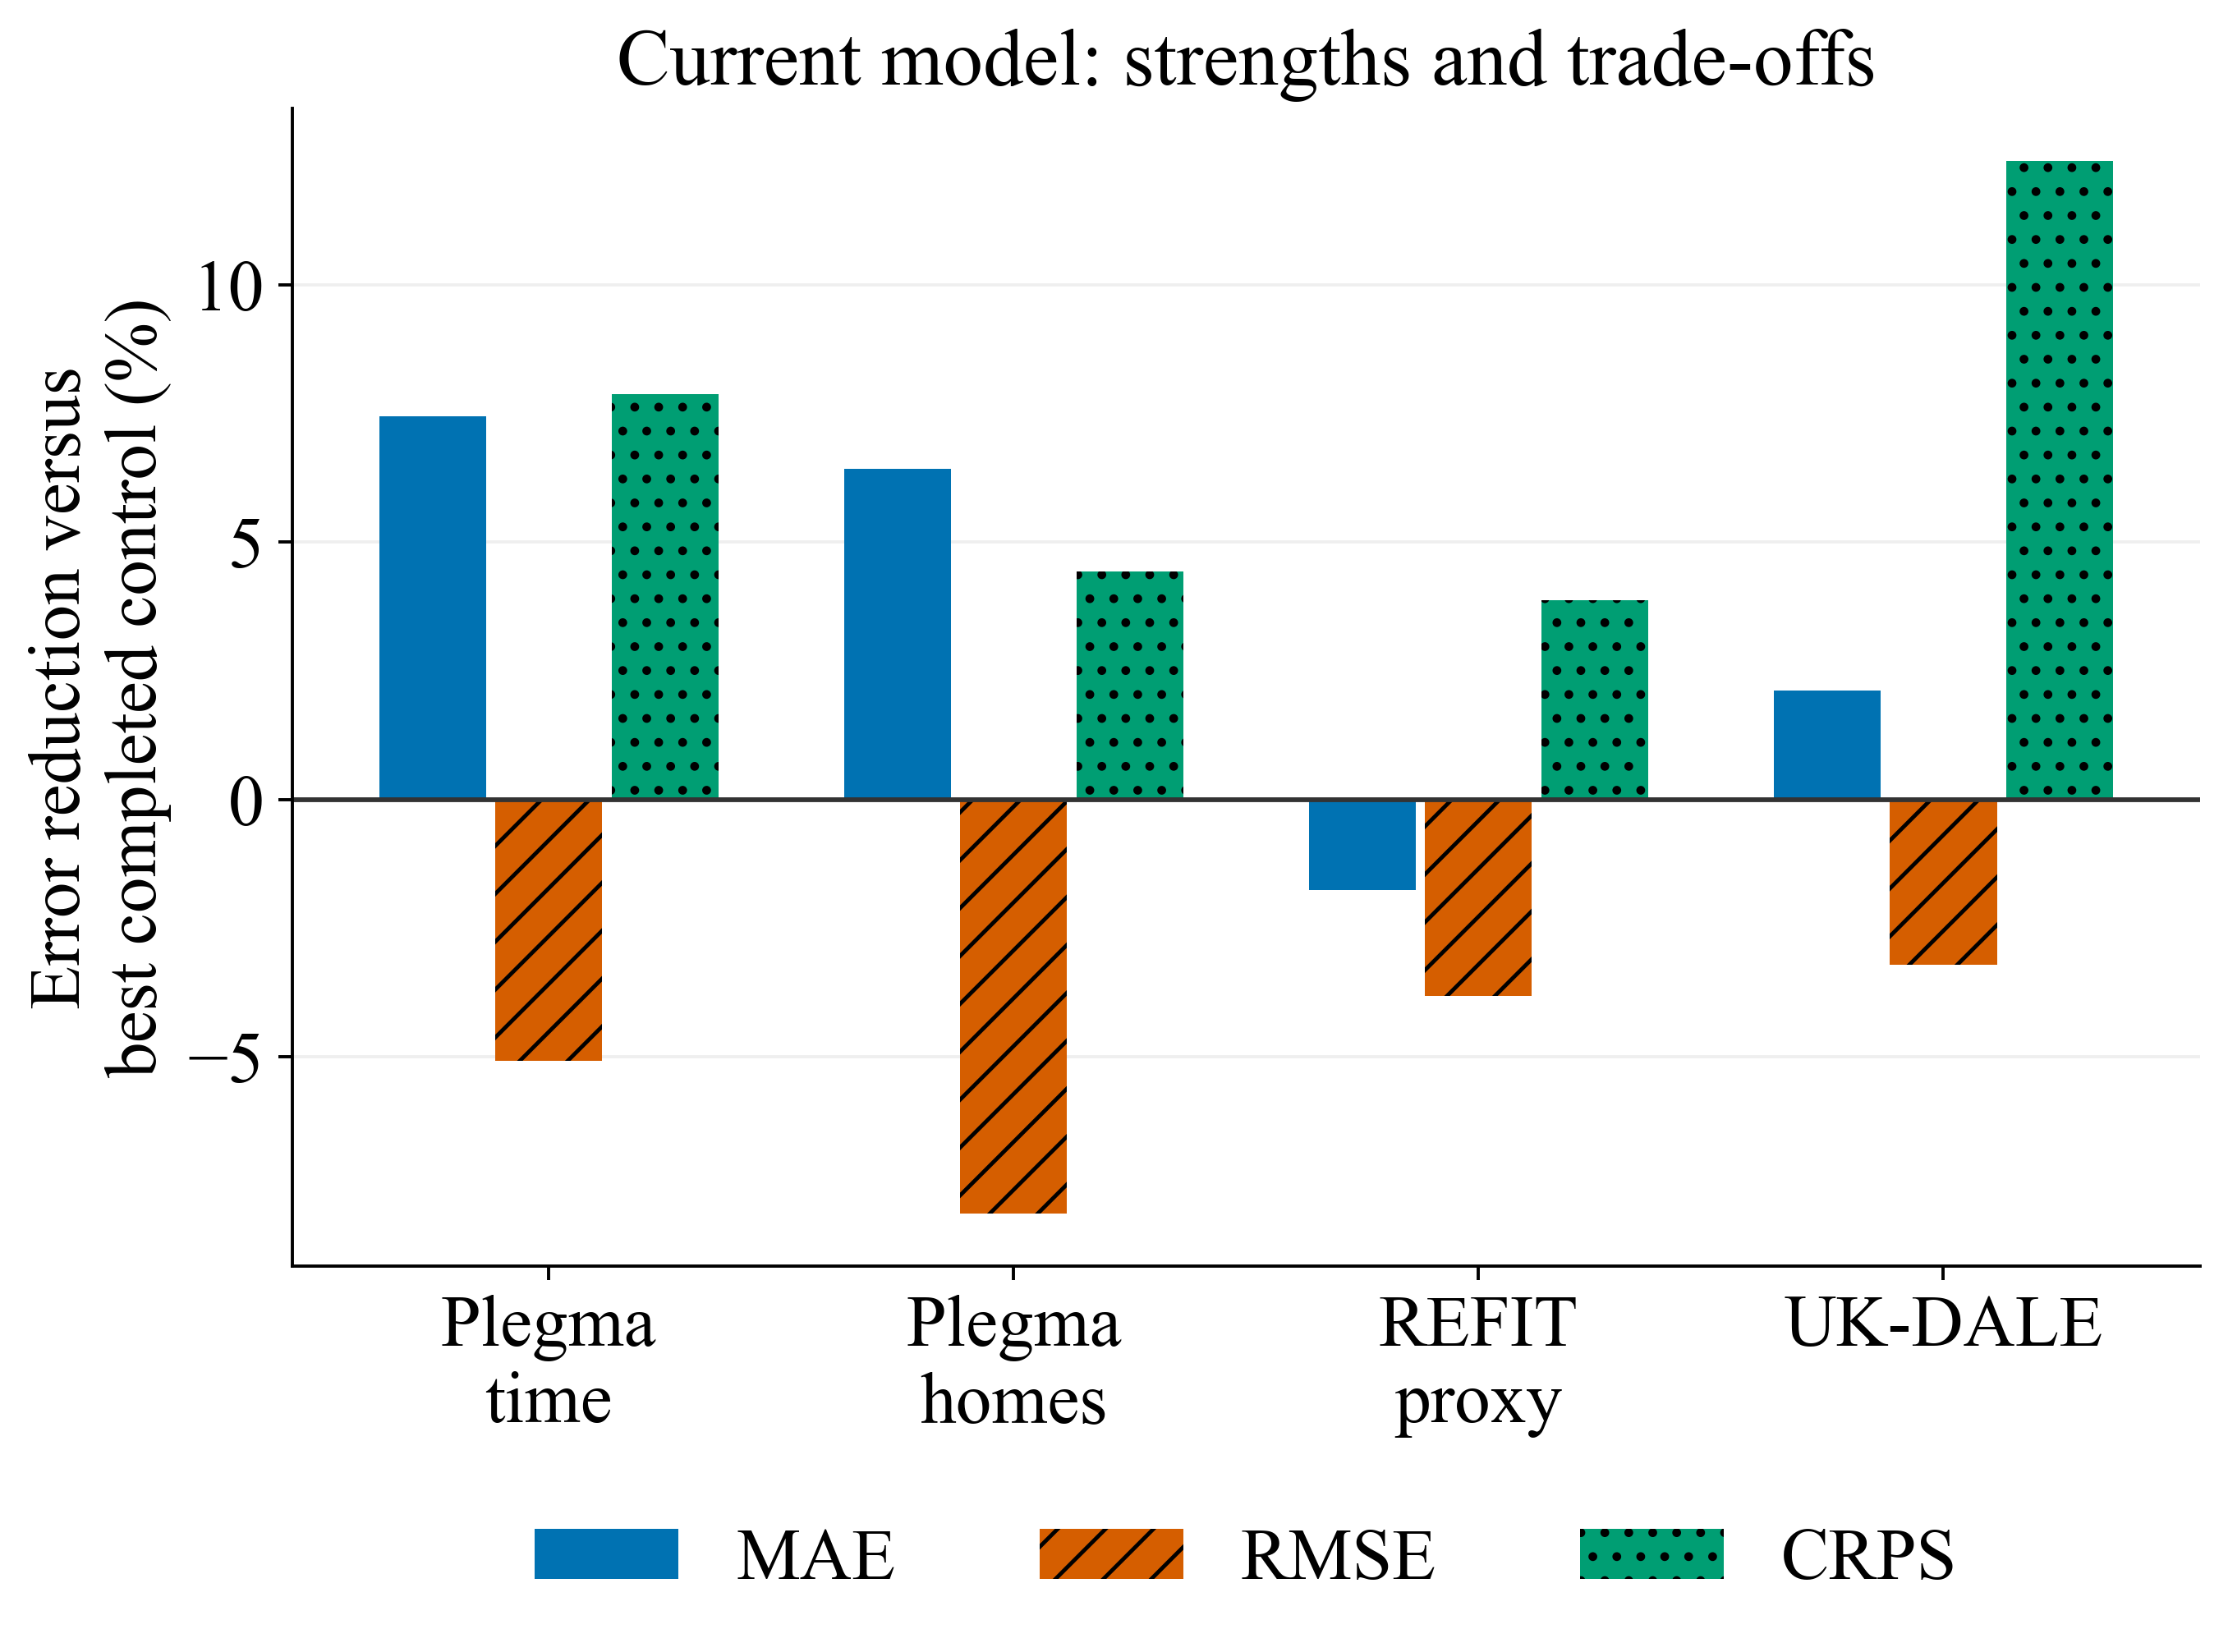

**Retrospective intermodel comparison.** Positive values indicate lower error; negative values indicate worse error. Each reference is the lowest observed error among the completed controls for that metric and domain. This descriptive envelope does not establish statistical significance. Exact absolute values are retained in the complete intermodel tables. REFIT is a proxy-power endpoint.

In [1]:
def render_presentation_nb06_current_comparison():
    from pathlib import Path
    import json, hashlib, re
    import numpy as np
    import pandas as pd
    import matplotlib as mpl
    import matplotlib.pyplot as plt
    from matplotlib import font_manager
    from matplotlib.text import Text
    from IPython.display import display, Image, Markdown
    PRESENT_ROOT = Path.cwd()
    if PRESENT_ROOT.name == "Notebooks": PRESENT_ROOT = PRESENT_ROOT.parent
    assert PRESENT_ROOT.is_dir()
    PRESENT_RUN = "guldana_n3_20261011_presentation"
    font_manager.findfont("Times New Roman", fallback_to_default=False)
    mpl.rcParams.update({"font.family":"Times New Roman", "font.size":18,
        "axes.titlesize":20, "axes.labelsize":18, "xtick.labelsize":18,
        "ytick.labelsize":18, "legend.fontsize":18, "figure.dpi":350,
        "savefig.dpi":350, "axes.unicode_minus":True, "pdf.fonttype":42})
    SOURCE_HASHES = {'Tables/guldana_n3_20261011_v04/06_primary_model_review/group_locked_intermodel.csv': '829547b4f091c755678fdb61aff9cdfe6e4746ac323a1897e350b74c31b3b063', 'Tables/guldana_n3_20261011_v04/06_primary_model_review/refit_zero_shot_intermodel.csv': '9fc88399ba78ec8838fbd239ea1403d10883c6d68a667540559e8cdcb0ad8eb8', 'Tables/guldana_n3_20261011_v04/06_primary_model_review/temporal_locked_intermodel.csv': '7d56ca07353744de7d80e86aaaf59f01b58205024b209bbb42d37d49e5d649d0', 'Tables/guldana_n3_20261011_v04/06_primary_model_review/ukdale_future_intermodel.csv': '58fd227fb7ef328e3b6fd822a896545331f25bfb8f3bb1d6fcc7516ef3009ec4'}
    for relative, digest in SOURCE_HASHES.items():
        assert hashlib.sha256((PRESENT_ROOT / relative).read_bytes()).hexdigest() == digest
    stages = ["temporal_locked", "group_locked", "refit_zero_shot", "ukdale_future"]
    metric_names = {"MAE_kW":"MAE", "RMSE_kW":"RMSE", "CRPS_kW":"CRPS"}
    plot_rows = []
    for stage in stages:
        data = pd.read_csv(PRESENT_ROOT / "Tables/guldana_n3_20261011_v04/06_primary_model_review" / f"{stage}_intermodel.csv")
        ours = data.loc[data.Model.eq("Proposed model")].iloc[0]
        controls = data.loc[~data.Model.eq("Proposed model")]
        for metric, label in metric_names.items():
            reference = controls.loc[controls[metric].idxmin()]
            plot_rows.append({"Domain":stage, "Metric":label, "Proposed":float(ours[metric]),
                "Reference":reference.Model, "Reference value":float(reference[metric]),
                "Error reduction (%)":100 * (1 - float(ours[metric]) / float(reference[metric]))})
    plot_values = pd.DataFrame(plot_rows)
    plot_dir = PRESENT_ROOT / "Tables" / PRESENT_RUN
    plot_dir.mkdir(parents=True, exist_ok=True)
    plot_values.to_csv(plot_dir / "current_model_relative_errors.csv", index=False)
    fig, ax = plt.subplots(figsize=(8.4, 6.2))
    x = np.arange(len(stages))
    for offset, (label, color, hatch) in enumerate([("MAE", "#0072B2", ""), ("RMSE", "#D55E00", "//"), ("CRPS", "#009E73", "..")]):
        values = plot_values.loc[plot_values.Metric.eq(label)].set_index("Domain").loc[stages, "Error reduction (%)"]
        ax.bar(x + (offset - 1) * .25, values, .23, color=color, hatch=hatch, label=label)
    ax.axhline(0, color="#333333", linewidth=1.2)
    ax.set_xticks(x, ["Plegma\ntime", "Plegma\nhomes", "REFIT\nproxy", "UK-DALE"])
    ax.set_ylabel("Error reduction versus\nbest completed control (%)")
    ax.set_title("Current model: strengths and trade-offs")
    ax.grid(axis="y", alpha=.2); ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(loc="upper center", bbox_to_anchor=(.5, -.17), ncol=3, frameon=False)
    fig.subplots_adjust(left=.19, right=.98, bottom=.25, top=.90)
    fig.canvas.draw()
    visible_text = [t for t in fig.findobj(Text) if t.get_visible() and t.get_text().strip()]
    for text in visible_text:
        text.set_text(re.sub(r"(?<![A-Za-z])-(?=\d)", "−", text.get_text()))
        assert 18 <= text.get_fontsize() <= 20
        assert font_manager.FontProperties(fname=font_manager.findfont(text.get_fontproperties(), fallback_to_default=False)).get_name() == "Times New Roman"
    figure_files = {}
    for fmt in ["PNG", "PDF"]:
        folder = PRESENT_ROOT / "Figures" / fmt / PRESENT_RUN
        folder.mkdir(parents=True, exist_ok=True)
        path = folder / f"NB06_current_model_relative_errors.{fmt.lower()}"
        fig.savefig(path, dpi=350, bbox_inches="tight", pad_inches=.10)
        figure_files[str(path.relative_to(PRESENT_ROOT))] = hashlib.sha256(path.read_bytes()).hexdigest()
    plt.close(fig)
    display(Image(filename=str(PRESENT_ROOT / "Figures/PNG" / PRESENT_RUN / "NB06_current_model_relative_errors.png")))
    display(Markdown("**Retrospective intermodel comparison.** Positive values indicate lower error; negative values indicate worse error. Each reference is the lowest observed error among the completed controls for that metric and domain. This descriptive envelope does not establish statistical significance. Exact absolute values are retained in the complete intermodel tables. REFIT is a proxy-power endpoint."))
    proof = {"source_hashes":SOURCE_HASHES, "figures":figure_files,
        "point_predictions_unchanged":True, "new_model_fits":0,
        "font_family":"Times New Roman", "font_pt":[18,20], "dpi":350,
        "figure_inches":[8.4,6.2], "kernel_execution_required":True}
    (PRESENT_ROOT / "Manifests/Runs" / PRESENT_RUN / "nb06_rendered.json").write_text(json.dumps(proof, indent=2) + "\n");

render_presentation_nb06_current_comparison()


## Source-calibrated intervals and the matched-sensor development result

The matched-sensor architecture did not meet its joint inner MAE/RMSE criterion. No new candidate final model or test predictions are produced. The primary point predictor remains unchanged. This section addresses the separate undercoverage of the original intervals with one fixed source-calibration rule, applied identically to ExtraTrees spread and CostSensitiveClassifier.

For source residual scores $s_i=|y_i-\widehat y_i|/\sigma_i$, use the $\lceil(n+1)0.95\rceil$ order statistic $q$ and report $[\max(0,\widehat y-q\sigma),\widehat y+q\sigma]$. Neural and tree scales are frozen raw standard deviations with the pre-existing variance floor; the selector uses a unit scale. The order statistic is fixed before target comparisons. Interval score is width plus $2/0.05$ times the miss distance. Narrow intervals alone are not desirable.

A chronological source diagnostic precedes full-source calibration, after which the calibration parameters are fixed. The [conformal-form interpretation](https://arxiv.org/abs/2107.07511) requires exchangeability, which these dependent time series and shifted households do not establish. These are therefore empirically assessed **source residual-quantile intervals**, without an unconditional 95% guarantee. They are separate from the existing predictive distribution: point predictions and CRPS stay unchanged. No target-domain value adjusts the calibrator. Every existing target comparison remains retrospective.

In [21]:
from pathlib import Path
import json,hashlib,os,time
import numpy as np
import pandas as pd
from IPython.display import display,Markdown
ROOT=Path.cwd()
if ROOT.name=="Notebooks":ROOT=ROOT.parent
assert ROOT.is_dir()
R5="guldana_n3_20261011_v05";R3="guldana_n3_20261011_v03";V2="guldana_n3_20261009_v02"
REC5=ROOT/"Manifests/Runs"/R5;T5=ROOT/"Tables"/R5/"06_interval_calibration";P5=ROOT/"Predictions/evaluation"/R5;M5=ROOT/"Models/probability_calibration"/R5
for folder in [T5,P5,M5]:folder.mkdir(parents=True,exist_ok=True)
C5=json.loads((ROOT/"Configs/revision5_interval_calibration.json").read_text())
L3=json.loads((ROOT/"Manifests/Runs"/R3/"scientific_completion.json").read_text())["artifacts"]
L2=json.loads((ROOT/"Manifests/Runs"/V2/"nb06_article_scientific_gate.json").read_text())["artifacts"]
def sha5(path):
    h=hashlib.sha256()
    with open(path,"rb") as f:
        for b in iter(lambda:f.read(8*1024*1024),b""):h.update(b)
    return h.hexdigest()
def table5(frame,name,caption):
    frame.to_csv(T5/f"{name}.csv",index=False);frame.to_latex(T5/f"{name}.tex",index=False,caption=caption,float_format=lambda v:f"{v:.6f}")
    display(frame.style.format(precision=6,na_rep="Unavailable").hide(axis="index").set_caption(caption))
lineage5={}
def interval_inputs5(stage,seed):
    a=ROOT/"Predictions/evaluation"/R3/stage/f"pattern_seed_{seed}.parquet"
    b=ROOT/"Predictions/evaluation"/V2/stage/f"tabular_seed_{seed}.parquet"
    for path,lock in [(a,L3),(b,L2)]:assert sha5(path)==lock[str(path.relative_to(ROOT))];lineage5[str(path.relative_to(ROOT))]=sha5(path)
    ours=pd.read_parquet(a);other=pd.read_parquet(b)
    for col in ["observation_id","house","timestamp","y_kW"]:np.testing.assert_array_equal(ours[col],other[col])
    arrays={"Proposed model":(ours.prediction_kW.to_numpy(float),np.sqrt(np.maximum(ours.base_variance_kW2.to_numpy(float),C5["variance_floor_kW2"]))),
        "ExtraTrees spread":(other.ExtraTrees.to_numpy(float),np.sqrt(np.maximum(other.ExtraTrees_raw_variance_kW2.to_numpy(float),C5["variance_floor_kW2"]))),
        "CostSensitiveClassifier":(other.CostSensitiveClassifier.to_numpy(float),np.ones(len(other)))}
    assert all(np.isfinite(p).all() and np.isfinite(s).all() and (s>0).all() and (p>=0).all() for p,s in arrays.values())
    return ours,arrays

def calibrate_q5(y,p,sigma):
    scores=np.abs(y-p)/sigma;n=len(scores);k=int(np.ceil((n+1)*C5["coverage"]))
    assert n>100 and 1<=k<=n and np.isfinite(scores).all()
    return float(np.partition(scores,k-1)[k-1]),n,k

def interval_rows5(meta,p,sigma,q,model,stage,seed):
    y=meta.y_kW.to_numpy(float);low=np.maximum(0,p-q*sigma);high=p+q*sigma
    assert np.isfinite(low).all() and np.isfinite(high).all() and (low<=high).all()
    width=high-low;alpha=1-C5["coverage"]
    score=width+2/alpha*(np.maximum(low-y,0)+np.maximum(y-high,0))
    out=meta[["observation_id","house","timestamp","y_kW","gap"]].copy()
    out["Model"]=model;out["Stage"]=stage;out["Seed"]=seed;out["prediction_kW"]=p;out["lower95_kW"]=low;out["upper95_kW"]=high
    out["Coverage95"]=(y>=low)&(y<=high);out["Width95_kW"]=width;out["IntervalScore95_kW"]=score
    return out

def summarize_interval5(rows):
    house=rows.groupby(["Stage","Model","Seed","house"],sort=False)[["Coverage95","Width95_kW","IntervalScore95_kW"]].mean().reset_index()
    summary=house.groupby(["Stage","Model"],sort=False)[["Coverage95","Width95_kW","IntervalScore95_kW"]].mean().reset_index()
    return house,summary


In [2]:
source_rows5=[];q_records5=[];calibration_files5={}
for seed in C5["seeds"]:
    meta,arrays=interval_inputs5("calibration",seed);assert meta.role.eq("calibration").all()
    early=np.zeros(len(meta),bool);late=early.copy()
    for house,g in meta.groupby("house"):
        times=np.sort(g.timestamp.unique());cut=times[len(times)//2-1]
        early[g.index[g.timestamp<=cut]]=True
        late[g.index[g.timestamp>pd.Timestamp(cut)+pd.Timedelta(minutes=360)]]=True
    assert early.sum()>100 and late.sum()>100 and not (early&late).any()
    for model,(p,sigma) in arrays.items():
        q,n,k=calibrate_q5(meta.loc[early,"y_kW"].to_numpy(),p[early],sigma[early])
        source_rows5.append(interval_rows5(meta.loc[late],p[late],sigma[late],q,model,"source_later_half",seed))
        q_full,n_full,k_full=calibrate_q5(meta.y_kW.to_numpy(),p,sigma)
        record={"model":model,"seed":seed,"q":q_full,"n":n_full,"k":k_full,"coverage":C5["coverage"],"source_only":True,"diagnostic_q":q,"diagnostic_fit_rows":n,"diagnostic_eval_rows":int(late.sum()),"config_sha256":sha5(ROOT/"Configs/revision5_interval_calibration.json")}
        path=M5/f"{model.replace(' ','_')}_seed_{seed}.json"
        if path.exists():assert json.loads(path.read_text())==record
        else:path.write_text(json.dumps(record,indent=2)+"\n")
        calibration_files5[str(path.relative_to(ROOT))]=sha5(path);q_records5.append(record)
source5=pd.concat(source_rows5,ignore_index=True);source5.to_parquet(P5/"source_interval_diagnostic.parquet",index=False)
house_source5,summary_source5=summarize_interval5(source5)
house_source5.to_csv(T5/"source_house_seed_scores.csv",index=False)
table5(summary_source5,"source_diagnostic","Source chronological diagnostic: first half calibration, 360-minute purge, later half evaluation; fixed rule, no tuning.")
nb=json.loads((ROOT/"Notebooks/06_frozen_evaluation_statistics_and_publication_results.ipynb").read_text())
bound={c["id"]:"".join(c["source"]) for c in nb["cells"] if c.get("id","").startswith("r5-")}
freeze={"run_id":R5,"primary_point_model":R3,"source_only":True,"source_lineage":lineage5.copy(),"calibrators":calibration_files5,"source":bound,"config_sha256":sha5(ROOT/"Configs/revision5_interval_calibration.json"),"new_point_fits":0,"all_existing_targets_retrospective":True}
freeze_path=REC5/"interval_freeze.json"
if freeze_path.exists():assert json.loads(freeze_path.read_text())==freeze
else:freeze_path.write_text(json.dumps(freeze,indent=2)+"\n")
display(Markdown("**Source calibrators frozen.** The following target calculations cannot alter quantiles, point predictions or CRPS."))


Stage,Model,Coverage95,Width95_kW,IntervalScore95_kW
source_later_half,Proposed model,0.958324,0.555148,1.288469
source_later_half,ExtraTrees spread,0.962341,0.615189,1.105129
source_later_half,CostSensitiveClassifier,0.957358,0.690605,1.689823


In [3]:
freeze5=json.loads((REC5/"interval_freeze.json").read_text());assert freeze5["source_only"]
for name,digest in freeze5["calibrators"].items():assert sha5(ROOT/name)==digest
all_summaries5=[];all_house5=[];interval_artifacts5={}
for stage in C5["domains"]:
    stage_rows=[]
    for seed in C5["seeds"]:
        meta,arrays=interval_inputs5(stage,seed)
        for model,(p,sigma) in arrays.items():
            record=json.loads((M5/f"{model.replace(' ','_')}_seed_{seed}.json").read_text());assert record["source_only"]
            rows=interval_rows5(meta,p,sigma,record["q"],model,stage,seed)
            folder=P5/stage;folder.mkdir(exist_ok=True)
            path=folder/f"{model.replace(' ','_')}_intervals_seed_{seed}.parquet";rows.to_parquet(path,index=False)
            interval_artifacts5[str(path.relative_to(ROOT))]=sha5(path);stage_rows.append(rows)
    combined=pd.concat(stage_rows,ignore_index=True);house,summary=summarize_interval5(combined)
    house.to_csv(T5/f"{stage}_house_seed_scores.csv",index=False)
    combined.groupby(["Model","Seed","house","gap"])[["Coverage95","Width95_kW","IntervalScore95_kW"]].mean().reset_index().to_csv(T5/f"{stage}_gap_scores.csv",index=False)
    all_summaries5.append(summary);all_house5.append(house)
interval_summary5=pd.concat(all_summaries5,ignore_index=True)
table5(interval_summary5,"retrospective_interval_comparison","Same fixed source-only quantile calibration for all three models. Coverage, width and interval score jointly characterize reliability; all domains retrospective.")
(REC5/"interval_evaluation.json").write_text(json.dumps({"run_id":R5,"point_model_unchanged":True,"CRPS_unchanged":True,"new_point_fits":0,"calibrators":calibration_files5,"lineage":lineage5,"predictions":interval_artifacts5,"kernel_pid":os.getpid(),"retrospective":True},indent=2)+"\n")


Stage,Model,Coverage95,Width95_kW,IntervalScore95_kW
temporal_locked,Proposed model,0.952897,0.427113,1.265566
temporal_locked,ExtraTrees spread,0.952384,0.496301,1.089613
temporal_locked,CostSensitiveClassifier,0.960238,0.638069,1.738039
group_locked,Proposed model,0.925591,0.577681,2.098429
group_locked,ExtraTrees spread,0.944255,0.817155,1.841090
group_locked,CostSensitiveClassifier,0.930393,0.716883,2.775976
refit_zero_shot,Proposed model,0.943591,0.844262,2.365269
refit_zero_shot,ExtraTrees spread,0.966093,1.076711,2.283052
refit_zero_shot,CostSensitiveClassifier,0.920447,0.771000,3.540750
ukdale_future,Proposed model,0.960558,0.550879,1.196826


In [4]:
def markdown5(frame):
    def value(v):return f"{v:.6f}" if isinstance(v,(float,np.floating)) else str(v).replace("|","/")
    return "\n".join(["| "+" | ".join(frame.columns)+" |","| "+" | ".join(["---"]*len(frame.columns))+" |",*["| "+" | ".join(value(v) for v in row)+" |" for row in frame.itertuples(index=False,name=None)]])
decision5=json.loads((REC5/"development_decision.json").read_text());assert decision5["accepted"] is False
inner5=pd.concat([pd.read_csv(ROOT/"Tables"/R5/"05_matched_changes"/f"inner_fold_{f}.csv") for f in [1,2,3]],ignore_index=True)
inner_summary5=inner5.groupby("Model",sort=False)[["MAE_kW","RMSE_kW","Bias_kW"]].mean().reset_index()
primary5=interval_summary5[interval_summary5.Model.eq("Proposed model")]
summary_text5=("The matched-sensor architecture completed six registered fits and failed the joint development gate. It was not promoted; no candidate OOF, final fit or test inference followed. "
    "The single primary point model remains revision3. The independent interval repair uses source residual quantiles and the identical rule for two strong controls; point metrics and CRPS are unchanged. "
    f"Proposed-model retrospective95% interval coverage ranges from {primary5.Coverage95.min():.1%} to {primary5.Coverage95.max():.1%}; widths and interval scores must be considered alongside coverage. "
    "These dependent and shifted samples do not establish exchangeability or a universal coverage guarantee. Broad point-metric superiority, mathematical priority and full submission readiness remain unproven.")
report5="\n\n".join(["# Latest bounded model experiment and interval repair",summary_text5,"## Inner development only: three-fold means",markdown5(inner_summary5),"## Source chronological diagnostic",markdown5(summary_source5),"## Retrospective interval comparison",markdown5(interval_summary5),"## Scientific scope","The physical difference identity is established prior art, not claimed as a new theorem. Existing checkpoints and all prior negative results remain preserved. Source-only interval calibration is a reliability operation, not a new predictive distribution or an improvement of CRPS. The six original notebooks remain canonical. Repeated administration was removed and repeated drivers consolidated with archived provenance.","A metadata-only audit identifies ECO as a prospective independent source with six homes and measured active aggregate power. Access is possible, but archive sizes and auxiliary freshness still require audit. No new energy values were opened and no independent confirmation is yet claimed."])+"\n"
(ROOT/"Docs/latest_model_and_interval_assessment.md").write_text(report5)
# Preserve existing reports verbatim below a concise latest-status pointer.
for name in ["model_update_assessment.md","compact_article_results.md","model_card.md","limitations.md","scientific_strengthening_status.md","article_evidence_matrix.md"]:
    path=ROOT/"Docs"/name;old=path.read_text()
    if not old.startswith("> **Latest bounded update, revision5.**"):
        path.write_text("> **Latest bounded update, revision5.** "+summary_text5+" [Complete executed interval and experiment results](latest_model_and_interval_assessment.md). The main point-model results below remain unchanged; their83–88% coverage refers to the original CRPS-calibrated distribution, not these separate source-quantile intervals.\n\n"+old)
protocol_path=ROOT/"Docs/research_protocol.md"
if "## Revision5: matched changes and interval reliability" not in protocol_path.read_text():
    protocol_path.write_text(protocol_path.read_text()+"\n\n## Revision5: matched changes and interval reliability\n\nThe latest explicit improvement request authorized one six-fit matched-change hypothesis. Its joint gate failed unchanged; conditional repeats were not performed. A separate, fixed source residual-quantile interval rule was registered and frozen before retrospective interval evaluation. No point model, old prediction, locked split or CRPS was changed. See `Configs/proposed_revision_05.json`, `Configs/revision5_interval_calibration.json` and `latest_model_and_interval_assessment.md`.\n")
readme=ROOT/"README.md"
if not readme.read_text().startswith("> **Latest assessment:**"):
    readme.write_text("> **Latest assessment:** [Bounded architecture test and source-calibrated intervals](Docs/latest_model_and_interval_assessment.md). The architecture candidate was not promoted; the primary point model remains unchanged. Broad superiority and full Q1 submission readiness are not established.\n\n"+readme.read_text())
artifacts5={}
for folder in [ROOT/"Models/proposed"/R5,M5,ROOT/"Predictions/development_proposed"/R5,P5,ROOT/"Tables"/R5]:
    for path in folder.rglob('*'):
        if path.is_file():artifacts5[str(path.relative_to(ROOT))]=sha5(path)
(REC5/"bounded_work_complete.json").write_text(json.dumps({"run_id":R5,"status":"architecture_not_promoted_interval_assessment_complete","primary_point_model":R3,"new_search_fits":6,"new_final_point_fits":0,"new_independent_test":False,"goal_achieved":False,"artifacts":artifacts5,"conclusion":summary_text5},indent=2)+"\n")
display(Markdown(summary_text5))


The matched-sensor architecture completed six prespecified fits and did not meet the joint development criterion. It was not adopted; no out-of-fold prediction, final fit or test inference followed. The single primary point model remains revision 3. The separate interval calibration uses source residual quantiles and the identical rule for two strong controls; point metrics and CRPS are unchanged. Proposed-model retrospective 95% interval coverage ranges from 92.6% to 96.1%; widths and interval scores must be considered alongside coverage. These dependent and shifted samples do not establish exchangeability or a universal coverage guarantee. Broad point-metric superiority is not established.

## Independent evaluation on measured active power: ECO
The current proposed model and six fixed comparators will be evaluated once on six previously unopened Swiss households. All model states, source calibrators, observation rules and statistical endpoints are fixed before measurement access. The primary criterion requires at least 10% lower MAE and lower RMSE against every comparator under the prespecified household-level assumptions. An incomplete run or a failed conjunction does not support general superiority. No new fitting is permitted.

In [22]:
# Definitions only; no archive is opened by this cell.
import os, sys, json, hashlib, time, shutil, resource, urllib.request, urllib.parse, zipfile, stat, re, datetime, struct
from pathlib import Path, PurePosixPath

class ECOArchiveGateError(RuntimeError):
    pass

def eco_reader_frozen_contract():
    freeze, protocol = eco_frozen_protocol()
    if freeze.get("reader_source_sha256") != ECO_READER_IMPLEMENTATION_HASH:
        raise ECOArchiveGateError("The exact reader source is not in the pre-access freeze.")
    caps = protocol["resources"]
    expected = {"archive_download_limit_bytes":16*1024**3,
                "total_new_persistent_storage_limit_bytes":24*1024**3,
                "minimum_free_disk_headroom_bytes":16*1024**3,
                "decompressed_stream_read_limit_bytes":256*1024**3,
                "whole_kernel_RSS_operational_limit_bytes":8*1024**3}
    if any(caps.get(k)!=v for k,v in expected.items()):
        raise ECOArchiveGateError("Operational caps differ from the reviewed reader contract.")
    return freeze, protocol

def eco_reader_utc():
    return datetime.datetime.now(datetime.timezone.utc).isoformat()

def eco_reader_hash(path):
    digest=hashlib.sha256()
    with Path(path).open("rb") as stream:
        for chunk in iter(lambda:stream.read(4*1024**2),b""):digest.update(chunk)
    return digest.hexdigest()

class ECOIOBudget:
    # One sequential owner only. Atomic journal reservations fail closed across crashes.
    # No previous partial artifact is deleted, replaced, or silently excluded.
    def __init__(self, ledger_file, persistent_roots):
        self.freeze,self.protocol=eco_reader_frozen_contract()
        self.root=ROOT.resolve();self.caps=self.protocol["resources"]
        self.roots=tuple(Path(p).resolve() for p in persistent_roots)
        if len(set(self.roots))!=len(self.roots):raise ECOArchiveGateError("Duplicate storage roots.")
        if any(self.root not in p.parents for p in self.roots):raise ECOArchiveGateError("ECO namespace must remain inside this project.")
        if any(a!=b and a in b.parents for a in self.roots for b in self.roots):
            raise ECOArchiveGateError("Persistent roots must not overlap.")
        registered=tuple(sorted(self.freeze["persistent_roots"]))
        if tuple(sorted(str(p.relative_to(self.root)) for p in self.roots))!=registered:
            raise ECOArchiveGateError("Storage scope is not the frozen full ECO scope.")
        self.ledger_file=Path(ledger_file).resolve()
        self.check_path(self.ledger_file)
        self.ledger_file.parent.mkdir(parents=True,exist_ok=True)
        if self.ledger_file.exists():
            self.state=json.loads(self.ledger_file.read_text())
            if self.state["freeze_sha256"]!=self.freeze["freeze_sha256"]:
                raise ECOArchiveGateError("Existing ledger belongs to a different freeze.")
        else:
            self.state={"freeze_sha256":self.freeze["freeze_sha256"],"created_utc":eco_reader_utc(),
                "compressed_reserved_or_read_bytes":0,"decompressed_reserved_or_read_bytes":0,
                "first_archive_request_utc":None,"first_archive_body_read_utc":None,
                "first_measurement_open_utc":None,"peak_RSS_bytes":0,"status":"prepared_after_freeze"}
            self.save()
        self.guard()
    def check_path(self,path):
        p=Path(path).resolve()
        if not any(p==r or r in p.parents for r in self.roots):
            raise ECOArchiveGateError("Write outside the frozen ECO persistent scope.")
    def save(self):
        data=(json.dumps(self.state,indent=2)+"\n").encode()
        tmp=self.ledger_file.with_name(self.ledger_file.name+".next")
        if tmp.exists():raise ECOArchiveGateError("Interrupted ledger replacement retained for explicit recovery.")
        with tmp.open("xb") as f:f.write(data);f.flush();os.fsync(f.fileno())
        os.replace(tmp,self.ledger_file)
    def resident_guard(self, reserve_bytes=0):
        rss=int(resource.getrusage(resource.RUSAGE_SELF).ru_maxrss)
        if sys.platform!="darwin":rss*=1024
        self.state["peak_RSS_bytes"]=max(self.state["peak_RSS_bytes"],rss)
        if rss+int(reserve_bytes)>self.caps["whole_kernel_RSS_operational_limit_bytes"]:
            raise ECOArchiveGateError("Whole-process peak RSS exceeds the frozen8GiB cap.")
    def persistent_bytes(self):
        total=0
        for folder in self.roots:
            if not folder.exists():continue
            for path in folder.rglob("*"):
                if path.is_symlink():raise ECOArchiveGateError("Symlink in counted ECO output scope.")
                if path.is_file():total+=path.stat().st_size
        return total
    def guard(self, planned_write_bytes=0):
        self.resident_guard()
        n=int(planned_write_bytes)
        if n<0:raise ECOArchiveGateError("Negative storage reservation.")
        if self.persistent_bytes()+n>self.caps["total_new_persistent_storage_limit_bytes"]:
            raise ECOArchiveGateError("The24GiB persistent-storage cap would be exceeded.")
        if shutil.disk_usage(self.root).free-n<self.caps["minimum_free_disk_headroom_bytes"]:
            raise ECOArchiveGateError("The16GiB free-disk headroom would be violated.")
    def mark_first(self,key):
        if self.state[key] is None:self.state[key]=eco_reader_utc();self.save()
    def reserve(self,kind,n):
        key={"compressed":"compressed_reserved_or_read_bytes","decompressed":"decompressed_reserved_or_read_bytes"}[kind]
        cap=self.caps[{"compressed":"archive_download_limit_bytes","decompressed":"decompressed_stream_read_limit_bytes"}[kind]]
        if n<0 or self.state[key]+n>cap:raise ECOArchiveGateError("Frozen "+kind+" stream cap exceeded.")
        self.state[key]+=int(n);self.save()
    def settle(self,kind,reserved,actual):
        if not 0<=actual<=reserved:raise ECOArchiveGateError("Invalid byte accounting.")
        key={"compressed":"compressed_reserved_or_read_bytes","decompressed":"decompressed_reserved_or_read_bytes"}[kind]
        self.state[key]-=int(reserved-actual);self.save()
    def write_json_new(self,path,record):
        path=Path(path);self.check_path(path)
        body=(json.dumps(record,indent=2)+"\n").encode();self.guard(len(body)+65536)
        path.parent.mkdir(parents=True,exist_ok=True)
        with path.open("xb") as stream:stream.write(body);stream.flush();os.fsync(stream.fileno())


In [23]:
def eco_download_registered_archives(budget, archive_directory):
    # Explicit post-freeze call only; sequential GET without Range or automatic retries.
    freeze,protocol=eco_reader_frozen_contract()
    directory=Path(archive_directory);budget.check_path(directory);directory.mkdir(parents=True,exist_ok=True)
    inventory=protocol["source"]["archive_inventory"]
    if len(inventory)!=12 or {r["house"] for r in inventory}!={1,2,3,4,5,6}:
        raise ECOArchiveGateError("All twelve archives are required.")
    records=[]
    for item in inventory:
        name=item["file"]
        if not re.fullmatch(r"0[1-6]_(?:sm|plugs)_csv\.zip",name):raise ECOArchiveGateError("Unregistered archive filename.")
        target=directory/name;partial=directory/(name+".part");receipt=directory/(name+".receipt.json")
        if target.exists():
            if not receipt.is_file():raise ECOArchiveGateError("Original ZIP lacks its completed acquisition receipt.")
            old=json.loads(receipt.read_text())
            if old["freeze_sha256"]!=freeze["freeze_sha256"] or old["file_pid"]!=item["file_pid"] or old["bytes"]!=target.stat().st_size or old["sha256"]!=eco_reader_hash(target):
                raise ECOArchiveGateError("Existing original ZIP/receipt integrity failed.")
            records.append(old);continue
        if partial.exists() or receipt.exists():raise ECOArchiveGateError("Partial transport preserved. No automatic overwrite or unverified Range resume.")
        url="https://app.data-archive.ethz.ch/delivery/DeliveryManagerServlet?dps_pid="+item["file_pid"]
        request=urllib.request.Request(url,headers={"User-Agent":"Guldana-N3-frozen-ECO/1.0","Accept-Encoding":"identity"})
        budget.guard(4*1024**2+65536);budget.mark_first("first_archive_request_utc")
        digest=hashlib.sha256();count=0;started=time.perf_counter()
        try:
            with urllib.request.urlopen(request,timeout=60) as response,partial.open("xb") as sink:
                if response.status!=200:raise ECOArchiveGateError("Unexpected archive HTTP status.")
                parsed=urllib.parse.urlparse(response.url)
                if parsed.scheme!="https" or parsed.hostname!="app.data-archive.ethz.ch":
                    raise ECOArchiveGateError("Archive redirected outside the official HTTPS host.")
                if response.headers.get("Content-Encoding", "identity").lower() not in {"identity",""}:
                    raise ECOArchiveGateError("Unexpected transport content encoding.")
                raw_length=response.headers.get("Content-Length")
                expected=int(raw_length) if raw_length and raw_length.isdigit() and int(raw_length)>0 else None
                if expected is not None and budget.state["compressed_reserved_or_read_bytes"]+expected>budget.caps["archive_download_limit_bytes"]:
                    raise ECOArchiveGateError("Reported archive length exceeds remaining download cap.")
                headers={k:v for k,v in response.headers.items() if k.lower() in {"content-length","content-type","content-disposition","etag","last-modified","accept-ranges","transfer-encoding"}}
                while True:
                    remaining=budget.caps["archive_download_limit_bytes"]-budget.state["compressed_reserved_or_read_bytes"]
                    if remaining<=0:raise ECOArchiveGateError("Download cap reached before confirmed EOF.")
                    reservation=min(4*1024**2,remaining)
                    budget.guard(reservation+65536);budget.reserve("compressed",reservation)
                    budget.mark_first("first_archive_body_read_utc")
                    chunk=response.read(reservation)
                    budget.settle("compressed",reservation,len(chunk))
                    if not chunk:break
                    sink.write(chunk);digest.update(chunk);count+=len(chunk)
                sink.flush();os.fsync(sink.fileno())
                if expected is not None and count!=expected:raise ECOArchiveGateError("Archive Content-Length mismatch.")
            if not zipfile.is_zipfile(partial):raise ECOArchiveGateError("Official response is not a complete ZIP archive.")
            os.rename(partial,target)
            record={**item,"url":url,"final_url":response.url,"headers":headers,"bytes":count,
                    "sha256":digest.hexdigest(),"freeze_sha256":freeze["freeze_sha256"],
                    "completed_utc":eco_reader_utc(),"seconds":time.perf_counter()-started,
                    "path":str(target.relative_to(ROOT)),"publisher_checksum_verified":False}
            budget.write_json_new(receipt,record);records.append(record)
        except BaseException:
            budget.state["status"]="incomplete_transport_or_resource_gate";budget.save();raise
    if len(records)!=12:raise ECOArchiveGateError("Incomplete all-house acquisition.")
    budget.state["status"]="all12_original_archives_acquired";budget.save()
    return records


In [24]:
def eco_csv_member_identity(name, house, kind):
    # Documented exporter suffixes only. Archive-specific prefixes are not inferred from values.
    p=PurePosixPath(name)
    if p.is_absolute() or ".." in p.parts or "\\" in name:raise ECOArchiveGateError("Unsafe ZIP member path.")
    if any(part in {"__MACOSX",".DS_Store"} or part.startswith("._") for part in p.parts):return None
    if p.suffix.lower()!=".csv":
        if p.suffix.lower() in {".txt",".md",".pdf"}:return None
        raise ECOArchiveGateError("Unclassified non-CSV archive member; do not silently discard it.")
    if not re.fullmatch(r"\d{4}-\d{2}-\d{2}\.csv",p.name):raise ECOArchiveGateError("Unexpected daily CSV filename.")
    date=p.stem
    if datetime.date.fromisoformat(date).isoformat()!=date:raise ECOArchiveGateError("Invalid publisher date.")
    hh=f"{house:02d}";parents=p.parts[:-1]
    prefix_options={() ,(hh,), (f"{hh}_{kind}_csv",), ("smartmeter_csv",hh) if kind=="sm" else ("plugs_csv",hh),
                    ("data","eco","smartmeter_csv",hh) if kind=="sm" else ("data","eco","plugs_csv",hh)}
    if kind=="sm":
        if parents not in prefix_options:raise ECOArchiveGateError("Unregistered smart-meter ZIP layout.")
        return date,"P_agg"
    if not parents or not re.fullmatch(r"\d{2}",parents[-1]):raise ECOArchiveGateError("Plug channel is not explicit in the ZIP path.")
    if parents[:-1] not in prefix_options:raise ECOArchiveGateError("Unregistered plug ZIP layout.")
    channel=int(parents[-1])
    return date,f"ECO_h{house:02d}_plug{channel:02d}"

def eco_check_zip_directory_bound(path,budget):
    # Inspect at most the standard65557-byte ZIP tail and56-byte ZIP64 header.
    # This gate runs before ZipFile allocates its central-directory objects.
    path=Path(path);size=path.stat().st_size
    with path.open("rb") as stream:
        tail_size=min(size,65557);stream.seek(size-tail_size);tail=stream.read(tail_size)
        offset=tail.rfind(b"PK\x05\x06")
        while offset>=0:
            if len(tail)-offset>=22:
                fields=struct.unpack_from("<4s4H2IH",tail,offset)
                if offset+22+fields[-1]==len(tail):break
            offset=tail.rfind(b"PK\x05\x06",0,offset)
        if offset<0:raise ECOArchiveGateError("ZIP end-of-directory record is absent.")
        _,disk,central_disk,disk_entries,entries,central_bytes,central_offset,comment=fields
        absolute_eocd=size-tail_size+offset
        if disk or central_disk or disk_entries!=entries:raise ECOArchiveGateError("Multi-disk ZIP is not supported.")
        if entries==65535 or central_bytes==4294967295 or central_offset==4294967295:
            if absolute_eocd<20:raise ECOArchiveGateError("ZIP64 locator is absent.")
            stream.seek(absolute_eocd-20);locator=stream.read(20)
            signature,z64disk,z64offset,total_disks=struct.unpack("<4sIQI",locator)
            if signature!=b"PK\x06\x07" or z64disk!=0 or total_disks!=1:raise ECOArchiveGateError("Unsupported ZIP64 locator.")
            if z64offset<0 or z64offset+56>absolute_eocd:raise ECOArchiveGateError("Invalid ZIP64 record offset.")
            stream.seek(z64offset);header=stream.read(56)
            z64=struct.unpack("<4sQ2H2I4Q",header)
            if z64[0]!=b"PK\x06\x06" or z64[1]<44 or z64[4]!=0 or z64[5]!=0 or z64[6]!=z64[7]:
                raise ECOArchiveGateError("Unsupported ZIP64 end-of-directory record.")
            entries,central_bytes,central_offset=z64[7],z64[8],z64[9]
        if entries>100000 or central_bytes>64*1024**2:
            raise ECOArchiveGateError("ZIP central directory exceeds frozen metadata bounds.")
        if central_offset+central_bytes>absolute_eocd:
            raise ECOArchiveGateError("ZIP central directory offset/size is invalid.")
        budget.resident_guard(reserve_bytes=8*central_bytes+512*entries)
    return {"entries":entries,"central_directory_bytes":central_bytes}

def eco_build_zip_index(archive_path,house,kind,protocol,budget):
    # ZIP directory contains names/sizes, but this function is still post-freeze only.
    eco_reader_frozen_contract();budget.guard()
    path=Path(archive_path)
    if not zipfile.is_zipfile(path):raise ECOArchiveGateError("Invalid original ZIP.")
    eco_check_zip_directory_bound(path,budget)
    allowed={r["sensor_key"]:r for r in protocol["auxiliary_contract"]["channel_inventory"] if r["house"]==house}
    index={};omitted=[]
    with zipfile.ZipFile(path) as zf:
        infos=zf.infolist()
        if len(infos)>100000:raise ECOArchiveGateError("ZIP central-directory entry operational limit exceeded.")
        if sum(46+len(x.filename.encode("utf-8"))+len(x.extra)+len(x.comment) for x in infos)>64*1024**2:
            raise ECOArchiveGateError("ZIP central-directory operational limit exceeded.")
        for info in infos:
            if info.is_dir():continue
            if info.flag_bits&1 or stat.S_ISLNK(info.external_attr>>16):raise ECOArchiveGateError("Encrypted or symlink ZIP member.")
            identity=eco_csv_member_identity(info.filename,house,kind)
            if identity is None:omitted.append({"name":info.filename,"reason":"nonmeasurement auxiliary member"});continue
            date,sensor=identity
            start,end=ECO_RANGES[house]
            if not start<=date<=end:raise ECOArchiveGateError("Daily file outside the frozen documented date range.")
            if kind=="plugs":
                if sensor not in allowed:raise ECOArchiveGateError("Unregistered plug channel.")
                if not allowed[sensor]["physical_input_eligible"]:
                    omitted.append({"name":info.filename,"reason":"metadata-declared derived/nonphysical stream; no body read"});continue
            if info.file_size<1:raise ECOArchiveGateError("Empty daily CSV schema.")
            index.setdefault(identity,[]).append(info)
    if not index:raise ECOArchiveGateError("No recognized physical daily files in required archive.")
    return index,omitted

def eco_read_zip_day(zf,info,columns,budget):
    # Parse all fields for schema, expose only target first column or single physical plug.
    # No header, padding, interpolation, row truncation, or ZIP extraction.
    budget.guard();budget.reserve("decompressed",int(info.file_size))
    budget.mark_first("first_measurement_open_utc")
    values=np.empty(86400,dtype=np.float64);digest=hashlib.sha256();rows=0;byte_count=0
    with zf.open(info,"r") as stream:
        while True:
            line=stream.readline(4097)
            if not line:break
            byte_count+=len(line);digest.update(line)
            if len(line)>4096:raise ECOArchiveGateError("Daily CSV line exceeds the frozen4096-byte parser bound.")
            if rows>=86400:raise ECOArchiveGateError("Daily CSV has more than86400rows.")
            try:
                tokens=line.decode("ascii").rstrip("\r\n").split(",")
                if len(tokens)!=columns or any(not token.strip() for token in tokens):
                    raise ValueError("wrong field count or empty token")
                fields=[float(token) for token in tokens]
            except (UnicodeDecodeError,ValueError) as exc:
                raise ECOArchiveGateError("Daily CSV numerical schema mismatch.") from exc
            values[rows]=fields[0];rows+=1
            if rows%8192==0:budget.resident_guard()
    if rows!=86400 or byte_count!=info.file_size:
        raise ECOArchiveGateError("Daily CSV size/row count differs from publisher contract.")
    # Reading to EOF checks ZIP CRC. SHA256 also distinguishes duplicate members.
    record={"member":info.filename,"member_offset":info.header_offset,"rows":rows,"bytes":byte_count,
            "sha256":digest.hexdigest(),"CRC32":f"{info.CRC:08x}","columns":columns}
    return values,record

def _eco_iter_house_days_unhandled(house, acquisition_records, budget, audit_directory):
    freeze,protocol=eco_reader_frozen_contract();house=int(house)
    if house not in range(1,7):raise ECOArchiveGateError("Unregistered household.")
    selected=[r for r in acquisition_records if r["house"]==house]
    if len(selected)!=2 or {r["file"] for r in selected}!={f"{house:02d}_sm_csv.zip",f"{house:02d}_plugs_csv.zip"}:
        raise ECOArchiveGateError("Both original archive types are required for each house.")
    originals={};indices={};omitted={}
    for row in selected:
        if row["freeze_sha256"]!=freeze["freeze_sha256"]:raise ECOArchiveGateError("Archive acquired under another freeze.")
        path=ROOT/row["path"]
        if path.stat().st_size!=row["bytes"] or eco_reader_hash(path)!=row["sha256"]:
            raise ECOArchiveGateError("Retained original archive changed.")
        kind="sm" if row["file"].endswith("_sm_csv.zip") else "plugs"
        originals[kind]=path
        indices[kind],omitted[kind]=eco_build_zip_index(path,house,kind,protocol,budget)
    dates=sorted({date for index in indices.values() for date,sensor in index})
    audit_directory=Path(audit_directory);budget.check_path(audit_directory)
    budget.write_json_new(audit_directory/f"house_{house:02d}_inventory.json",{
        "house":house,"freeze_sha256":freeze["freeze_sha256"],"originals":selected,
        "member_counts":{kind:sum(map(len,index.values())) for kind,index in indices.items()},"omitted":omitted,
        "date_count":len(dates),"layout_policy":"exact exporter suffix whitelist; no measurement-dependent inference"})
    with zipfile.ZipFile(originals["sm"]) as smart,zipfile.ZipFile(originals["plugs"]) as plugs:
        archives={"sm":smart,"plugs":plugs}
        for date in dates:
            channels={};records=[]
            for kind,index in indices.items():
                for (member_date,sensor),members in sorted(index.items()):
                    if member_date!=date:continue
                    first=None;first_record=None
                    for info in sorted(members,key=lambda x:(x.filename,x.header_offset)):
                        values,record=eco_read_zip_day(archives[kind],info,16 if kind=="sm" else 1,budget)
                        record.update(sensor=sensor,archive=str(originals[kind].relative_to(ROOT)))
                        if first is None:first=values;first_record=record
                        elif record["sha256"]!=first_record["sha256"]:
                            raise ECOArchiveGateError("Conflicting daily duplicates; household is incomplete.")
                        else:record["duplicate_of"]=first_record["member"]
                        records.append(record)
                    channels[sensor]=first
            budget.write_json_new(audit_directory/f"house_{house:02d}_{date}.json",{
                "house":house,"date":date,"freeze_sha256":freeze["freeze_sha256"],"members":records})
            budget.guard()
            yield {"date":date,"channels":channels}
    budget.state["status"]=f"house_{house:02d}_daily_reader_completed";budget.save()

def eco_house_original_sources(house,acquisition_records):
    records=[r for r in acquisition_records if r["house"]==int(house)]
    if len(records)!=2:raise ECOArchiveGateError("Both household source ZIPs are required.")
    return {r["path"]:r["sha256"] for r in records}


def eco_iter_house_days(house, acquisition_records, budget, audit_directory):
    try:
        yield from _eco_iter_house_days_unhandled(house, acquisition_records, budget, audit_directory)
    except BaseException as exc:
        budget.state["status"]="incomplete_reader_or_resource_gate"
        budget.state["reader_failure"]={"house":int(house),"exception":type(exc).__name__,
            "message":str(exc),"utc":eco_reader_utc()}
        budget.save()
        raise


### ECO: prospective adapter, prepared before measurement access

These cells reuse the prespecified observation masks, 172 raw / 180 transformed tabular features, 360-minute observable history and frozen 60-minute neural encoder inputs. ECO uses publisher calendar labels without a UTC assertion. Every date is retained in the grid, including unavailable dates, so the existing one-day/week calendar lookups preserve their meaning.

Physical channels are fixed by documentation; House2 derived channels10–12 are excluded. The aggregate is hidden at the query minute and no exact balance constraint is imposed. The source probability/interval calibrators remain frozen. The adapter is defined before any ECO measurement is read.

In [25]:
# Definitions only. The pre-access freeze is supplied and checked in a separate visible cell.
ECO_STAGE = "eco_independent_zero_shot"
ECO_RUN = "eco_independent_v03_20261011"
ECO_CONTRACT = "ECO_measured_active_power"
ECO_DATA = ROOT / "Data/Processed" / "guldana_n3_20261011_v05" / ECO_RUN
ECO_RANGES = {1:("2012-06-01","2013-01-31"), 2:("2012-06-01","2013-01-31"),
              3:("2012-07-26","2013-01-31"), 4:("2012-06-27","2013-01-31"),
              5:("2012-06-27","2013-01-31"), 6:("2012-06-27","2013-01-31")}

def eco_frozen_protocol():
    # Must verify the pre-value freeze, full source closure and artifact hashes externally.
    freeze = require_eco_measurement_freeze()
    assert freeze["status"] == "frozen_before_energy_access"
    assert freeze["adapter_source_sha256"] == ECO_ADAPTER_IMPLEMENTATION_HASH
    path = ROOT / freeze["protocol_file"]
    assert file_sha256(path) == freeze["protocol_sha256"]
    protocol = json.loads(path.read_text())
    assert protocol["source"]["homes"] == [1,2,3,4,5,6]
    assert protocol["cohort_and_masks"]["seeds"] == [17,43,101]
    assert protocol["auxiliary_contract"]["balance_eligible"] is False
    rule = protocol["target_contract"]["minute_coverage_definition"]
    assert (rule["ten_second_bins"],rule["minimum_occupied_bins"],rule["maximum_gap_seconds"],rule["include_minute_edges"]) == (6,4,30,True)
    return freeze, protocol

def eco_file_record(path):
    return {"name":path.name,"bytes":path.stat().st_size,"sha256":file_sha256(path)}

def eco_verify_files(folder, records):
    for item in records:
        path = folder / item["name"]
        assert path.parent.resolve() == folder.resolve() and not path.is_symlink()
        assert path.stat().st_size == item["bytes"] and file_sha256(path) == item["sha256"]

def eco_reduce_publisher_day(power_w):
    # No time interpolation; the row ordinal is the source clock, not an inferred UTC time.
    values = np.asarray(power_w,dtype=np.float64)
    assert values.shape == (86400,), "Unexpected daily schema; quarantine upstream."
    valid = np.isfinite(values) & (values >= 0)
    minute_values = values.reshape(1440,60)
    minute_valid = valid.reshape(1440,60)
    count = minute_valid.sum(axis=1)
    bins = minute_valid.reshape(1440,6,10).any(axis=2).sum(axis=1)
    positions = np.arange(60)[None,:]
    last = np.maximum.accumulate(np.where(minute_valid,positions,-1),axis=1)
    previous = np.column_stack([np.zeros(1440,dtype=int),last[:,:-1]])
    gaps = np.where(minute_valid,positions-np.maximum(previous,0),0)
    maxgap = np.maximum(gaps.max(axis=1),60-last[:,-1]).astype(np.float64)
    maxgap[count==0] = np.inf
    mean = np.divide(np.where(minute_valid,minute_values/1000.,0).sum(axis=1),count,
                     out=np.full(1440,np.nan),where=count>0)
    available = (bins>=4) & (maxgap<=30)
    audit = {"valid_records":int(valid.sum()),"sentinel_minus_one":int((values==-1).sum()),
             "other_negative_records":int((np.isfinite(values)&(values<0)&(values!=-1)).sum()),
             "nonfinite_records":int((~np.isfinite(values)).sum())}
    return {"raw":np.where(available,mean,np.nan),"available":available,
            "coverage":bins.astype(np.float64)/6.,"ten_second_bins":bins,
            "maximum_gap_seconds":maxgap,"valid_count":count}, audit

def eco_shared_budget():
    freeze,_=eco_frozen_protocol()
    assert isinstance(ECO_IO_BUDGET,ECOIOBudget)
    assert ECO_IO_BUDGET.freeze["freeze_sha256"]==freeze["freeze_sha256"]
    ECO_IO_BUDGET.guard()
    return ECO_IO_BUDGET

def eco_adapter_frame_new(path,frame):
    budget=eco_shared_budget();budget.check_path(path)
    assert not path.exists(), "Partial scientific artifact retained; do not overwrite."
    budget.guard(planned_write_bytes=4*int(frame.memory_usage(index=True,deep=True).sum())+65536)
    frame.to_parquet(path,index=False)
    budget.guard()

def eco_verify_store_record(house,directory,expected_manifest_sha256):
    freeze,protocol=eco_frozen_protocol();budget=eco_shared_budget()
    house=int(house);directory=Path(directory);budget.check_path(directory)
    assert directory.resolve()==(ECO_DATA/"minute_stores"/f"house_{house:02d}").resolve()
    path=directory/"manifest.json"
    assert path.is_file() and not path.is_symlink() and file_sha256(path)==expected_manifest_sha256
    record=json.loads(path.read_text())
    assert record["house"]==house and record["measurement_contract"]==ECO_CONTRACT
    assert record["balance_eligible"] is False and record["publisher_range"]==list(ECO_RANGES[house])
    assert record["protocol_sha256"]==freeze["protocol_sha256"] and record["freeze_sha256"]==freeze["freeze_sha256"]
    assert record["implementation_sha256"]==ECO_ADAPTER_IMPLEMENTATION_HASH
    assert record["preprocessing_sha256"]==file_sha256(OLD_FINAL_PREP)
    expected={"raw.npy","available.npy","coverage.npy","timestamp_ns.npy","observation_ids.npy","roles.npy",
              "environment_0_value.npy","environment_0_available.npy","environment_1_value.npy","environment_1_available.npy"}
    assert {item["name"] for item in record["arrays"]}==expected and len(record["arrays"])==len(expected)
    eco_verify_files(directory,record["arrays"]+[record["quality"]])
    originals=record["source_files"]
    names={r["file"] for r in protocol["source"]["archive_inventory"] if r["house"]==house}
    assert len(originals)==2 and {Path(relative).name for relative in originals}==names
    for relative,digest in originals.items():
        original=ROOT/relative;budget.check_path(original)
        assert original.is_file() and not original.is_symlink() and file_sha256(original)==digest
    budget.guard()
    return record

def eco_verify_stage_inputs(expected_manifest_sha256=None):
    freeze,_=eco_frozen_protocol();budget=eco_shared_budget()
    path=ECO_DATA/"eco_stage_manifest.json";budget.check_path(path)
    assert path.is_file() and not path.is_symlink()
    if expected_manifest_sha256 is not None:assert file_sha256(path)==expected_manifest_sha256
    record=json.loads(path.read_text())
    assert record["protocol_sha256"]==freeze["protocol_sha256"] and record["freeze_sha256"]==freeze["freeze_sha256"]
    assert record["implementation_sha256"]==ECO_ADAPTER_IMPLEMENTATION_HASH
    assert record["measurement_contract"]==ECO_CONTRACT and record["balance_eligible"] is False
    assert set(map(int,record["stores"]))==set(record["houses"])=={1,2,3,4,5,6}
    for relative,digest in record["files"].items():
        artifact=ROOT/relative;budget.check_path(artifact)
        assert artifact.is_file() and not artifact.is_symlink() and file_sha256(artifact)==digest
    for house,item in record["stores"].items():
        eco_verify_store_record(int(house),ROOT/item["directory"],item["manifest_sha256"])
    return record

def eco_verify_completed_input_cache(stage,seed,expected_manifest_sha256=None):
    freeze,_=eco_frozen_protocol();budget=eco_shared_budget()
    assert stage==ECO_STAGE and seed in [17,43,101]
    folder=ECO_DATA/"inputs"/stage/f"seed_{seed}";path=folder/"manifest.json";budget.check_path(path)
    assert path.is_file() and not path.is_symlink()
    if expected_manifest_sha256 is not None:assert file_sha256(path)==expected_manifest_sha256
    record=json.loads(path.read_text())
    assert record["stage"]==stage and record["seed"]==seed and record["fold"]==0
    assert record["protocol_sha256"]==freeze["protocol_sha256"] and record["freeze_sha256"]==freeze["freeze_sha256"]
    assert record["implementation_sha256"]==ECO_ADAPTER_IMPLEMENTATION_HASH
    assert record["measurement_contract"]==ECO_CONTRACT and record["balance_eligible"] is False
    assert record["preprocessing_sha256"]==file_sha256(OLD_FINAL_PREP) and record["input_contract"]==INPUT_CONTRACT
    eco_verify_files(folder,record["files"])
    eco_verify_stage_inputs(record["stage_manifest_sha256"])
    budget.guard()
    return record


In [42]:
def eco_write_house_store(house, day_records, source_files):
    # day_records is an iterator from the separately verified official-CSV reader:
    # {date: YYYY-MM-DD, channels: {P_agg/sensor_key: length-86400 W array}}.
    # Reader resolves duplicates/schema/source hashes and excludes derived channels BEFORE yielding.
    freeze, protocol = eco_frozen_protocol()
    budget=eco_shared_budget();budget.resident_guard()
    house = int(house); assert house in ECO_RANGES and source_files
    for relative,digest in source_files.items():
        path = ROOT/relative
        budget.check_path(path)
        assert not path.is_symlink() and path.is_file() and file_sha256(path)==digest
    channels = [r for r in protocol["auxiliary_contract"]["channel_inventory"]
                if r["house"]==house and r["physical_input_eligible"]]
    mapping = {r["sensor_key"]:{"type":r["model_type"],"members":[r["sensor_key"]]} for r in channels}
    assert len(mapping)==protocol["auxiliary_contract"]["physical_counts_by_house"][str(house)]
    assert all(m["type"] in schema["power_types"] for m in mapping.values())
    sensors = ["P_agg",*sorted(mapping)]
    start,end = ECO_RANGES[house]
    timestamps = pd.date_range(start,pd.Timestamp(end)+pd.Timedelta(days=1),freq="min",inclusive="left")
    assert timestamps.tz is None and len(timestamps)%1440==0
    directory = ECO_DATA/"minute_stores"/f"house_{house:02d}"
    assert not directory.exists(), "Existing or partial store retained; do not overwrite."
    budget.check_path(directory);budget.guard()
    directory.mkdir(parents=True)
    shape = (len(timestamps),len(sensors))
    primary_bytes=len(timestamps)*len(sensors)*(8+1+8)
    budget.guard(planned_write_bytes=primary_bytes+3*65536)
    budget.resident_guard(reserve_bytes=primary_bytes)
    arrays = {"raw":np.lib.format.open_memmap(directory/"raw.npy",mode="w+",dtype=np.float64,shape=shape),
              "available":np.lib.format.open_memmap(directory/"available.npy",mode="w+",dtype=bool,shape=shape),
              "coverage":np.lib.format.open_memmap(directory/"coverage.npy",mode="w+",dtype=np.float64,shape=shape)}
    arrays["raw"][:]=np.nan; arrays["available"][:]=False; arrays["coverage"][:]=0
    seen=set(); quality=[]
    for daily in day_records:
        budget.resident_guard()
        date=str(daily["date"]); day=pd.Timestamp(date)
        assert len(date)==10 and day.strftime("%Y-%m-%d")==date and day.tzinfo is None
        assert start<=date<=end and date not in seen
        seen.add(date)
        provided=daily["channels"]
        assert set(provided)<=set(sensors), "Derived/unregistered stream or reader contract violation."
        begin=(day-pd.Timestamp(start)).days*1440
        for sensor,values in provided.items():
            reduced,audit=eco_reduce_publisher_day(values); j=sensors.index(sensor)
            for key in arrays:arrays[key][begin:begin+1440,j]=reduced[key]
            quality.append({"house":house,"date":date,"sensor":sensor,**audit,
                            "available_minutes":int(reduced["available"].sum())})
        budget.resident_guard()
    for array in arrays.values():array.flush()
    budget.guard()
    del arrays
    id_chars=len(f"ECO|h{house:02d}|{start}|minute1439")
    extra_bytes=len(timestamps)*(4*id_chars+4*18+8+2*(8+1))
    budget.guard(planned_write_bytes=extra_bytes+7*65536)
    budget.resident_guard(reserve_bytes=extra_bytes)
    ids=np.empty(len(timestamps),dtype=f"U{id_chars}")
    for i,stamp in enumerate(timestamps):ids[i]=f"ECO|h{house:02d}|{stamp:%Y-%m-%d}|minute{(i%1440):04d}"
    extras={"timestamp_ns":timestamps.asi8,"observation_ids":ids,
            "roles":np.full(len(timestamps),"external_zero_shot",dtype="U18")}
    for i in range(2):
        extras[f"environment_{i}_value"]=np.zeros(len(timestamps),dtype=np.float64)
        extras[f"environment_{i}_available"]=np.zeros(len(timestamps),dtype=bool)
    budget.resident_guard()
    for name,values in extras.items():
        target=directory/f"{name}.npy";budget.check_path(target);assert not target.exists()
        budget.guard(planned_write_bytes=values.nbytes+65536)
        np.save(target,values,allow_pickle=False)
        budget.guard()
    quality_path=directory/"quality.json"
    budget.write_json_new(quality_path,{"records":quality,"present_dates":sorted(seen),
        "documented_days":len(timestamps)//1440,"absent_date_policy":"unavailable complete grid; no imputation",
        "conflicting_duplicate_or_schema_policy":"Stop all-house run; preserve diagnostics and partial artifacts."})
    preprocessing=FinalFoldSafePreprocessor.load(OLD_FINAL_PREP)
    record={"house":house,"run_id":ECO_RUN,"measurement_contract":ECO_CONTRACT,"balance_eligible":False,
            "publisher_range":[start,end],"timezone":None,"timestamp_semantics":"publisher calendar labels; not UTC",
            "sensors":sensors,"mapping":mapping,"target_scale":preprocessing.state["target_scale"],"fold":0,
            "rows":len(timestamps),"protocol_sha256":freeze["protocol_sha256"],
            "freeze_sha256":freeze["freeze_sha256"],"implementation_sha256":ECO_ADAPTER_IMPLEMENTATION_HASH,
            "preprocessing_sha256":file_sha256(OLD_FINAL_PREP),"source_files":source_files,
            "arrays":[eco_file_record(path) for path in sorted(directory.glob("*.npy"))],
            "quality":eco_file_record(quality_path)}
    budget.guard()
    budget.write_json_new(directory/"manifest.json",record)  # Final artifact, only after all guarded writes.
    return directory,record

class ECOStoreProvider:
    def __init__(self,house_directories,expected_manifest_hashes):
        eco_frozen_protocol()
        self.directories={int(h):Path(p) for h,p in house_directories.items()}
        self.hashes={int(h):digest for h,digest in expected_manifest_hashes.items()}
        assert set(self.directories)==set(self.hashes)
        self.verified=set();self.house=None;self.store=None
    def __call__(self,house):
        house=int(house)
        assert house in self.directories
        if house==self.house:return self.store
        freeze,protocol=eco_frozen_protocol()
        self.close(); directory=self.directories[house];path=directory/"manifest.json"
        assert file_sha256(path)==self.hashes[house]
        record=json.loads(path.read_text())
        assert record["house"]==house and record["measurement_contract"]==ECO_CONTRACT
        assert record["protocol_sha256"]==freeze["protocol_sha256"] and record["freeze_sha256"]==freeze["freeze_sha256"]
        assert record["implementation_sha256"]==ECO_ADAPTER_IMPLEMENTATION_HASH and record["balance_eligible"] is False
        assert record["preprocessing_sha256"]==file_sha256(OLD_FINAL_PREP)
        if house not in self.verified:
            eco_verify_store_record(house,directory,self.hashes[house])
            self.verified.add(house)
        arrays={item["name"][:-4]:np.load(directory/item["name"],mmap_mode="r",allow_pickle=False) for item in record["arrays"]}
        timestamps=pd.DatetimeIndex(arrays["timestamp_ns"].astype("datetime64[ns]"))
        start,end=ECO_RANGES[house]
        expected=pd.date_range(start,pd.Timestamp(end)+pd.Timedelta(days=1),freq="min",inclusive="left")
        assert timestamps.equals(expected) and timestamps.tz is None
        assert arrays["raw"].shape==(len(expected),len(record["sensors"]))
        assert np.all(arrays["roles"]=="external_zero_shot")
        store={key:arrays[key] for key in ["raw","available","coverage","observation_ids","roles"]}
        store.update(timestamps=timestamps,sensors=record["sensors"],mapping=record["mapping"],
                     target_scale=record["target_scale"],fold=0,measurement_contract=ECO_CONTRACT)
        store["environment"]={name:(arrays[f"environment_{i}_value"],arrays[f"environment_{i}_available"])
            for i,name in enumerate(["temperature (C)","humidity (%)"])}
        assert all(not value.flags.writeable for value in arrays.values())
        self.house=house;self.store=store
        return store
    def close(self):
        self.store=None;self.house=None;gc.collect()


In [27]:
def prepare_eco_evaluation_cohorts():
    freeze,protocol=eco_frozen_protocol();budget=eco_shared_budget()
    path=ECO_DATA/"eco_stage_manifest.json"
    if path.exists():return eco_verify_stage_inputs(file_sha256(path))
    cohort_path=ECO_DATA/"ECO_cohort.parquet";support_path=ECO_DATA/"ECO_cohort_support.json"
    for partial in [cohort_path,support_path,path]:
        budget.check_path(partial);assert not partial.exists(), "Preserve interrupted cohort artifacts."
    budget.guard()
    stores={}
    for house in protocol["source"]["homes"]:
        directory=ECO_DATA/"minute_stores"/f"house_{house:02d}"
        manifest=directory/"manifest.json";assert manifest.is_file()
        stores[str(house)]={"directory":str(directory.relative_to(ROOT)),"manifest_sha256":file_sha256(manifest)}
    provider=ECOStoreProvider(
        {h:ROOT/item["directory"] for h,item in stores.items()}, {h:item["manifest_sha256"] for h,item in stores.items()})
    cohorts=[];support=[]
    try:
        for house in protocol["source"]["homes"]:
            budget.resident_guard()
            store=provider(house);positions=np.arange(len(store["raw"]),dtype=np.int64)
            eligible=store["available"][:,0] & (positions%1440>=360)
            positions=positions[eligible]
            ids=store["observation_ids"][positions]
            keys=[hashlib.sha256((str(identity)+"|"+ECO_RUN).encode()).hexdigest() for identity in ids]
            candidates=pd.DataFrame({"observation_id":ids,"row_position":positions,"selection_hash":keys})
            cap=protocol["cohort_and_masks"]["query_cap_per_house"]
            chosen=candidates.sort_values(["selection_hash","observation_id"]).head(cap).sort_values("row_position").copy()
            q=chosen.row_position.to_numpy(dtype=np.int64)
            chosen["house"]=house;chosen["dataset"]="ECO";chosen["timestamp"]=store["timestamps"][q]
            chosen["y_kW"]=store["raw"][q,0];chosen["role"]="external_zero_shot";chosen["fold"]=0
            cohorts.append(chosen);support.append({"house":house,"eligible":len(candidates),"selected":len(chosen),"cap":cap})
    finally:provider.close()
    cohort=pd.concat(cohorts,ignore_index=True)
    assert cohort.observation_id.is_unique and np.isfinite(cohort.y_kW).all() and cohort.y_kW.ge(0).all()
    assert set(cohort.house)=={1,2,3,4,5,6}, "All-house confirmation incomplete; no house substitution."
    eco_adapter_frame_new(cohort_path,cohort)
    budget.write_json_new(support_path,support)
    files={str(x.relative_to(ROOT)):file_sha256(x) for x in [cohort_path,support_path]}
    files.update({str((ROOT/item["directory"]/"manifest.json").relative_to(ROOT)):item["manifest_sha256"] for item in stores.values()})
    record={"run_id":ECO_RUN,"status":"measured_active_power_cohort_fixed","stores":stores,"files":files,
        "measurement_contract":ECO_CONTRACT,"balance_eligible":False,"houses":[1,2,3,4,5,6],
        "protocol_sha256":freeze["protocol_sha256"],"freeze_sha256":freeze["freeze_sha256"],
        "implementation_sha256":ECO_ADAPTER_IMPLEMENTATION_HASH,"queries":len(cohort)}
    budget.guard();budget.write_json_new(path,record);return record


In [28]:
def build_eco_observation_cache(stage,seed):
    assert stage == ECO_STAGE and seed in [17,43,101]
    freeze,protocol=eco_frozen_protocol();budget=eco_shared_budget();stage_record=prepare_eco_evaluation_cohorts()
    role="external_zero_shot"
    all_cohort=pd.read_parquet(ECO_DATA/"ECO_cohort.parquet")
    cohort=all_cohort.loc[all_cohort.role.eq(role)].sort_values(["house","timestamp"]).reset_index(drop=True)
    assert len(cohort)>0,"The fixed real-measurement eligibility rule yields no cohort; do not fabricate observations."
    folder=ECO_DATA/"inputs"/stage/f"seed_{seed}";budget.check_path(folder);budget.guard();folder.mkdir(parents=True,exist_ok=True)
    path=folder/"manifest.json";source_hash=file_sha256(ECO_DATA/"eco_stage_manifest.json")
    if path.exists():return eco_verify_completed_input_cache(stage,seed,file_sha256(path))
    assert not any(folder.iterdir()), "Partial cache preserved; no silent overwrite."
    size=len(cohort);maximum=16;started=time.perf_counter()
    shapes={"current_values":((size,maximum),np.float32),"current_mask":((size,maximum),bool),"installed":((size,maximum),bool),
        "type_ids":((size,maximum),np.int64),"role_ids":((size,maximum),np.int64),"unit_ids":((size,maximum),np.int64),
        "context":((size,14),np.float32),"label_values":((size,maximum),np.float64),"label_observed":((size,maximum),bool)}
    array_bytes=sum(int(np.prod(shape))*np.dtype(dtype).itemsize for shape,dtype in shapes.values())
    # Include label arrays even though inference never consumes them.
    tabular_bytes=size*(172+180)*np.dtype(np.float32).itemsize
    budget.guard(planned_write_bytes=array_bytes+tabular_bytes+size*16384+len(shapes)*65536)
    budget.resident_guard(reserve_bytes=array_bytes+tabular_bytes)
    arrays={key:np.lib.format.open_memmap(folder/f"{key}.npy",mode="w+",dtype=dtype,shape=shape) for key,(shape,dtype) in shapes.items()}
    for key,array in arrays.items():array[:]=0
    provider=ECOStoreProvider({h:ROOT/item["directory"] for h,item in stage_record["stores"].items()},
        {h:item["manifest_sha256"] for h,item in stage_record["stores"].items()})
    preprocessing=FinalFoldSafePreprocessor.load(OLD_FINAL_PREP)
    raw=np.empty((size,len(preprocessing.state["input_columns"])),np.float32)
    cohort[["mode","gap","retention"]]=pd.DataFrame([final_scenario_for(identity,seed) for identity in cohort.observation_id]);cohort["seed"]=seed
    cohort["observed_auxiliary_count"]=0;cohort["installed_auxiliary_count"]=0
    try:
        for house,positions in cohort.groupby("house",sort=True).indices.items():
            positions=np.asarray(positions,int);store=provider(house);mapping=store["mapping"]
            for begin in range(0,len(positions),32):
                budget.resident_guard()
                destination=positions[begin:begin+32];part=cohort.iloc[destination];queries=part.row_position.to_numpy(int)
                assert (queries%1440>=360).all()
                np.testing.assert_array_equal(store["observation_ids"][queries],part.observation_id)
                batch=final_vector_sensor_batch(store,queries,part.gap.to_numpy(int),part.retention.to_numpy(float),part["mode"].to_numpy(),seed)
                inputs,names=external_observable_neural_inputs(batch,preprocessing);width=len(names);assert width<=maximum and names[0]=="P_agg"
                for key,value in inputs.items():
                    if key=="history":continue
                    if key=="context":arrays[key][destination]=value
                    else:arrays[key][destination,:width]=value
                order=[store["sensors"].index(name) for name in names];valid=store["available"][queries][:,order]
                arrays["label_observed"][destination,:width]=valid
                arrays["label_values"][destination,:width]=np.where(valid,store["raw"][queries][:,order]/store["target_scale"],0.)
                assert valid[:,0].all()
                np.testing.assert_array_equal(store["raw"][queries,0],part.y_kW)
                base=external_label_free_base(batch,mapping,preprocessing)
                features=final_masked_tabular_rows(base,batch,mapping);raw[destination]=features.to_numpy()
                cohort.loc[destination,"observed_auxiliary_count"]=batch["current_mask"].sum(1)
                cohort.loc[destination,"installed_auxiliary_count"]=len(mapping)
        for array in arrays.values():array.flush()
        budget.guard()
    finally:provider.close()
    assert not arrays["current_mask"][:,0].any() and not arrays["current_values"][:,0].any()
    budget.resident_guard()
    raw_frame=pd.DataFrame(raw,columns=preprocessing.state["input_columns"]);transformed=preprocessing.transform(raw_frame)
    assert not (folder/"tabular.npz").exists()
    budget.guard(planned_write_bytes=raw.nbytes+transformed.to_numpy().nbytes+1048576)
    np.savez_compressed(folder/"tabular.npz",raw=raw,x=transformed.to_numpy(),input_columns=np.asarray(raw_frame.columns,dtype=str),
        transformed_columns=np.asarray(transformed.columns,dtype=str))
    budget.guard()
    eco_adapter_frame_new(folder/"metadata.parquet",cohort)
    files=[folder/f"{key}.npy" for key in shapes]+[folder/"tabular.npz",folder/"metadata.parquet"]
    record={"run_id":ECO_RUN,"stage":stage,"fold":0,"seed":seed,"queries":size,"maximum_sensors":maximum,
        "measurement_contract":ECO_CONTRACT,"input_contract":INPUT_CONTRACT,"balance_eligible":False,
        "stage_manifest_sha256":source_hash,"implementation_sha256":ECO_ADAPTER_IMPLEMENTATION_HASH,"preprocessing_sha256":file_sha256(OLD_FINAL_PREP),
        "history_storage":"on demand from verified measured minute grids","construction_seconds":time.perf_counter()-started,
        "files":[{"name":file.name,"bytes":file.stat().st_size,"sha256":file_sha256(file)} for file in files],"preprocessing_refitted":False,"protocol_sha256":freeze["protocol_sha256"],"freeze_sha256":freeze["freeze_sha256"]}
    budget.guard();budget.write_json_new(path,record);return record


In [29]:
class ECOInputCache(NeuralInputCache):
    def __init__(self,stage,seed):
        eco_frozen_protocol();assert stage==ECO_STAGE and seed in [17,43,101];self.fold=0;self.seed=seed;self.stage=stage
        self.record=build_eco_observation_cache(stage,seed);self.folder=ECO_DATA/"inputs"/stage/f"seed_{seed}"
        self.metadata=pd.read_parquet(self.folder/"metadata.parquet");self.measurement_contract=ECO_CONTRACT
        assert self.metadata.observation_id.is_unique and self.metadata.dataset.eq("ECO").all()
        assert self.record["preprocessing_sha256"]==file_sha256(OLD_FINAL_PREP)
        self.arrays={item["name"][:-4]:np.load(self.folder/item["name"],mmap_mode="r",allow_pickle=False)
            for item in self.record["files"] if item["name"].endswith(".npy")}
        stage_record=json.loads((ECO_DATA/"eco_stage_manifest.json").read_text())
        self.store_provider=ECOStoreProvider({h:ROOT/item["directory"] for h,item in stage_record["stores"].items()},
            {h:item["manifest_sha256"] for h,item in stage_record["stores"].items()})
        self.arrays["history"]=OnDemandObservedHistory(self.metadata,self.record["maximum_sensors"],seed,self.store_provider)
        self.sensor_maps={int(h):json.loads((ROOT/item["directory"]/"manifest.json").read_text())["mapping"] for h,item in stage_record["stores"].items()}
        duplicate_maps[0]=self.sensor_maps;preprocessors[0]=FinalFoldSafePreprocessor.load(OLD_FINAL_PREP)
    def close(self):self.store_provider.close()


In [30]:
# Append after all historical definition cells. Never edit their registered source bytes.
# Re-executing this cell retains the original delegates and cannot wrap itself recursively.
if "_eco_legacy_open_evaluation_cache" not in globals():
    _eco_legacy_open_evaluation_cache=open_evaluation_cache
if "_eco_legacy_r3_stage_folder" not in globals():
    _eco_legacy_r3_stage_folder=r3_stage_folder
if "_eco_legacy_proposed_balance_flags" not in globals():
    _eco_legacy_proposed_balance_flags=proposed_balance_flags

def open_evaluation_cache(stage,seed):
    if stage==ECO_STAGE:return ECOInputCache(stage,seed)
    return _eco_legacy_open_evaluation_cache(stage,seed)

def r3_stage_folder(stage,seed):
    if stage==ECO_STAGE:return ECO_DATA/"inputs"/stage/f"seed_{seed}"
    return _eco_legacy_r3_stage_folder(stage,seed)

def proposed_balance_flags(metadata,fold,device,measurement_contract):
    if measurement_contract==ECO_CONTRACT:
        assert metadata.dataset.eq("ECO").all()
        return torch.zeros(len(metadata),dtype=torch.bool,device=device)
    return _eco_legacy_proposed_balance_flags(metadata,fold,device,measurement_contract)


### Independent ECO evaluation of the frozen model

This evaluation contains one proposed model and six fixed controls. All use identical query IDs, observation masks, source preprocessing and three seeds. No ECO fit, recalibration, architecture choice or adaptive stopping is permitted. Every model and seed must finish before an overall comparison is made.

Primary point predictions use the same nonnegative support projection. CRPS uses the original latent Gaussian location and frozen source probability scale; its expected value is distinct from the point median. Separate source-quantile intervals report coverage, width and interval score together. Selective reconstruction reports the entire prespecified retention curve and does not establish real sensor-acquisition cost benefits.

The primary statistical criterion is the fixed conjunction: at least 10% MAE reduction and lower RMSE against every control. Exact household sign-flip tests require independent households and sign-symmetric null errors with a justified one-sided boundary model. Statistical output alone cannot establish those assumptions or general superiority.

In [31]:
ECO_FROZEN_FILES = {'Models/final_preprocessing/guldana_n3_20261007_v01/final_preprocessing.json': '73ed691bef2411fdf19df8cca975caa723cf68a3e0178e7ecf603dadfa71b46d', 'Models/final_baselines/guldana_n3_20261007_v01/ExtraTrees_final_seed_17.joblib': '9463713e630d1fba142ca25df6c848cad869ca88d6efa332812884bc8da803b7', 'Models/final_baselines/guldana_n3_20261007_v01/Naive_and_age_final_seed_17.json': '09a6d9c45af08eaeb5d66a25e60347ee67a907d232d3fb45feb491b412f77c4c', 'Models/final_modern/guldana_n3_20261007_v01/Causal-Transformer_final_seed_17.pt': 'dc888d7b82f43ab2cb01cbde9e24f792e3c4cebdf60473eded3ca876ab6156ff', 'Models/final_proposed/guldana_n3_20261007_v01/Proposed_temporal_only_final_seed_17.pt': '3cd8197f9d98af70a55cde2932f1740ef286d79074983f542aa34d6b15973732', 'Models/final_models/guldana_n3_20261011_v03/pattern_final_seed_17.joblib': '3045ac7e999cfb7a52743ffee14de7d40ee8e9d3b8834d7086e6fa712db45e36', 'Models/final_models/guldana_n3_20261011_v03/probability_scale_seed_17.json': 'c54423e55518c1beaa6e9b82135037000836e5aa1a58c1e51747f5fa69272e93', 'Models/final_models/guldana_n3_20261009_v02/CostSensitiveClassifier_final_seed_17.joblib': '774d7bd8b2206d599927a46e391974fafe25778493c55feb9c1f24848ba53603', 'Models/final_models/guldana_n3_20261009_v02/ExpectedErrorDifference_final_seed_17.joblib': '48153bf4044d121f5c5f389cf766c7540fa7c6691ab3e4ab523ae14a875e6879', 'Models/final_models/guldana_n3_20261009_v02/source_inner_variance_constants_seed_17.json': '6a91d7b41856aa915d784ed9d501539dd4076b6eb8dbad016ce0a2ca300b6791', 'Models/probability_calibration/guldana_n3_20261009_v02/calibration_seed_17.json': 'f729a7fc661f41f2a1cd5221f63f2b4fd01342f9013eb86ca581f7acd4268dad', 'Models/probability_calibration/guldana_n3_20261011_v05/Proposed_model_seed_17.json': '2f3549c9fdc9b9072c3f23e2acafe275fdd2e963c474ad781539d90770cff24d', 'Models/probability_calibration/guldana_n3_20261011_v05/ExtraTrees_spread_seed_17.json': 'b46cc3a6122ca2150c03d1cd141361079aa1c37e8ab61126e4293b21e9d8560e', 'Models/probability_calibration/guldana_n3_20261011_v05/CostSensitiveClassifier_seed_17.json': '6f0cd2b28fcf68d3ea36da9120182bcb6413c7774d8e3ac9aacef6ede8480509', 'Models/final_baselines/guldana_n3_20261007_v01/ExtraTrees_final_seed_43.joblib': 'a455ee1348ba0d5db7e1d40d0e2250efaceb42564414552a2646c47c32b56900', 'Models/final_baselines/guldana_n3_20261007_v01/Naive_and_age_final_seed_43.json': 'c4cd783b977227e005c1c541e7277bf0fea4982e2f3bd85ee63abec7a2135a8b', 'Models/final_modern/guldana_n3_20261007_v01/Causal-Transformer_final_seed_43.pt': '496bffffdad3172d7712bf8e4af0736f2d883159bd18b1e2a6e0c90c8211a297', 'Models/final_proposed/guldana_n3_20261007_v01/Proposed_temporal_only_final_seed_43.pt': 'abed2b95cdc41badbd4542fb0c2a89165a48ab1c8e080e1ad2bc7cecc7cf0985', 'Models/final_models/guldana_n3_20261011_v03/pattern_final_seed_43.joblib': 'f54cd763c44159b7495e9ffba3de31e3246c875ff70d55a5671327cc0fa698bb', 'Models/final_models/guldana_n3_20261011_v03/probability_scale_seed_43.json': 'fd02e299f8aea147bcf0c707c94b389f75529b942d885de08a028b1152ba0cb8', 'Models/final_models/guldana_n3_20261009_v02/CostSensitiveClassifier_final_seed_43.joblib': '4c14a5de22fd8d54600e8b52b50033de1d9e3df9c9ffa0eb9374350f46dcf9ec', 'Models/final_models/guldana_n3_20261009_v02/ExpectedErrorDifference_final_seed_43.joblib': 'b76bab6ce5ce93e7b6e634c57d332075e68d9db80d637a3e670c662aa8e68cdd', 'Models/final_models/guldana_n3_20261009_v02/source_inner_variance_constants_seed_43.json': 'ca5163a312dab1a869939720bbe5fe18f3a8875222077d06214d337f1319b3b7', 'Models/probability_calibration/guldana_n3_20261009_v02/calibration_seed_43.json': '2af719fb39c8dbb44435ef6763b55b37e1d4c2be7dbd1d1d2aaa37d2eaaf8b73', 'Models/probability_calibration/guldana_n3_20261011_v05/Proposed_model_seed_43.json': '1b5a4522d9de58acf19a80fc67665a36cafb19872bcd1f2e6fbd9d16cf2beb5f', 'Models/probability_calibration/guldana_n3_20261011_v05/ExtraTrees_spread_seed_43.json': '834eeb043cc9d549e642870569db419d1d283e906322e99ac8926dd5f831956c', 'Models/probability_calibration/guldana_n3_20261011_v05/CostSensitiveClassifier_seed_43.json': 'befdddcacb4b38a7ac331e3aa046a983494d64e7b22bf076cc2108dfd71f178a', 'Models/final_baselines/guldana_n3_20261007_v01/ExtraTrees_final_seed_101.joblib': '7a277902cb7d1d5a2d51f1122fe5e9f38ac62d1307876ce687b8a880d527a348', 'Models/final_baselines/guldana_n3_20261007_v01/Naive_and_age_final_seed_101.json': '724330a10dfacd5bfdf1bd2acdd5164de46a533a9a329b626c37e3247d260b76', 'Models/final_modern/guldana_n3_20261007_v01/Causal-Transformer_final_seed_101.pt': '710198656419cb1dee763532cdfb0e8ff55b9ed716c119fb4bc3807a3fa6a53d', 'Models/final_proposed/guldana_n3_20261007_v01/Proposed_temporal_only_final_seed_101.pt': '33117af8b99a2182fa8d980d42326002bb660dc6e4e46cbe7f1d60b14d55ff51', 'Models/final_models/guldana_n3_20261011_v03/pattern_final_seed_101.joblib': '2e59e843dfd6503cc93ec462e122d251e74e83242665f6784b4cace50c7a78a2', 'Models/final_models/guldana_n3_20261011_v03/probability_scale_seed_101.json': 'afa67d3f5618330201135d06a7eaf6f27adabc5a8079d539f56f29c6248db85e', 'Models/final_models/guldana_n3_20261009_v02/CostSensitiveClassifier_final_seed_101.joblib': 'c684de2333efdabbe8ee1e66eb4d11276e02c19ebca4c062dac90627fd870ac2', 'Models/final_models/guldana_n3_20261009_v02/ExpectedErrorDifference_final_seed_101.joblib': '97e8fa82024ed9f61bc514038aec9a9749434861f98414bcb972065ace137dc2', 'Models/final_models/guldana_n3_20261009_v02/source_inner_variance_constants_seed_101.json': '9fc3ea043d05e2b12066ae3343ec17b5789adfc3cb65a0cd4ae71d4e2ef8b736', 'Models/probability_calibration/guldana_n3_20261009_v02/calibration_seed_101.json': '421830818124f13084261ffb7062be8e669039d818327a7a1befe39f0b593bd5', 'Models/probability_calibration/guldana_n3_20261011_v05/Proposed_model_seed_101.json': 'c27aa8d48a1f902718a4f9439a87e4a2118a775759304fe2c61f9c762d7d0149', 'Models/probability_calibration/guldana_n3_20261011_v05/ExtraTrees_spread_seed_101.json': '6486e39bd72bd1eb26845b4d06160c6764d586b61ed2d39974e24e2e2a5e9e15', 'Models/probability_calibration/guldana_n3_20261011_v05/CostSensitiveClassifier_seed_101.json': '758487d6c34286e32368640ceebe7ab0872ae31cd7357f57fe29c1191f340dbf', 'Models/final_baselines/guldana_n3_20261007_v01/ExtraTrees_final_seed_17_complete.json': 'c11e64f9636098fbbfe631f6faa7e78d981f1fa95a5e662bd74d58745c590a1e', 'Models/final_baselines/guldana_n3_20261007_v01/Naive_and_age_final_seed_17_complete.json': 'b62dd0e2255d274262cfd04f11fda7e478bbd1265285ac85bb0394e16ecceeb1', 'Models/final_models/guldana_n3_20261009_v02/Causal-Transformer_final_seed_17_complete.json': '5e22bda3ee003ddaa44edaf1288bee577b2ba57be1a4f9d2c86dd74ad7e488af', 'Models/final_models/guldana_n3_20261009_v02/Proposed_selected_final_seed_17_complete.json': '19d74e85a16d671a395418ce5658e0652e46a338ee68623e0835ffd10c12fa75', 'Models/final_models/guldana_n3_20261009_v02/learned_selectors_final_seed_17_complete.json': 'bf0c959576cdd0325273d7ee84089f9917572639c9a218a32fdd38f3aba4a586', 'Models/final_models/guldana_n3_20261011_v03/pattern_final_seed_17.json': '340056a2c482109ea0883f335f86747a4846bea59f332e7429f4d5f0795a9569', 'Models/final_baselines/guldana_n3_20261007_v01/ExtraTrees_final_seed_43_complete.json': '0468d8666955b761a5153fef5b64fe96882dad5d0bae25aafbfb469f946395fe', 'Models/final_baselines/guldana_n3_20261007_v01/Naive_and_age_final_seed_43_complete.json': '93c4d67eb11392521b028cba0e49e9fbc6fddb7cb28fb75bdf984ebd483820a6', 'Models/final_models/guldana_n3_20261009_v02/Causal-Transformer_final_seed_43_complete.json': '3e6578b0f52a5aa47058a3fab8af7bd714d70fe65b86ba4cbf99e96d090f7326', 'Models/final_models/guldana_n3_20261009_v02/Proposed_selected_final_seed_43_complete.json': '70436205f8f09d628b2db880722e06aceaea77ec5f26892ed80e85ddc25215a7', 'Models/final_models/guldana_n3_20261009_v02/learned_selectors_final_seed_43_complete.json': '5070f5e92cf8b7fd039bb2a506c6ff4bb9ca0d38774419b33d6309119bac438f', 'Models/final_models/guldana_n3_20261011_v03/pattern_final_seed_43.json': 'd5a6c3f2a78e54e3c5bd82cf10e47fabd95a6a3552a25c9cef02443907801d5c', 'Models/final_baselines/guldana_n3_20261007_v01/ExtraTrees_final_seed_101_complete.json': 'ada3a600486918f1dfbdb527836f481b5a34178fabf3bcf60bc4d8c8f13394cc', 'Models/final_baselines/guldana_n3_20261007_v01/Naive_and_age_final_seed_101_complete.json': '74dfa16f8501bbf12a4907363ea98b7747dad1995a462e8f438c666c1881fd59', 'Models/final_models/guldana_n3_20261009_v02/Causal-Transformer_final_seed_101_complete.json': '8cf84d50fa77ba3b7221a232fed3a0b8f9673d63054cc8fc3e84226000e27f17', 'Models/final_models/guldana_n3_20261009_v02/Proposed_selected_final_seed_101_complete.json': 'b8ea58928d9345f60123d0a0a654c54b778b3c17aa305df24820820a39bc6b85', 'Models/final_models/guldana_n3_20261009_v02/learned_selectors_final_seed_101_complete.json': 'baf74a50251ce4b618713fe4289fc9ecec52ddaf049957980745c51bdb9f6290', 'Models/final_models/guldana_n3_20261011_v03/pattern_final_seed_101.json': 'f928dcadb1c555e06100a4beff37f03dc36ef52891dd1ae795bf57ddf36155b8', 'Configs/sensor_schema.json': '0db88c7595a6d4face79774824fb93fba4ff397bd2ae75a858a8783e6fa5f396', 'Configs/proposed_revision_03.json': '825f077ffef9bcd5ddf3c91078d67c2cfa548ca4a656c8092a50a1dd94ec9b6c', 'Configs/revision3_evaluation.json': '3eb135984942ffbc5096132988478418a5fb8f072d6fc4b9ed61e27a4a4783d4', 'Configs/revision5_interval_calibration.json': '8da7b043e34eee13f80a4247d2b4242fdc92a86e79473f7fa35f308a923bd5c5', 'Configs/article_final_models_20261011.json': '6000a4a9efd0d542217e8b96f170dd1550aa411669c0036289af9d2cd7f5b39f', 'Configs/article_evaluation_probability_20261011.json': '46115f7910b4917b075f0c907236659ef19e81a0e944c5b565d1e00b6c47800e', 'Configs/article_evaluation_statistics_20261011.json': '9e180ce6524f88273886bf932b21c5ecd2d55858a29136c3203651dd997eb19d', 'Configs/evaluation_strengthening_v2.json': 'cff2eff9057e6b64ddd46c6718f5c0382acd4f484b6e57e0e3cd94694f6738e0', 'Configs/modern_point_search.json': 'a0f1431f74319796266a4cf0ef7e6c7c77bb43555eed55358f1b9588269a6fd6'}

ECO_CONTROLS = ("Last valid aggregate","ExtraTrees","Observable age selector",
                "CostSensitiveClassifier","ExpectedErrorDifference","Causal-Transformer")
ECO_MODELS = ("Proposed model",*ECO_CONTROLS)
ECO_PRED = ROOT/"Predictions/evaluation"/"guldana_n3_20261011_v05"/ECO_RUN
ECO_TABLES = ROOT/"Tables"/"guldana_n3_20261011_v05"/ECO_RUN
ECO_RECORD = ROOT/"Manifests/Runs"/"guldana_n3_20261011_v05"/ECO_RUN

def eco_checked_artifact(relative):
    path=ROOT/relative
    assert relative in ECO_FROZEN_FILES and file_sha256(path)==ECO_FROZEN_FILES[relative]
    return path

def eco_existing_json(relative):
    return json.loads(eco_checked_artifact(relative).read_text())

def eco_verify_inference_contract():
    freeze,protocol=eco_frozen_protocol()
    assert freeze["inference_source_sha256"]==ECO_INFERENCE_IMPLEMENTATION_HASH
    assert tuple(protocol["models"]["controls"])==ECO_CONTROLS
    assert protocol["models"]["primary"]=="Proposed model"
    for relative in ECO_FROZEN_FILES:eco_checked_artifact(relative)
    assert VARIANCE_FLOOR_KW2==C5["variance_floor_kW2"]==1e-8 and C5["coverage"]==.95
    assert set(MODEL_CLASSES)=={"Causal-Transformer"}
    assert str(OLD_FINAL_PREP.relative_to(ROOT)) in ECO_FROZEN_FILES
    return freeze,protocol

def eco_source_probability_records(seed):
    constants=eco_existing_json(f"Models/final_models/guldana_n3_20261009_v02/source_inner_variance_constants_seed_{seed}.json")
    records=eco_existing_json(f"Models/probability_calibration/guldana_n3_20261009_v02/calibration_seed_{seed}.json")
    alpha={}
    for family in ECO_CONTROLS:
        key="ExtraTrees spread" if family=="ExtraTrees" else family
        matches=[r for r in records["calibrators"] if r["family"]==key and r["law"]=="censor"]
        assert len(matches)==1;alpha[family]=float(matches[0]["variance_multiplier"])
    proposed=eco_existing_json(f"Models/final_models/guldana_n3_20261011_v03/probability_scale_seed_{seed}.json")
    alpha["Proposed model"]=float(proposed["variance_multiplier"])
    assert all(np.isfinite(a) and a>0 for a in alpha.values())
    assert proposed["target_domain_labels_used"] is False
    return constants["constant_variances_kW2"],alpha

def eco_inference_budget():
    freeze,_=eco_frozen_protocol()
    assert isinstance(ECO_IO_BUDGET,ECOIOBudget)
    assert ECO_IO_BUDGET.freeze["freeze_sha256"]==freeze["freeze_sha256"]
    ECO_IO_BUDGET.guard()
    return ECO_IO_BUDGET

class ECOBudgetedInputCache(ECOInputCache):
    def __init__(self,stage,seed):
        self.eco_budget=eco_inference_budget()
        _,protocol=eco_frozen_protocol()
        n=protocol["cohort_and_masks"]["maximum_distinct_query_ids"]
        # Conservative operational reservation for one seed's fixed arrays, NPZ and metadata.
        # This is not an archive-size estimate or measured memory claim.
        self.eco_budget.guard(planned_write_bytes=n*16384+65536)
        self.eco_budget.resident_guard()
        super().__init__(stage,seed)
        self.eco_budget.guard()
    def batch(self,rows,history,device,supervision=False):
        assert supervision is False, "ECO inference cannot request training labels."
        self.eco_budget.resident_guard()
        result=super().batch(rows,history,device,supervision=False)
        self.eco_budget.resident_guard()
        return result

def eco_write_frame(path,frame):
    budget=eco_inference_budget();budget.check_path(path)
    assert not path.exists(), "Preserve existing output instead of silently overwriting."
    # Reserve conservatively relative to in-memory frame bytes; count actual persistent bytes afterward.
    reserve=4*int(frame.memory_usage(index=True,deep=True).sum())+65536
    budget.guard(planned_write_bytes=reserve)
    if path.suffix==".parquet":frame.to_parquet(path,index=False)
    elif path.suffix==".csv":frame.to_csv(path,index=False)
    else:raise ValueError("Unregistered ECO frame format")
    budget.guard()

def eco_write_new_json(path,record):
    # Completion manifest is written last; partial artifacts remain after interruption.
    assert not path.exists()
    eco_inference_budget().write_json_new(path,record)

def eco_verify_completed_seed(seed,expected_manifest_sha256=None):
    # Read-only validation. Never create a cache, regenerate outputs or run a predictor here.
    freeze,_=eco_verify_inference_contract();budget=eco_inference_budget()
    assert seed in [17,43,101]
    directory=ECO_PRED/f"seed_{seed}";path=directory/"complete.json";budget.check_path(path)
    assert path.is_file() and not path.is_symlink()
    if expected_manifest_sha256 is not None:assert file_sha256(path)==expected_manifest_sha256
    record=json.loads(path.read_text())
    assert record["freeze_sha256"]==freeze["freeze_sha256"] and record["protocol_sha256"]==freeze["protocol_sha256"]
    assert record["implementation_sha256"]==ECO_INFERENCE_IMPLEMENTATION_HASH
    assert record["seed"]==seed and record["stage"]==ECO_STAGE and record["status"]=="all_seven_frozen_pipelines_completed"
    assert tuple(record["models"])==ECO_MODELS and record["houses"]==[1,2,3,4,5,6]
    required={str((directory/name).relative_to(ROOT)) for name in ["predictions.parquet","source_quantile_intervals.parquet",
             "internal_frozen_backbone.parquet","memory_samples.csv","resources.json"]}
    assert required.issubset(record["files"])
    for relative,digest in record["files"].items():
        artifact=ROOT/relative;budget.check_path(artifact)
        assert artifact.is_file() and not artifact.is_symlink() and file_sha256(artifact)==digest
    for relative,digest in record["frozen_sources"].items():
        assert relative in ECO_FROZEN_FILES and digest==ECO_FROZEN_FILES[relative]
        eco_checked_artifact(relative)
    inputs=eco_verify_completed_input_cache(ECO_STAGE,seed,record["input_manifest_sha256"])
    assert inputs["queries"]==record["queries"]
    budget.guard()
    return record


In [32]:
def eco_predict_frozen_seed(seed):
    freeze,protocol=eco_verify_inference_contract();assert seed in [17,43,101]
    budget=eco_inference_budget()
    directory=ECO_PRED/f"seed_{seed}";complete=directory/"complete.json"
    if complete.exists():return eco_verify_completed_seed(seed,file_sha256(complete))
    assert not directory.exists(), "Keep incomplete outputs; do not silently overwrite or reseed."
    budget.check_path(directory);budget.guard();directory.mkdir(parents=True)
    started=time.perf_counter();cache_started=started
    cache=ECOBudgetedInputCache(ECO_STAGE,seed)
    cache_seconds=time.perf_counter()-cache_started
    assert cache.metadata.dataset.eq("ECO").all() and set(cache.metadata.house)=={1,2,3,4,5,6}
    metadata=cache.metadata.copy();metadata["seed"]=seed
    input_sha=file_sha256(cache.folder/"manifest.json")
    constants,alphas=eco_source_probability_records(seed)
    resources={"cache_load_or_construction_seconds":cache_seconds}
    sources={str(OLD_FINAL_PREP.relative_to(ROOT)):file_sha256(OLD_FINAL_PREP)}
    memory=KernelMemorySampler(DEVICE);memory.start()
    try:
        with threadpool_limits(limits=4):
            start=time.perf_counter()
            budget.resident_guard()
            native,spread,costs,tab_sources=predict_final_v2_tabular(cache,seed)
            budget.resident_guard()
            resources["tabular_shared_wall_seconds"]=time.perf_counter()-start
            resources["tabular_native_subtimings_seconds"]=costs;sources.update(tab_sources)
        # Suppress only repeated display handles from unchanged historical predictors.
        # Exceptions and stderr propagate; scientific tables are displayed after all seeds complete.
        from IPython.utils.capture import capture_output
        with torch.inference_mode(),capture_output(stdout=False,stderr=False,display=True):
            synchronize(DEVICE);start=time.perf_counter()
            backbone,state,_,backbone_native_seconds,neural_sources=predict_final_v2_neural("Proposed selected",cache,seed)
            synchronize(DEVICE)
            resources["proposed_backbone_load_and_inference_seconds"]=time.perf_counter()-start
            resources["proposed_backbone_native_prediction_seconds"]=backbone_native_seconds
            sources.update(neural_sources)
            # Preserve the frozen latent result for provenance, not as a second proposed comparator.
            base_frame=metadata[["observation_id","house","timestamp"]].copy()
            for key,value in backbone.items():base_frame[key]=value
            eco_write_frame(directory/"internal_frozen_backbone.parquet",base_frame)
            del state;gc.collect()
            transformer_device=torch.device(MODERN_DEVICES["Causal-Transformer"])
            synchronize(transformer_device);start=time.perf_counter()
            transformer,_,_,transformer_native_seconds,transformer_sources=predict_final_v2_neural("Causal-Transformer",cache,seed)
            synchronize(transformer_device)
            resources["transformer_load_and_inference_seconds"]=time.perf_counter()-start
            resources["transformer_native_prediction_seconds"]=transformer_native_seconds
            sources.update(transformer_sources)
        native["Causal-Transformer"]=transformer["prediction_kW"]
        start=time.perf_counter()
        relative=f"Models/final_models/guldana_n3_20261011_v03/pattern_final_seed_{seed}.joblib"
        checkpoint=eco_checked_artifact(relative);proof=eco_existing_json(relative.replace(".joblib",".json"))
        assert proof["checkpoint_sha256"]==file_sha256(checkpoint)
        head=joblib.load(checkpoint)
        with np.load(cache.folder/"tabular.npz",allow_pickle=False) as arrays:
            raw=pd.DataFrame(arrays["raw"],columns=arrays["input_columns"])
        latent=backbone["latent_mean_kW"];raw_variance=backbone["raw_variance_kW2"]
        features=r3_features(raw,latent,raw_variance)
        assert len(features.columns)==178 and head["feature_columns"]==list(features.columns)
        with threadpool_limits(limits=4):correction=head["model"].predict(features)
        location=np.asarray(latent,float)+np.asarray(correction,float)
        native["Proposed model"]=np.maximum(0,location)
        resources["residual_head_load_features_and_predict_seconds"]=time.perf_counter()-start
        resources["proposed_combined_model_seconds"]=(resources["proposed_backbone_load_and_inference_seconds"]+
            resources["residual_head_load_features_and_predict_seconds"])
        resources["shared_feature_construction_included_in_combined_model_seconds"]=False
        sources[relative]=file_sha256(checkpoint)
        del raw,features,head,transformer;gc.collect()
        assert set(native)==set(ECO_MODELS)
        locations={**native,"Proposed model":location}
        variances={family:np.full(len(metadata),constants[family],dtype=float) for family in ECO_CONTROLS}
        variances["ExtraTrees"]=np.asarray(spread,float);variances["Proposed model"]=raw_variance
        rows=[];intervals=[];scoring_started=time.perf_counter()
        for family in ECO_MODELS:
            loc=np.asarray(locations[family],float);base_variance=np.asarray(variances[family],float)
            native_point=np.asarray(native[family],float);point=np.maximum(0,native_point)
            assert loc.shape==base_variance.shape==point.shape==(len(metadata),)
            assert np.isfinite(loc).all() and np.isfinite(base_variance).all() and (base_variance>=0).all()
            scores=score_probability_law(metadata,mean=loc,variance=base_variance,censored=True,alpha=alphas[family])
            np.testing.assert_array_equal(scores["median_kW"],point)
            frame=metadata[["observation_id","house","timestamp","row_position","y_kW","mode","gap","retention","seed"]].copy()
            frame["Model"]=family;frame["native_prediction_kW"]=native_point;frame["prediction_kW"]=point
            frame["uncensored_location_kW"]=loc;frame["raw_variance_kW2"]=base_variance
            frame["source_variance_multiplier"]=alphas[family]
            frame["probability_mean_kW"]=scores["mean_kW"];frame["probability_variance_kW2"]=scores["variance_kW2"]
            frame["CRPS_kW"]=scores["CRPS_kW"];frame["PIT"]=scores["PIT"];frame["zero_mass"]=scores["zero_mass"]
            frame["law_coverage95"]=scores["coverage_95"];frame["law_width95_kW"]=scores["width_95_kW"]
            frame["probability_family"]="ExtraTrees spread" if family=="ExtraTrees" else family
            frame["uncertainty_basis"]="tree population dispersion" if family=="ExtraTrees" else "frozen latent variance" if family=="Proposed model" else "source residual constant; no intrinsic uncertainty-ranking claim"
            rows.append(frame)
            if family in {"Proposed model","ExtraTrees","CostSensitiveClassifier"}:
                interval_family="ExtraTrees spread" if family=="ExtraTrees" else family
                stem=interval_family.replace(" ","_")
                qrecord=eco_existing_json(f"Models/probability_calibration/guldana_n3_20261011_v05/{stem}_seed_{seed}.json")
                assert qrecord["source_only"] is True and qrecord["coverage"]==.95
                q=float(qrecord["q"]);assert np.isfinite(q) and q>=0
                sigma=np.ones(len(point)) if family=="CostSensitiveClassifier" else np.sqrt(np.maximum(base_variance,1e-8))
                result=interval_rows5(metadata,point,sigma,q,interval_family,ECO_STAGE,seed)
                result["source_q"]=q;result["raw_sigma_kW"]=sigma
                intervals.append(result)
        predictions=pd.concat(rows,ignore_index=True)
        eco_write_frame(directory/"predictions.parquet",predictions)
        eco_write_frame(directory/"source_quantile_intervals.parquet",pd.concat(intervals,ignore_index=True))
        resources["scoring_and_prediction_write_seconds"]=time.perf_counter()-scoring_started
    finally:
        memory_rows=memory.stop();cache.close()
    resources["total_seed_seconds"]=time.perf_counter()-started
    resources["kernel_RSS_baseline_bytes"]=int(memory.baseline)
    resources["peak_kernel_RSS_bytes"]=int(memory_rows.RSS_bytes.max()) if not memory_rows.empty else int(psutil.Process().memory_info().rss)
    resources["device"]=str(DEVICE);resources["CPU_threads"]=4;resources["inference_batch_size"]=32
    for key in ["MPS_allocated_bytes","MPS_driver_bytes"]:
        if key in memory_rows:resources["peak_"+key]=int(memory_rows[key].max())
    resources["new_fits"]=0;resources["new_calibrations"]=0
    eco_write_frame(directory/"memory_samples.csv",memory_rows)
    eco_write_new_json(directory/"resources.json",resources)
    assert resources["peak_kernel_RSS_bytes"]<=protocol["resources"]["whole_kernel_RSS_operational_limit_bytes"], "Resource cap exceeded; run remains incomplete."
    assert predictions.groupby(["Model","seed"]).size().eq(len(metadata)).all()
    files={str(p.relative_to(ROOT)):file_sha256(p) for p in sorted(directory.iterdir()) if p.is_file()}
    files[str((cache.folder/"manifest.json").relative_to(ROOT))]=input_sha
    record={"run_id":ECO_RUN,"stage":ECO_STAGE,"seed":seed,"status":"all_seven_frozen_pipelines_completed",
        "freeze_sha256":freeze["freeze_sha256"],"protocol_sha256":freeze["protocol_sha256"],
        "implementation_sha256":ECO_INFERENCE_IMPLEMENTATION_HASH,"queries":len(metadata),"houses":[1,2,3,4,5,6],
        "models":list(ECO_MODELS),"input_manifest_sha256":input_sha,"files":files,"frozen_sources":sources,
        "observation_ids_sha256":hashlib.sha256("\n".join(metadata.observation_id).encode()).hexdigest(),
        "resources":resources,"new_fits":0,"new_calibrations":0,"acquisition_claim":False}
    eco_write_new_json(complete,record);return record


In [33]:
def eco_seed_summary(predictions,intervals):
    assert set(predictions.Model)==set(ECO_MODELS)
    rows=[];selective=[];strata=[]
    for (model,seed,house),part in predictions.groupby(["Model","seed","house"],sort=False):
        assert part.observation_id.is_unique
        y=part.y_kW.to_numpy(float);error=part.prediction_kW.to_numpy(float)-y
        native_error=part.native_prediction_kW.to_numpy(float)-y
        base={"Model":model,"Seed":int(seed),"House":int(house),"Queries":len(part)}
        rows.append({**base,"MAE_kW":float(np.mean(abs(error))),"RMSE_kW":float(np.sqrt(np.mean(error**2))),
            "Bias_kW":float(np.mean(error)),"CRPS_kW":float(part.CRPS_kW.mean()),
            "Native_MAE_kW":float(np.mean(abs(native_error))),"Native_RMSE_kW":float(np.sqrt(np.mean(native_error**2))),
            "LawCoverage95":float(part.law_coverage95.mean()),"LawWidth95_kW":float(part.law_width95_kW.mean())})
        ordered=part.copy()
        ordered["tie_key"]=[hashlib.sha256(f"eco_selective_v1|{seed}|{identity}".encode()).hexdigest() for identity in ordered.observation_id]
        ordered=ordered.sort_values(["probability_variance_kW2","tie_key","observation_id"],kind="stable")
        for tenth in range(1,11):
            k=max(1,int(np.ceil(len(ordered)*tenth/10)));kept=ordered.iloc[:k]
            selective.append({**base,"Retention":tenth/10,"Kept":k,
                "MAE_kW":float(np.mean(abs(kept.prediction_kW-kept.y_kW))),
                "ranking":"censored physical variance after frozen source scale; hashed-ID ties"})
        resolution=(pd.to_datetime(part.timestamp).dt.date<=pd.Timestamp("2012-06-29").date()) & (int(house)==1)
        for dimension in ["gap","mode","retention","documented_House1_rounding"]:
            levels=resolution if dimension=="documented_House1_rounding" else part[dimension]
            for level,index in levels.groupby(levels).groups.items():
                group=part.loc[index];diff=group.prediction_kW-group.y_kW
                strata.append({**base,"Dimension":dimension,"Level":str(level),"Queries":len(group),
                    "MAE_kW":float(abs(diff).mean()),"RMSE_kW":float(np.sqrt(np.mean(diff**2))),
                    "Bias_kW":float(diff.mean()),"CRPS_kW":float(group.CRPS_kW.mean())})
    scores=pd.DataFrame(rows)
    assert len(scores)==7*3*6 and scores.groupby(["Model","House"]).Seed.nunique().eq(3).all()
    metrics=["MAE_kW","RMSE_kW","Bias_kW","CRPS_kW","Native_MAE_kW","Native_RMSE_kW","LawCoverage95","LawWidth95_kW"]
    house=scores.groupby(["Model","House"],sort=False)[metrics].mean().reset_index()
    macro=house.groupby("Model",sort=False)[metrics].mean().reset_index()
    interval_house,interval_macro=summarize_interval5(intervals)
    return {"house_seed_metrics":scores,"house_metrics":house,"model_comparison":macro,
        "selective_house_seed":pd.DataFrame(selective),"stratified_house_seed":pd.DataFrame(strata),
        "interval_house_seed":interval_house,"interval_comparison":interval_macro}

def eco_exact_signflip(d,one_sided):
    d=np.asarray(d,dtype=np.float64)
    assert d.shape==(6,) and np.isfinite(d).all()
    # Independence + sign-symmetric null errors + justified one-sided boundary model are required.
    # Use long-double sums and a documented rounding allowance solely for numerical equality of ties.
    from itertools import product
    effects=d.astype(np.longdouble)
    signs=np.asarray(list(product([-1,1],repeat=6)),dtype=np.longdouble)
    flipped=(signs*effects[None,:]).sum(axis=1)/6
    observed=effects.sum()/6
    tolerance=64*np.finfo(np.longdouble).eps*max(np.sum(abs(effects))/6,np.longdouble(1e-300))
    if one_sided:return float(np.mean(flipped<=observed+tolerance))
    return float(np.mean(abs(flipped)>=abs(observed)-tolerance))

def eco_registered_statistics(house):
    _,protocol=eco_verify_inference_contract()
    assert set(house.House)=={1,2,3,4,5,6} and set(house.Model)==set(ECO_MODELS)
    components=[];pairwise=[];effects=[]
    for metric in ["MAE_kW","RMSE_kW","CRPS_kW"]:
        table=house.pivot(index="House",columns="Model",values=metric).sort_index()
        assert table.shape==(6,7) and not table.isna().any().any()
        for control in ECO_CONTROLS:
            ours=table["Proposed model"].to_numpy();other=table[control].to_numpy()
            diff=ours-other
            for h,d in zip(table.index,diff):effects.append({"House":int(h),"Control":control,"Metric":metric,"OrdinaryDifference_kW":float(d)})
            pairwise.append({"Control":control,"Metric":metric,"Difference_kW":float(diff.mean()),
                "RelativeReduction_pct":float(100*(1-ours.mean()/other.mean())) if other.mean()!=0 else np.nan,
                "Exact_p":eco_exact_signflip(diff,False)})
            if metric in {"MAE_kW","RMSE_kW"}:
                factor=.9 if metric=="MAE_kW" else 1.
                d=ours-factor*other
                row={"Control":control,"Metric":metric,"ControlFactor":factor,
                     "ComponentEffect_kW":float(d.mean()),"OneSided_p":eco_exact_signflip(d,True)}
                for h,value in zip(table.index,d):row[f"House_{int(h)}_effect_kW"]=float(value)
                components.append(row)
    primary=pd.DataFrame(components);secondary=pd.DataFrame(pairwise)
    assert len(primary)==12 and len(secondary)==18
    p=secondary.Exact_p.to_numpy();order=np.argsort(p,kind="stable")
    adjusted=np.minimum(1,np.maximum.accumulate((len(p)-np.arange(len(p)))*p[order]))
    output=np.empty(len(p));output[order]=adjusted;secondary["Holm_p"]=output
    global_p=float(primary.OneSided_p.max());favorable=bool(primary.ComponentEffect_kW.lt(0).all())
    conclusion={"global_p":global_p,"all_component_estimates_favorable":favorable,
       "statistical_criterion_passed_under_registered_assumptions":bool(favorable and global_p<=.05),
       "confirmatory_claim_not_automatic":True,"component_assumptions":protocol["primary_global_hypothesis"]["assumptions"],
       "assumption_failure_policy":protocol["primary_global_hypothesis"]["assumption_failure"],
       "households":6,"seeds_averaged_within_house":3,"query_seed_pseudoreplication":False,
       "global_claim":"At least10% MAE reduction and lower RMSE against every one of six controls; no winner selection.",
       "independence_boundary":"Independent only if final pre-value source/model/protocol freeze and no outcome-driven adaptation are verified.",
       "universal_SOTA_superiority":False,"universal_95pct_coverage":False,"independent_acquisition_cost_claim":False}
    return primary,secondary,pd.DataFrame(effects),conclusion


In [34]:
def eco_run_registered_inference():
    freeze,protocol=eco_verify_inference_contract()
    budget=eco_inference_budget()
    final=ECO_RECORD/"completion.json"
    if final.exists():
        record=json.loads(final.read_text())
        assert record["freeze_sha256"]==freeze["freeze_sha256"] and record["protocol_sha256"]==freeze["protocol_sha256"]
        assert record["implementation_sha256"]==ECO_INFERENCE_IMPLEMENTATION_HASH
        assert record["status"]=="all_registered_inference_and_statistics_complete"
        assert record["seeds"]==[17,43,101] and record["houses"]==[1,2,3,4,5,6] and tuple(record["models"])==ECO_MODELS
        for relative,digest in record["files"].items():
            artifact=ROOT/relative;budget.check_path(artifact)
            assert artifact.is_file() and not artifact.is_symlink() and file_sha256(artifact)==digest
        reused=[]
        for seed in [17,43,101]:
            child=ECO_PRED/f"seed_{seed}"/"complete.json"
            expected=record["files"][str(child.relative_to(ROOT))]
            reused.append(eco_verify_completed_seed(seed,expected))
        assert len({r["observation_ids_sha256"] for r in reused})==1
        budget.guard()
        return record
    proofs=[eco_predict_frozen_seed(seed) for seed in [17,43,101]]
    assert len({r["observation_ids_sha256"] for r in proofs})==1
    budget.resident_guard()
    predictions=pd.concat([pd.read_parquet(ECO_PRED/f"seed_{seed}"/"predictions.parquet") for seed in [17,43,101]],ignore_index=True)
    intervals=pd.concat([pd.read_parquet(ECO_PRED/f"seed_{seed}"/"source_quantile_intervals.parquet") for seed in [17,43,101]],ignore_index=True)
    # Verify identical targets and query identities across all models/seeds before aggregating.
    canonical=predictions.loc[predictions.Model.eq("Proposed model")&predictions.seed.eq(17)].sort_values("observation_id")
    for _,part in predictions.groupby(["Model","seed"],sort=False):
        part=part.sort_values("observation_id")
        for column in ["observation_id","house","timestamp","y_kW"]:
            np.testing.assert_array_equal(canonical[column].to_numpy(),part[column].to_numpy())
    budget.resident_guard()
    summaries=eco_seed_summary(predictions,intervals)
    primary,secondary,effects,conclusion=eco_registered_statistics(summaries["house_metrics"])
    summaries.update(primary_conjunction=primary,secondary_pairwise_Holm=secondary,pairwise_house_effects=effects)
    assert not ECO_TABLES.exists(), "Partial scientific tables retained; no silent overwrite."
    budget.check_path(ECO_TABLES);budget.check_path(ECO_RECORD);budget.guard()
    ECO_TABLES.mkdir(parents=True);ECO_RECORD.mkdir(parents=True,exist_ok=True)
    for name,frame in summaries.items():eco_write_frame(ECO_TABLES/f"{name}.csv",frame)
    resources=pd.DataFrame([{k:v for k,v in r["resources"].items() if not isinstance(v,dict)}|{"Seed":r["seed"]} for r in proofs])
    eco_write_frame(ECO_TABLES/"resource_measurements.csv",resources)
    eco_write_new_json(ECO_RECORD/"registered_conjunction_result.json",conclusion)
    files={str(p.relative_to(ROOT)):file_sha256(p) for p in sorted(ECO_TABLES.iterdir())}
    files[str((ECO_RECORD/"registered_conjunction_result.json").relative_to(ROOT))]=file_sha256(ECO_RECORD/"registered_conjunction_result.json")
    for seed in [17,43,101]:
        path=ECO_PRED/f"seed_{seed}"/"complete.json";files[str(path.relative_to(ROOT))]=file_sha256(path)
    record={"run_id":ECO_RUN,"status":"all_registered_inference_and_statistics_complete",
        "protocol_sha256":freeze["protocol_sha256"],"freeze_sha256":freeze["freeze_sha256"],
        "implementation_sha256":ECO_INFERENCE_IMPLEMENTATION_HASH,"files":files,
        "seeds":[17,43,101],"houses":[1,2,3,4,5,6],"models":list(ECO_MODELS),
        "conclusion":conclusion,"new_fits":0,"new_calibrations":0,"claims_require_assumption_and_independence_review":True}
    eco_write_new_json(final,record)
    # Compact scientific outputs only; full per-house/seed/stratum/resource evidence stays in artifacts.
    display(summaries["model_comparison"].loc[:,["Model","MAE_kW","RMSE_kW","Bias_kW","CRPS_kW"]]
            .style.hide(axis="index").format(precision=5))
    display(summaries["interval_comparison"].style.hide(axis="index").format(precision=5))
    display(pd.DataFrame([{"Primary conjunctive p":conclusion["global_p"],
        "All12 effects favorable":conclusion["all_component_estimates_favorable"],
        "Criterion met under assumptions":conclusion["statistical_criterion_passed_under_registered_assumptions"]}])
        .style.hide(axis="index"))
    return record


### Independent source validation: implementation checks
Before opening ECO, the fixed observation adapter is checked against 40 actual training queries across ten source households. Calendar lags use exact timestamp joins; the minute reducer is compared with the existing reducer on an unchanged real REFIT day. Censored CRPS is independently integrated for saved source-calibration predictions. These are implementation checks, not new model-performance experiments.


In [40]:
# Real source fixtures only: no ECO value, new fit, or parameter selection.
ECO_PREFLIGHT_DIRECTORY=ROOT/"Manifests/Runs/guldana_n3_20261011_v05/eco_source_preflight"

def eco_run_source_preflight():
    ECO_PREFLIGHT_DIRECTORY.mkdir(parents=True,exist_ok=True)
    source_files={};checks=[];rows=[];identities=[]
    def bind(path):
        path=Path(path);relative=str(path.relative_to(ROOT))
        assert "/ECO/" not in relative and "eco_independent_v03" not in relative
        source_files[relative]=file_sha256(path)
        return path
    def proof(name,pairs,comparison,tolerance,units):
        arrays={};maximum=0.;elements=0
        for key,(reference,candidate) in pairs.items():
            reference=np.asarray(reference);candidate=np.asarray(candidate)
            assert reference.shape==candidate.shape and reference.size>0
            np.testing.assert_array_equal(np.isnan(reference),np.isnan(candidate))
            np.testing.assert_array_equal(np.isposinf(reference),np.isposinf(candidate))
            np.testing.assert_array_equal(np.isneginf(reference),np.isneginf(candidate))
            finite=np.isfinite(reference);difference=np.abs(reference[finite].astype(float)-candidate[finite].astype(float))
            error=float(difference.max(initial=0.));maximum=max(maximum,error)
            if comparison=="exact_equal":np.testing.assert_array_equal(reference,candidate)
            else:assert error<=tolerance,(name,key,error,tolerance)
            arrays["reference__"+key]=reference;arrays["candidate__"+key]=candidate;elements+=reference.size
        path=ECO_PREFLIGHT_DIRECTORY/(name+".npz")
        if path.exists():
            with np.load(path,allow_pickle=False) as prior:
                assert set(prior.files)==set(arrays)
                for key,value in arrays.items():np.testing.assert_array_equal(prior[key],value)
        else:np.savez_compressed(path,**arrays)
        checks.append({"id":name,"proof_file":str(path.relative_to(ROOT)),"proof_sha256":file_sha256(path),
            "comparison":comparison,"tolerance":tolerance,"pairs":list(pairs)})
        rows.append({"Check":name.replace("_"," "),"Compared entries":elements,
                     "Maximum absolute difference":maximum,"Tolerance":tolerance,"Units":units})
    cache=NeuralInputCache(0,17);preprocessing=FinalFoldSafePreprocessor.load(bind(OLD_FINAL_PREP))
    bind(cache.folder/"manifest.json")
    for item in cache.record["files"]:bind(cache.folder/item["name"])
    with np.load(cache.folder/"tabular.npz",allow_pickle=False) as data:
        original=pd.DataFrame(data["raw"],columns=data["input_columns"])
    native_pairs={};calendar_pairs={}
    train=cache.metadata.loc[cache.metadata.role.eq("train")].copy()
    minute=pd.to_datetime(train.timestamp).dt.hour*60+pd.to_datetime(train.timestamp).dt.minute
    train=train.loc[minute.ge(360)]
    for house,part in train.groupby("house",sort=True):
        chosen=part.observation_id.map(lambda value:hashlib.sha256(value.encode()).hexdigest()).sort_values().index[:4].to_numpy()
        assert len(chosen)==4
        identities.extend(cache.metadata.loc[chosen,"observation_id"].tolist())
        names=ordered_physical_sensor_names(0,int(house));width=len(names);mapping=duplicate_maps[0][int(house)]
        batch={"history":np.asarray(cache.arrays["history"][chosen])[:,:width],
            "current_values":np.asarray(cache.arrays["current_values"][chosen])[:,:width],
            "current_mask":np.asarray(cache.arrays["current_mask"][chosen])[:,:width],
            "context":np.asarray(cache.arrays["context"][chosen]),"sensor_names":names,
            "target_scale":preprocessing.state["target_scale"]}
        candidate=final_masked_tabular_rows(external_label_free_base(batch,mapping,preprocessing),batch,mapping)
        expected=original.iloc[chosen].reset_index(drop=True).copy()
        for canonical in FINAL_CONTEXT.values():
            expected[f"current_{canonical}"]=np.nan;expected[f"{canonical}_age"]=FINAL_MAX_HISTORY+1
        native_pairs[f"house_{house}_raw"]=(expected.astype(np.float32).to_numpy(),candidate.to_numpy())
        native_pairs[f"house_{house}_transformed"]=(preprocessing.transform(expected).to_numpy(),preprocessing.transform(candidate).to_numpy())
        assert not batch["current_mask"][:,0].any() and not batch["current_values"][:,0].any()
        # Exact timestamp joins are an independent reference for positional day/week lags.
        info=final_development_house(int(house))
        bind(REFINED/f"plegma_house_{int(house):02d}.parquet")
        bind(ROOT/f"Manifests/observation_ids/plegma_house_{int(house):02d}.parquet")
        store=prepare_final_sensor_store(info,mapping,preprocessing.state["target_scale"],0)
        meta=cache.metadata.loc[chosen];q=store["timestamps"].get_indexer(pd.DatetimeIndex(meta.timestamp))
        assert (q>=360).all() and (store["timestamps"][q].normalize()==store["timestamps"][q-360].normalize()).all()
        current=final_vector_sensor_batch(store,q,meta.gap.to_numpy(int),meta.retention.to_numpy(float),meta["mode"].to_numpy(),17)
        reference=np.zeros((len(q),4),dtype=np.float32)
        for j,days in [(0,1),(2,7)]:
            wanted=store["timestamps"][q]-pd.Timedelta(days=days)
            previous=store["timestamps"].get_indexer(wanted);safe=np.maximum(previous,0)
            valid=(previous>=0)&(store["roles"][safe]==store["roles"][q])&store["available"][safe,0]
            reference[:,j]=np.where(valid,store["raw"][safe,0]/store["target_scale"],0.)
            reference[:,j+1]=valid
        calendar_pairs[f"house_{house}_day_week"]=(reference,current["context"][:,6:10])
        del info,store,current
    assert len(identities)==40
    proof("native_features",native_pairs,"exact_equal",0.,"source-scaled features")
    proof("calendar_references",calendar_pairs,"exact_equal",0.,"source-scaled day/week references")
    del cache,original;gc.collect()
    # Existing REFIT source measurements retain their integer Unix seconds and observed values.
    raw_path=bind(ROOT/"Data/Interim/REFIT_extracted/RAW_House2_Part1.csv")
    raw=pd.read_csv(raw_path,usecols=["Unix","Aggregate"],nrows=30000)
    t=pd.to_numeric(raw.Unix,errors="raise").to_numpy(np.float64)
    power=pd.to_numeric(raw.Aggregate,errors="raise").to_numpy(np.float64)
    assert np.isfinite(t).all() and (t==np.floor(t)).all() and np.all(np.diff(t)>=0)
    start=(int(t[0])//86400+1)*86400;assert t[-1]>=start+86400
    keep=(t>=start)&(t<start+86400)&np.isfinite(power)
    t=t[keep]-start;power=power[keep]
    grouped=pd.DataFrame({"second":t.astype(int),"power":power}).groupby("second").power.agg(["min","max"])
    consistent=grouped.loc[grouped["min"].eq(grouped["max"])]
    seconds=np.full(86400,np.nan);seconds[consistent.index]=consistent["min"].to_numpy()
    candidate,_=eco_reduce_publisher_day(seconds)
    reference,_=ukdale_reduce_complete_minutes(t,power,(0.,np.inf))
    minute_positions=(reference.timestamp.astype("int64").to_numpy()//(60*10**9)).astype(int)
    aligned=reference.set_index(minute_positions).reindex(np.arange(1440))
    available=aligned.available.eq(True).to_numpy(bool)
    reducer_pairs={"power_kW":(np.where(available,aligned.mean_kW.to_numpy(float),np.nan),candidate["raw"]),
        "available":(available,candidate["available"]),
        "occupied_bins":(aligned.ten_second_bins.fillna(0).to_numpy(int),candidate["ten_second_bins"]),
        "maximum_gap_seconds":(aligned.maximum_gap_seconds.fillna(np.inf).to_numpy(float),candidate["maximum_gap_seconds"])}
    proof("minute_reducer",reducer_pairs,"max_abs",1e-12,"kW, bins, seconds")
    # Replay actual source-calibration predictions; quadrature independently checks censored CRPS.
    folder=ROOT/"Predictions/evaluation/guldana_n3_20261009_v02/calibration"
    tabular=pd.read_parquet(bind(folder/"tabular_seed_17.parquet"))
    transformer=pd.read_parquet(bind(folder/"Causal-Transformer_seed_17.parquet"))
    proposed=pd.read_parquet(bind(ROOT/"Predictions/evaluation/guldana_n3_20261011_v03/calibration/pattern_seed_17.parquet"))
    for frame in [transformer,proposed]:
        np.testing.assert_array_equal(frame.observation_id,tabular.observation_id)
        np.testing.assert_array_equal(frame.y_kW,tabular.y_kW)
    chosen=[]
    for _,part in tabular.groupby("house",sort=True):
        chosen.extend(part.observation_id.map(lambda value:hashlib.sha256(value.encode()).hexdigest()).sort_values().index[:4])
    selected=np.asarray(chosen,int);meta=tabular.iloc[selected].reset_index(drop=True)
    constants=json.loads(bind(ROOT/"Models/final_models/guldana_n3_20261009_v02/source_inner_variance_constants_seed_17.json").read_text())["constant_variances_kW2"]
    calibrators=json.loads(bind(ROOT/"Models/probability_calibration/guldana_n3_20261009_v02/calibration_seed_17.json").read_text())["calibrators"]
    proposed_alpha=json.loads(bind(ROOT/"Models/final_models/guldana_n3_20261011_v03/probability_scale_seed_17.json").read_text())["variance_multiplier"]
    scorer_pairs={}
    for model in ECO_MODELS:
        if model=="Proposed model":
            mu=proposed.uncensored_location_kW.to_numpy()[selected]
            variance=proposed.base_variance_kW2.to_numpy()[selected];alpha=proposed_alpha
        else:
            mu=(transformer.prediction_kW if model=="Causal-Transformer" else tabular[model]).to_numpy()[selected]
            variance=tabular.ExtraTrees_raw_variance_kW2.to_numpy()[selected] if model=="ExtraTrees" else np.full(len(selected),constants[model])
            family="ExtraTrees spread" if model=="ExtraTrees" else model
            matches=[record for record in calibrators if record["family"]==family and record["law"]=="censor"]
            assert len(matches)==1;alpha=matches[0]["variance_multiplier"]
        actual=score_probability_law(meta,mean=mu,variance=variance,censored=True,alpha=alpha)["CRPS_kW"]
        variance=np.maximum(np.maximum(variance,VARIANCE_FLOOR_KW2)*alpha,VARIANCE_FLOOR_KW2)
        expected=[]
        for location,var,target in zip(mu,variance,meta.y_kW):
            sd=np.sqrt(var);a=-location/sd;z=(target-location)/sd
            left=quad(lambda value:ndtr(value)**2,a,z,epsabs=1e-12,epsrel=1e-12,limit=150)[0]
            right=quad(lambda value:ndtr(-value)**2,z,np.inf,epsabs=1e-12,epsrel=1e-12,limit=150)[0]
            expected.append(sd*(left+right))
        scorer_pairs[model.replace(" ","_").replace("-","_")]=(np.asarray(expected),actual)
    proof("scorer_replay",scorer_pairs,"max_abs",1e-10,"CRPS (kW)")
    result={"source_input_files":source_files,"checks":checks,"training_query_ids":identities,
        "training_houses":10,"training_queries":40,"calibration_queries_per_model":len(selected),
        "scored_models":list(ECO_MODELS),"REFIT_fixture_day_start_Unix":start,
        "REFIT_fixture_scope":"Engineering reducer parity only; no change to REFIT target-semantic qualification.",
        "ECO_values_accessed":False,"new_fits":0}
    display(pd.DataFrame(rows).style.hide(axis="index").format({"Maximum absolute difference":"{:.3g}","Tolerance":"{:.3g}"})
        .set_caption("Source-only numerical checks before independent ECO access. No energy value is simulated."))
    return result


In [43]:
eco_source_preflight_result=eco_run_source_preflight()


Check,Compared entries,Maximum absolute difference,Tolerance,Units
native features,14080,0,0,source-scaled features
calendar references,160,0,0,source-scaled day/week references
minute reducer,5760,1.78e−15,1e−12,"kW, bins, seconds"
scorer replay,280,2.22e−16,1e−10,CRPS (kW)


## Independent ECO evaluation: prespecified design

The frozen proposed model and six fixed comparators will use the same six ECO households, queries and causal masks. The target is published measured aggregate active power; the 46 metadata-eligible physical plug channels exclude House 2 channels 10–12. Publisher date and row ordinal define the clock, without an assumed UTC/DST conversion. No ECO fitting, calibration or model selection is permitted.

Before archive access, four checks are executed on existing real source data: native features and calendar references (exact equality), saved-score replay (absolute tolerance $10^{-10}$), and minute reduction ($10^{-12}$).

The primary criterion requires at least 10% lower household MAE **and** lower household RMSE against **every** prespecified control. Seeds are averaged within household before the six-house exact sign-flip intersection–union test. Its validity remains conditional on the assumed household independence, null symmetry and least-favourable-boundary assumptions; the source checks do not establish these assumptions. Secondary pairwise tests use the fixed 18-test Holm family. Coverage, width and interval score remain jointly reported descriptive quantities.

In [48]:
# Definitions only: no archive access, energy parsing, model loading or prediction.
import ast as _eco_ast, types as _eco_types, inspect as _eco_inspect, builtins as _eco_builtins
import importlib.metadata as _eco_metadata, datetime as _eco_datetime
import hashlib as _eco_hashlib, json as _eco_json, os as _eco_os, sys as _eco_sys
from pathlib import Path as _EcoPath

ECO_FREEZE_PACKAGE = "Manifests/Runs/guldana_n3_20261011_v05/eco_freeze_cells.prepared.json"
ECO_FREEZE_ANCHOR_DIGEST = 'f08188df33cca7bc7b5729a9da29fcd3c709840422496c00c1b0420d0896285a'
ECO_SOURCE_EVIDENCE = "Manifests/Runs/guldana_n3_20261011_v05/eco_source_preflight_evidence.json"
ECO_CLOSURE_FILE = "Manifests/Runs/guldana_n3_20261011_v05/eco_prepared_full_closure_after_io_repair.json"
ECO_FINAL_PROTOCOL = "Configs/eco_independent_protocol_frozen.json"
ECO_FREEZE_FILE = "Manifests/Runs/guldana_n3_20261011_v05/eco_independent_v03_20261011/pre_value_freeze.json"
ECO_FREEZE_CHECKS = {"native_features":("exact_equal",0.0),"calendar_references":("exact_equal",0.0),
                     "scorer_replay":("max_abs",1e-10),"minute_reducer":("max_abs",1e-12)}
ECO_PERSISTENT_ROOTS = (
    "Data/Acquisition/ECO/archives",
    "Data/Processed/guldana_n3_20261011_v05/eco_independent_v03_20261011",
    "Predictions/evaluation/guldana_n3_20261011_v05/eco_independent_v03_20261011",
    "Tables/guldana_n3_20261011_v05/eco_independent_v03_20261011",
    "Figures/PNG/guldana_n3_20261011_v05/eco_independent_v03_20261011",
    "Figures/PDF/guldana_n3_20261011_v05/eco_independent_v03_20261011",
    "Manifests/Runs/guldana_n3_20261011_v05/eco_independent_v03_20261011")
# File caches include device/inode/size/mtime/ctime; output-only notebook saves are permitted.
if "_ECO_HASH_CACHE" not in globals(): _ECO_HASH_CACHE = {}
if "_ECO_PROOF_CACHE" not in globals(): _ECO_PROOF_CACHE = {}
if "_ECO_JSON_CACHE" not in globals(): _ECO_JSON_CACHE = {}
if "_ECO_COMPILED_CACHE" not in globals(): _ECO_COMPILED_CACHE = {}
if "_ECO_FUNCTION_PARITY_CACHE" not in globals(): _ECO_FUNCTION_PARITY_CACHE = set()

class ECOFreezeGateError(RuntimeError):
    pass

def _eco_need(condition, message):
    if not condition: raise ECOFreezeGateError(message)

def _eco_bytes(value):
    return _eco_json.dumps(value,sort_keys=True,separators=(",",":"),ensure_ascii=False).encode()

def _eco_digest(value):
    return _eco_hashlib.sha256(_eco_bytes(value)).hexdigest()

def _eco_safe_path(relative):
    relative=_EcoPath(relative)
    _eco_need(not relative.is_absolute() and ".." not in relative.parts,"Expected a project-relative path.")
    p=ROOT/relative
    _eco_need(ROOT.resolve() in p.resolve().parents,"Path leaves this project.")
    for q in [p,*p.parents]:
        if q==ROOT:break
        _eco_need(not q.is_symlink(),"Symlink forbidden in the frozen closure.")
    return p

def _eco_stat(path):
    s=path.stat()
    return (s.st_dev,s.st_ino,s.st_size,s.st_mtime_ns,s.st_ctime_ns)

def _eco_hash_file(relative, expected=None):
    path=_eco_safe_path(relative);before=_eco_stat(path)
    previous=_ECO_HASH_CACHE.get(str(path))
    if previous is None or previous[0]!=before:
        h=_eco_hashlib.sha256()
        with path.open("rb") as stream:
            for block in iter(lambda:stream.read(4*1024**2),b""):h.update(block)
        _eco_need(_eco_stat(path)==before,"File changed during checksum verification.")
        previous=(before,h.hexdigest());_ECO_HASH_CACHE[str(path)]=previous
    if expected is not None:_eco_need(previous[1]==expected,"Checksum changed: "+str(relative))
    return previous[1]

def _eco_read_json(relative,expected=None):
    digest=_eco_hash_file(relative,expected);key=(str(relative),digest)
    if key not in _ECO_JSON_CACHE:
        path=_eco_safe_path(relative);before=_eco_stat(path)
        result=_eco_json.loads(path.read_text())
        _eco_need(_eco_stat(path)==before,"JSON changed while being parsed.")
        _ECO_JSON_CACHE[key]=result
    # A fresh JSON value prevents callers from mutating the cached reference.
    return _eco_json.loads(_eco_json.dumps(_ECO_JSON_CACHE[key]))

def _eco_registration_sources():
    package=_eco_read_json(ECO_FREEZE_PACKAGE)
    _eco_need(_eco_digest(package["fixed_files"])==ECO_FREEZE_ANCHOR_DIGEST,"Unregistered anchor inventory.")
    for relative,expected in package["fixed_files"].items():_eco_hash_file(relative,expected)
    closure=_eco_read_json(ECO_CLOSURE_FILE,package["fixed_files"][ECO_CLOSURE_FILE])
    notebook_path="Notebooks/06_frozen_evaluation_statistics_and_publication_results.ipynb"
    notebook_hash=_eco_hash_file(notebook_path);notebook_key=("notebook_source_projection",notebook_hash)
    if notebook_key not in _ECO_JSON_CACHE:
        path=_eco_safe_path(notebook_path);before=_eco_stat(path)
        notebook=_eco_json.loads(path.read_text())
        _eco_need(_eco_stat(path)==before,"Notebook changed during source verification.")
        _ECO_JSON_CACHE[notebook_key]={"cells":[{k:v for k,v in cell.items() if k in {"id","cell_type","source","execution_count"} or
            (k=="outputs" and cell.get("id") in {"eco-source-preflight-definitions","eco-source-preflight-run","eco-inference-run-after-freeze"})} for cell in notebook["cells"]]}
    notebook=_ECO_JSON_CACHE[notebook_key]
    ids=[c.get("id") for c in notebook["cells"]]
    _eco_need(len(ids)==len(set(ids)),"Duplicate notebook cell IDs.")
    saved={c["id"]:c for c in notebook["cells"]}
    expected={c["cell_id"]:c["source_sha256"] for c in closure["existing_notebook_prerequisites"]}
    for rec in closure["all_prepared_cells"]:expected[rec["id"]]=rec["source_sha256"]
    for cell in package["cells"]:expected[cell["id"]]=cell["source_sha256"]
    for cell in package["source_preflight_package"]["cells"]:expected[cell["cell_id"]]=cell["source_sha256"]
    sources={}
    for cell_id,digest in expected.items():
        _eco_need(cell_id in saved,"Insert and save the reviewed cell before preflight: "+cell_id)
        source="".join(saved[cell_id]["source"])
        _eco_need(_eco_hashlib.sha256(source.encode()).hexdigest()==digest,"Notebook source changed: "+cell_id)
        sources[cell_id]={"cell_type":saved[cell_id]["cell_type"],"source":source,"source_sha256":digest}
    _eco_need(len(closure["existing_notebook_prerequisites"])==23 and len(closure["all_prepared_cells"])==16,
              "Unexpected scientific source closure.")
    return package,closure,saved,sources

def _eco_code_record(code):
    def scalar(v):
        if isinstance(v,_eco_types.CodeType):return _eco_code_record(v)
        if isinstance(v,(tuple,frozenset)):return [scalar(x) for x in v]
        return (type(v).__name__,repr(v))
    return {"bytecode":code.co_code.hex(),"constants":[scalar(x) for x in code.co_consts],
        "names":code.co_names,"varnames":code.co_varnames,"freevars":code.co_freevars,
        "cellvars":code.co_cellvars,"args":(code.co_argcount,code.co_posonlyargcount,code.co_kwonlyargcount),
        "flags":code.co_flags & 65535,"exceptiontable":code.co_exceptiontable.hex()}

def _eco_function_code(obj):
    if isinstance(obj,(staticmethod,classmethod)):obj=obj.__func__
    return getattr(_eco_inspect.unwrap(obj),"__code__",None)

def _eco_runtime_source_check(sources,closure):
    # Compare definitions actually resident in this kernel with compiled saved source;
    # compilation does not execute code, instantiate a model or evaluate a forward pass.
    ordered=[r["cell_id"] for r in closure["existing_notebook_prerequisites"]]
    ordered += [r["id"] for r in closure["all_prepared_cells"] if r["id"]!="eco-inference-run-after-freeze"]
    ordered += ["eco-source-preflight-definitions","eco-freeze-definitions"]
    definitions={};delegates={}
    for cell_id in ordered:
        if sources[cell_id]["cell_type"]!="code":continue
        source=sources[cell_id]["source"]
        source_hash=sources[cell_id]["source_sha256"]
        cache_key=(source_hash,"ipython_top_level_statement_v1")
        nodes=_eco_ast.parse(source).body
        if cache_key not in _ECO_COMPILED_CACHE:
            compiled={}
            for node in nodes:
                if isinstance(node,(_eco_ast.FunctionDef,_eco_ast.ClassDef)):
                    # IPython compiles top-level AST statements separately. A whole-cell
                    # compile changes module-import CALL optimizations and jump offsets.
                    unit=_eco_ast.Module(body=[node],type_ignores=[])
                    module=compile(unit,"<ECO source parity>","exec",dont_inherit=True,optimize=0)
                    compiled[node.name]=next(code for code in module.co_consts
                        if isinstance(code,_eco_types.CodeType) and code.co_name==node.name)
            _ECO_COMPILED_CACHE[cache_key]=compiled
        compiled=_ECO_COMPILED_CACHE[cache_key]
        for node in nodes:
            if isinstance(node,(_eco_ast.FunctionDef,_eco_ast.ClassDef)):
                if node.name in {"open_evaluation_cache","r3_stage_folder","proposed_balance_flags"} and cell_id!="eco-adapter-dispatch":
                    delegates[node.name]=(node,compiled[node.name])
                definitions[node.name]=(node,compiled[node.name])
    checks=[]
    def code_equal(actual,expected):
        if actual is None:return False
        key=(actual,expected)
        if key not in _ECO_FUNCTION_PARITY_CACHE:
            if _eco_code_record(actual)!=_eco_code_record(expected):return False
            _ECO_FUNCTION_PARITY_CACHE.add(key)
        return True
    def resolve_base(node):
        if isinstance(node,_eco_ast.Name):return globals().get(node.id,vars(_eco_builtins).get(node.id))
        if isinstance(node,_eco_ast.Attribute):return getattr(resolve_base(node.value),node.attr)
        raise ECOFreezeGateError("Unsupported class-base expression.")
    def verify(name,obj,node,code):
        _eco_need(obj is not None,"Missing live definition: "+name)
        if isinstance(node,_eco_ast.ClassDef):
            _eco_need(isinstance(obj,type),"Live class missing: "+name)
            expected_bases=tuple(resolve_base(base) for base in node.bases) or (object,)
            _eco_need(obj.__bases__==expected_bases,"Live class bases differ: "+name)
            children={c.co_name:c for c in code.co_consts if isinstance(c,_eco_types.CodeType)}
            for child in node.body:
                if isinstance(child,_eco_ast.FunctionDef):
                    actual=_eco_function_code(vars(obj).get(child.name))
                    _eco_need(code_equal(actual,children[child.name]),
                              "Live class method differs: "+name+"."+child.name)
            checks.append(name)
        else:
            actual=_eco_function_code(obj)
            _eco_need(code_equal(actual,code),"Live function differs: "+name)
            checks.append(name)
    for name,(node,code) in definitions.items():verify(name,globals().get(name),node,code)
    for name,(node,code) in delegates.items():verify("_eco_legacy_"+name,globals().get("_eco_legacy_"+name),node,code)
    # Critical non-callable state is independently derived from pinned source artifacts.
    bindings={"schema":"Configs/sensor_schema.json","FINAL_V2_PROTOCOL":"Configs/article_final_models_20261011.json",
              "EVAL_PROBABILITY":"Configs/article_evaluation_probability_20261011.json","R3_PROTOCOL":"Configs/proposed_revision_03.json",
              "R3_EVAL":"Configs/revision3_evaluation.json","C5":"Configs/revision5_interval_calibration.json"}
    for name,path in bindings.items():_eco_need(globals().get(name)==_eco_read_json(path),"Live config differs: "+name)
    _eco_need(preprocessors[0].state==_eco_read_json("Models/final_preprocessing/guldana_n3_20261007_v01/final_preprocessing.json"),"Source scaler changed.")
    _eco_need(ECO_FROZEN_FILES==closure["frozen_artifact_hashes_verified"],"Live model inventory differs.")
    _eco_need(MODEL_CLASSES=={"Causal-Transformer":CausalTransformer},"Model dispatch differs.")
    _eco_need(FINAL_MAX_HISTORY==360 and DENSE_CAPACITY==16 and INPUT_CONTRACT=="masked_sensor_v1_exact_fixtures","Feature contract differs.")
    _eco_need(FINAL_MODES==["point","block","sensor_dropout","mixed"] and FINAL_RETENTION==[1.,.75,.5,.25,0.],"Mask contract differs.")
    _eco_need(ACTIVE_INPUT_ARM=="native" and VARIANCE_FLOOR_KW2==1e-8 and C5["coverage"]==.95,"Inference policy differs.")
    _eco_need(ECO_RUN=="eco_independent_v03_20261011" and ECO_STAGE=="eco_independent_zero_shot" and ECO_CONTRACT=="ECO_measured_active_power","ECO namespace differs.")
    expected_paths={"ECO_DATA":ECO_PERSISTENT_ROOTS[1],"ECO_PRED":ECO_PERSISTENT_ROOTS[2],"ECO_TABLES":ECO_PERSISTENT_ROOTS[3],"ECO_RECORD":ECO_PERSISTENT_ROOTS[6]}
    for name,path in expected_paths.items():_eco_need(globals()[name].resolve()==_eco_safe_path(path).resolve(),"Live output path differs.")
    return {"live_definitions_checked":len(checks),"definition_names_sha256":_eco_digest(sorted(checks))}

def _eco_source_evidence(saved,package):
    evidence=_eco_read_json(ECO_SOURCE_EVIDENCE)
    _eco_need(evidence.get("schema_version")==1,"Unsupported source-preflight evidence schema.")
    _eco_need(evidence.get("draft_protocol_sha256")==package["fixed_files"]["Configs/eco_independent_protocol_draft.json"],"Evidence used a different draft.")
    _eco_need(evidence.get("closure_sha256")==package["fixed_files"][ECO_CLOSURE_FILE],"Evidence used a different source closure.")
    _eco_datetime.datetime.fromisoformat(evidence["created_utc"])
    _eco_need(bool(evidence["source_input_files"]) and bool(evidence["audit_cells"]),"Missing executed source evidence.")
    for path,h in evidence["source_input_files"].items():
        _eco_need("eco" not in path.lower(),"Source parity input must precede ECO and contain no ECO measurements.")
        _eco_hash_file(path,h)
    for rec in evidence["audit_cells"]:
        cell=saved.get(rec["cell_id"]);_eco_need(cell is not None,"Missing visible source-audit cell.")
        _eco_need(_eco_hashlib.sha256("".join(cell["source"]).encode()).hexdigest()==rec["source_sha256"],"Audit source changed.")
        _eco_need(cell["cell_type"]=="code" and isinstance(cell.get("execution_count"),int) and cell["execution_count"]>0,"Audit cell is not executed.")
        _eco_need(not any(o.get("output_type")=="error" for o in cell.get("outputs",[])),"Source audit contains an error.")
        _eco_need(isinstance(rec.get("execution_count"),int) and rec["execution_count"]>0,"Original audit snapshot was not executed.")
        _eco_need(not any(o.get("output_type")=="error" for o in rec["outputs_snapshot"]),"Original source audit contained an error.")
        _eco_need(_eco_digest(rec["outputs_snapshot"])==rec["outputs_sha256"],"Immutable original audit snapshot changed.")
        # Current output repr/Styler UUID is allowed to differ after an identical replay;
        # current source, successful execution and immutable numeric proofs remain checked.
    checks=evidence["checks"]
    _eco_need(len(checks)==4 and {x["id"] for x in checks}==set(ECO_FREEZE_CHECKS),"Exactly four registered source checks are required.")
    result=[];dependencies={ECO_SOURCE_EVIDENCE:_eco_hash_file(ECO_SOURCE_EVIDENCE),**evidence["source_input_files"]}
    for check in checks:
        mode,tolerance=ECO_FREEZE_CHECKS[check["id"]]
        _eco_need((check["comparison"],check["tolerance"])==(mode,tolerance),"Parity tolerance was changed.")
        relative=check["proof_file"]
        _eco_need(relative.startswith("Manifests/Runs/guldana_n3_20261011_v05/eco_source_preflight/") and relative.endswith(".npz"),"Unregistered proof namespace.")
        _eco_hash_file(relative,check["proof_sha256"]);dependencies[relative]=check["proof_sha256"]
        pairs=check["pairs"]
        _eco_need(pairs and len(pairs)==len(set(pairs)),"Missing or duplicate proof pairs.")
        key=(check["proof_sha256"],mode,tolerance,tuple(pairs))
        if key not in _ECO_PROOF_CACHE:
            pair_results=[]
            with np.load(_eco_safe_path(relative),allow_pickle=False) as arrays:
                _eco_need(set(arrays.files)=={prefix+name for name in pairs for prefix in ["reference__","candidate__"]},"Unregistered proof arrays.")
                for name in pairs:
                    a=arrays["reference__"+name];b=arrays["candidate__"+name]
                    _eco_need(a.shape==b.shape and a.size>0,"Empty or unmatched proof shapes.")
                    if mode=="exact_equal":
                        equal=np.array_equal(a,b,equal_nan=True) if a.dtype.kind in "fc" and b.dtype.kind in "fc" else np.array_equal(a,b)
                        _eco_need(equal,"Source parity failed: "+check["id"]+"/"+name);maximum=0.0
                    else:
                        _eco_need(a.dtype.kind in "bfiu" and b.dtype.kind in "bfiu","Numeric proof required.")
                        a=a.astype(np.float64,copy=False);b=b.astype(np.float64,copy=False)
                        _eco_need(np.array_equal(np.isnan(a),np.isnan(b)) and np.array_equal(np.isposinf(a),np.isposinf(b)) and np.array_equal(np.isneginf(a),np.isneginf(b)),"Nonfinite proof masks differ.")
                        finite=np.isfinite(a);_eco_need(finite.any(),"Numerical proof has no finite entries.")
                        maximum=float(np.max(np.abs(a[finite]-b[finite])))
                        _eco_need(maximum<=tolerance,"Source parity failed: "+check["id"]+"/"+name)
                    pair_results.append({"pair":name,"shape":list(a.shape),"max_abs":maximum})
            _ECO_PROOF_CACHE[key]=pair_results
        result.append({"id":check["id"],"comparison":mode,"tolerance":tolerance,"pairs":_ECO_PROOF_CACHE[key]})
    return {"evidence_sha256":dependencies[ECO_SOURCE_EVIDENCE],"files":dependencies,"checks":result,
            "audit_cells":evidence["audit_cells"],"created_utc":evidence["created_utc"]}

def _eco_environment():
    packages=["numpy","pandas","scipy","scikit-learn","torch","joblib","pyarrow"]
    return {"python":_eco_sys.version.split()[0],**{n:_eco_metadata.version(n) for n in packages}}

def eco_prevalue_preflight():
    package,closure,saved,sources=_eco_registration_sources()
    runtime=_eco_runtime_source_check(sources,closure)
    environment=_eco_environment();_eco_need(environment==package["software_environment"],"Frozen runtime version differs.")
    evidence=_eco_source_evidence(saved,package)
    source_records={i:{"cell_type":r["cell_type"],"source_sha256":r["source_sha256"]} for i,r in sources.items()}
    registration={"fixed_files":package["fixed_files"],"notebook_cells":source_records,
        "freeze_package_sha256":_eco_hash_file(ECO_FREEZE_PACKAGE),"source_evidence":evidence,
        "persistent_roots":list(ECO_PERSISTENT_ROOTS),"software_environment":environment,
        "claim_policy":"Assumption-conditional six-house IUT12; Holm18 secondary; no empirical proof of assumptions.",
        "runtime_source_check":runtime}
    implementation={role+"_source_sha256":_eco_digest({"role":role,"full_registration":registration}) for role in ["adapter","reader","inference"]}
    return {"registration":registration,"implementation":implementation,"saved_cells":saved}

def _eco_frozen_protocol_content(registration):
    draft=_eco_read_json("Configs/eco_independent_protocol_draft.json")
    draft["schema_version"]="1.0";draft["protocol_id"]="eco_independent_v03_20261011"
    draft["status"]="frozen_before_energy_access"
    draft["registration"]={"registration_sha256":_eco_digest(registration),"freeze_file":ECO_FREEZE_FILE,
        "source_preflight_evidence_sha256":registration["source_evidence"]["evidence_sha256"],
        "activation":"All original activation gates are preserved as requirements; four source checks and exact source/runtime bindings are verified by this registration.",
        "access_claim_scope":"No measurement artifacts or access ledger existed in the checked local ECO namespaces at initial registration; no claim of a global access-history proof."}
    return draft

def _eco_no_prior_energy_access():
    # Inspect names and ledger presence only; never open a measurement file.
    for relative in ECO_PERSISTENT_ROOTS:
        folder=_eco_safe_path(relative)
        _eco_need(not folder.exists() or not any(p.is_file() or p.is_symlink() for p in folder.rglob("*")),
                  "Pre-value namespace contains prior/partial artifacts: "+relative)
    acquisition=ROOT/"Data/Acquisition/ECO"
    if acquisition.exists():
        for p in acquisition.iterdir():
            _eco_need(p.name in {"documentation","archives"} and p.is_dir() and not p.is_symlink(),"Unexpected prior ECO acquisition artifact.")
    for parent in [ROOT/"Data/Raw",ROOT/"Data/Interim",ROOT/"Data/Processed"]:
        if parent.exists():
            for p in parent.iterdir():
                _eco_need("eco" not in p.name.lower(),"Unexpected previously acquired ECO namespace.")

def _eco_write_exclusive(relative,record):
    path=_eco_safe_path(relative);body=_eco_bytes(record)+b"\n"
    path.parent.mkdir(parents=True,exist_ok=True)
    temporary=path.with_name(path.name+".pending")
    _eco_need(not temporary.exists(),"Interrupted freeze write retained; review it before retry.")
    with temporary.open("xb") as stream:stream.write(body);stream.flush();_eco_os.fsync(stream.fileno())
    # link is atomic and refuses replacement; preserve temporary on a failed commit.
    _eco_os.link(temporary,path);temporary.unlink()

def eco_create_measurement_freeze():
    if _eco_safe_path(ECO_FREEZE_FILE).exists():return require_eco_measurement_freeze()
    preflight=eco_prevalue_preflight();registration=preflight["registration"]
    driver=preflight["saved_cells"]["eco-inference-run-after-freeze"]
    _eco_need(driver.get("execution_count") is None and not driver.get("outputs"),"ECO driver was already attempted.")
    _eco_no_prior_energy_access()
    protocol=_eco_frozen_protocol_content(registration)
    if _eco_safe_path(ECO_FINAL_PROTOCOL).exists():
        _eco_need(_eco_read_json(ECO_FINAL_PROTOCOL)==protocol,"A different or partial final protocol already exists.")
    else:_eco_write_exclusive(ECO_FINAL_PROTOCOL,protocol)
    now=_eco_datetime.datetime.now(_eco_datetime.timezone.utc).isoformat()
    record={"schema_version":1,"run_id":"eco_independent_v03_20261011","status":"frozen_before_energy_access",
        "created_utc":now,"protocol_file":ECO_FINAL_PROTOCOL,"protocol_sha256":_eco_hash_file(ECO_FINAL_PROTOCOL),
        "registration":registration,"registration_sha256":_eco_digest(registration),
        "persistent_roots":list(ECO_PERSISTENT_ROOTS),**preflight["implementation"]}
    record["freeze_sha256"]=_eco_digest(record)
    _eco_write_exclusive(ECO_FREEZE_FILE,record)
    return require_eco_measurement_freeze()

def require_eco_measurement_freeze():
    # Recompute source bindings each call; large immutable files are rehashed only
    # when their full stat signature changes. Saved notebook outputs are not code.
    _eco_need(_eco_safe_path(ECO_FREEZE_FILE).is_file(),"No completed pre-value freeze. Execute the source audits and registration first.")
    record=_eco_read_json(ECO_FREEZE_FILE)
    payload={k:v for k,v in record.items() if k!="freeze_sha256"}
    _eco_need(record.get("freeze_sha256")==_eco_digest(payload),"Freeze manifest integrity failed.")
    _eco_need(record.get("status")=="frozen_before_energy_access" and record.get("run_id")=="eco_independent_v03_20261011","Invalid freeze state.")
    preflight=eco_prevalue_preflight()
    _eco_need(record["registration"]==preflight["registration"] and record["registration_sha256"]==_eco_digest(preflight["registration"]),"Authoritative freeze dependencies changed.")
    _eco_need(record["protocol_file"]==ECO_FINAL_PROTOCOL and record["persistent_roots"]==list(ECO_PERSISTENT_ROOTS),"Frozen path scope differs.")
    _eco_hash_file(ECO_FINAL_PROTOCOL,record["protocol_sha256"])
    _eco_need(_eco_read_json(ECO_FINAL_PROTOCOL)==_eco_frozen_protocol_content(preflight["registration"]),"Final protocol differs from the registered draft.")
    for key,value in preflight["implementation"].items():_eco_need(record[key]==value,"Implementation closure changed.")
    return record

def eco_initialize_shared_budget():
    global ECO_IO_BUDGET,ECO_ADAPTER_IMPLEMENTATION_HASH,ECO_READER_IMPLEMENTATION_HASH,ECO_INFERENCE_IMPLEMENTATION_HASH
    freeze=require_eco_measurement_freeze()
    ECO_ADAPTER_IMPLEMENTATION_HASH=freeze["adapter_source_sha256"]
    ECO_READER_IMPLEMENTATION_HASH=freeze["reader_source_sha256"]
    ECO_INFERENCE_IMPLEMENTATION_HASH=freeze["inference_source_sha256"]
    ledger=_eco_safe_path(ECO_PERSISTENT_ROOTS[-1])/"resource_ledger.json"
    if "ECO_IO_BUDGET" in globals():
        _eco_need(isinstance(ECO_IO_BUDGET,ECOIOBudget) and ECO_IO_BUDGET.freeze["freeze_sha256"]==freeze["freeze_sha256"],"A different shared ledger is already active.")
        _eco_need(ECO_IO_BUDGET.ledger_file==ledger.resolve(),"Ledger path changed.")
        ECO_IO_BUDGET.guard()
    else:ECO_IO_BUDGET=ECOIOBudget(ledger,[_eco_safe_path(r) for r in ECO_PERSISTENT_ROOTS])
    return ECO_IO_BUDGET


def eco_finalize_source_preflight_evidence():
    # Save the notebook after the visible source-audit run, then execute this cell.
    package,closure,saved,sources=_eco_registration_sources()
    result=globals().get("eco_source_preflight_result")
    _eco_need(isinstance(result,dict) and result.get("ECO_values_accessed") is False and result.get("new_fits")==0,
              "Run the visible source-only audit first.")
    _eco_need(result.get("training_houses")==10 and result.get("training_queries")==40,"Registered real-source sample differs.")
    audit=[]
    for cell_id in ["eco-source-preflight-definitions","eco-source-preflight-run"]:
        cell=saved[cell_id]
        _eco_need(isinstance(cell.get("execution_count"),int) and cell["execution_count"]>0,"Save both executed source-audit cells first.")
        _eco_need(not any(o.get("output_type")=="error" for o in cell.get("outputs",[])),"Source audit contains an error.")
        audit.append({"cell_id":cell_id,"source_sha256":sources[cell_id]["source_sha256"],
            "execution_count":cell["execution_count"],"outputs_snapshot":cell.get("outputs",[]),
            "outputs_sha256":_eco_digest(cell.get("outputs",[]))})
    body={"schema_version":1,"draft_protocol_sha256":package["fixed_files"]["Configs/eco_independent_protocol_draft.json"],
        "closure_sha256":package["fixed_files"][ECO_CLOSURE_FILE],"source_input_files":result["source_input_files"],
        "audit_cells":audit,"checks":result["checks"],"context":{k:v for k,v in result.items() if k not in {"source_input_files","checks"}}}
    if _eco_safe_path(ECO_SOURCE_EVIDENCE).exists():
        old=_eco_read_json(ECO_SOURCE_EVIDENCE)
        comparable={k:v for k,v in old.items() if k not in {"created_utc","audit_cells"}}
        _eco_need(comparable=={k:v for k,v in body.items() if k!="audit_cells"},"Different numerical source evidence already exists; preserve it.")
        _eco_need([(r["cell_id"],r["source_sha256"]) for r in old["audit_cells"]]==[(r["cell_id"],r["source_sha256"]) for r in audit],"Audit source changed on replay.")
        # Preserve the first execution snapshot and UTC; no rewrite on an identical replay.
    else:
        body["created_utc"]=_eco_datetime.datetime.now(_eco_datetime.timezone.utc).isoformat()
        _eco_write_exclusive(ECO_SOURCE_EVIDENCE,body)
    # Verify actual saved pairs and outputs; no trusted 'passed' flag is accepted.
    return _eco_source_evidence(saved,package)

def eco_prepare_registered_measurements():
    # Explicit post-freeze driver. No energy access occurs when this function is defined.
    freeze=require_eco_measurement_freeze();budget=eco_initialize_shared_budget()
    complete=ECO_RECORD/"acquisition_complete.json"
    if complete.exists():
        record=_eco_read_json(str(complete.relative_to(ROOT)))
        _eco_need(record["freeze_sha256"]==freeze["freeze_sha256"] and record["houses"]==[1,2,3,4,5,6],"Acquisition belongs to another freeze.")
        for relative,digest in record["files"].items():budget.check_path(ROOT/relative);_eco_hash_file(relative,digest)
        eco_verify_stage_inputs(record["stage_manifest_sha256"])
        budget.guard();return record
    started=time.perf_counter()
    archives=eco_download_registered_archives(budget,ROOT/ECO_PERSISTENT_ROOTS[0])
    _eco_need(len(archives)==12,"The complete twelve-archive acquisition is required.")
    files={}
    for house in [1,2,3,4,5,6]:
        budget.guard();directory=ECO_DATA/"minute_stores"/f"house_{house:02d}"
        manifest=directory/"manifest.json"
        if manifest.exists():eco_verify_store_record(house,directory,file_sha256(manifest))
        else:
            daily=eco_iter_house_days(house,archives,budget,ECO_RECORD/"acquisition_audit")
            eco_write_house_store(house,daily,eco_house_original_sources(house,archives))
        files[str(manifest.relative_to(ROOT))]=file_sha256(manifest)
    stage=prepare_eco_evaluation_cohorts()
    for item in archives:
        files[item["path"]]=item["sha256"]
        receipt=ROOT/item["path"];receipt=receipt.with_name(receipt.name+".receipt.json")
        files[str(receipt.relative_to(ROOT))]=file_sha256(receipt)
    stage_path=ECO_DATA/"eco_stage_manifest.json"
    record={"run_id":ECO_RUN,"status":"all_six_households_acquired_and_cohort_fixed","houses":[1,2,3,4,5,6],
        "freeze_sha256":freeze["freeze_sha256"],"protocol_sha256":freeze["protocol_sha256"],
        "stage_manifest_sha256":file_sha256(stage_path),"queries":stage["queries"],"files":files,
        "completed_utc":_eco_datetime.datetime.now(_eco_datetime.timezone.utc).isoformat(),
        "acquisition_and_reduction_seconds":time.perf_counter()-started}
    budget.guard();budget.write_json_new(complete,record)
    return record


In [45]:
# Save the executed source-audit cells before finalizing their immutable evidence.
ECO_SOURCE_CHECKS = eco_finalize_source_preflight_evidence()


In [49]:
# Verify the saved real-source evidence; its numerical comparison is displayed in the source audit.
ECO_PREFLIGHT = eco_prevalue_preflight()


In [50]:
# Sole registration step; a valid existing freeze and the same shared ledger are reused.
ECO_FREEZE = eco_create_measurement_freeze()
ECO_IO_BUDGET = eco_initialize_shared_budget()


## ECO archive download

The publisher endpoint serves each archive through a two-step HTML viewer page rather than a direct ZIP link. The cells below resolve this chain for the twelve fixed file identifiers and filenames. The ZIP parser, observation masks and metrics are unaffected; no energy data are read by these definitions.

In [52]:
# Transport definitions only: no GET, archive or energy access at definition time.
import urllib.request as _et_request, urllib.parse as _et_parse
import html.parser as _et_html, uuid as _et_uuid, email.message as _et_email
import datetime as _et_datetime

ECO_TRANSPORT_PACKAGE="Manifests/Runs/guldana_n3_20261011_v05/eco_transport_amendment_cells.prepared.json"
ECO_TRANSPORT_RECORD=ECO_RECORD/"transport_amendment_v1.json"
ECO_TRANSPORT_ORIGINAL_FREEZE="dcc1e84660440cc93f58a6688182b10173b2c9502d7afb2a7089d7f3e65283b2"
ECO_TRANSPORT_FAILED_SHA="271b1c0186dc83673bcd82014faa47f05129c1d22d73cdf4d4c93f7d14835c28"
ECO_TRANSPORT_METADATA={
 "Manifests/Runs/guldana_n3_20261011_v05/eco_observed_streamgate_head.json":"925aab99bf4f8485e0b1154593384d33b48ec67f78b5b573828c0d1b357c20c0",
 "Manifests/Runs/guldana_n3_20261011_v05/eco_observed_streamgate_wrapper.html":"3cb2805239dfd6d12d924143f7a424573fd8ea8e05c42c7f69cd1ed6b0a989db",
 "Manifests/Runs/guldana_n3_20261011_v05/eco_observed_download_head.json":"7517cb78d973cf5b51057d0b30ed014e9fe5b8fe0c20e674c40df60ea1ac5a02"}
ECO_TRANSPORT_HTML_LIMIT=65536

def eco_transport_url(url,pid,phase):
    parsed=_et_parse.urlsplit(url)
    _eco_need(parsed.scheme=="https" and parsed.hostname=="app.data-archive.ethz.ch" and parsed.port in {None,443}
              and parsed.username is None and parsed.password is None and not parsed.fragment,"Unregistered ECO transport origin.")
    items=_et_parse.parse_qsl(parsed.query,keep_blank_values=True,strict_parsing=True)
    _eco_need(len(items)==len({k for k,v in items}) and all(v and len(v)<=256 for k,v in items),"Invalid or duplicated ECO transport query.")
    query=dict(items);_eco_need(query.get("dps_pid")==pid,"Transport file PID changed.")
    if phase==0:
        _eco_need(parsed.path=="/delivery/DeliveryManagerServlet" and set(query)=={"dps_pid"},"Unregistered initial endpoint.")
    elif phase==1:
        _eco_need(parsed.path=="/delivery/StreamGate" and {"dps_pid","dps_dvs"}.issubset(query)
          and set(query)<={"dps_pid","dps_dvs","is_mobile","direct","is_rtl"},"Unregistered viewer endpoint.")
    elif phase==2:
        _eco_need(parsed.path=="/delivery/StreamGate" and set(query)=={"dps_pid","dps_dvs","dps_func"}
                  and query["dps_func"]=="download","Unregistered download endpoint.")
    else:raise ECOFreezeGateError("Too many HTML transport hops.")
    return url

class ECOTransportHTML(_et_html.HTMLParser):
    def __init__(self):
        super().__init__(convert_charrefs=True);self.frames=[];self.links=[];self.active=None
    def handle_starttag(self,tag,attrs):
        if tag not in {"iframe","a"}:return
        _eco_need(len(attrs)==len({k for k,v in attrs}),"Duplicate HTML link attributes.")
        item=dict(attrs)
        if tag=="iframe":self.frames.append(item)
        if tag=="a":self.active={"attrs":item,"text":""}
    def handle_data(self,data):
        if self.active is not None:self.active["text"]+=data
    def handle_endtag(self,tag):
        if tag=="a" and self.active is not None:self.links.append(self.active);self.active=None

def eco_transport_next(html_bytes,current_url,pid,filename,phase):
    _eco_need(len(html_bytes)<=ECO_TRANSPORT_HTML_LIMIT,"Official HTML wrapper exceeds64KiB.")
    parser=ECOTransportHTML();parser.feed(html_bytes.decode("utf-8",errors="strict"));parser.close()
    if phase==0:
        _eco_need(len(parser.frames)==1,"Expected exactly one official viewer iframe.")
        frame=parser.frames[0]
        _eco_need(frame.get("id")=="viewer" and frame.get("name")=="viewer" and bool(frame.get("src")),"Unregistered viewer iframe.")
        link=frame["src"]
    elif phase==1:
        _eco_need(not parser.frames,"Nested viewer iframe is not registered.")
        links=[link for link in parser.links if link["attrs"].get("download")==filename]
        _eco_need(len(links)==1 and " ".join(links[0]["text"].split()).startswith("Download ("),"Expected one exact registered ZIP download link.")
        link=links[0]["attrs"].get("href","");_eco_need(bool(link),"Empty download link.")
    else:raise ECOFreezeGateError("HTML at the final binary endpoint is not permitted.")
    return eco_transport_url(_et_parse.urljoin(current_url,link),pid,phase+1)

def eco_transport_source_registration():
    package=_eco_read_json(ECO_TRANSPORT_PACKAGE)
    notebook=_eco_read_json("Notebooks/06_frozen_evaluation_statistics_and_publication_results.ipynb")
    cells={c["id"]:c for c in notebook["cells"]};registered={}
    for cell in package["cells"]:
        source="".join(cell["source"]);digest=_eco_hashlib.sha256(source.encode()).hexdigest()
        _eco_need(digest==cell["source_sha256"] and cell["id"] in cells,"Transport cell is absent or not registered.")
        _eco_need("".join(cells[cell["id"]]["source"])==source,"Visible transport source differs.")
        registered[cell["id"]]=digest
        if cell["id"]!="eco-transport-amendment-definitions":continue
        # Verify live definitions using IPython's top-level statement compilation unit.
        for node in _eco_ast.parse(source).body:
            if not isinstance(node,(_eco_ast.FunctionDef,_eco_ast.ClassDef)):continue
            module=compile(_eco_ast.Module(body=[node],type_ignores=[]),"<ECO transport parity>","exec",dont_inherit=True,optimize=0)
            code=next(x for x in module.co_consts if isinstance(x,_eco_types.CodeType) and x.co_name==node.name)
            obj=globals().get(node.name);_eco_need(obj is not None,"Missing live transport definition.")
            if isinstance(node,_eco_ast.FunctionDef):
                actual=_eco_function_code(obj)
                _eco_need(actual is not None and _eco_code_record(actual)==_eco_code_record(code),"Live transport function differs: "+node.name)
            else:
                children={x.co_name:x for x in code.co_consts if isinstance(x,_eco_types.CodeType)}
                for child in node.body:
                    if isinstance(child,_eco_ast.FunctionDef):
                        actual=_eco_function_code(vars(obj).get(child.name))
                        _eco_need(actual is not None and _eco_code_record(actual)==_eco_code_record(children[child.name]),"Live transport method differs.")
    for path,digest in ECO_TRANSPORT_METADATA.items():_eco_hash_file(path,digest)
    return {"package_file":ECO_TRANSPORT_PACKAGE,"package_sha256":_eco_hash_file(ECO_TRANSPORT_PACKAGE),
            "notebook_cells":registered,"metadata_files":ECO_TRANSPORT_METADATA}

def eco_transport_gate(full_source_check=False):
    freeze=require_eco_measurement_freeze()
    _eco_need(freeze["freeze_sha256"]==ECO_TRANSPORT_ORIGINAL_FREEZE,"The transport amendment belongs to a different original freeze.")
    record=_eco_read_json(str(ECO_TRANSPORT_RECORD.relative_to(ROOT)))
    _eco_need(record["amendment_sha256"]==_eco_digest({k:v for k,v in record.items() if k!="amendment_sha256"}),"Transport amendment integrity failed.")
    _eco_need(record["original_freeze_sha256"]==freeze["freeze_sha256"] and record["scope"]=="official_HTML_transport_resolution_only","Unregistered scientific amendment.")
    _eco_need(record["HTML_steps_maximum"]==2 and record["HTML_body_limit_bytes"]==ECO_TRANSPORT_HTML_LIMIT,"Transport bounds changed.")
    _eco_hash_file(record["sources"]["package_file"],record["sources"]["package_sha256"])
    if full_source_check:_eco_need(record["sources"]==eco_transport_source_registration(),"Transport sources changed.")
    failure=record["failed_wrapper_preservation"]
    _eco_hash_file(failure["destination"],failure["sha256"])
    ledger=_eco_read_json(str(ECO_IO_BUDGET.ledger_file.relative_to(ROOT)))
    marker=ledger.get("transport_amendments",{}).get("official_HTML_v1")
    _eco_need(marker=={"amendment_sha256":record["amendment_sha256"],"prior_metadata_bytes_accounted":2261},"Prior metadata bytes are not accounted exactly once.")
    return record

def eco_register_transport_amendment():
    freeze=require_eco_measurement_freeze();budget=eco_initialize_shared_budget()
    _eco_need(freeze["freeze_sha256"]==ECO_TRANSPORT_ORIGINAL_FREEZE,"Original scientific freeze changed.")
    sources=eco_transport_source_registration()
    partial=ROOT/"Data/Acquisition/ECO/archives/01_plugs_csv.zip.part"
    destination=ECO_RECORD/"transport_failures/01_plugs_csv.original_delivery_wrapper.html"
    budget.check_path(partial);budget.check_path(destination)
    if not ECO_TRANSPORT_RECORD.exists():
        ledger=_eco_read_json(str(budget.ledger_file.relative_to(ROOT)))
        _eco_need(ledger["decompressed_reserved_or_read_bytes"]==0 and ledger["first_measurement_open_utc"] is None,
                  "This transport repair must precede all measurement access.")
        _eco_need(ledger["compressed_reserved_or_read_bytes"]==15232 and partial.stat().st_size==15232,"Unexpected initial transport state.")
        _eco_hash_file(str(partial.relative_to(ROOT)),ECO_TRANSPORT_FAILED_SHA)
        _eco_need(not destination.exists(),"Failed-response destination already exists without its amendment.")
        record={"schema_version":1,"scope":"official_HTML_transport_resolution_only",
            "created_utc":_et_datetime.datetime.now(_et_datetime.timezone.utc).isoformat(),
            "original_freeze_sha256":freeze["freeze_sha256"],"original_protocol_sha256":freeze["protocol_sha256"],
            "sources":sources,"ledger_before":ledger,"HTML_steps_maximum":2,"HTML_body_limit_bytes":ECO_TRANSPORT_HTML_LIMIT,
            "endpoint_policy":"Only original12FLids; HTTPS app.data-archive.ethz.ch[:443]; original DeliveryManager -> one viewer iframe -> one filename-matched StreamGate download anchor. No altered inventory, parser, model or scientific setting.",
            "failed_wrapper_preservation":{"source":str(partial.relative_to(ROOT)),"destination":str(destination.relative_to(ROOT)),"bytes":15232,"sha256":ECO_TRANSPORT_FAILED_SHA},
            "prior_metadata_body_bytes_to_account":2261,"prior_HEAD_body_bytes":0,
            "one_shot_boundary":"Both observed bodies are documented HTML only; no ZIP member or numerical energy value was opened. Original first-request timestamps and all counters remain preserved."}
        record["amendment_sha256"]=_eco_digest(record)
        budget.write_json_new(ECO_TRANSPORT_RECORD,record)
    else:
        record=_eco_read_json(str(ECO_TRANSPORT_RECORD.relative_to(ROOT)))
        _eco_need(record["sources"]==sources and record["amendment_sha256"]==_eco_digest({k:v for k,v in record.items() if k!="amendment_sha256"}),"Different amendment already exists; preserve it.")
    # The immutable record precedes these idempotent transport-only mutations and every new GET.
    if partial.exists():
        _eco_need(not destination.exists(),"Both original and preserved failed response exist.")
        _eco_hash_file(str(partial.relative_to(ROOT)),ECO_TRANSPORT_FAILED_SHA)
        destination.parent.mkdir(parents=True,exist_ok=True);_eco_os.rename(partial,destination)
    _eco_hash_file(str(destination.relative_to(ROOT)),ECO_TRANSPORT_FAILED_SHA)
    disk=_eco_read_json(str(budget.ledger_file.relative_to(ROOT)))
    marker={"amendment_sha256":record["amendment_sha256"],"prior_metadata_bytes_accounted":2261}
    if "official_HTML_v1" not in disk.get("transport_amendments",{}):
        _eco_need(disk["compressed_reserved_or_read_bytes"]==budget.state["compressed_reserved_or_read_bytes"]==15232,"Interrupted metadata accounting requires explicit review.")
        _eco_need(15232+2261<=budget.caps["archive_download_limit_bytes"],"Metadata accounting exceeds the frozen cap.")
        budget.state["compressed_reserved_or_read_bytes"]+=2261
        budget.state.setdefault("transport_amendments",{})["official_HTML_v1"]=marker
        budget.save()
    else:_eco_need(disk["transport_amendments"]["official_HTML_v1"]==marker,"Conflicting transport accounting marker.")
    budget.guard();return eco_transport_gate(full_source_check=True)

class ECOTransportRedirect(_et_request.HTTPRedirectHandler):
    def redirect_request(self,req,fp,code,msg,headers,newurl):
        if hasattr(req,"_eco_transport"):
            pid,name,phase=req._eco_transport;eco_transport_url(newurl,pid,phase)
        result=super().redirect_request(req,fp,code,msg,headers,newurl)
        if result is not None and hasattr(req,"_eco_transport"):result._eco_transport=req._eco_transport
        return result

class ECOTransportResponse(_et_request.BaseHandler):
    handler_order=900
    def __init__(self,inventory,budget):
        self.registered={"https://app.data-archive.ethz.ch/delivery/DeliveryManagerServlet?dps_pid="+r["file_pid"]:(r["file_pid"],r["file"]) for r in inventory}
        self.budget=budget
    def https_request(self,request):
        if request.full_url in self.registered and not hasattr(request,"_eco_transport"):
            eco_transport_gate();_eco_need(request.get_method()=="GET","Only registered archive GETs use this resolver.")
            pid,name=self.registered[request.full_url];request._eco_transport=(pid,name,0)
        if hasattr(request,"_eco_transport"):
            pid,name,phase=request._eco_transport;eco_transport_url(request.full_url,pid,phase)
        return request
    def https_response(self,request,response):
        if not hasattr(request,"_eco_transport"):return response
        pid,name,phase=request._eco_transport;eco_transport_url(response.url,pid,phase)
        _eco_need(response.status==200,"Unexpected registered transport HTTP status.")
        content_type=response.headers.get_content_type()
        if content_type not in {"text/html","application/xhtml+xml"}:
            _eco_need(content_type in {"application/x-download","application/zip","application/octet-stream","application/x-zip-compressed"},"Unexpected binary transport type.")
            _eco_need(response.headers.get_content_disposition()=="attachment" and response.headers.get_filename()==name,"Binary attachment does not match the frozen filename.")
            return response
        _eco_need(phase<2,"Final registered download returned another HTML wrapper.")
        self.budget.guard(ECO_TRANSPORT_HTML_LIMIT+65537)
        reservation=ECO_TRANSPORT_HTML_LIMIT+1
        self.budget.reserve("compressed",reservation)
        self.budget.mark_first("first_archive_body_read_utc")
        try:body=response.read(reservation)
        finally:response.close()
        self.budget.settle("compressed",reservation,len(body))
        folder=ECO_RECORD/"transport_responses";folder.mkdir(parents=True,exist_ok=True)
        token=pid+"_phase"+str(phase)+"_"+_et_uuid.uuid4().hex
        html_path=folder/(token+".html");self.budget.check_path(html_path);self.budget.guard(len(body)+65536)
        with html_path.open("xb") as stream:stream.write(body);stream.flush();_eco_os.fsync(stream.fileno())
        next_url=eco_transport_next(body,response.url,pid,name,phase)
        receipt={"file_pid":pid,"frozen_filename":name,"phase":phase,"requested_url":request.full_url,
            "response_url":response.url,"next_official_url":next_url,"body_file":str(html_path.relative_to(ROOT)),
            "body_bytes":len(body),"body_sha256":_eco_hashlib.sha256(body).hexdigest(),
            "original_freeze_sha256":ECO_TRANSPORT_ORIGINAL_FREEZE,"amendment_sha256":eco_transport_gate()["amendment_sha256"],
            "UTC":_et_datetime.datetime.now(_et_datetime.timezone.utc).isoformat()}
        self.budget.write_json_new(folder/(token+".json"),receipt)
        child=_et_request.Request(next_url,headers={"User-Agent":"Guldana-N3-frozen-ECO/1.0","Accept-Encoding":"identity"})
        child._eco_transport=(pid,name,phase+1)
        return self.parent.open(child,timeout=request.timeout)

def eco_install_registered_transport():
    global ECO_TRANSPORT_PREVIOUS_OPENER,ECO_TRANSPORT_OPENER
    amendment=eco_register_transport_amendment();freeze,protocol=eco_frozen_protocol()
    if "ECO_TRANSPORT_OPENER" in globals():
        if _et_request._opener is ECO_TRANSPORT_OPENER:return amendment
        _eco_need(_et_request._opener is ECO_TRANSPORT_PREVIOUS_OPENER,"Another urllib opener is active.")
        _et_request.install_opener(ECO_TRANSPORT_OPENER)
        return amendment
    ECO_TRANSPORT_PREVIOUS_OPENER=_et_request._opener
    ECO_TRANSPORT_OPENER=_et_request.build_opener(ECOTransportRedirect(),ECOTransportResponse(protocol["source"]["archive_inventory"],ECO_IO_BUDGET))
    _et_request.install_opener(ECO_TRANSPORT_OPENER)
    return amendment

def eco_restore_transport_opener():
    if "ECO_TRANSPORT_OPENER" in globals() and _et_request._opener is ECO_TRANSPORT_OPENER:
        _et_request.install_opener(ECO_TRANSPORT_PREVIOUS_OPENER)


In [53]:
# Register the immutable transport-only amendment before any new network request.
ECO_TRANSPORT_AMENDMENT = eco_install_registered_transport()


In [56]:
# One explicit transport retry only. Definitions perform no network or measurement access.
ECO_RETRY_PACKAGE="Manifests/Runs/guldana_n3_20261011_v05/eco_single_transport_retry_cells.prepared.json"
ECO_RETRY_DIRECTORY=ECO_RECORD/"transport_retry_v1"
ECO_RETRY_URL="https://app.data-archive.ethz.ch/delivery/DeliveryManagerServlet?dps_pid=FL594971"
ECO_RETRY_FAILURE="Manifests/Runs/guldana_n3_20261011_v05/eco_second_archive_connection_failure.json"
ECO_RETRY_FAILURE_SHA="42f913a68e79e164fb742dbcc95ab07105af098587f2b2cff0bfa8191c94494f"
ECO_RETRY_FIRST_RECEIPT_SHA="7b0ca54c00894b18c0e6fd8b70bd27e6fe2bbc563fbd2c7ad78177e2049b82cc"
ECO_RETRY_EMPTY_SHA="e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b934ca495991b7852b855"

def eco_retry_sources():
    package=_eco_read_json(ECO_RETRY_PACKAGE)
    notebook=_eco_read_json("Notebooks/06_frozen_evaluation_statistics_and_publication_results.ipynb")
    saved={c["id"]:c for c in notebook["cells"]};cells={}
    for cell in package["cells"]:
        source="".join(cell["source"]);digest=_eco_hashlib.sha256(source.encode()).hexdigest()
        _eco_need(digest==cell["source_sha256"] and cell["id"] in saved and "".join(saved[cell["id"]]["source"])==source,"Unregistered retry cell source.")
        cells[cell["id"]]=digest
        if cell["id"]!="eco-single-retry-definitions":continue
        for node in _eco_ast.parse(source).body:
            if not isinstance(node,(_eco_ast.FunctionDef,_eco_ast.ClassDef)):continue
            module=compile(_eco_ast.Module(body=[node],type_ignores=[]),"<ECO retry parity>","exec",dont_inherit=True,optimize=0)
            code=next(c for c in module.co_consts if isinstance(c,_eco_types.CodeType) and c.co_name==node.name)
            actual=globals().get(node.name)
            if isinstance(node,_eco_ast.FunctionDef):
                _eco_need(_eco_function_code(actual) is not None and _eco_code_record(_eco_function_code(actual))==_eco_code_record(code),"Live retry function differs.")
            else:
                children={c.co_name:c for c in code.co_consts if isinstance(c,_eco_types.CodeType)}
                for child in node.body:
                    if isinstance(child,_eco_ast.FunctionDef):
                        actual_code=_eco_function_code(vars(actual).get(child.name))
                        _eco_need(actual_code is not None and _eco_code_record(actual_code)==_eco_code_record(children[child.name]),"Live retry handler differs.")
    _eco_hash_file(ECO_RETRY_FAILURE,ECO_RETRY_FAILURE_SHA)
    return {"package_file":ECO_RETRY_PACKAGE,"package_sha256":_eco_hash_file(ECO_RETRY_PACKAGE),"notebook_cells":cells,
            "failure_snapshot_file":ECO_RETRY_FAILURE,"failure_snapshot_sha256":ECO_RETRY_FAILURE_SHA}

def eco_retry_record():
    freeze=require_eco_measurement_freeze();transport=eco_transport_gate()
    record=_eco_read_json(str((ECO_RETRY_DIRECTORY/"registration.json").relative_to(ROOT)))
    _eco_need(record["registration_sha256"]==_eco_digest({k:v for k,v in record.items() if k!="registration_sha256"}),"Retry registration integrity failed.")
    _eco_need(record["original_freeze_sha256"]==freeze["freeze_sha256"]==ECO_TRANSPORT_ORIGINAL_FREEZE and
              record["transport_amendment_sha256"]==transport["amendment_sha256"],"Retry belongs to another protocol or transport amendment.")
    _eco_need(record["URL"]==ECO_RETRY_URL and record["file_pid"]=="FL594971" and record["file"]=="01_sm_csv.zip"
              and record["maximum_additional_full_requests"]==1 and record["Range"] is False,"Retry allowance changed.")
    _eco_hash_file(record["sources"]["package_file"],record["sources"]["package_sha256"])
    _eco_hash_file(ECO_RETRY_FAILURE,ECO_RETRY_FAILURE_SHA)
    _eco_hash_file(record["preserved_failed_partial"],ECO_RETRY_EMPTY_SHA)
    return record

def eco_retry_completed_target():
    folder=ROOT/"Data/Acquisition/ECO/archives";target=folder/"01_sm_csv.zip";receipt=folder/"01_sm_csv.zip.receipt.json"
    if not target.exists() and not receipt.exists():return False
    _eco_need(target.is_file() and receipt.is_file(),"Unfinished retry archive/receipt pair must be preserved.")
    rec=_eco_read_json(str(receipt.relative_to(ROOT)))
    _eco_need(rec["file_pid"]=="FL594971" and rec["file"]==target.name and rec["freeze_sha256"]==ECO_TRANSPORT_ORIGINAL_FREEZE
              and rec["bytes"]==target.stat().st_size,"Retry receipt identity differs.")
    _eco_hash_file(str(target.relative_to(ROOT)),rec["sha256"])
    return True

class ECOOneFullRetry(_et_request.BaseHandler):
    handler_order=850
    def https_request(self,request):
        if request.full_url!=ECO_RETRY_URL:return request
        record=eco_retry_record()
        _eco_need(request.get_method()=="GET" and not request.has_header("Range"),"Only one full GET, without Range, is registered.")
        started=ECO_RETRY_DIRECTORY/"attempt_started.json"
        _eco_need(not started.exists(),"The one registered full retry has already been used; no further request is allowed.")
        marker={"registration_sha256":record["registration_sha256"],"attempt":1,"URL":ECO_RETRY_URL,"Range":False,
            "started_utc":_et_datetime.datetime.now(_et_datetime.timezone.utc).isoformat(),
            "compressed_counter_before_request":ECO_IO_BUDGET.state["compressed_reserved_or_read_bytes"]}
        # Immutable marker is committed before urllib can initiate this request.
        ECO_IO_BUDGET.write_json_new(started,marker)
        return request

def eco_register_one_full_retry():
    global ECO_SINGLE_RETRY_HANDLER,ECO_SINGLE_RETRY_OPENER
    freeze=require_eco_measurement_freeze();budget=eco_initialize_shared_budget();transport=eco_transport_gate(full_source_check=True)
    sources=eco_retry_sources();failure=_eco_read_json(ECO_RETRY_FAILURE,ECO_RETRY_FAILURE_SHA)
    folder=ROOT/"Data/Acquisition/ECO/archives";partial=folder/"01_sm_csv.zip.part"
    preserved=ECO_RETRY_DIRECTORY/"01_sm_csv.failed_empty.part";registration=ECO_RETRY_DIRECTORY/"registration.json"
    first_receipt=folder/"01_plugs_csv.zip.receipt.json"
    first=_eco_read_json(str(first_receipt.relative_to(ROOT)),ECO_RETRY_FIRST_RECEIPT_SHA)
    _eco_need(first["bytes"]==14291844 and first["file_pid"]=="FL594969","Completed first ZIP identity differs.")
    _eco_hash_file(first["path"],first["sha256"])
    for path in [partial,preserved,registration]:budget.check_path(path)
    if not registration.exists():
        ledger=_eco_read_json(str(budget.ledger_file.relative_to(ROOT)))
        _eco_need(ledger["compressed_reserved_or_read_bytes"]==18538616 and ledger["decompressed_reserved_or_read_bytes"]==0
                  and ledger["first_measurement_open_utc"] is None,"Unexpected pre-retry access or byte accounting.")
        _eco_need(failure["cell"]["id"]=="eco-acquisition-run-after-freeze" and failure["cell"]["execution_count"]==54
                  and any(o.get("output_type")=="error" and o.get("ename")=="IncompleteRead" for o in failure["cell"].get("outputs",[])),"Expected recorded transport error is absent.")
        _eco_need(failure["ledger"]["compressed_reserved_or_read_bytes"]==18538616 and partial.is_file()
                  and partial.stat().st_size==0 and not preserved.exists(),"Original empty failed transfer is unavailable.")
        _eco_hash_file(str(partial.relative_to(ROOT)),ECO_RETRY_EMPTY_SHA)
        _eco_need(not (folder/"01_sm_csv.zip").exists() and not (folder/"01_sm_csv.zip.receipt.json").exists(),"Target archive was already acquired.")
        record={"schema_version":1,"created_utc":_et_datetime.datetime.now(_et_datetime.timezone.utc).isoformat(),
            "scope":"One explicit full retry after a recorded IncompleteRead; no model, parser or science change.",
            "original_freeze_sha256":freeze["freeze_sha256"],"transport_amendment_sha256":transport["amendment_sha256"],
            "sources":sources,"URL":ECO_RETRY_URL,"file_pid":"FL594971","file":"01_sm_csv.zip",
            "maximum_additional_full_requests":1,"Range":False,"automatic_retries":False,
            "ledger_before":ledger,"ledger_file_sha256_before":_eco_hash_file(str(budget.ledger_file.relative_to(ROOT))),
            "preserved_failed_partial":str(preserved.relative_to(ROOT)),"partial_bytes":0,"partial_sha256":ECO_RETRY_EMPTY_SHA,
            "first_completed_receipt":{"path":str(first_receipt.relative_to(ROOT)),"sha256":ECO_RETRY_FIRST_RECEIPT_SHA,
                "ZIP_path":first["path"],"ZIP_sha256":first["sha256"],"ZIP_bytes":14291844},
            "accounting":"Keep all18538616 bytes including the conservative failed-read reservation. No refund, reset, Range resume or automatic retry.",
            "replay":"Reuse a verified completed target. If the attempt marker exists without completion, stop; never clear a new partial or issue a second retry."}
        record["registration_sha256"]=_eco_digest(record)
        # Failure output is already in its pinned parent snapshot; complete ledger is preserved here before the move.
        budget.write_json_new(registration,record)
    else:
        record=_eco_read_json(str(registration.relative_to(ROOT)))
        _eco_need(record["sources"]==sources and record["registration_sha256"]==_eco_digest({k:v for k,v in record.items() if k!="registration_sha256"}),"Different retry registration exists.")
    started=ECO_RETRY_DIRECTORY/"attempt_started.json"
    if not preserved.exists():
        _eco_need(not started.exists() and partial.is_file() and partial.stat().st_size==0,"Do not move a new or already-retried partial.")
        _eco_hash_file(str(partial.relative_to(ROOT)),ECO_RETRY_EMPTY_SHA)
        preserved.parent.mkdir(parents=True,exist_ok=True);_eco_os.rename(partial,preserved)
    _eco_hash_file(str(preserved.relative_to(ROOT)),ECO_RETRY_EMPTY_SHA)
    if started.exists():
        marker=_eco_read_json(str(started.relative_to(ROOT)))
        _eco_need(marker["registration_sha256"]==record["registration_sha256"] and marker["attempt"]==1,"Retry marker belongs to another registration.")
        _eco_need(eco_retry_completed_target(),"The explicit retry was used and is incomplete. Preserve artifacts; another attempt is not registered.")
    else:_eco_need(not eco_retry_completed_target(),"A completed target has no registered retry marker.")
    _eco_need(not partial.exists(),"Never clear or overwrite a new partial retry artifact.")
    _eco_need(budget.state["compressed_reserved_or_read_bytes"]>=18538616,"Transport byte accounting was reduced.")
    eco_install_registered_transport()
    if "ECO_SINGLE_RETRY_HANDLER" in globals():
        _eco_need(ECO_SINGLE_RETRY_OPENER is ECO_TRANSPORT_OPENER and ECO_SINGLE_RETRY_HANDLER in ECO_TRANSPORT_OPENER.handlers,"A different retry handler is active.")
    else:
        ECO_SINGLE_RETRY_HANDLER=ECOOneFullRetry();ECO_SINGLE_RETRY_OPENER=ECO_TRANSPORT_OPENER
        ECO_TRANSPORT_OPENER.add_handler(ECO_SINGLE_RETRY_HANDLER)
    budget.guard();return eco_retry_record()


In [60]:
# Definitions only. No network or measurement access occurs here.
import subprocess as _eh_subprocess, selectors as _eh_selectors, time as _eh_time
import email.parser as _eh_email_parser
ECO_H2_PACKAGE="Manifests/Runs/guldana_n3_20261011_v05/eco_http2_transport_cells.prepared.json"
ECO_H2_DIRECTORY=ECO_RECORD/"transport_http2_v1"
ECO_H2_CURL_SHA="625cd93eb0043214d5f74974d34f0b4d748977473e236a2e7f4704ecc2b95950"
ECO_H2_FAILURE="Manifests/Runs/guldana_n3_20261011_v05/eco_single_retry_connection_failure.json"
ECO_H2_FAILURE_SHA="41fc11d882aad80f5d0325afefd17140017a3b54697969f16c08a2ce632c4687"
ECO_H2_CAPABILITY="Manifests/Runs/guldana_n3_20261011_v05/eco_http2_head_capability.json"
ECO_H2_CAPABILITY_SHA="936a2276abcf43865ebd63973d80c91c6a1783762ec8763f5ff66e301e88eca0"
ECO_H2_PARTIAL_SHA="fee80b9612963a601542e499be3d65ce8072dfefe3d37be5f89b4fa72aa4f96b"
ECO_H2_PREFETCH_ALLOWANCE=64*1024**2  # Never refunded; conservatively covers transport read-ahead/overhead.
ECO_H2_WALL_SECONDS=1800
ECO_H2_ACTIVE_RESPONSES=[]

def eco_h2_curl_identity():
    binary=Path("/usr/bin/curl")
    _eco_need(binary.is_file() and not binary.is_symlink(),"Registered system curl is unavailable.")
    _eco_need(_eco_hashlib.sha256(binary.read_bytes()).hexdigest()==ECO_H2_CURL_SHA,"System curl binary changed.")
    result=_eh_subprocess.run([str(binary),"--version"],capture_output=True,text=True,timeout=5,check=True,env={"PATH":"/usr/bin:/bin","LC_ALL":"C"})
    _eco_need(len(result.stdout)<8192 and result.stdout.startswith("curl 8.7.1 ") and "nghttp2/1.69.0" in result.stdout and "HTTP2" in result.stdout,"Registered HTTP/2 client capability changed.")
    return {"binary":str(binary),"sha256":ECO_H2_CURL_SHA,"version":result.stdout.strip()}

def eco_h2_sources():
    package=_eco_read_json(ECO_H2_PACKAGE);notebook=_eco_read_json("Notebooks/06_frozen_evaluation_statistics_and_publication_results.ipynb")
    saved={c["id"]:c for c in notebook["cells"]};cells={}
    for cell in package["cells"]:
        source="".join(cell["source"]);digest=_eco_hashlib.sha256(source.encode()).hexdigest()
        _eco_need(digest==cell["source_sha256"] and cell["id"] in saved and "".join(saved[cell["id"]]["source"])==source,"Visible HTTP/2 source differs.")
        cells[cell["id"]]=digest
        if cell["id"]!="eco-http2-transport-definitions":continue
        for node in _eco_ast.parse(source).body:
            if not isinstance(node,(_eco_ast.FunctionDef,_eco_ast.ClassDef)):continue
            module=compile(_eco_ast.Module(body=[node],type_ignores=[]),"<ECO H2 parity>","exec",dont_inherit=True,optimize=0)
            code=next(c for c in module.co_consts if isinstance(c,_eco_types.CodeType) and c.co_name==node.name);actual=globals().get(node.name)
            if isinstance(node,_eco_ast.FunctionDef):
                actual_code=_eco_function_code(actual)
                _eco_need(actual_code is not None and _eco_code_record(actual_code)==_eco_code_record(code),"Live HTTP/2 function differs.")
            else:
                _eco_need(isinstance(actual,type),"Missing HTTP/2 class.")
                children={c.co_name:c for c in code.co_consts if isinstance(c,_eco_types.CodeType)}
                for child in node.body:
                    if isinstance(child,_eco_ast.FunctionDef):
                        actual_code=_eco_function_code(vars(actual).get(child.name))
                        _eco_need(actual_code is not None and _eco_code_record(actual_code)==_eco_code_record(children[child.name]),"Live HTTP/2 method differs.")
    return {"package_file":ECO_H2_PACKAGE,"package_sha256":_eco_hash_file(ECO_H2_PACKAGE),"notebook_cells":cells}

def eco_h2_gate():
    freeze=require_eco_measurement_freeze();transport=eco_transport_gate()
    record=_eco_read_json(str((ECO_H2_DIRECTORY/"registration.json").relative_to(ROOT)))
    _eco_need(record["amendment_sha256"]==_eco_digest({k:v for k,v in record.items() if k!="amendment_sha256"}),"HTTP/2 registration integrity failed.")
    _eco_need(record["original_freeze_sha256"]==freeze["freeze_sha256"]==ECO_TRANSPORT_ORIGINAL_FREEZE and record["v1_amendment_sha256"]==transport["amendment_sha256"],"HTTP/2 amendment belongs to a different freeze.")
    _eco_hash_file(record["sources"]["package_file"],record["sources"]["package_sha256"])
    _eco_hash_file(ECO_H2_FAILURE,ECO_H2_FAILURE_SHA);_eco_hash_file(ECO_H2_CAPABILITY,ECO_H2_CAPABILITY_SHA)
    _eco_hash_file(record["failed_partial"]["preserved_path"],ECO_H2_PARTIAL_SHA)
    _eco_need(record["prefetch_allowance_bytes"]==ECO_H2_PREFETCH_ALLOWANCE and record["maximum_binary_attempts_per_PID"]==1 and record["wall_limit_seconds"]==ECO_H2_WALL_SECONDS,"HTTP/2 bounds changed.")
    return record

class ECOCurlH2Response:
    # stdout is unbuffered and only read under the original downloader's byte reservation.
    def __init__(self,request,pid,name,budget,attempt):
        self.url=request.full_url;self.pid=pid;self.name=name;self.budget=budget;self.attempt=attempt
        self.status=200;self.code=200;self.msg="OK";self.closed=False;self.success=False;self.body_bytes=0
        self.stderr=bytearray();self.deadline=_eh_time.monotonic()+ECO_H2_WALL_SECONDS+10
        self.last_memory_check=0.;self.process=None;self.selector=_eh_selectors.DefaultSelector()
        self.stderr_eof=False;self.stdout_eof=False
        remaining=budget.caps["archive_download_limit_bytes"]-budget.state["compressed_reserved_or_read_bytes"]
        _eco_need(remaining>0,"No compressed-byte budget remains.")
        command=["/usr/bin/curl","--disable","--globoff","--http2","--include","--no-buffer","--silent","--show-error",
            "--retry","0","--connect-timeout","30","--max-time",str(ECO_H2_WALL_SECONDS),"--max-redirs","0",
            "--proto","=https","--proto-redir","=https","--noproxy","*","--max-filesize",str(remaining),
            "--header","Accept-Encoding: identity","--user-agent","Guldana-N3-frozen-ECO/1.0",
            "--write-out","%{stderr}\nECO_H2_RESULT:%{json}\n",self.url]
        # Immutable attempt marker and conservative read-ahead reservation already exist.
        try:
            self.process=_eh_subprocess.Popen(command,stdout=_eh_subprocess.PIPE,stderr=_eh_subprocess.PIPE,bufsize=0,
                env={"PATH":"/usr/bin:/bin","LC_ALL":"C"},start_new_session=True)
            for stream,label in [(self.process.stdout,"stdout"),(self.process.stderr,"stderr")]:
                _eco_os.set_blocking(stream.fileno(),False);self.selector.register(stream,_eh_selectors.EVENT_READ,label)
            ECO_H2_ACTIVE_RESPONSES.append(self)
            header=bytearray()
            while not header.endswith(b"\r\n\r\n"):
                byte=self._read_stdout(1)
                _eco_need(bool(byte),"curl ended before complete HTTP/2 headers.");header.extend(byte)
                _eco_need(len(header)<=65536,"HTTP/2 header block exceeds64KiB.")
            status,fields=bytes(header).split(b"\r\n",1)
            _eco_need(status.strip()==b"HTTP/2 200","Final binary response must negotiate HTTP/2 and return200.")
            self.headers=_eh_email_parser.BytesParser().parsebytes(fields)
            _eco_need(not self.headers.defects and self.headers.get_payload()=="","Malformed HTTP/2 header block.")
            for key in ["Content-Type","Content-Disposition","Content-Encoding","Content-Length"]:
                _eco_need(len(self.headers.get_all(key,[]))<=1,"Ambiguous HTTP/2 response header.")
            _eco_need(self.headers.get_content_type() in {"application/x-download","application/zip","application/octet-stream","application/x-zip-compressed"}
                and self.headers.get_content_disposition()=="attachment" and self.headers.get_filename()==name,"HTTP/2 attachment differs from registered ZIP.")
            _eco_need(self.headers.get("Content-Encoding","identity").lower() in {"identity",""},"Unexpected HTTP/2 content encoding.")
            raw_length=self.headers.get("Content-Length")
            self.expected_length=None
            if raw_length is not None:
                _eco_need(raw_length.isascii() and raw_length.isdecimal() and len(raw_length)<=20,"Invalid HTTP/2 Content-Length.")
                self.expected_length=int(raw_length)
                _eco_need(self.expected_length<=remaining,"HTTP/2 Content-Length exceeds remaining byte budget.")
            eco_transport_url(self.url,pid,2)
        except BaseException:
            self.close();raise
    def _guard(self):
        _eco_need(_eh_time.monotonic()<self.deadline,"HTTP/2 wall-time limit exceeded.")
        self.budget.resident_guard(68*1024**2)
        if self.process is not None and self.process.poll() is None and _eh_time.monotonic()-self.last_memory_check>=5:
            self.last_memory_check=_eh_time.monotonic()
            result=_eh_subprocess.run(["/bin/ps","-o","rss=","-p",str(self.process.pid)],capture_output=True,text=True,timeout=2)
            if result.returncode==0 and result.stdout.strip():
                _eco_need(int(result.stdout.strip())*1024<=64*1024**2,"curl child exceeds the64MiB operational RSS bound.")
            else:_eco_need(self.process.poll() is not None,"Unable to verify curl process memory.")
    def _events(self):
        self._guard()
        events=self.selector.select(timeout=min(1.,max(0.,self.deadline-_eh_time.monotonic())))
        ready=False
        for key,mask in events:
            if key.data=="stderr":
                data=_eco_os.read(key.fileobj.fileno(),min(8192,65537-len(self.stderr)))
                if data:self.stderr.extend(data);_eco_need(len(self.stderr)<=65536,"curl stderr/summary exceeds64KiB.")
                else:self.stderr_eof=True;self.selector.unregister(key.fileobj)
            elif key.data=="stdout":ready=True
        return ready
    def _read_stdout(self,n):
        if self.stdout_eof:return b""
        while True:
            if self._events():
                try:data=_eco_os.read(self.process.stdout.fileno(),n)
                except BlockingIOError:continue
                if not data:self.stdout_eof=True;self.selector.unregister(self.process.stdout)
                return data
    def _finish(self):
        while not self.stderr_eof:self._events()
        code=self.process.wait(timeout=max(.1,min(2.,self.deadline-_eh_time.monotonic())))
        text=self.stderr.decode("utf-8",errors="strict");prefix,separator,tail=text.rpartition("\nECO_H2_RESULT:")
        _eco_need(bool(separator),"Missing curl completion metadata.")
        result=_eco_json.loads(tail.strip())
        _eco_need(code==0 and result.get("exitcode")==0,"curl binary transfer did not complete successfully.")
        _eco_need(str(result.get("http_version"))=="2" and result.get("response_code",result.get("http_code"))==200
            and result.get("url_effective")==self.url and result.get("num_redirects")==0,"curl completion protocol/URL changed.")
        _eco_need(int(result.get("size_download",-1))==self.body_bytes,"curl body byte count differs from delivered stream.")
        _eco_need(self.expected_length is None or self.expected_length==self.body_bytes,"HTTP/2 Content-Length does not match delivered bytes.")
        self.success=True
        self._record({"success":True,"curl_exit_code":code,"HTTP_version":"2","body_bytes_delivered":self.body_bytes,
            "final_url":self.url,"stderr_prefix":prefix,"elapsed_seconds":result.get("time_total")})
    def _record(self,details):
        path=self.attempt.parent/"transfer_result.json"
        if not path.exists():
            self.budget.write_json_new(path,{"UTC":_et_datetime.datetime.now(_et_datetime.timezone.utc).isoformat(),"file_pid":self.pid,
                "file":self.name,"attempt_sha256":_eco_hash_file(str(self.attempt.relative_to(ROOT))),**details})
    def read(self,n=-1):
        _eco_need(not self.closed and 0<n<=4*1024**2,"Only bounded original-downloader reads are allowed.")
        if self.success:return b""
        out=bytearray()
        try:
            while len(out)<n:
                chunk=self._read_stdout(n-len(out))
                if not chunk:self._finish();break
                out.extend(chunk);self.body_bytes+=len(chunk)
            return bytes(out)
        except BaseException:
            self.close();raise
    def close(self):
        if self.closed:return
        self.closed=True
        try:
            if self.process is not None:
                if self.process.poll() is None:
                    self.process.terminate()
                    try:self.process.wait(timeout=2)
                    except _eh_subprocess.TimeoutExpired:self.process.kill();self.process.wait(timeout=2)
                if not self.success:self._record({"success":False,"curl_exit_code":self.process.returncode,
                    "body_bytes_read_before_failure":self.body_bytes,"accounting":"All original read reservations and64MiB read-ahead allowance retained."})
        finally:
            self.selector.close()
            if self.process is not None:
                self.process.stdout.close();self.process.stderr.close()
            if self in ECO_H2_ACTIVE_RESPONSES:ECO_H2_ACTIVE_RESPONSES.remove(self)
    def info(self):return self.headers
    def geturl(self):return self.url
    def getcode(self):return self.code
    def __enter__(self):return self
    def __exit__(self,*args):self.close()

class ECOCurlH2Handler(_et_request.BaseHandler):
    handler_order=450
    def https_open(self,request):
        if not hasattr(request,"_eco_transport") or request._eco_transport[2]!=2:return None
        pid,name,phase=request._eco_transport;eco_transport_url(request.full_url,pid,phase)
        record=eco_h2_gate();eco_h2_curl_identity();budget=ECO_IO_BUDGET
        _eco_need(request.get_method()=="GET" and not request.has_header("Range"),"HTTP/2 transport permits only a full registered GET.")
        inventory={x["file_pid"]:x["file"] for x in record["inventory"]}
        _eco_need(inventory.get(pid)==name,"HTTP/2 PID/filename is not in frozen inventory.")
        folder=ECO_H2_DIRECTORY/pid;attempt=folder/"attempt_started.json"
        _eco_need(not attempt.exists(),"The one registered HTTP/2 attempt for this archive is already spent.")
        budget.guard(4*1024**2+131072);budget.resident_guard(68*1024**2)
        marker={"amendment_sha256":record["amendment_sha256"],"UTC":_et_datetime.datetime.now(_et_datetime.timezone.utc).isoformat(),
            "file_pid":pid,"file":name,"URL":request.full_url,"attempt":1,"Range":False,"automatic_retries":0,
            "compressed_counter_before":budget.state["compressed_reserved_or_read_bytes"],"never_refunded_prefetch_allowance":ECO_H2_PREFETCH_ALLOWANCE}
        budget.write_json_new(attempt,marker)  # Fail closed if interrupted before process launch.
        budget.reserve("compressed",ECO_H2_PREFETCH_ALLOWANCE)
        return ECOCurlH2Response(request,pid,name,budget,attempt)

class ECOH2TransportResponse(ECOTransportResponse):
    def https_response(self,request,response):
        if hasattr(request,"_eco_transport"):
            phase=request._eco_transport[2]
            valid=(response.headers.get_content_type() in {"text/html","application/xhtml+xml"}) if phase<2 else isinstance(response,ECOCurlH2Response)
            if not valid:
                response.close()
                raise ECOFreezeGateError("Only HTML wrappers followed by the registered HTTP/2 binary adapter are allowed.")
        return super().https_response(request,response)

def eco_install_http2_transport():
    global ECO_H2_OPENER,ECO_H2_RESTORE_OPENER
    freeze=require_eco_measurement_freeze();budget=eco_initialize_shared_budget();v1=eco_transport_gate(full_source_check=True)
    sources=eco_h2_sources();client=eco_h2_curl_identity();failure=_eco_read_json(ECO_H2_FAILURE,ECO_H2_FAILURE_SHA)
    capability=_eco_read_json(ECO_H2_CAPABILITY,ECO_H2_CAPABILITY_SHA)
    _eco_need(capability["negotiated_http_version"]=="2" and capability["size_download"]==0,"HTTP/2 metadata capability is unverified.")
    retry=eco_retry_record();freeze,protocol=eco_frozen_protocol()
    partial=ROOT/"Data/Acquisition/ECO/archives/01_sm_csv.zip.part"
    preserved=ECO_H2_DIRECTORY/"01_sm_csv.failed_HTTP1_partial.zip.part";registration=ECO_H2_DIRECTORY/"registration.json"
    for path in [partial,preserved,registration]:budget.check_path(path)
    first=_eco_read_json("Data/Acquisition/ECO/archives/01_plugs_csv.zip.receipt.json",ECO_RETRY_FIRST_RECEIPT_SHA)
    _eco_hash_file(first["path"],first["sha256"])
    if not registration.exists():
        ledger=_eco_read_json(str(budget.ledger_file.relative_to(ROOT)))
        _eco_need(ledger["compressed_reserved_or_read_bytes"]==26944706 and ledger["decompressed_reserved_or_read_bytes"]==0
            and ledger["first_measurement_open_utc"] is None,"Unexpected pre-HTTP2 accounting/access state.")
        _eco_need(failure["cell"]["execution_count"]==58 and any(o.get("ename")=="IncompleteRead" for o in failure["cell"].get("outputs",[])),"Second recorded connection failure is absent.")
        _eco_need(partial.is_file() and partial.stat().st_size==4194304 and not preserved.exists(),"Expected failed4MiB partial is absent.")
        _eco_hash_file(str(partial.relative_to(ROOT)),ECO_H2_PARTIAL_SHA)
        record={"schema_version":1,"scope":"HTTP2_binary_transport_only","UTC":_et_datetime.datetime.now(_et_datetime.timezone.utc).isoformat(),
            "original_freeze_sha256":freeze["freeze_sha256"],"v1_amendment_sha256":v1["amendment_sha256"],"superseded_retry_registration_sha256":retry["registration_sha256"],
            "sources":sources,"client":client,"capability_file":ECO_H2_CAPABILITY,"capability_sha256":ECO_H2_CAPABILITY_SHA,
            "failure_file":ECO_H2_FAILURE,"failure_sha256":ECO_H2_FAILURE_SHA,"ledger_before":ledger,
            "failed_partial":{"source_path":str(partial.relative_to(ROOT)),"preserved_path":str(preserved.relative_to(ROOT)),"bytes":4194304,"sha256":ECO_H2_PARTIAL_SHA},
            "inventory":protocol["source"]["archive_inventory"],"maximum_binary_attempts_per_PID":1,"Range":False,"automatic_retries":0,
            "prefetch_allowance_bytes":ECO_H2_PREFETCH_ALLOWANCE,"wall_limit_seconds":ECO_H2_WALL_SECONDS,
            "header_limit_bytes":65536,"stderr_limit_bytes":65536,"child_RSS_operational_limit_bytes":64*1024**2,
            "accounting":"All26944706 priorbytes retained. Each spawned curl has an additional64MiB nonrefundable read-ahead/overhead allowance; original4MiB reservations unchanged. This is conservative operational accounting, not packet-level measurement.",
            "claim":"HTTP2 confirmed by a HEAD only; successful binary delivery is not assumed. No scientific operator, checkpoint, parser, cohort or metric changes."}
        record["amendment_sha256"]=_eco_digest(record);budget.write_json_new(registration,record)
    else:
        record=_eco_read_json(str(registration.relative_to(ROOT)))
        _eco_need(record["sources"]==sources and record["client"]==client,"Existing HTTP/2 registration differs.")
    if not preserved.exists():
        _eco_need(partial.is_file() and partial.stat().st_size==4194304 and not any(ECO_H2_DIRECTORY.glob("FL*/attempt_started.json")),"Do not move a new partial HTTP/2 transfer.")
        _eco_hash_file(str(partial.relative_to(ROOT)),ECO_H2_PARTIAL_SHA)
        preserved.parent.mkdir(parents=True,exist_ok=True);_eco_os.rename(partial,preserved)
    _eco_hash_file(str(preserved.relative_to(ROOT)),ECO_H2_PARTIAL_SHA)
    _eco_need(not partial.exists(),"Preserve the new incomplete HTTP/2 partial; no automatic retry.")
    _eco_need(budget.state["compressed_reserved_or_read_bytes"]>=26944706,"Previously accounted bytes were reduced.")
    if "ECO_H2_OPENER" in globals():
        _eco_need(_et_request._opener in (ECO_H2_OPENER,ECO_H2_RESTORE_OPENER,ECO_TRANSPORT_OPENER),"Unknown active urllib opener.")
    else:
        _eco_need(_et_request._opener in (ECO_TRANSPORT_PREVIOUS_OPENER,ECO_TRANSPORT_OPENER),"Unknown active urllib opener.")
        ECO_H2_RESTORE_OPENER=ECO_TRANSPORT_PREVIOUS_OPENER
        # Fresh opener deliberately excludes the spent HTTP/1 retry handler, preserving its source and records.
        ECO_H2_OPENER=_et_request.build_opener(ECOTransportRedirect(),ECOH2TransportResponse(protocol["source"]["archive_inventory"],budget),ECOCurlH2Handler())
    _et_request.install_opener(ECO_H2_OPENER)
    return eco_h2_gate()

def eco_restore_http2_transport():
    for response in list(ECO_H2_ACTIVE_RESPONSES):response.close()
    if "ECO_H2_OPENER" in globals() and _et_request._opener is ECO_H2_OPENER:
        _et_request.install_opener(ECO_H2_RESTORE_OPENER)


In [61]:
# Register, preserve the failed transfer, and install; no GET occurs here.
ECO_HTTP2_TRANSPORT = eco_install_http2_transport()


In [64]:
# Transport definitions only. No request, archive download or numerical-data access occurs here.
ECO_H2_EXT_PACKAGE="Manifests/Runs/guldana_n3_20261011_v05/eco_http2_extended_transport_cells.prepared.json"
ECO_H2_EXT_DIRECTORY=ECO_RECORD/"transport_http2_extended_v1"
ECO_H2_EXT_WALL_SECONDS=7200
ECO_H2_EXT_OLD_PACKAGE_SHA="1ff91f02763070c5d1a3d9056f3f9840d88f1d97858b6a873c45c2b7dbe85248"
ECO_H2_EXT_FAILURE="Manifests/Runs/guldana_n3_20261011_v05/eco_http2_timeout_failure.json"
ECO_H2_EXT_FAILURE_SHA="3d2ba407e88a59285d8d9ce834c5e8b1fa46dc54761902d40b705d505a0a5a64"
ECO_H2_EXT_PARTIAL_SHA="436e68cee261c1398d8171765b7df62341c94a35bcd56cccb32ed1df8bb92fc9"
ECO_H2_EXT_COMPLETED_PIDS={"FL594969","FL594971","FL594975"}
ECO_H2_EXT_PRIOR_FILES={'Manifests/Runs/guldana_n3_20261011_v05/eco_http2_transport_cells.prepared.json': '1ff91f02763070c5d1a3d9056f3f9840d88f1d97858b6a873c45c2b7dbe85248', 'Manifests/Runs/guldana_n3_20261011_v05/eco_http2_timeout_failure.json': '3d2ba407e88a59285d8d9ce834c5e8b1fa46dc54761902d40b705d505a0a5a64', 'Manifests/Runs/guldana_n3_20261011_v05/eco_independent_v03_20261011/transport_http2_v1/registration.json': '09f545a28838fe36771e2a881839efac5739baffaa6525ce7e93bdac94f75342', 'Manifests/Runs/guldana_n3_20261011_v05/eco_independent_v03_20261011/transport_http2_v1/FL594977/attempt_started.json': 'aa8a6026be1f32b52df8c2a578cf6e51105eae75f113566ab7eb7a1140800888', 'Manifests/Runs/guldana_n3_20261011_v05/eco_independent_v03_20261011/transport_http2_v1/FL594977/transfer_result.json': 'fd733054a33623faabef1ec0f4af1d8fa743ff643fe7535b3f8c58ee6670983f'}

def eco_h2_extended_sources():
    package=_eco_read_json(ECO_H2_EXT_PACKAGE);notebook=_eco_read_json("Notebooks/06_frozen_evaluation_statistics_and_publication_results.ipynb")
    saved={c["id"]:c for c in notebook["cells"]};cells={}
    for cell in package["cells"]:
        source="".join(cell["source"]);digest=_eco_hashlib.sha256(source.encode()).hexdigest()
        _eco_need(digest==cell["source_sha256"] and cell["id"] in saved and "".join(saved[cell["id"]]["source"])==source,"Extended transport source differs.")
        cells[cell["id"]]=digest
        if cell["id"]!="eco-http2-extended-definitions":continue
        for node in _eco_ast.parse(source).body:
            if not isinstance(node,(_eco_ast.FunctionDef,_eco_ast.ClassDef)):continue
            module=compile(_eco_ast.Module(body=[node],type_ignores=[]),"<ECO extended transport parity>","exec",dont_inherit=True,optimize=0)
            code=next(c for c in module.co_consts if isinstance(c,_eco_types.CodeType) and c.co_name==node.name);actual=globals().get(node.name)
            if isinstance(node,_eco_ast.FunctionDef):
                actual_code=_eco_function_code(actual)
                _eco_need(actual_code is not None and _eco_code_record(actual_code)==_eco_code_record(code),"Live extended transport function differs.")
            else:
                _eco_need(isinstance(actual,type),"Missing extended transport class.")
                children={c.co_name:c for c in code.co_consts if isinstance(c,_eco_types.CodeType)}
                for child in node.body:
                    if isinstance(child,_eco_ast.FunctionDef):
                        actual_code=_eco_function_code(vars(actual).get(child.name))
                        _eco_need(actual_code is not None and _eco_code_record(actual_code)==_eco_code_record(children[child.name]),"Live extended transport method differs.")
    # All inherited stream/header/EOF/cleanup methods remain in the exact registered original H2 source.
    _eco_hash_file(ECO_H2_PACKAGE,ECO_H2_EXT_OLD_PACKAGE_SHA)
    old=eco_h2_gate();_eco_need(old["sources"]==eco_h2_sources(),"Original H2 source closure changed.")
    for path,digest in ECO_H2_EXT_PRIOR_FILES.items():_eco_hash_file(path,digest)
    return {"package_file":ECO_H2_EXT_PACKAGE,"package_sha256":_eco_hash_file(ECO_H2_EXT_PACKAGE),"notebook_cells":cells,
        "prior_files":ECO_H2_EXT_PRIOR_FILES,"inherited_sources":old["sources"]}

def eco_h2_extended_completed(item):
    folder=ROOT/"Data/Acquisition/ECO/archives";target=folder/item["file"];receipt=folder/(item["file"]+".receipt.json")
    if not target.exists() and not receipt.exists():return None
    _eco_need(target.is_file() and receipt.is_file(),"Incomplete archive/receipt pair must be preserved.")
    rec=_eco_read_json(str(receipt.relative_to(ROOT)))
    _eco_need(rec["file_pid"]==item["file_pid"] and rec["file"]==item["file"] and rec["freeze_sha256"]==ECO_TRANSPORT_ORIGINAL_FREEZE
        and rec["bytes"]==target.stat().st_size and rec["path"]==str(target.relative_to(ROOT)),"Completed archive receipt identity changed.")
    _eco_hash_file(rec["path"],rec["sha256"])
    return {"receipt_file":str(receipt.relative_to(ROOT)),"receipt_sha256":_eco_hash_file(str(receipt.relative_to(ROOT))),
        "archive_file":rec["path"],"archive_sha256":rec["sha256"],"bytes":rec["bytes"]}

def eco_h2_extended_gate():
    old=eco_h2_gate();record=_eco_read_json(str((ECO_H2_EXT_DIRECTORY/"registration.json").relative_to(ROOT)))
    _eco_need(record["amendment_sha256"]==_eco_digest({k:v for k,v in record.items() if k!="amendment_sha256"}),"Extended registration integrity failed.")
    _eco_need(record["prior_H2_amendment_sha256"]==old["amendment_sha256"] and record["original_freeze_sha256"]==ECO_TRANSPORT_ORIGINAL_FREEZE,"Extended transport belongs to another freeze.")
    _eco_need(record["wall_limit_seconds"]==ECO_H2_EXT_WALL_SECONDS==7200 and ECO_H2_WALL_SECONDS==1800
        and record["maximum_new_attempts_per_PID"]==1 and record["Range"] is False and record["automatic_retries"]==0,"Extended transport bounds changed.")
    _eco_hash_file(record["sources"]["package_file"],record["sources"]["package_sha256"])
    for path,digest in ECO_H2_EXT_PRIOR_FILES.items():_eco_hash_file(path,digest)
    _eco_hash_file(record["failed_partial"]["preserved_path"],ECO_H2_EXT_PARTIAL_SHA)
    return record

class ECOCurlH2ExtendedResponse(ECOCurlH2Response):
    def __init__(self,request,pid,name,budget,attempt):
        self.url=request.full_url;self.pid=pid;self.name=name;self.budget=budget;self.attempt=attempt
        self.status=200;self.code=200;self.msg="OK";self.closed=False;self.success=False;self.body_bytes=0
        self.stderr=bytearray();self.deadline=_eh_time.monotonic()+ECO_H2_EXT_WALL_SECONDS+10
        self.last_memory_check=0.;self.process=None;self.selector=_eh_selectors.DefaultSelector()
        self.stderr_eof=False;self.stdout_eof=False
        remaining=budget.caps["archive_download_limit_bytes"]-budget.state["compressed_reserved_or_read_bytes"]
        _eco_need(remaining>0,"No compressed-byte budget remains.")
        command=["/usr/bin/curl","--disable","--globoff","--http2","--include","--no-buffer","--silent","--show-error",
            "--retry","0","--connect-timeout","30","--max-time",str(ECO_H2_EXT_WALL_SECONDS),"--max-redirs","0",
            "--proto","=https","--proto-redir","=https","--noproxy","*","--max-filesize",str(remaining),
            "--header","Accept-Encoding: identity","--user-agent","Guldana-N3-frozen-ECO/1.0",
            "--write-out","%{stderr}\nECO_H2_RESULT:%{json}\n",self.url]
        # Immutable attempt marker and conservative read-ahead reservation already exist.
        try:
            self.process=_eh_subprocess.Popen(command,stdout=_eh_subprocess.PIPE,stderr=_eh_subprocess.PIPE,bufsize=0,
                env={"PATH":"/usr/bin:/bin","LC_ALL":"C"},start_new_session=True)
            for stream,label in [(self.process.stdout,"stdout"),(self.process.stderr,"stderr")]:
                _eco_os.set_blocking(stream.fileno(),False);self.selector.register(stream,_eh_selectors.EVENT_READ,label)
            ECO_H2_ACTIVE_RESPONSES.append(self)
            header=bytearray()
            while not header.endswith(b"\r\n\r\n"):
                byte=self._read_stdout(1)
                _eco_need(bool(byte),"curl ended before complete HTTP/2 headers.");header.extend(byte)
                _eco_need(len(header)<=65536,"HTTP/2 header block exceeds64KiB.")
            status,fields=bytes(header).split(b"\r\n",1)
            _eco_need(status.strip()==b"HTTP/2 200","Final binary response must negotiate HTTP/2 and return200.")
            self.headers=_eh_email_parser.BytesParser().parsebytes(fields)
            _eco_need(not self.headers.defects and self.headers.get_payload()=="","Malformed HTTP/2 header block.")
            for key in ["Content-Type","Content-Disposition","Content-Encoding","Content-Length"]:
                _eco_need(len(self.headers.get_all(key,[]))<=1,"Ambiguous HTTP/2 response header.")
            _eco_need(self.headers.get_content_type() in {"application/x-download","application/zip","application/octet-stream","application/x-zip-compressed"}
                and self.headers.get_content_disposition()=="attachment" and self.headers.get_filename()==name,"HTTP/2 attachment differs from registered ZIP.")
            _eco_need(self.headers.get("Content-Encoding","identity").lower() in {"identity",""},"Unexpected HTTP/2 content encoding.")
            raw_length=self.headers.get("Content-Length")
            self.expected_length=None
            if raw_length is not None:
                _eco_need(raw_length.isascii() and raw_length.isdecimal() and len(raw_length)<=20,"Invalid HTTP/2 Content-Length.")
                self.expected_length=int(raw_length)
                _eco_need(self.expected_length<=remaining,"HTTP/2 Content-Length exceeds remaining byte budget.")
            eco_transport_url(self.url,pid,2)
        except BaseException:
            self.close();raise

class ECOH2ExtendedHandler(ECOCurlH2Handler):
    def https_open(self,request):
        if not hasattr(request,"_eco_transport") or request._eco_transport[2]!=2:return None
        pid,name,phase=request._eco_transport;eco_transport_url(request.full_url,pid,phase)
        record=eco_h2_extended_gate();eco_h2_curl_identity();budget=ECO_IO_BUDGET
        inventory={item["file_pid"]:item["file"] for item in record["eligible_archives"]}
        _eco_need(inventory.get(pid)==name,"This archive has no new extended transport allowance; completed archives must be reused.")
        _eco_need(request.get_method()=="GET" and not request.has_header("Range"),"Only a full registered GET is permitted.")
        _eco_need(eco_h2_extended_completed({"file_pid":pid,"file":name}) is None,"Do not redownload a completed archive.")
        _eco_need(not (ROOT/"Data/Acquisition/ECO/archives"/(name+".part")).exists(),"Never overwrite a new partial transfer.")
        attempt=ECO_H2_EXT_DIRECTORY/pid/"attempt_started.json"
        _eco_need(not attempt.exists(),"The single extended transport attempt for this PID is already spent.")
        budget.guard(4*1024**2+131072);budget.resident_guard(68*1024**2)
        marker={"amendment_sha256":record["amendment_sha256"],"UTC":_et_datetime.datetime.now(_et_datetime.timezone.utc).isoformat(),
            "file_pid":pid,"file":name,"URL":request.full_url,"attempt":1,"Range":False,"automatic_retries":0,"wall_limit_seconds":7200,
            "compressed_counter_before":budget.state["compressed_reserved_or_read_bytes"],"never_refunded_prefetch_allowance":ECO_H2_PREFETCH_ALLOWANCE}
        budget.write_json_new(attempt,marker)
        budget.reserve("compressed",ECO_H2_PREFETCH_ALLOWANCE)
        return ECOCurlH2ExtendedResponse(request,pid,name,budget,attempt)

def eco_install_http2_extended_transport():
    global ECO_H2_EXT_OPENER,ECO_H2_EXT_RESTORE_OPENER
    freeze=require_eco_measurement_freeze();budget=eco_initialize_shared_budget();old=eco_h2_gate()
    _eco_need(not ECO_H2_ACTIVE_RESPONSES,"A previous curl response is still active.")
    sources=eco_h2_extended_sources();client=eco_h2_curl_identity();failure=_eco_read_json(ECO_H2_EXT_FAILURE,ECO_H2_EXT_FAILURE_SHA)
    freeze,protocol=eco_frozen_protocol();inventory=protocol["source"]["archive_inventory"]
    eligible=[item for item in inventory if item["file_pid"] not in ECO_H2_EXT_COMPLETED_PIDS]
    _eco_need(len(inventory)==12 and len(eligible)==9 and sum(x["file_pid"]=="FL594977" for x in eligible)==1,"Extended scope differs from the original inventory.")
    partial=ROOT/"Data/Acquisition/ECO/archives/02_sm_csv.zip.part"
    preserved=ECO_H2_EXT_DIRECTORY/"02_sm_csv.failed_1800s.zip.part";registration=ECO_H2_EXT_DIRECTORY/"registration.json"
    for path in [partial,preserved,registration]:budget.check_path(path)
    if not registration.exists():
        ledger=_eco_read_json(str(budget.ledger_file.relative_to(ROOT)))
        _eco_need(ledger["compressed_reserved_or_read_bytes"]==782029131 and ledger["decompressed_reserved_or_read_bytes"]==0
            and ledger["first_measurement_open_utc"] is None,"Unexpected pre-extension accounting or measurement access.")
        _eco_need(failure["status"]=="confirmed_terminal_transport_timeout" and failure["result_content"]["curl_exit_code"]==28
            and failure["result_content"]["success"] is False and failure["scientific_inputs_opened"] is False,"Terminal timeout evidence is absent.")
        for key in ["archive","result"]:_eco_hash_file(failure[key]["path"],failure[key]["sha256"])
        _eco_need(partial.is_file() and partial.stat().st_size==159383552 and not preserved.exists(),"Expected failed original partial is unavailable.")
        _eco_hash_file(str(partial.relative_to(ROOT)),ECO_H2_EXT_PARTIAL_SHA)
        completed={}
        for item in inventory:
            pid=item["file_pid"];ready=eco_h2_extended_completed(item)
            if pid in ECO_H2_EXT_COMPLETED_PIDS:
                _eco_need(ready is not None,"Previously completed original archive is missing.");completed[pid]=ready
            else:
                _eco_need(ready is None,"Unregistered archive completion before extension.")
                if pid!="FL594977":
                    _eco_need(not (ECO_H2_DIRECTORY/pid/"attempt_started.json").exists(),"Another archive was already attempted; preserve its separate history.")
                    _eco_need(not (ROOT/"Data/Acquisition/ECO/archives"/(item["file"]+".part")).exists(),"Unregistered existing partial archive.")
        record={"schema_version":1,"scope":"extended_acquisition_wall_time_only","UTC":_et_datetime.datetime.now(_et_datetime.timezone.utc).isoformat(),
            "original_freeze_sha256":freeze["freeze_sha256"],"prior_H2_amendment_sha256":old["amendment_sha256"],"sources":sources,"client":client,
            "failure_file":ECO_H2_EXT_FAILURE,"failure_sha256":ECO_H2_EXT_FAILURE_SHA,"ledger_before":ledger,
            "failed_partial":{"source_path":str(partial.relative_to(ROOT)),"preserved_path":str(preserved.relative_to(ROOT)),"bytes":159383552,"sha256":ECO_H2_EXT_PARTIAL_SHA},
            "completed_archives":completed,"eligible_archives":eligible,"retried_PID":"FL594977","prospective_unattempted_PID_count":8,
            "maximum_new_attempts_per_PID":1,"wall_limit_seconds":7200,"previous_wall_limit_seconds":1800,"Range":False,"automatic_retries":0,
            "prefetch_allowance_bytes":ECO_H2_PREFETCH_ALLOWANCE,"resource_caps":protocol["resources"],
            "accounting":"All782029131 prior bytes and old reservations remain counted. Each new attempt retains the same nonrefundable64MiB prefetch allowance. No reset, refund, Range or automatic retry.",
            "scope_limit":"Three completed archives are verified and reused. Only failed FL594977 and eight unattempted original archives receive one new7200s allowance. No scientific selection, parser, model, preprocessing or metric changes."}
        record["amendment_sha256"]=_eco_digest(record);budget.write_json_new(registration,record)
    else:
        record=_eco_read_json(str(registration.relative_to(ROOT)))
        _eco_need(record["sources"]==sources and record["client"]==client and record["eligible_archives"]==eligible
            and record["amendment_sha256"]==_eco_digest({k:v for k,v in record.items() if k!="amendment_sha256"}),"Existing extended registration differs.")
    if not preserved.exists():
        _eco_need(not any(ECO_H2_EXT_DIRECTORY.glob("FL*/attempt_started.json")) and partial.is_file(),"Never move a new extended partial.")
        _eco_hash_file(str(partial.relative_to(ROOT)),ECO_H2_EXT_PARTIAL_SHA)
        preserved.parent.mkdir(parents=True,exist_ok=True);_eco_os.rename(partial,preserved)
    _eco_hash_file(str(preserved.relative_to(ROOT)),ECO_H2_EXT_PARTIAL_SHA)
    for item in inventory:
        pid=item["file_pid"];ready=eco_h2_extended_completed(item)
        if pid in ECO_H2_EXT_COMPLETED_PIDS:
            _eco_need(ready==record["completed_archives"][pid],"Previously completed archive changed.")
        else:
            marker=ECO_H2_EXT_DIRECTORY/pid/"attempt_started.json"
            _eco_need(not (ROOT/"Data/Acquisition/ECO/archives"/(item["file"]+".part")).exists(),"Preserve a new incomplete extended transfer; no automatic retry.")
            if marker.exists():
                started=_eco_read_json(str(marker.relative_to(ROOT)))
                _eco_need(started["amendment_sha256"]==record["amendment_sha256"] and started["attempt"]==1 and ready is not None,"Spent incomplete extended attempt cannot be rearmed.")
                result=_eco_read_json(str((marker.parent/"transfer_result.json").relative_to(ROOT)))
                _eco_need(result["success"] is True and result["curl_exit_code"]==0 and result["HTTP_version"]=="2"
                    and result["attempt_sha256"]==_eco_hash_file(str(marker.relative_to(ROOT))) and result["body_bytes_delivered"]==ready["bytes"],"Completed extended transfer evidence differs.")
            else:_eco_need(ready is None,"Completed extended archive lacks its attempt provenance.")
    _eco_need(budget.state["compressed_reserved_or_read_bytes"]>=782029131,"Previously accounted bytes were reduced.")
    budget.guard();eco_h2_extended_gate()
    known=(ECO_TRANSPORT_PREVIOUS_OPENER,ECO_TRANSPORT_OPENER,ECO_H2_OPENER)
    if "ECO_H2_EXT_OPENER" in globals():known=known+(ECO_H2_EXT_OPENER,)
    _eco_need(_et_request._opener in known,"Unknown active urllib opener.")
    if "ECO_H2_EXT_OPENER" not in globals():
        ECO_H2_EXT_RESTORE_OPENER=ECO_TRANSPORT_PREVIOUS_OPENER
        ECO_H2_EXT_OPENER=_et_request.build_opener(ECOTransportRedirect(),ECOH2TransportResponse(inventory,budget),ECOH2ExtendedHandler())
    _et_request.install_opener(ECO_H2_EXT_OPENER)
    return record

def eco_restore_http2_extended_transport():
    # The proven original cleanup also closes derived responses; then restore the original pre-ECO opener.
    eco_restore_http2_transport()
    if "ECO_H2_EXT_OPENER" in globals() and _et_request._opener is ECO_H2_EXT_OPENER:
        _et_request.install_opener(ECO_H2_EXT_RESTORE_OPENER)


In [65]:
# Registration and installation only; no network request occurs here.
ECO_HTTP2_EXTENDED_TRANSPORT = eco_install_http2_extended_transport()


## Publisher ZIP layout: House 4

House 4 smart-meter daily files use the additional `04_sm_csv/04/` prefix. Its plug archive also contains one time-stamped file dated 25 June 2012, before the evaluation range beginning 27 June 2012. Only this prefix is normalized; that pre-period member is excluded without reading its body. All other archive members retain the original checks.

This layout rule was added after the archives were first opened. Date ranges, sensor eligibility, measurement parsing, minute reduction, cohort selection, models and statistical tests remain unchanged.

In [70]:
# Additional reader-layout definitions only; original frozen functions are never rebound.
ECO_LAYOUT_PACKAGE = "Manifests/Runs/guldana_n3_20261011_v05/eco_layout_amendment_cells.prepared.json"
ECO_LAYOUT_DIRECTORY = ECO_RECORD / "reader_layout_v1"
ECO_LAYOUT_RULES = {'house': 4, 'smartmeter_prefix': ['04_sm_csv', '04'], 'smartmeter_archive': '04_sm_csv.zip', 'excluded_member': {'name': '04/08/2012-06-25 15.50.57.csv', 'file_size': 270375, 'compress_size': 855, 'CRC': 3602952897, 'header_offset': 19804060, 'date_time': [2014, 7, 22, 4, 27, 22], 'compress_type': 8, 'flag_bits': 8, 'external_attr': 2175025152, 'is_dir': False}, 'excluded_archive': '04_plugs_csv.zip', 'excluded_date': '2012-06-25', 'frozen_house_start': '2012-06-27', 'exception_reason': 'Exact publisher-named pre-period member; outside frozen House4 range; body never read.', 'normalization_scope': 'Only exact House4 smart-meter double prefix; dates, channel names and every in-range daily parser unchanged.'}

def eco_layout_sources():
    package = _eco_read_json(ECO_LAYOUT_PACKAGE)
    notebook = _eco_read_json("Notebooks/06_frozen_evaluation_statistics_and_publication_results.ipynb")
    ids = [c["id"] for c in notebook["cells"]]
    _eco_need(len(ids) == len(set(ids)), "Duplicate visible notebook cell IDs.")
    saved = {c["id"]: c for c in notebook["cells"]}; cells = {}
    _eco_need(ECO_LAYOUT_RULES == package["layout_rules"], "Live layout rules changed.")
    _eco_need(ECO_LAYOUT_DIRECTORY.resolve() == (ECO_RECORD / "reader_layout_v1").resolve(), "Layout namespace changed.")
    for cell in package["cells"]:
        source = "".join(cell["source"]); key = cell["id"]
        _eco_need(key in saved and "".join(saved[key]["source"]) == source and _eco_hashlib.sha256(source.encode()).hexdigest() == cell["source_sha256"], "Visible layout source changed.")
        cells[key] = cell["source_sha256"]
        if cell["cell_type"] != "code" or key != "eco-layout-amendment-definitions": continue
        for node in _eco_ast.parse(source).body:
            if not isinstance(node, _eco_ast.FunctionDef): continue
            module = compile(_eco_ast.Module(body=[node], type_ignores=[]), "<ECO layout runtime parity>", "exec", dont_inherit=True, optimize=0)
            expected = next(c for c in module.co_consts if isinstance(c, _eco_types.CodeType) and c.co_name == node.name)
            actual = _eco_function_code(globals().get(node.name))
            _eco_need(actual is not None and _eco_code_record(actual) == _eco_code_record(expected), "Live layout function changed: " + node.name)
    for relative, expected in package["fixed_files"].items(): _eco_hash_file(relative, expected)
    return {"package_file": ECO_LAYOUT_PACKAGE, "package_sha256": _eco_hash_file(ECO_LAYOUT_PACKAGE), "notebook_cells": cells, "fixed_files": package["fixed_files"]}

def eco_layout_metadata(path, budget):
    # Central-directory metadata only; no measurement body is opened.
    eco_check_zip_directory_bound(path, budget)
    with zipfile.ZipFile(path) as zf:
        infos = zf.infolist()
        _eco_need(len(infos) <= 100000 and len({i.filename for i in infos}) == len(infos), "Oversized or duplicate-name ZIP directory.")
        metadata = [{"name": i.filename, "file_size": i.file_size, "compress_size": i.compress_size,
            "CRC": i.CRC, "header_offset": i.header_offset, "date_time": list(i.date_time),
            "compress_type": i.compress_type, "flag_bits": i.flag_bits, "external_attr": i.external_attr,
            "is_dir": i.is_dir()} for i in infos]
    payload = json.dumps(metadata, sort_keys=True, separators=(",", ":"), ensure_ascii=False).encode()
    return {"entries": len(metadata), "csv_files": sum(not i["is_dir"] and i["name"].lower().endswith(".csv") for i in metadata),
        "metadata_sha256": hashlib.sha256(payload).hexdigest()}

def eco_layout_gate():
    freeze = require_eco_measurement_freeze(); sources = eco_layout_sources()
    record = _eco_read_json(str((ECO_LAYOUT_DIRECTORY / "registration.json").relative_to(ROOT)))
    _eco_need(record["amendment_sha256"] == _eco_digest({k: v for k, v in record.items() if k != "amendment_sha256"}), "Layout registration integrity failed.")
    _eco_need(record["original_freeze_sha256"] == freeze["freeze_sha256"] and record["sources"] == sources
        and record["layout_rules"] == ECO_LAYOUT_RULES, "Layout registration belongs to changed source or freeze.")
    _eco_need(len(freeze["registration"]["fixed_files"]) == 133 and len(freeze["registration"]["notebook_cells"]) == 48
        and freeze["registration"]["runtime_source_check"]["live_definitions_checked"] == 169, "Original scientific closure size changed.")
    return record

def eco_layout_quarantine(record, budget):
    source = ECO_DATA / "minute_stores" / "house_04"
    destination = ECO_DATA / "retained_reader_failures" / "layout_v1" / "house_04"
    budget.check_path(source); budget.check_path(destination)
    expected = record["partial_house04_files"]
    def verify(folder):
        _eco_need(folder.is_dir() and not folder.is_symlink(), "Preserved partial store is missing.")
        actual = {str(p.relative_to(folder)) for p in folder.rglob("*") if p.is_file()}
        _eco_need(actual == set(expected) and not any(p.is_symlink() for p in folder.rglob("*")), "Unexpected partial-store content.")
        for name, item in expected.items():
            path = folder / name
            _eco_need(path.stat().st_size == item["size_bytes"], "Partial-store size changed.")
            _eco_hash_file(str(path.relative_to(ROOT)), item["sha256"])
    if not destination.exists():
        _eco_need(not (source / "manifest.json").exists(), "Do not quarantine a completed store.")
        verify(source); budget.guard(); destination.parent.mkdir(parents=True, exist_ok=True)
        os.rename(source, destination)  # Atomic same-filesystem move, after registration; no bytes are discarded.
    verify(destination)
    if source.exists():
        _eco_need((source / "manifest.json").is_file(), "Preserve a new incomplete amended store; no automatic retry.")
    budget.guard()
    return str(destination.relative_to(ROOT))

def eco_register_layout_amendment():
    freeze = require_eco_measurement_freeze(); budget = eco_initialize_shared_budget()
    sources = eco_layout_sources(); package = _eco_read_json(ECO_LAYOUT_PACKAGE)
    failure = _eco_read_json(package["failure"]["path"], package["failure"]["sha256"])
    path = ECO_LAYOUT_DIRECTORY / "registration.json"; budget.check_path(path)
    if not path.exists():
        _eco_need(failure["status"] == "confirmed_terminal_reader_layout_failure" and failure["completed_house_stores"] == [1, 2, 3]
            and failure["model_predictions_or_scores_computed"] is False, "Layout failure provenance differs.")
        _eco_need(not (ECO_RECORD / "acquisition_complete.json").exists(), "Unexpected prior complete acquisition.")
        for key in ["compressed_reserved_or_read_bytes", "decompressed_reserved_or_read_bytes", "first_measurement_open_utc"]:
            _eco_need(budget.state[key] == failure["ledger_snapshot"][key], "Resource/access state advanced before registration.")
        for item in package["archives"]:
            _eco_need(eco_layout_metadata(ROOT / item["archive_path"], budget) == item["central_directory"], "ZIP metadata differs from the audited layout.")
        for house, item in package["completed_house_manifests"].items():
            eco_verify_store_record(int(house), (ROOT / item["path"]).parent, item["sha256"])
        expected = {Path(name).name: item for name, item in failure["incomplete_house04_files"].items()}
        source = ECO_DATA / "minute_stores" / "house_04"
        _eco_need(not (source / "manifest.json").exists() and {p.name for p in source.iterdir()} == set(expected), "Failed House4 store state differs.")
        for name, item in expected.items():
            _eco_need((source / name).stat().st_size == item["size_bytes"], "Failed House4 partial size changed.")
            _eco_hash_file(str((source / name).relative_to(ROOT)), item["sha256"])
        record = {"schema_version": 1, "scope": "post-access technical ZIP-layout amendment; unchanged scientific selection",
            "UTC": eco_reader_utc(), "original_freeze_sha256": freeze["freeze_sha256"], "sources": sources,
            "failure": package["failure"], "layout_rules": ECO_LAYOUT_RULES, "archives": package["archives"],
            "completed_house_manifests": package["completed_house_manifests"], "partial_house04_files": expected,
            "ledger_before": dict(budget.state), "preservation": "Original133files,48cells,169runtime units and all previous bytes/counters remain unchanged; exact failed House4 store is renamed within counted scope.",
            "scientific_scope": "No date-range, channel eligibility, parser, minute reduction, cohort, feature, model, metric or hypothesis change."}
        record["amendment_sha256"] = _eco_digest(record); budget.write_json_new(path, record)
    record = eco_layout_gate()
    eco_layout_quarantine(record, budget)
    return record

def eco_layout_build_house4_index(archive_path,house,kind,protocol,budget):
    # ZIP directory contains names/sizes, but this function is still post-freeze only.
    amendment=eco_layout_gate();eco_reader_frozen_contract();budget.guard()
    _eco_need(house==4 and kind in {"sm","plugs"},"Only registered House4 layout corrections are allowed.")
    rules=amendment["layout_rules"];exception_count=0
    path=Path(archive_path)
    if not zipfile.is_zipfile(path):raise ECOArchiveGateError("Invalid original ZIP.")
    eco_check_zip_directory_bound(path,budget)
    allowed={r["sensor_key"]:r for r in protocol["auxiliary_contract"]["channel_inventory"] if r["house"]==house}
    index={};omitted=[]
    with zipfile.ZipFile(path) as zf:
        infos=zf.infolist()
        if len(infos)>100000:raise ECOArchiveGateError("ZIP central-directory entry operational limit exceeded.")
        if sum(46+len(x.filename.encode("utf-8"))+len(x.extra)+len(x.comment) for x in infos)>64*1024**2:
            raise ECOArchiveGateError("ZIP central-directory operational limit exceeded.")
        for info in infos:
            if info.is_dir():continue
            if info.flag_bits&1 or stat.S_ISLNK(info.external_attr>>16):raise ECOArchiveGateError("Encrypted or symlink ZIP member.")
            if kind=="plugs" and info.filename==rules["excluded_member"]["name"]:
                actual={"name":info.filename,"file_size":info.file_size,"compress_size":info.compress_size,"CRC":info.CRC,
                    "header_offset":info.header_offset,"date_time":list(info.date_time),"compress_type":info.compress_type,
                    "flag_bits":info.flag_bits,"external_attr":info.external_attr,"is_dir":info.is_dir()}
                _eco_need(actual==rules["excluded_member"] and rules["excluded_date"]<ECO_RANGES[4][0]==rules["frozen_house_start"],"Named pre-period exception changed.")
                omitted.append({"name":info.filename,"reason":rules["exception_reason"],"metadata":actual,"body_read":False})
                exception_count+=1;continue
            normalized=info.filename
            if kind=="sm":
                parts=PurePosixPath(info.filename).parts
                _eco_need(len(parts)==3 and list(parts[:2])==rules["smartmeter_prefix"],"Unexpected House4 smart-meter prefix.")
                normalized="/".join(parts[1:])
            identity=eco_csv_member_identity(normalized,house,kind)
            if identity is None:omitted.append({"name":info.filename,"reason":"nonmeasurement auxiliary member"});continue
            date,sensor=identity
            start,end=ECO_RANGES[house]
            if not start<=date<=end:raise ECOArchiveGateError("Daily file outside the frozen documented date range.")
            if kind=="plugs":
                if sensor not in allowed:raise ECOArchiveGateError("Unregistered plug channel.")
                if not allowed[sensor]["physical_input_eligible"]:
                    omitted.append({"name":info.filename,"reason":"metadata-declared derived/nonphysical stream; no body read"});continue
            if info.file_size<1:raise ECOArchiveGateError("Empty daily CSV schema.")
            index.setdefault(identity,[]).append(info)
    _eco_need(exception_count==(1 if kind=="plugs" else 0),"Expected exact pre-period exception count differs.")
    if not index:raise ECOArchiveGateError("No recognized physical daily files in required archive.")
    return index,omitted

def eco_layout_house4_plan(acquisition_records, budget):
    eco_layout_gate(); house=4
    freeze,protocol=eco_reader_frozen_contract();house=int(house)
    if house not in range(1,7):raise ECOArchiveGateError("Unregistered household.")
    selected=[r for r in acquisition_records if r["house"]==house]
    if len(selected)!=2 or {r["file"] for r in selected}!={f"{house:02d}_sm_csv.zip",f"{house:02d}_plugs_csv.zip"}:
        raise ECOArchiveGateError("Both original archive types are required for each house.")
    originals={};indices={};omitted={}
    for row in selected:
        if row["freeze_sha256"]!=freeze["freeze_sha256"]:raise ECOArchiveGateError("Archive acquired under another freeze.")
        path=ROOT/row["path"]
        if path.stat().st_size!=row["bytes"] or eco_reader_hash(path)!=row["sha256"]:
            raise ECOArchiveGateError("Retained original archive changed.")
        kind="sm" if row["file"].endswith("_sm_csv.zip") else "plugs"
        originals[kind]=path
        indices[kind],omitted[kind]=eco_layout_build_house4_index(path,house,kind,protocol,budget)
    dates=sorted({date for index in indices.values() for date,sensor in index})
    return {"house":house,"selected":selected,"originals":originals,"indices":indices,"omitted":omitted,"dates":dates}

def _eco_layout_house4_days_unhandled(plan, budget, audit_directory):
    amendment=eco_layout_gate();freeze,protocol=eco_reader_frozen_contract();house=4
    _eco_need(plan["house"]==4,"Unexpected planned household.")
    selected=plan["selected"];originals=plan["originals"];indices=plan["indices"];omitted=plan["omitted"];dates=plan["dates"]
    audit_directory=Path(audit_directory);budget.check_path(audit_directory)
    budget.write_json_new(audit_directory/f"house_{house:02d}_inventory.json",{
        "house":house,"freeze_sha256":freeze["freeze_sha256"],"originals":selected,
        "member_counts":{kind:sum(map(len,index.values())) for kind,index in indices.items()},"omitted":omitted,
        "date_count":len(dates),"layout_policy":"registered exact House4 prefix correction and one named pre-period exclusion; no body-based selection",
        "layout_amendment_sha256":amendment["amendment_sha256"]})
    with zipfile.ZipFile(originals["sm"]) as smart,zipfile.ZipFile(originals["plugs"]) as plugs:
        archives={"sm":smart,"plugs":plugs}
        for date in dates:
            channels={};records=[]
            for kind,index in indices.items():
                for (member_date,sensor),members in sorted(index.items()):
                    if member_date!=date:continue
                    first=None;first_record=None
                    for info in sorted(members,key=lambda x:(x.filename,x.header_offset)):
                        values,record=eco_read_zip_day(archives[kind],info,16 if kind=="sm" else 1,budget)
                        record.update(sensor=sensor,archive=str(originals[kind].relative_to(ROOT)))
                        if first is None:first=values;first_record=record
                        elif record["sha256"]!=first_record["sha256"]:
                            raise ECOArchiveGateError("Conflicting daily duplicates; household is incomplete.")
                        else:record["duplicate_of"]=first_record["member"]
                        records.append(record)
                    channels[sensor]=first
            budget.write_json_new(audit_directory/f"house_{house:02d}_{date}.json",{
                "house":house,"date":date,"freeze_sha256":freeze["freeze_sha256"],"members":records})
            budget.guard()
            yield {"date":date,"channels":channels}
    budget.state["status"]=f"house_{house:02d}_daily_reader_completed";budget.save()

def eco_layout_house4_days(plan, budget, audit_directory):
    house=4
    try:
        yield from _eco_layout_house4_days_unhandled(plan, budget, audit_directory)
    except BaseException as exc:
        budget.state["status"]="incomplete_reader_or_resource_gate"
        budget.state["reader_failure"]={"house":int(house),"exception":type(exc).__name__,
            "message":str(exc),"utc":eco_reader_utc()}
        budget.save()
        raise

def eco_prepare_measurements_layout_v1():
    amendment=eco_layout_gate();freeze=require_eco_measurement_freeze();budget=eco_initialize_shared_budget()
    eco_layout_quarantine(amendment,budget)
    complete=ECO_RECORD/"acquisition_complete.json";registration=ECO_LAYOUT_DIRECTORY/"registration.json"
    amendment_ref={"path":str(registration.relative_to(ROOT)),"sha256":file_sha256(registration),"amendment_sha256":amendment["amendment_sha256"]}
    if complete.exists():
        record=_eco_read_json(str(complete.relative_to(ROOT)))
        _eco_need(record["freeze_sha256"]==freeze["freeze_sha256"] and record["houses"]==[1,2,3,4,5,6]
            and record["layout_amendment"]==amendment_ref,"Completed acquisition provenance differs.")
        for relative,expected in record["files"].items():budget.check_path(ROOT/relative);_eco_hash_file(relative,expected)
        eco_verify_stage_inputs(record["stage_manifest_sha256"]);budget.guard();return record
    started=time.perf_counter()
    # All12 completed originals are verified/reused by the unchanged downloader; there is no new GET.
    archives=eco_download_registered_archives(budget,ROOT/ECO_PERSISTENT_ROOTS[0]);_eco_need(len(archives)==12,"All12 original archives required.")
    files={str(registration.relative_to(ROOT)):file_sha256(registration)}
    for house in [1,2,3,4,5,6]:
        eco_layout_gate();budget.guard();directory=ECO_DATA/"minute_stores"/f"house_{house:02d}";manifest=directory/"manifest.json"
        if manifest.exists():eco_verify_store_record(house,directory,file_sha256(manifest))
        else:
            if house==4:
                plan=eco_layout_house4_plan(archives,budget)  # Both ZIP indices validated before any new store allocation.
                daily=eco_layout_house4_days(plan,budget,ECO_RECORD/"acquisition_audit")
            else:daily=eco_iter_house_days(house,archives,budget,ECO_RECORD/"acquisition_audit")
            eco_write_house_store(house,daily,eco_house_original_sources(house,archives))
        files[str(manifest.relative_to(ROOT))]=file_sha256(manifest)
    stage=prepare_eco_evaluation_cohorts()
    for item in archives:
        files[item["path"]]=item["sha256"];receipt=ROOT/item["path"];receipt=receipt.with_name(receipt.name+".receipt.json")
        files[str(receipt.relative_to(ROOT))]=file_sha256(receipt)
    # Include every inventory and all newly generated House4 daily-reader provenance.
    audit=ECO_RECORD/"acquisition_audit"
    for path in sorted(set(audit.glob("house_*_inventory.json"))|set(audit.glob("house_04_*.json"))):
        budget.check_path(path);files[str(path.relative_to(ROOT))]=file_sha256(path)
    stage_path=ECO_DATA/"eco_stage_manifest.json";seconds=time.perf_counter()-started
    record={"run_id":ECO_RUN,"status":"all_six_households_acquired_and_cohort_fixed","houses":[1,2,3,4,5,6],
        "freeze_sha256":freeze["freeze_sha256"],"protocol_sha256":freeze["protocol_sha256"],
        "stage_manifest_sha256":file_sha256(stage_path),"queries":stage["queries"],"files":files,
        "layout_amendment":amendment_ref,"reader_source_policy":"Original frozen reader retained; explicit separately source/runtime-bound layout amendment supplies House4 member identities only.",
        "completed_utc":eco_reader_utc(),"acquisition_and_reduction_seconds":seconds,"resumed_acquisition_and_reduction_seconds":seconds,
        "timing_scope":"Both seconds fields cover this resumed driver only; prior download/processing time is excluded. The legacy key is retained for schema compatibility, not total acquisition cost."}
    eco_layout_gate();budget.guard();budget.write_json_new(complete,record)
    return record


In [71]:
# Register the explicit repair and preserve failed House4 bytes; no measurement body is read.
ECO_LAYOUT_AMENDMENT = eco_register_layout_amendment()


In [72]:
# Complete acquisition with the explicit House4 layout repair; the original frozen cell displays the cohort once.
ECO_ACQUISITION = eco_prepare_measurements_layout_v1()


In [73]:
# Measurement access starts only here, after the pre-value registration and one shared ledger.
ECO_ACQUISITION = eco_prepare_registered_measurements()
display(pd.read_json(ECO_DATA/"ECO_cohort_support.json").rename(columns={"house":"House","eligible":"Eligible minutes","selected":"Evaluation queries","cap":"Registered cap"}))


,House,Eligible minutes,Evaluation queries,Prespecified cap
0,1,263965,4096,4096
1,2,259742,4096,4096
2,3,147219,4096,4096
3,4,235160,4096,4096
4,5,229970,4096,4096
5,6,178869,4096,4096


In [74]:
# Run after the unchanged acquisition cell finishes or stops; restore the previous urllib opener.
eco_restore_transport_opener()


In [75]:
# Execute immediately after the unchanged acquisition finishes or stops.
eco_restore_http2_transport()


In [76]:
# Execute after unchanged acquisition finishes or stops, following the older restore cells.
eco_restore_http2_extended_transport()


In [77]:
# Execute only after the separate visible pre-value freeze and verified archive/cohort preparation.
ECO_COMPLETION = eco_run_registered_inference()


Model,MAE_kW,RMSE_kW,Bias_kW,CRPS_kW
Proposed model,0.14486,0.44360,−0.07231,0.12623
Last valid aggregate,0.16512,0.52102,−0.00911,0.15793
ExtraTrees,0.16416,0.43222,−0.02639,0.13216
Observable age selector,0.15055,0.43308,−0.02943,0.14022
CostSensitiveClassifier,0.14006,0.43527,−0.04627,0.13396
ExpectedErrorDifference,0.14068,0.43521,−0.04984,0.13439
Causal-Transformer,0.19815,0.48467,−0.15542,0.17936


Stage,Model,Coverage95,Width95_kW,IntervalScore95_kW
eco_independent_zero_shot,Proposed model,0.92807,0.66679,2.31669
eco_independent_zero_shot,ExtraTrees spread,0.95618,0.88381,2.38755
eco_independent_zero_shot,CostSensitiveClassifier,0.93609,0.72589,3.03602


Primary conjunctive p,All12 effects favorable,Criterion met under assumptions
0.984375,False,False


## Independent ECO evaluation: prespecified contrasts and household heterogeneity

This report uses the completed frozen inference results for all six houses, seeds 17/43/101 and all seven pipelines. It does not fit models, alter calibration, recompute significance tests or change the prespecified comparison family. The point and source-quantile interval tables above are not repeated.

The **one global criterion** requires at least 10% lower house-macro MAE and lower house-macro RMSE against every prespecified control. Its 12-component intersection–union test uses the largest stored one-sided component p value. For MAE, the reported margin is proposed MAE minus 0.9 times control MAE; for RMSE it is proposed minus control. Every margin must be negative. Numerical success is conditional on the assumed household independence and sign-symmetry.

The 18 ordinary pairwise MAE/RMSE/CRPS comparisons retain their single Holm family. With six houses, the smallest possible two-sided sign-flip p is 0.03125, so this family cannot reject at 0.05; nonsignificance is not equivalence. The household heatmaps show all controls and both point metrics, without subgroup selection. Positive percentages favour the proposed model; a zero control error yields an unavailable percentage. Six convenience-sampled homes do not establish population-wide superiority or guaranteed interval coverage.
The compact uncertainty table additionally reports predictive-law coverage and width for all seven pipelines, together with selective MAE at fixed 10% and 50% retention. These reporting levels were fixed before model outcomes were inspected. They do not alter any calibration, test or comparison family. Selective results use model-specific accepted queries; all ten retention levels remain in the complete saved results.

In [78]:
def eco_publication_report():
    # Presentation of already completed frozen results; no predictor, fit or statistical-test call.
    from pathlib import Path
    from io import BytesIO
    import json, hashlib, os
    import numpy as np
    import pandas as pd
    import matplotlib as mpl
    import matplotlib.pyplot as plt
    from matplotlib import font_manager as fm
    from matplotlib.text import Text
    from matplotlib.ticker import FuncFormatter
    from PIL import Image as PILImage
    from IPython.display import display, Markdown, Image

    assert Path(ROOT).is_dir()
    final_path=ECO_RECORD/"completion.json"
    assert final_path.is_file(),"Complete every registered ECO pipeline before reporting."
    freeze,protocol=eco_verify_inference_contract()
    budget=eco_inference_budget()
    completed=json.loads(final_path.read_text())
    assert completed["status"]=="all_registered_inference_and_statistics_complete"
    assert completed["freeze_sha256"]==freeze["freeze_sha256"] and completed["protocol_sha256"]==freeze["protocol_sha256"]
    assert completed["implementation_sha256"]==ECO_INFERENCE_IMPLEMENTATION_HASH
    assert completed["houses"]==[1,2,3,4,5,6] and completed["seeds"]==[17,43,101]
    assert tuple(completed["models"])==ECO_MODELS and len(ECO_MODELS)==7 and len(ECO_CONTROLS)==6
    assert completed["new_fits"]==0 and completed["new_calibrations"]==0
    for relative,digest in completed["files"].items():
        path=ROOT/relative
        assert path.is_file() and not path.is_symlink() and file_sha256(path)==digest
    seed_records=[]
    for seed in [17,43,101]:
        path=ECO_PRED/f"seed_{seed}"/"complete.json"
        seed_records.append(eco_verify_completed_seed(seed,completed["files"][str(path.relative_to(ROOT))]))
    assert len({r["observation_ids_sha256"] for r in seed_records})==1

    output_tables=ECO_TABLES/"publication_report"
    output_record=ECO_RECORD/"publication_report.json"
    source_files={str(final_path.relative_to(ROOT)):file_sha256(final_path)}
    def read_saved(name):
        path=ECO_TABLES/(name+".csv");relative=str(path.relative_to(ROOT))
        assert relative in completed["files"] and file_sha256(path)==completed["files"][relative]
        source_files[relative]=file_sha256(path)
        return pd.read_csv(path,float_precision="round_trip")
    primary=read_saved("primary_conjunction")
    secondary=read_saved("secondary_pairwise_Holm")
    house=read_saved("house_metrics")
    seed_scores=read_saved("house_seed_metrics")
    resources=read_saved("resource_measurements")
    macro=read_saved("model_comparison")
    selective=read_saved("selective_house_seed")
    assert len(seed_scores)==126 and not seed_scores.duplicated(["Model","Seed","House"]).any()
    assert set(seed_scores.Seed)=={17,43,101} and set(seed_scores.House)==set(range(1,7))
    assert set(seed_scores.Model)==set(ECO_MODELS) and seed_scores.Queries.gt(0).all()
    assert len(house)==42 and not house.duplicated(["Model","House"]).any()
    assert len(primary)==12 and not primary.duplicated(["Control","Metric"]).any()
    assert len(secondary)==18 and not secondary.duplicated(["Control","Metric"]).any()
    expected_primary={(c,m) for c in ECO_CONTROLS for m in ["MAE_kW","RMSE_kW"]}
    expected_secondary={(c,m) for c in ECO_CONTROLS for m in ["MAE_kW","RMSE_kW","CRPS_kW"]}
    assert set(zip(primary.Control,primary.Metric))==expected_primary
    assert set(zip(secondary.Control,secondary.Metric))==expected_secondary
    assert np.isfinite(primary[["ComponentEffect_kW","OneSided_p"]]).all().all()
    assert np.isfinite(secondary[["Difference_kW","Exact_p","Holm_p"]]).all().all()
    assert primary.OneSided_p.between(0,1).all() and secondary.Holm_p.between(0,1).all()
    assert primary.loc[primary.Metric.eq("MAE_kW"),"ControlFactor"].eq(.9).all()
    assert primary.loc[primary.Metric.eq("RMSE_kW"),"ControlFactor"].eq(1).all()
    outcome_path=ECO_RECORD/"registered_conjunction_result.json"
    outcome=json.loads(outcome_path.read_text());assert outcome==completed["conclusion"]
    assert outcome["global_p"]==float(primary.OneSided_p.max())
    assert outcome["all_component_estimates_favorable"]==bool(primary.ComponentEffect_kW.lt(0).all())
    # Validate the stored decision; do not run a new test or modify a threshold.
    assert outcome["statistical_criterion_passed_under_registered_assumptions"]==(
        outcome["all_component_estimates_favorable"] and outcome["global_p"]<=.05)
    assert secondary.Exact_p.ge(2/64-1e-14).all() and secondary.Holm_p.ge(18*2/64-1e-14).all()
    source_files[str(outcome_path.relative_to(ROOT))]=file_sha256(outcome_path)

    # Fixed descriptive endpoints chosen before outcome inspection; all ten stored levels remain intact.
    selective_reporting={
        "decision_utc":"2026-10-11T20:19:49+00:00",
        "fixed_display_retentions":[0.1,0.5],
        "stored_retention_levels":[tenth/10 for tenth in range(1,11)],
        "aggregation":"mean seeds within each house, then equal mean across six houses",
        "selection":"model-specific censored predictive-law variance; frozen hashed-ID ties",
        "scope":"descriptive presentation only; no same-subset contrast or full-curve superiority claim",
        "outcomes_read_for_presentation_selection":False,
        "full_retention_MAE_checked_against_saved_point_MAE":True}
    keys=["Model","Seed","House"]
    metric_columns=["MAE_kW","RMSE_kW","Bias_kW","CRPS_kW","Native_MAE_kW",
        "Native_RMSE_kW","LawCoverage95","LawWidth95_kW"]
    expected_keys={(m,s,h) for m in ECO_MODELS for s in [17,43,101] for h in range(1,7)}
    assert set(seed_scores[keys].itertuples(index=False,name=None))==expected_keys
    assert np.isfinite(seed_scores[metric_columns+["Queries"]].to_numpy(float)).all()
    assert seed_scores.Queries.eq(np.floor(seed_scores.Queries)).all()
    assert seed_scores.groupby("House").Queries.nunique().eq(1).all()
    assert set(house[["Model","House"]].itertuples(index=False,name=None))=={(m,h) for m in ECO_MODELS for h in range(1,7)}
    assert np.isfinite(house[metric_columns].to_numpy(float)).all()
    assert len(macro)==7 and macro.Model.is_unique and set(macro.Model)==set(ECO_MODELS)
    assert np.isfinite(macro[metric_columns].to_numpy(float)).all()
    for frame in [seed_scores,house,macro]:
        assert frame.LawCoverage95.between(0,1).all() and frame.LawWidth95_kW.ge(0).all()
        assert frame[[c for c in metric_columns if c not in ["Bias_kW","LawCoverage95"]]].ge(0).all().all()
    assert len(selective)==7*3*6*10 and not selective.duplicated(keys+["Retention"]).any()
    expected_selective={(*key,tenth/10) for key in expected_keys for tenth in range(1,11)}
    assert set(selective[keys+["Retention"]].itertuples(index=False,name=None))==expected_selective
    assert np.isfinite(selective[["Seed","House","Queries","Retention","Kept","MAE_kW"]].to_numpy(float)).all()
    assert selective.MAE_kW.ge(0).all()
    assert selective.ranking.eq("censored physical variance after frozen source scale; hashed-ID ties").all()
    matched=selective.merge(seed_scores[keys+["Queries"]],on=keys,validate="many_to_one",suffixes=("","_point"))
    assert len(matched)==1260 and matched.Queries.eq(matched.Queries_point).all()
    tenths=np.rint(selective.Retention.to_numpy(float)*10).astype(int)
    expected_kept=np.maximum(1,np.ceil(selective.Queries.to_numpy(float)*tenths/10))
    assert np.array_equal(selective.Kept.to_numpy(float),expected_kept)
    assert selective.Kept.ge(1).all() and selective.Kept.le(selective.Queries).all()
    seed_index=seed_scores.set_index(keys).sort_index()
    full_selective=selective.loc[selective.Retention.eq(1.)].set_index(keys).sort_index()
    assert full_selective.index.equals(seed_index.index)
    np.testing.assert_allclose(full_selective.MAE_kW,seed_index.MAE_kW,rtol=1e-12,atol=1e-12)
    # Aggregate stored scalar metrics only, without reading predictions or recomputing losses.
    expected_house=seed_scores.groupby(["Model","House"])[metric_columns].mean().sort_index()
    np.testing.assert_allclose(house.set_index(["Model","House"]).sort_index()[metric_columns],
        expected_house,rtol=1e-12,atol=1e-12)
    expected_macro=expected_house.groupby("Model").mean().reindex(ECO_MODELS)
    macro_index=macro.set_index("Model").reindex(ECO_MODELS)
    np.testing.assert_allclose(macro_index[metric_columns],expected_macro,rtol=1e-12,atol=1e-12)
    selective_by_house=selective.groupby(["Model","House","Retention"],sort=False).MAE_kW.mean()
    selective_macro=selective_by_house.groupby(["Model","Retention"],sort=False).mean().unstack("Retention").reindex(ECO_MODELS)
    assert selective_macro.shape==(7,10) and np.isfinite(selective_macro.to_numpy(float)).all()
    np.testing.assert_allclose(selective_macro[1.],macro_index.MAE_kW,rtol=1e-12,atol=1e-12)
    uncertainty_selective=pd.DataFrame({
        "Model":list(ECO_MODELS),
        "Law coverage95 (%)":100*macro_index.LawCoverage95.to_numpy(),
        "Law width95 (kW)":macro_index.LawWidth95_kW.to_numpy(),
        "MAE at 10% (kW)":selective_macro[0.1].to_numpy(),
        "MAE at 50% (kW)":selective_macro[0.5].to_numpy()})
    assert uncertainty_selective.shape==(7,5)
    uncertainty_selective_caption=("**Predictive-law uncertainty and selective reconstruction.** Coverage and width refer to each frozen "
        "CRPS predictive law, not the separate source-quantile intervals; observed 95% coverage is not guaranteed calibration. "
        "Selective MAE retains the 10% or 50% of queries with lowest model-specific censored predictive-law variance, with frozen "
        "hashed-ID tie breaking. Results average seeds within each house, then the six houses equally. The retained queries can differ "
        "between models, so these are not same-subset contrasts. The two displayed retentions were fixed before outcome inspection; "
        "all ten levels remain in the complete source CSV. Full-retention MAE was checked against the point table and is not repeated. "
        "These descriptive results add no significance test or full-curve superiority claim.")

    def number(value,places=6):
        if pd.isna(value):return "Unavailable"
        return f"{value:.{places}f}".replace("-","−")
    def show_table(frame):
        numeric=list(frame.select_dtypes(include=["number"]).columns)
        display(frame.style.hide(axis="index").format({c:number for c in numeric},na_rep="Unavailable"))
    pview=primary[["Control","Metric","ControlFactor","ComponentEffect_kW","OneSided_p"]].rename(
        columns={"ControlFactor":"Control factor","ComponentEffect_kW":"IUT margin (kW)","OneSided_p":"One-sided p"})
    sview=secondary[["Control","Metric","Difference_kW","RelativeReduction_pct","Exact_p","Holm_p"]].rename(
        columns={"Difference_kW":"Difference (kW)","RelativeReduction_pct":"Reduction (%)","Exact_p":"Exact p","Holm_p":"Holm p"})
    display(Markdown("**All 12 registered components.** Negative margins favour the global claim; these are not twelve separate unadjusted superiority claims."))
    show_table(pview)
    display(Markdown("**All 18 ordinary pairwise comparisons.** Difference is proposed minus control; positive reduction favours the proposed model. The family and endpoints are unchanged."))
    show_table(sview)

    passed=outcome["statistical_criterion_passed_under_registered_assumptions"]
    conclusion=("The numerical criterion for the registered conjunction was met under its stated assumptions. "
        "A confirmatory interpretation still requires the prespecified sign-symmetry/independence assumptions and pre-access provenance to be scientifically defensible. "
        if passed else "The registered global advantage was not established. ")
    counts=[]
    for metric in ["MAE_kW","RMSE_kW","CRPS_kW"]:
        part=secondary.loc[secondary.Metric.eq(metric)]
        counts.append(f"{metric.split('_')[0]} has a lower point estimate against {int(part.Difference_kW.lt(0).sum())}/6 controls")
    interpretation=("**Registered conclusion.** "+conclusion+f"The stored global p value is {outcome['global_p']:.6f}; "
        f"{int(primary.ComponentEffect_kW.lt(0).sum())}/12 component estimates have the required negative margin. "+
        "; ".join(counts)+". These counts are descriptive. No individual contrast passes the registered 18-test Holm family at 0.05. "
        "This small-household non-rejection is not evidence of equivalence. The result cannot establish universal superiority, "
        "all-SOTA dominance, mathematical priority, acquisition-cost savings or universal 95% coverage.")
    display(Markdown(interpretation))

    display(Markdown(uncertainty_selective_caption))
    show_table(uncertainty_selective)

    # Shared operational costs are reported as measured; subtotals overlap and must not be added twice.
    assert len(resources)==3 and set(resources.Seed)=={17,43,101}
    resources=resources.set_index("Seed")
    specifications=[
        ("Input cache load/build","cache_load_or_construction_seconds","s",1.,"Shared across all seven pipelines"),
        ("Tabular controls together","tabular_shared_wall_seconds","s",1.,"Five controls share features and expert predictions"),
        ("Proposed backbone","proposed_backbone_load_and_inference_seconds","s",1.,"Load and forward pass"),
        ("Proposed residual head","residual_head_load_features_and_predict_seconds","s",1.,"Load, head features and prediction"),
        ("Proposed model subtotal","proposed_combined_model_seconds","s",1.,"Backbone + head; excludes shared cache construction"),
        ("Causal Transformer","transformer_load_and_inference_seconds","s",1.,"Load and forward pass"),
        ("Scoring and output writes","scoring_and_prediction_write_seconds","s",1.,"Shared across all pipelines"),
        ("Complete seed pipeline","total_seed_seconds","s",1.,"End-to-end recorded seed routine; includes overlapping subtotals above"),
        ("Peak whole-kernel RSS","peak_kernel_RSS_bytes","GiB",2**30,"Includes baseline kernel memory; not isolated model memory"),
        ("Peak MPS allocation","peak_MPS_allocated_bytes","GiB",2**30,"Unavailable when the recorded device/runtime provides no value"),
        ("Peak MPS driver memory","peak_MPS_driver_bytes","GiB",2**30,"Whole device runtime allocation, not a single-model attribution"),
        ("Standalone minute reduction",None,"s",1.,"Not recorded by frozen minute-store code; do not infer from download time"),
        ("Whole archive acquisition",None,"s",1.,"Not part of the seed routine; separate transport records include interruptions")]
    resource_rows=[]
    for label,key,unit,divisor,scope in specifications:
        row={"Measurement":label,"Unit":unit,"Accounting":scope}
        for seed in [17,43,101]:
            value=resources.loc[seed,key] if key is not None and key in resources else np.nan
            row[f"Seed {seed}"]=float(value)/divisor if pd.notna(value) else np.nan
        resource_rows.append(row)
    checkpoint_rows=[]
    for record in seed_records:
        for relative,digest in record["frozen_sources"].items():
            path=ROOT/relative
            is_checkpoint=path.suffix in {".pt",".joblib"} or path.name.startswith("Naive_and_age_final_seed_")
            if is_checkpoint:
                assert file_sha256(path)==digest
                checkpoint_rows.append({"Seed":record["seed"],"Artifact":relative,"Bytes":path.stat().st_size,"SHA256":digest})
    checkpoint_sizes=pd.DataFrame(checkpoint_rows)
    assert not checkpoint_sizes.empty and not checkpoint_sizes.duplicated(["Seed","Artifact"]).any()
    totals=checkpoint_sizes.groupby("Seed").Bytes.sum()
    resource_rows.append({"Measurement":"Unique shared model checkpoint files","Unit":"MiB",
        "Accounting":"Count each used checkpoint once per seed; excludes preprocessing and probability-calibration JSON; not per-model memory",
        **{f"Seed {seed}":float(totals.loc[seed])/2**20 for seed in [17,43,101]}})
    resource_view=pd.DataFrame(resource_rows)[["Measurement","Seed 17","Seed 43","Seed 101","Unit","Accounting"]]
    display(Markdown("**Measured resources.** Timing includes checkpoint loading where labelled; shared work and overlapping subtotals prevent naive per-model sums. Missing measurements remain unavailable."))
    resource_display_names={"Tabular controls together","Proposed model subtotal","Causal Transformer",
        "Complete seed pipeline","Peak whole-kernel RSS","Unique shared model checkpoint files"}
    show_table(resource_view.loc[resource_view.Measurement.isin(resource_display_names)].reset_index(drop=True))
    display(Markdown("The full resource CSV retains all cache, backbone, head, scoring and available MPS measurements. "
        "Standalone minute-reduction and whole-acquisition elapsed times are not recorded by the inference routine; "
        "they remain unavailable here and are not inferred from a timestamp difference."))
    devices=sorted(set(resources.device.astype(str))) if "device" in resources else []
    threads=sorted(set(resources.CPU_threads.dropna().astype(int))) if "CPU_threads" in resources else []
    batches=sorted(set(resources.inference_batch_size.dropna().astype(int))) if "inference_batch_size" in resources else []
    hardware=f"Recorded primary device(s): {', '.join(devices) or 'unavailable'}; CPU-thread cap(s): {threads or 'unavailable'}; batch size(s): {batches or 'unavailable'}. These are shared-workstation measurements."
    display(Markdown(hardware))

    # Only a descriptive transformation of saved house metrics; no new loss or significance calculation.
    reduction_rows=[]
    for metric in ["MAE_kW","RMSE_kW"]:
        pivot=house.pivot(index="House",columns="Model",values=metric).reindex(range(1,7))
        assert pivot.shape==(6,7) and np.isfinite(pivot.to_numpy()).all()
        for control in ECO_CONTROLS:
            for h in range(1,7):
                proposed=float(pivot.loc[h,"Proposed model"]);baseline=float(pivot.loc[h,control])
                assert proposed>=0 and baseline>=0
                reduction_rows.append({"Metric":metric,"Control":control,"House":h,
                    "Proposed_kW":proposed,"Control_kW":baseline,"Difference_kW":proposed-baseline,
                    "Reduction_pct":100*(1-proposed/baseline) if baseline>0 else np.nan})
    reduction=pd.DataFrame(reduction_rows);assert len(reduction)==72
    output_files={}
    def preserve_bytes(path,payload):
        path=Path(path);budget.check_path(path)
        if path.exists():
            assert path.is_file() and not path.is_symlink()
            assert path.read_bytes()==payload,"Preserve an existing nonidentical report artifact."
        else:
            budget.guard(planned_write_bytes=len(payload)+65536)
            path.parent.mkdir(parents=True,exist_ok=True)
            with path.open("xb") as stream:
                stream.write(payload);stream.flush();os.fsync(stream.fileno())
        budget.guard()
        output_files[str(path.relative_to(ROOT))]=file_sha256(path)
    for name,frame in [("household_error_reduction",reduction),("resource_accounting",resource_view),("checkpoint_sizes",checkpoint_sizes),
        ("uncertainty_selective_summary",uncertainty_selective)]:
        preserve_bytes(output_tables/(name+".csv"),frame.to_csv(index=False).encode())
    preserve_bytes(output_tables/"interpretation.md",(interpretation+"\n\n"+uncertainty_selective_caption+"\n\n"+hardware+"\n").encode())

    finite=reduction.Reduction_pct.dropna().to_numpy()
    if len(finite):
        font=fm.findfont("Times New Roman",fallback_to_default=False)
        assert Path(font).is_file() and fm.FontProperties(fname=font).get_name()=="Times New Roman"
        labels={"Last valid aggregate":"Last valid\naggregate","ExtraTrees":"ExtraTrees",
            "Observable age selector":"Observable-age\nselector","CostSensitiveClassifier":"Cost-sensitive\nclassifier",
            "ExpectedErrorDifference":"Expected-error\ndifference","Causal-Transformer":"Causal\nTransformer"}
        limit=float(np.max(abs(finite)))
        if limit==0:limit=1. # A display scale only; all true zero annotations and source values remain zero.
        settings={"font.family":"Times New Roman","font.size":18,"axes.titlesize":20,"axes.labelsize":18,
            "xtick.labelsize":18,"ytick.labelsize":18,"legend.fontsize":18,"figure.dpi":350,"savefig.dpi":350,
            "axes.unicode_minus":True,"pdf.fonttype":42,"ps.fonttype":42}
        with mpl.rc_context(settings):
            panel_height=max(4.8,.70*len(ECO_CONTROLS)+.8)
            fig,axes=plt.subplots(2,1,figsize=(8.6,2*panel_height+1.5))
            cmap=mpl.colormaps["RdBu"].copy();cmap.set_bad("#E4E4E4")
            norm=mpl.colors.TwoSlopeNorm(vmin=-limit,vcenter=0.,vmax=limit)
            for ax,metric in zip(axes,["MAE_kW","RMSE_kW"]):
                matrix=(reduction.loc[reduction.Metric.eq(metric)].pivot(index="Control",columns="House",values="Reduction_pct")
                    .reindex(index=ECO_CONTROLS,columns=range(1,7)).to_numpy())
                artist=ax.imshow(np.ma.masked_invalid(matrix),cmap=cmap,norm=norm,aspect="auto")
                ax.set_xticks(range(6),[str(h) for h in range(1,7)])
                ax.set_yticks(range(6),[labels[c] for c in ECO_CONTROLS])
                ax.set_xlabel("Household");ax.set_title("Household "+metric.split("_")[0]+" reduction")
                ax.tick_params(axis="both",length=0,pad=8)
                for row in range(6):
                    for col in range(6):
                        value=matrix[row,col]
                        label="NA" if not np.isfinite(value) else f"{value:.3g}".replace("-","−")
                        color="white" if np.isfinite(value) and abs(value)>.6*limit else "#111111"
                        ax.text(col,row,label,ha="center",va="center",fontsize=18,color=color)
            fig.subplots_adjust(left=.34,right=.97,top=.955,bottom=.18,hspace=.35)
            cax=fig.add_axes([.34,.080,.63,.023])
            colorbar=fig.colorbar(artist,cax=cax,orientation="horizontal")
            colorbar.set_label("Error reduction (%)\nPositive values favour proposed model",fontsize=18,labelpad=7)
            colorbar.ax.xaxis.set_major_formatter(FuncFormatter(lambda value,pos:f"{value:.3g}".replace("-","−")))
            colorbar.ax.tick_params(labelsize=18)
            fig.canvas.draw()
            for item in fig.findobj(Text):
                if item.get_visible() and item.get_text().strip():
                    assert 18<=item.get_fontsize()<=20
                    actual=fm.FontProperties(fname=fm.findfont(item.get_fontproperties(),fallback_to_default=False)).get_name()
                    assert actual=="Times New Roman"
            png_stream=BytesIO();fig.savefig(png_stream,format="png",dpi=350,bbox_inches="tight",pad_inches=.08)
            pdf_stream=BytesIO();fig.savefig(pdf_stream,format="pdf",dpi=350,bbox_inches="tight",pad_inches=.08,
                metadata={"CreationDate":None,"ModDate":None})
            png=png_stream.getvalue();pdf=pdf_stream.getvalue();plt.close(fig)
        with PILImage.open(BytesIO(png)) as raster:assert all(abs(v-350)<.02 for v in raster.info["dpi"])
        for kind,payload in [("PNG",png),("PDF",pdf)]:
            preserve_bytes(ROOT/"Figures"/kind/"guldana_n3_20261011_v05"/ECO_RUN/"publication_report"/("household_point_error_reduction."+kind.lower()),payload)
        display(Image(data=png))
        display(Markdown("**Household heterogeneity.** Values are reductions relative to each frozen control after averaging seeds within each house. "
            "Both panels share one symmetric colour scale; every house/control pair is shown. NA means a zero control error. "
            "These descriptive percentages do not change the registered kW-scale IUT."))
    else:
        display(Markdown("All household relative reductions are undefined because the corresponding control errors are zero. Signed differences remain in the complete saved tables; no heatmap is drawn."))
    report_notebook=json.loads((ROOT/"Notebooks/06_frozen_evaluation_statistics_and_publication_results.ipynb").read_text())
    report_ids={"eco-publication-report-methods","eco-publication-report-definitions","eco-publication-report-run"}
    report_sources={c["id"]:hashlib.sha256("".join(c["source"]).encode()).hexdigest()
        for c in report_notebook["cells"] if c.get("id") in report_ids}
    assert set(report_sources)==report_ids
    record={"source_cells_sha256":report_sources,"run_id":ECO_RUN,"report_status":"completed_from_verified_frozen_results",
        "source_files":source_files,"output_files":output_files,"global_result":outcome,
        "new_fits":0,"new_predictions":0,"new_statistical_tests":0,"new_calibrations":0,
        "figure_count":int(bool(len(finite))),"primary_components":12,"secondary_contrasts":18,
        "no_hypothesis_or_comparator_changes":True,"confirmatory_assumptions_require_scientific_review":True,
        "uncertainty_selective_reporting":selective_reporting,"uncertainty_selective_rows":7}
    payload=(json.dumps(record,indent=2,allow_nan=False)+"\n").encode()
    # Report completion is separate from, and does not rewrite, the frozen inference completion.
    budget.check_path(output_record)
    if output_record.exists():
        assert output_record.is_file() and not output_record.is_symlink() and output_record.read_bytes()==payload
    else:
        budget.write_json_new(output_record,record)
        assert output_record.read_bytes()==payload
    budget.guard()
    return record


**All 12 prespecified components.** Negative margins favour the global criterion; they are not twelve separate unadjusted tests.

Control,Metric,Control factor,IUT margin (kW),One-sided p
Last valid aggregate,MAE_kW,0.900000,−0.003740,0.312500
ExtraTrees,MAE_kW,0.900000,−0.002882,0.390625
Observable age selector,MAE_kW,0.900000,0.009369,0.859375
CostSensitiveClassifier,MAE_kW,0.900000,0.018810,0.984375
ExpectedErrorDifference,MAE_kW,0.900000,0.018254,0.984375
Causal-Transformer,MAE_kW,0.900000,−0.033468,0.015625
Last valid aggregate,RMSE_kW,1.000000,−0.077429,0.015625
ExtraTrees,RMSE_kW,1.000000,0.011374,0.875000
Observable age selector,RMSE_kW,1.000000,0.010519,0.859375
CostSensitiveClassifier,RMSE_kW,1.000000,0.008329,0.843750


**All 18 ordinary pairwise comparisons.** Difference is proposed minus control; positive reduction favours the proposed model. The family and endpoints are unchanged.

Control,Metric,Difference (kW),Reduction (%),Exact p,Holm p
Last valid aggregate,MAE_kW,−0.020251,12.264962,0.031250,0.562500
ExtraTrees,MAE_kW,−0.019298,11.755529,0.125000,1.000000
Observable age selector,MAE_kW,−0.005686,3.776511,0.593750,1.000000
CostSensitiveClassifier,MAE_kW,0.004804,−3.430093,0.468750,1.000000
ExpectedErrorDifference,MAE_kW,0.004186,−2.975828,0.468750,1.000000
Causal-Transformer,MAE_kW,−0.053282,26.890352,0.031250,0.562500
Last valid aggregate,RMSE_kW,−0.077429,14.860960,0.031250,0.562500
ExtraTrees,RMSE_kW,0.011374,−2.631604,0.281250,1.000000
Observable age selector,RMSE_kW,0.010519,−2.428843,0.312500,1.000000
CostSensitiveClassifier,RMSE_kW,0.008329,−1.913499,0.343750,1.000000


**Conclusion.** The prespecified global advantage was not established. The stored global p value is 0.984375; 5/12 component estimates have the required negative margin. MAE has a lower point estimate against 4/6 controls; RMSE has a lower point estimate against 2/6 controls; CRPS has a lower point estimate against 6/6 controls. These counts are descriptive. No individual contrast passes the prespecified 18-test Holm family at 0.05. This small-household non-rejection is not evidence of equivalence. The result does not support general superiority, acquisition-cost savings or universal 95% coverage.

**Predictive-law uncertainty and selective reconstruction.** Coverage and width refer to each frozen CRPS predictive law, not the separate source-quantile intervals; observed 95% coverage is not guaranteed calibration. Selective MAE retains the 10% or 50% of queries with lowest model-specific censored predictive-law variance, with frozen hashed-ID tie breaking. Results average seeds within each house, then the six houses equally. The retained queries can differ between models, so these are not same-subset contrasts. The two displayed retentions were fixed before outcome inspection; all ten levels remain in the complete source CSV. Full-retention MAE was checked against the point table and is not repeated. These results are descriptive; no significance test is applied to them.

Model,Law coverage95 (%),Law width95 (kW),MAE at 10% (kW),MAE at 50% (kW)
Proposed model,81.304253,0.329556,0.026271,0.047691
Last valid aggregate,77.929688,0.200564,0.088101,0.098611
ExtraTrees,91.224501,0.645650,0.036142,0.069658
Observable age selector,72.092014,0.200362,0.036511,0.079915
CostSensitiveClassifier,69.544813,0.131233,0.074494,0.093617
ExpectedErrorDifference,69.409180,0.131277,0.081600,0.095722
Causal-Transformer,65.307617,0.195587,0.244122,0.181004


**Measured resources.** Timing includes checkpoint loading where labelled; shared work and overlapping subtotals prevent naive per-model sums. Missing measurements remain unavailable.

Measurement,Seed 17,Seed 43,Seed 101,Unit,Accounting
Tabular controls together,0.899873,0.835478,0.837394,s,Five controls share features and expert predictions
Proposed model subtotal,55.562109,53.958678,54.086480,s,Backbone + head; excludes shared cache construction
Causal Transformer,10.853150,10.725171,10.694899,s,Load and forward pass
Complete seed pipeline,89.368222,86.438278,86.661435,s,End-to-end recorded seed routine; includes overlapping subtotals above
Peak whole-kernel RSS,1.003204,0.986206,0.957764,GiB,Includes baseline kernel memory; not isolated model memory
Unique shared model checkpoint files,10.995912,10.970482,11.105095,MiB,Count each used checkpoint once per seed; excludes preprocessing and probability-calibration JSON; not per-model memory


The full resource CSV retains all cache, backbone, head, scoring and available MPS measurements. Standalone minute-reduction and whole-acquisition elapsed times are not recorded by the inference routine; they remain unavailable here and are not inferred from a timestamp difference.

Recorded primary device(s): mps; CPU-thread cap(s): [4]; batch size(s): [32]. These are shared-workstation measurements.

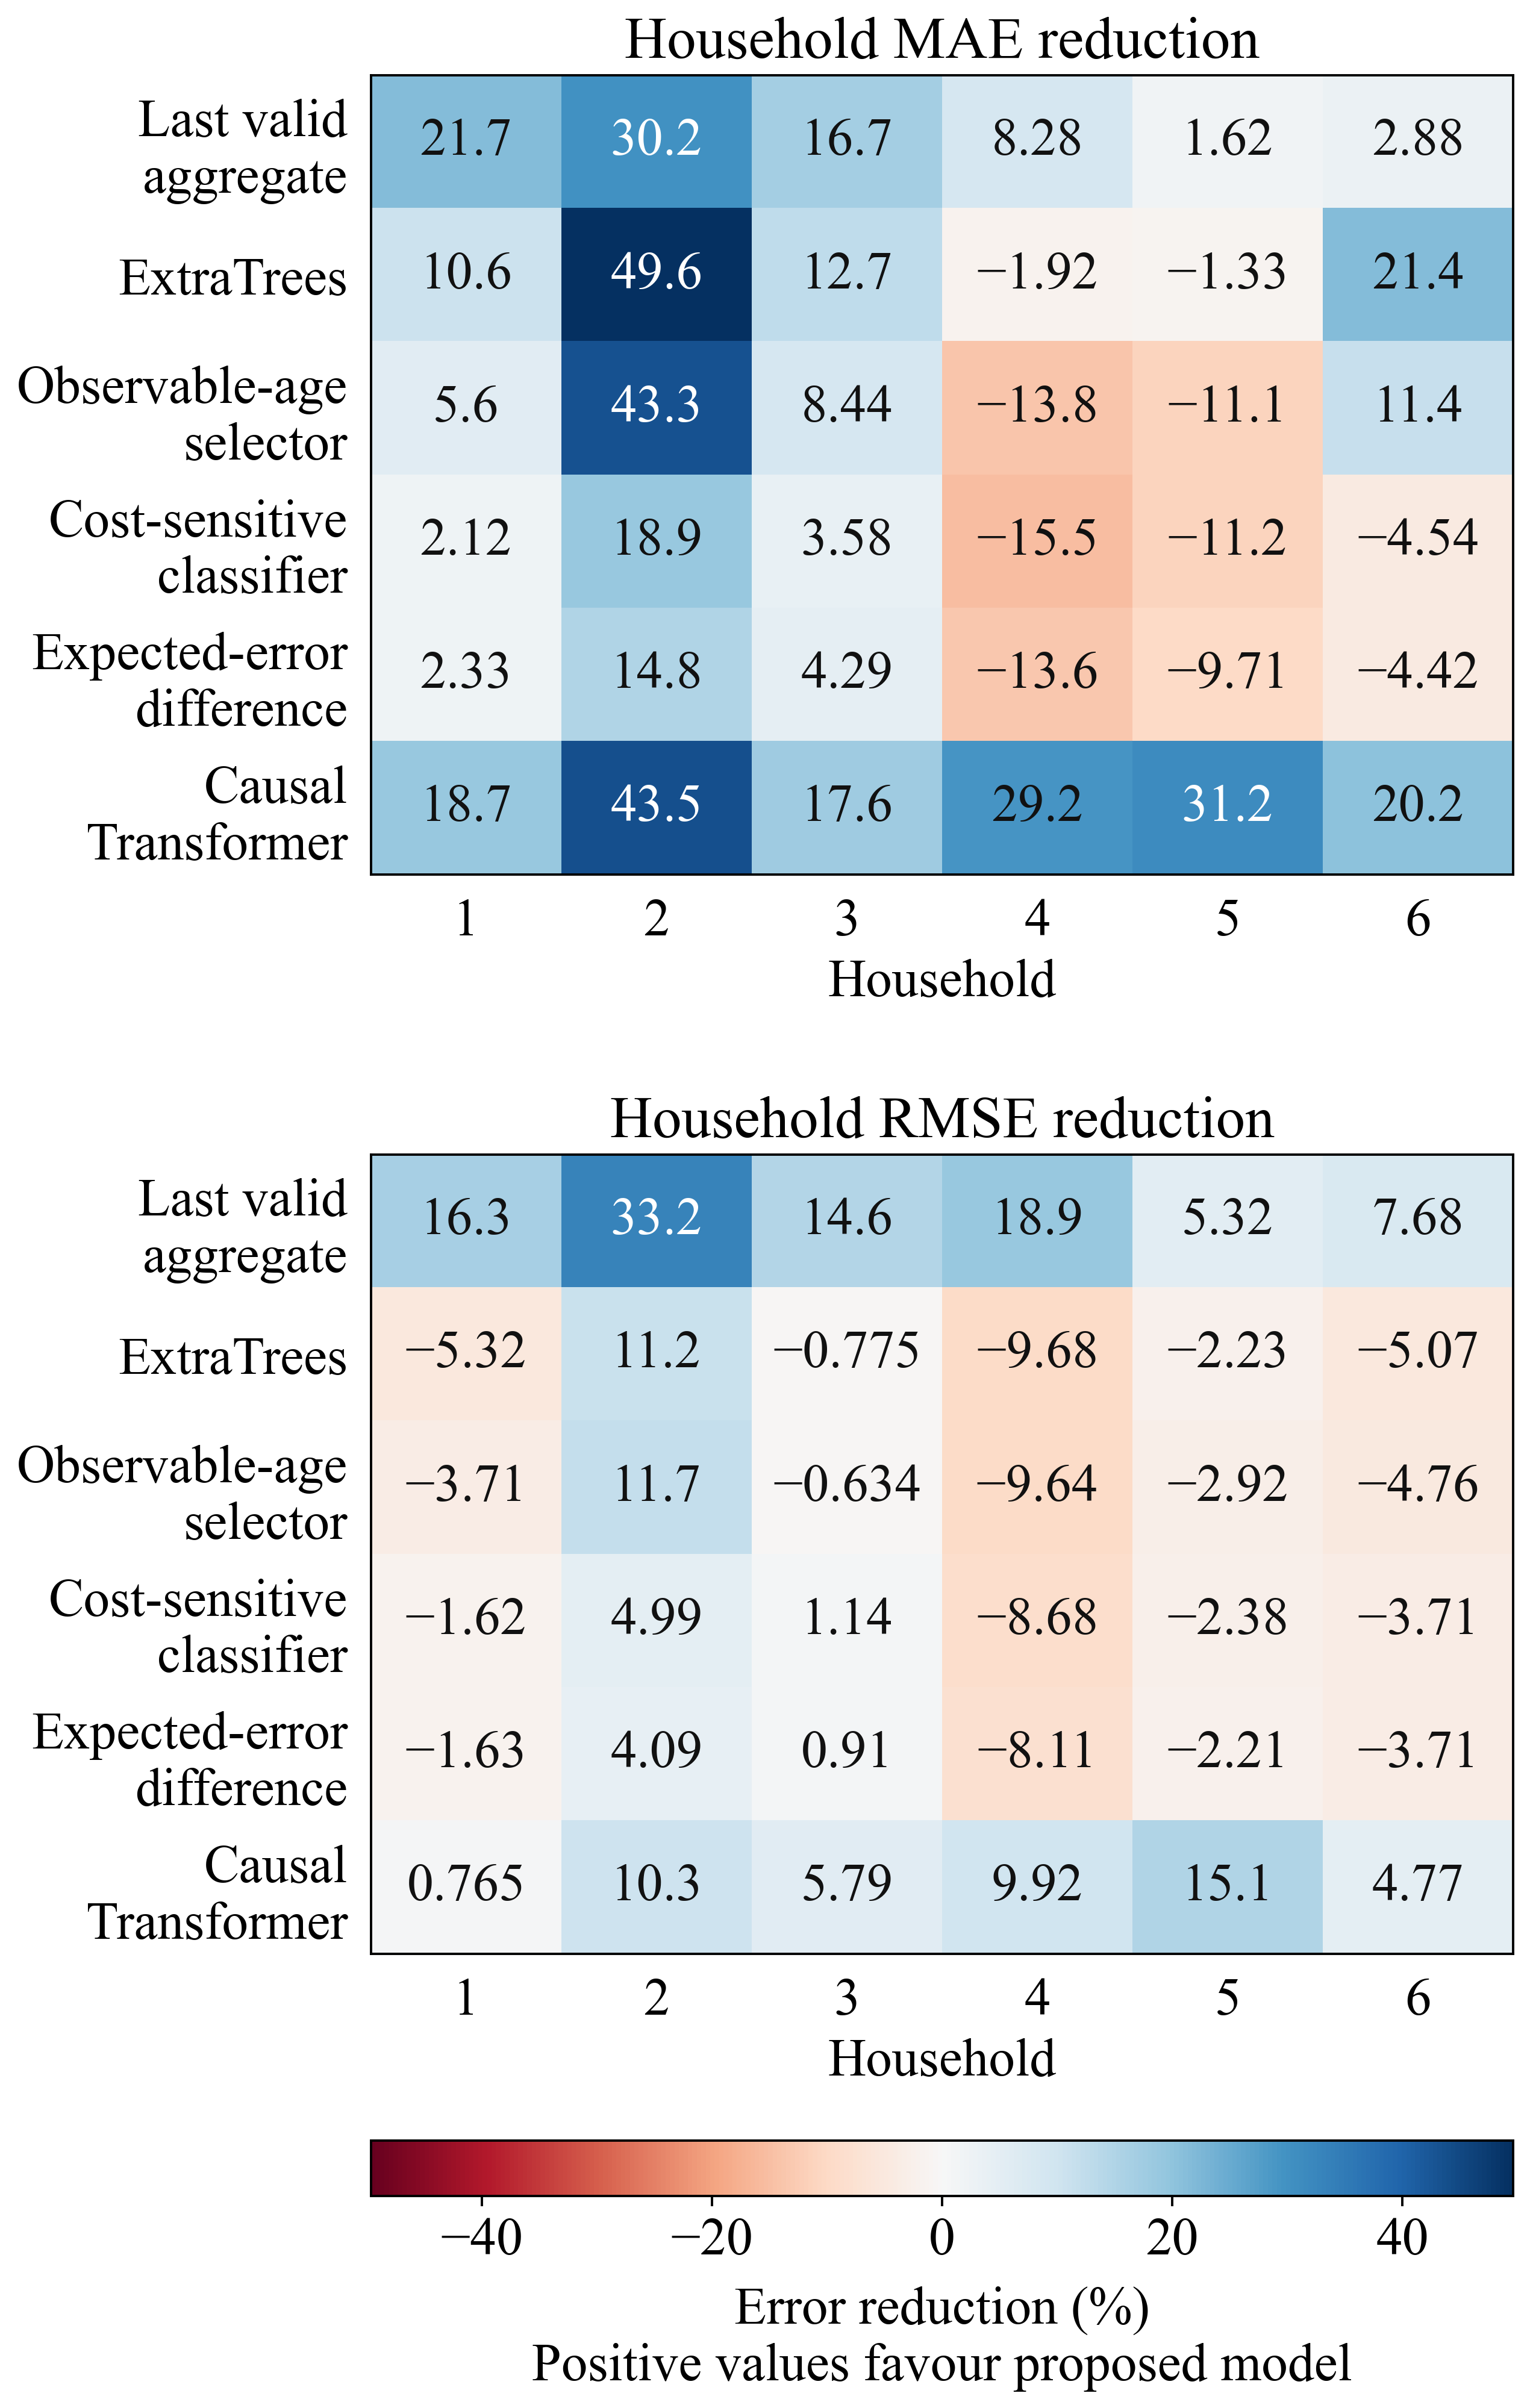

**Household heterogeneity.** Values are reductions relative to each frozen control after averaging seeds within each house. Both panels share one symmetric colour scale; every house/control pair is shown. NA means a zero control error. These descriptive percentages do not change the prespecified kW-scale IUT.

In [79]:
ECO_PUBLICATION_REPORT=eco_publication_report()
